# 06. 분석계획 — 전체 11단계 중 6단계

## 지금 어디 — 며칠 만에 여실 때 여기부터 읽습니다 (10-05)

**데이터가 넘어온 길**

1. 2·3단계 — 시간마다 LNG·기온·햇빛 같은 값을 받아서, 빈 곳을 고친 표를 만들었습니다.
2. 4단계 — 무엇이 LNG를 움직이는지 봤습니다. 몇 시인가 · 무슨 날인가 · 기온 · 햇빛이 컸습니다.
3. 5단계 — 그것들을 모델이 쓸 수 있는 열로 바꿔서 파일 하나(`data/hot/features_2023_2024_2025.csv`)로 저장했습니다.
4. 6단계(이 노트북) — 준비 ②가 그 파일을 읽습니다. 「2023년으로 배워서 2024년을 맞혀 보기」로, 이 계획대로 7단계로 가도 탈이 없는지 확인합니다.

**지금 모델에 들어가는 것** (5단계에서 정한 그대로)

- 몇 시인가 · 몇 월인가
- 무슨 날인가 — 월요일 · 화~금 · 토 · 일 · 공휴일 · 명절
- 기온 — 16도보다 추운 만큼, 24도보다 더운 만큼
- 3시간 동안 기온이 바뀐 만큼 — 추운 쪽과 더운 쪽 (선형회귀에만. 물음 4에서 3시간 전 기온을 이렇게 바꿔 적기로 했다 — 맞히는 값은 같고 겹침이 풀린다)
- 햇빛 세기(일사)
- 쉬는 날이면서 몇 시인가 (선형회귀에만)
- 트리 계열(랜덤포레스트·그래디언트 부스팅)은 시각·월·기온 같은 숫자를 그대로 받고, 선형회귀는 몇 시·몇 월·무슨 날을 0/1 열로 하나하나 나눠서 받습니다. 원전은 물음 1에서, 습도는 물음 4에서 넣지 않기로 했습니다.

**물음마다 정한 것**

- 물음 1 — 원전도 넣을까 → 뺐다. 넣으니 모델이 「원전이 줄면 LNG도 준다」로 거꾸로 배웠고, 2024년을 맞히는 것도 나빠졌다.
- 물음 2 — 무엇과 비교하고 어떤 숫자로 볼지 정하고(R²), 이 모델이 단순한 방법(2023년 같은 달·같은 시각·같은 날 종류의 평균)보다 잘 맞히는지 확인했다 → 세 모델 다 더 잘 맞혔다. 이 방향으로 간다.
- 물음 3(점검) — 이 모델을 2025·2026년에 써도 탈이 없나 → 날씨는 배운 범위 안이었고, 햇빛 한 열로 늘어난 태양광 패널을 못 따라간다는 흔적도 없었다. 바꿀 것이 없어 10-04에 닫았다(물음 3 결론 칸). 7단계에서 2025년에 같은 점검을 한 번 더 한다.
- 물음 4 — 7단계에 넘길 열을 한 표로 확정했다 → 습도는 넣지 않는다(습하면 1·불쾌지수로 넣어 봐도 기준만큼 오르지 않았다). 3시간 전 기온은 「3시간 동안 바뀐 만큼」으로 바꿔 적는다. 트리 계열은 일곱 열 그대로다. 10-04에 닫았다(물음 4 결론 칸).
- 물음 5 — 무엇을 맞히고, 기간을 어떻게 나누고, 시험을 어떻게 할까 → 시간별 LNG 발전량을 맞히고, 2023·2024년으로 배워 2025년에 한 번 채점하고 2026년 1~6월과 비교한다. 2026년은 7단계 채점 뒤 2023~2025년으로 다시 배운 모델로 맞힌다. 6단계의 시험은 지금까지처럼 「2023년으로 배워 2024년 맞히기」 한 번으로 하고, 0.002도 그대로 둔다(불쾌지수와 트리 계열의 3시간 전 기온은 넣지 않는다). 10-04에 닫았다(물음 5 결론 칸).
- 물음 6 — 세 모델 말고 7단계에서 같이 비교할 모델이 더 있나 → 기온 × 시간대 선형회귀를 더해 모델 넷(선형회귀 · 기온 × 시간대 선형회귀 · 랜덤포레스트 · 그래디언트 부스팅)과 기준선을 7단계에서 비교한다. 트리 계열의 설정은 2023년으로 배워 2024년을 맞힌 결정계수로 골라, 랜덤포레스트만 바꾸고 그래디언트 부스팅은 그대로 둔다. 10-04에 닫았다(물음 6 결론 칸). 10-05에 6-아(6-바에서 고른 값보다 더 크거나 작은 값도 시험해 보기)를 더해 다시 열었고, 0.002를 넘은 것이 없어 설정은 그대로다.
- 물음 7 — 시스템 다이내믹스 인과지도: 무엇이 LNG를 움직이고, 모델은 그 가운데 무엇을 보나 → 09-13에 창주 님이 이 프로젝트에도 시스템 다이내믹스 관점을 써 보고 싶다고 하셔서 정해 둔 일이고, 10-05에 물음으로 열었다. 셀마다 아래 칸에 적는 지금까지 방식 그대로다(7-가 넣는 것과 본보기 · 7-나 변수와 화살표 근거). 혼자 그리기가 어려워서, 창주 님 제안대로 클로드가 묻고 창주 님이 답하신 대로 그렸다(7-나 문답 기록). 모델은 LNG를 바로 움직이는 여섯(전력 수요 · 태양광 · 원전 · 석탄 · LNG 가격 · 풍력·바이오매스·연료전지)을 하나도 보지 않고 날씨·시간·달·날 종류만 본다(물음 7 결론 칸). 그림에는 균형 고리 둘(B1 가격 고리 · B2 석탄 고리)이 있다.
- 지금 — 10-05에 6단계를 닫았다. 고친 그림을 캡처하고 7-다·7-라를 다시 돌려 확인했다. 단계를 닫으며 개념 일곱(기준선 · 데이터 누수 · 시간 순서 검증 · 신뢰구간 · 수정 결정계수 · 하이퍼파라미터와 그리드 서치 · 균형 고리와 강화 고리)을 칸을 안 보고 말로 설명하셨고, 맨 아래 개념 표에 그 말과 고침을 적었다. 창주 님 칸의 자판 오타도 고쳤다(뜻은 그대로). 다음은 7단계(모델 넷을 2023·2024년으로 배워 2025년으로 채점하고, 기준선보다 나은지와 어디서 틀리는지 보는 단계)이고, 넘길 것은 맨 아래 닫는 칸 ②·③에 있다.

---

**어디서 나온 노트북인가.** 5단계(있는 열로 새 열을 만드는 단계)를 닫으면서 6단계에서 정할 것을 닫는 칸 ③에 모아 두었고, 4단계를 닫을 때 넘긴 것도 있습니다. 그것을 아래 물음 여섯으로 나눴고, 10-05에 인과지도를 물음 7로 더했습니다. 한 물음을 마친 뒤에 다음 물음의 셀을 넣고, 자세한 설명은 그 물음을 열 때 그 물음 칸에 적습니다.

**이 단계가 하는 일.** 무엇을 맞히고, 어떻게 나누고, 무엇으로 잘했다 할지 정합니다. 7단계(모델을 만들고 기준선과 비교하는 단계)의 코드는 여기서 정한 것을 그대로 씁니다. 5단계에서 정한 열은 준비 ②에 그대로 들어 있고 다시 묻지 않습니다. 선형회귀용 기온 방식은 16·24도와, 그것을 시간대마다 나눈 방식 둘만 7단계에 올립니다(5단계 기준으로 클로드가 거름, 닫는 칸 ① 첫 줄).

**물음 일곱**

- ① **원전을 입력에 넣을까** — 2023년만 또는 2024년만 배우면 「원전이 늘면 LNG가 준다」로 배우는데, 두 해를 같이 배우면 반대로 배우는 문제입니다(클로드 제안). 결론 문장이 원전에 기대고 있어서 먼저 봅니다. → 10-03에 원전을 입력에서 빼기로 했습니다(물음 1 결론 칸).
- ② **무엇과 비교하고 무엇으로 채점할까** — 기준선(모델 없이 하는 가장 단순한 예측), 지표, 무엇이 나오면 잘된 것으로 볼지를 결과를 보기 전에 정합니다. 달마다·시간대마다 오차를 나눠 보는 셀도 만듭니다. 9단계에서 「2026년의 차이가 평소에 틀리는 정도보다 큰가」를 말하려면 이것이 필요합니다. 2026년 차이를 2025년 채점 오차와 나란히 놓고 말한다는 것은 09-30에 정리했습니다. → 10-03에 닫았습니다 — 모델 셋이 가장 나은 기준선보다 낫다(물음 2 결론 칸).
- ③ **2025·2026년 값이 2023·2024년에 본 범위 안에 있나** — 모델은 배운 적 없는 값에서 약하고, 트리 계열은 범위 밖 값이 와도 범위 끝에서 냈던 값을 그대로 냅니다. 기온·일사마다 범위 밖인 시각을 셉니다(원전은 물음 1에서 뺐습니다). 태양광 설비가 늘어도 일사 한 열로 버티는지는 2024년 안에서 먼저 봅니다. 2025년 낮에도 맞는지는 7단계에서 보되, 무엇이 나오면 바꿀지는 여기서 미리 적습니다. → 10-04에 닫았습니다 — 점검이었고 바꿀 것 없음(물음 3 결론 칸).
- ④ **입력 목록을 한 표로 정한다** — 지금 기온과 3시간 전 기온이 겹치는 문제(VIF 35~44), 트리 계열에 3시간 전 기온을 넣을지, 습도를 넣을지, 쉬는 날 × 시간대 열의 겹침, 석탄·총 거래량·가격을 빼는 이유. 겹침과 트리 쪽은 5단계 기준으로 클로드가 정하고, 습도는 여쭙습니다. → 10-04에 닫았습니다 — 습도는 넣지 않고, 선형회귀의 3시간 전 기온은 「3시간 동안 바뀐 만큼」으로 바꿔 넣고, 트리 계열은 일곱 열 그대로입니다(물음 4 결론 칸).
- ⑤ **맞힐 값과 기간** — 시간별 LNG 발전량(MWh)과 「2023·2024년 배움 · 2025년 채점 · 2026년 1~6월 적용」을 확인합니다. 2025년까지 넣어 다시 배울지와, 시간 순서대로 여러 번 나눠 보는 검증 방법(2024년을 한 달씩 옮겨 가며 그 달 전까지로 배우고 그 달을 맞히는 식)을 정합니다. 정한 검증 방법은 물음 6부터 씁니다. 기준 1의 문턱 0.002가 맞는 크기인지도 이 검증으로 확인합니다 — 불쾌지수와 트리 계열의 3시간 전 기온을 넣은 것과 안 넣은 것을 달마다 나란히 놓고, 오른 양이 달마다 꾸준하면 다시 넣는 것을 봅니다(10-04, 클로드 제안 — 0.002는 5단계 1-마에서 클로드가 표를 보고 정한 숫자라서). 창주 님: 「값이나 방식이 적합했는지 검토후에 나아가자」 — 7단계로 넘어가기 전에 봅니다. → 10-04에 닫았습니다 — 맞힐 값과 기간은 그대로, 시험은 지금까지처럼 한 번, 0.002도 그대로입니다(물음 5 결론 칸).
- ⑥ **7단계에서 비교할 모델** — 선형회귀·랜덤포레스트·그래디언트 부스팅에 더해 후보 넷(릿지·라쏘 — 기울기에 벌점을 주는 선형회귀 / 그래디언트 부스팅에 시간대별 기온 열 / 달마다 따로 배우는 모델 / GAM — 효과를 굽은 선으로 배우는 모델)을 여기서 비교하고, 기준을 넘는 것만 올립니다. 랜덤포레스트가 선형회귀보다 잘 맞히던 차이가 쉬는 날 × 시간대를 넣은 뒤 얼마나 남는지도 같이 봅니다. 트리 계열의 하이퍼파라미터(잎 하나의 최소 시각 수 · 깊이 · 나무 수 · 배우는 속도)를 그리드 서치로 고를지도 여기서 봅니다 — 고를 때는 2025년이 아니라 물음 5에서 정한 시험(2023년으로 배워 2024년 맞히기)을 씁니다(10-04, 물음 4의 4-가 「읽고 나서」에서 물으심). 첫 셀로 그래디언트 부스팅이 기온 그대로를 받아 스스로 찾은 꺾임이 5단계의 16·24도 근처인지 그립니다(10-04, 창주 님 「gb가 가장 높으면 도대체 기온이나 그런거 분류가 무의미하다는 의미인가...??」에서 — 클로드 제안). → 10-04에 닫았습니다 — 기온 × 시간대 선형회귀를 더하고, 랜덤포레스트 설정만 바꿉니다(물음 6 결론 칸).
- ⑦ **시스템 다이내믹스 인과지도** — 09-13에 창주 님이 이 프로젝트에도 시스템 다이내믹스 관점을 써 보고 싶다고 하셔서 정해 둔 일입니다. 물음 1~6에서 정한 입력을 「무엇이 무엇을 움직이나」로 한 장에 모읍니다. 처음에는 닫는 칸에서 그리려 했는데, 10-05에 「인과지도는 물음으로 할 수 없는건가??」라고 하셔서 물음으로 열었습니다.

**번호를 바꿨습니다(10-03).** 처음 계획에서 ⑤였던 「모델이 단순한 방법(기준선)보다 나은가」를 물음 2로 앞당기고, 처음의 ②·③·④를 ③·④·⑤로 한 칸씩 미뤘습니다. 물음 1을 하다가 「앞으로 해야할 행위들이 무용하진 않은지」를 물으셨고, 이 방향이 쓸모 있는지에 가장 빨리 숫자로 답하는 물음이 이것이라 순서를 앞당겼습니다(클로드 제안). 처음에는 번호를 5로 두었다가, 창주 님이 「5번이 2번 되면 되는거 아니야??」라고 하셔서 읽는 순서와 번호를 맞췄습니다. 물음 2에서 기준선·지표·무엇이 나오면 잘된 것으로 볼지를 먼저 정하고, 2023년으로 배워 2024년을 맞혀 봅니다.

마지막에 인과지도를 그립니다. 변수와 화살표만 쓰고 방정식은 넣지 않으며, 화살표마다 + 또는 −와 근거(확인함 / 일부러 뺌 / 못 봄)를 적습니다. 클로드가 변수 목록과 화살표에 붙일 실측 숫자를 준비합니다. → 10-05에 물음 7로 열었습니다.

**창주 님이 정하시는 것** — 원전을 넣을지(물음 1 — 10-03에 빼기로 정함) · 무엇과 비교하고 어떤 숫자로 볼지(물음 2 — 10-03에 정함) · 습도를 넣을지(물음 4) · 무엇을 맞히고, 학습·채점 기간을 어떻게 나누고, 어떻게 검증할지(물음 5) · 인과지도. 물음 3은 점검이라 정할 것이 없었습니다(10-04). 물음 6(7단계에서 비교할 모델)은 열 때 무엇을 넘으면 7단계에 올릴지부터 여쭙습니다. 그 밖의 세부 — 예를 들어 지금 기온과 3시간 전 기온이 겹치는 것을 어떻게 둘지 — 는 5단계에서 세우신 기준(2023년으로 배워 2024년을 맞힌 R²가 0.002 넘게 오르고, 두 해를 배운 R²가 오른 만큼이 그대로 이어지는가)으로 클로드가 정하고 「(클로드 판단)」으로 한 줄씩 남깁니다. 거부하실 수 있습니다. *(10-04에 고침 — 앞에는 「새로 판단하실 것은 셋(원전 · 기준선과 지표 · 인과지도)」이라고 적혀 있어서, 지침에서 창주 님이 정하신다고 한 습도(어떤 입력을 넣을지)와 물음 5(무엇을 맞힐지, 학습·채점을 어떻게 자를지)가 빠져 있었습니다.)* 지금 자료로 볼 수 있는 것은 여기서 보고, 7단계 뒤로는 2025년 LNG나 2026년 비교가 있어야만 알 수 있는 것만 넘깁니다(10-02).

**2025·2026년의 LNG는 여기서 꺼내지 않습니다.** 2025년 LNG는 7단계 마지막 채점에 한 번, 2026년 LNG는 9단계 비교에만 씁니다. 여기서는 2023년으로 배워 2024년을 맞힌 결과로 고릅니다. 준비 ②는 2025년 LNG를 읽자마자 비웁니다. 물음 3에서 2025·2026년의 기온·일사 값은 보지만, 맞힐 값이 아니라 입력이라 채점에 영향을 주지 않습니다. 이미 본 2025·2026년 LNG 숫자는 README 한계에 적어 두었습니다(지침 v52).

**먼저 준비 ①과 준비 ②를 돌립니다.**

| 단계 | 이름 |
|---|---|
| 1 | 과제 정의 |
| 2 | 데이터 수집과 구성 보기 |
| 3 | 정제 |
| 4 | 탐색적 분석 |
| 5 | 변환·파생변수 |
| 6 | 분석계획 ◀ 이 노트북 |
| 7 | 모델링과 검정 |
| 8 | 모델 확정과 핵심인자 |
| 9 | 이 과제만의 물음 — 2026년은 평소와 얼마나 달랐나 |
| 10 | 그 답을 숫자로 내기 |
| 11 | 결론 |

진행 기록(지금 어디)은 리포의 `README.md`가 원본입니다. 단계마다 무엇을 하고 내가 무엇을 정하는지는 옵시디언 볼트 「빅데이터 분석의 순서」에 있습니다.

### 말 뜻 — 표를 읽을 때 쓰는 말 (10-28에 통일함)

| 말 | 뜻 |
|---|---|
| 실제 | 그해(주로 2026년)에 실제로 발전한 양 · 실제 값입니다. 전력거래소 자료 그대로입니다 |
| 모델 예측 | 2023 ~ 2025년을 배운 모델이 그때의 날씨 · 시각 · 날 종류를 보고 예측한 양입니다. 9단계까지는 「평소라면」이라고 불렀습니다 |
| 실제 − 모델 예측 | 발전량 표의 숫자입니다. + 면 실제가 모델 예측보다 많았다, − 면 적었다는 뜻입니다 |
| 평소 해 | 2023 · 2024 · 2025년입니다. 「평소」는 이 세 해만 가리킵니다 |
| 평소 범위 | 평소 해에 모델 예측이 한 달 평균으로 가장 크게 틀린 크기(±2,177 MWh)입니다. 모델이 예측해 본 2024 · 2025년으로 냈습니다. 2026년의 차이가 이 안이면 「달랐다고 말할 근거가 없다」로 읽습니다 |
| 세 해 평균 | 2023 ~ 2025년 같은 달 값의 평균입니다. 모델 없이 계산한 것으로, 10단계 가격 표(2-가 · 2-라)에서만 씁니다 |

앞 단계 글에서 발전량을 두고 쓴 「평소보다 많았다 · 적었다」는 「모델 예측보다 많았다 · 적었다」로 읽습니다.


In [374]:
# 6단계 분석계획 · 준비 ①
import os                                      # 폴더와 파일 경로를 다루는 기본 모듈
import numpy as np                             # 숫자 계산
import pandas as pd                            # 표(데이터프레임)를 다루는 라이브러리
import matplotlib.pyplot as plt                # 그림을 그리는 라이브러리
from IPython.display import display            # 표를 글자가 아니라 격자로 그린다
from sklearn.linear_model import LinearRegression                                   # 5단계와 같은 선형회귀
from sklearn.ensemble import RandomForestRegressor, HistGradientBoostingRegressor   # 5단계 4-마와 같은 트리 계열 두 가지
plt.rcParams["font.family"] = "AppleGothic"    # 맥에서 그림 속 한글이 깨지지 않게
plt.rcParams["axes.unicode_minus"] = False     # 그림의 마이너스 부호가 깨지지 않게
pd.set_option("display.max_columns", 50)       # 열이 많아도 생략하지 않고 다 보이게

ROOT = os.getcwd()                             # 지금 폴더(보통 notebooks/)에서 시작해서
while not os.path.isdir(os.path.join(ROOT, "data")) and ROOT != os.path.dirname(ROOT):
    ROOT = os.path.dirname(ROOT)               # data 폴더가 보일 때까지 위로 = 프로젝트 루트
HOT = os.path.join(ROOT, "data", "hot")        # 5단계가 만들어 둔 파일이 있는 폴더
RAW = os.path.join(ROOT, "data", "raw")        # 원자료 폴더 — 1-나에서 EPSIS 월별 표를 읽는다

print("프로젝트 루트:", ROOT)                    # 경로가 맞는지만 확인한다

프로젝트 루트: /Users/kimchangju/vs코드 /개인 프로젝트/lng-project


In [375]:
# 6단계 분석계획 · 준비 ②
tbl = pd.read_csv(os.path.join(HOT, "features_2023_2024_2025.csv"), encoding="utf-8-sig")  # 5단계 「저장」 셀이 만든 표
tbl["ts"] = pd.to_datetime(tbl["ts"])            # 글자로 저장된 시각을 다시 시각 자료형으로
tbl = tbl.set_index("ts").sort_index()           # 시각을 줄 이름으로 두고 시간 순서대로 놓는다
tbl.loc[tbl["year"] == 2025, "lng_mwh"] = np.nan   # 누수를 막는다 — 2025년 LNG는 7단계 마지막 채점에만 쓰므로 읽자마자 비운다(지침 v52)

학습 = tbl[tbl["year"].isin([2023, 2024])].dropna(subset=["3시간 전 기온"])   # 판단에 쓰는 두 해 — 3시간 전 기온이 빈 9시각은 뺀다
y = 학습["lng_mwh"]                               # 맞힐 값 — 그 시각의 LNG 발전량(MWh)
배움 = 학습["year"] == 2023                        # 배우는 해 — 2023년
맞힘 = 학습["year"] == 2024                        # 맞혀 보는 해 — 배우지 않은 2024년
                                                  # 2025년은 7단계 마지막 채점에만 쓴다. 이 노트북에서는 꺼내지 않는다

def 선형열(d):                                     # 선형회귀에 넣는 열 — 5단계에서 넘긴 16·24도 방식, 67열
    시각열 = pd.get_dummies(d["hour24"].astype(str), prefix="시", drop_first=True).astype(float)  # 1~23시 0/1 열 — 0시가 기준
    월열 = pd.get_dummies(d["month"].astype(str), prefix="월", drop_first=True).astype(float)     # 2~12월 0/1 열 — 1월이 기준
    날열 = pd.get_dummies(d["날 종류"], prefix="날").astype(float).drop(columns="날_월")           # 화~금·토·일·공휴일·명절 — 월요일이 기준
    쉬는날 = d["날 종류"].isin(["토", "일", "공휴일", "명절"]).astype(float)                        # 쉬는 날이면 1
    쉬는날시간대 = (시각열 - 1 / 24).mul(쉬는날, axis=0)                                           # 5단계 물음 7 — 시간대 열의 평균(1/24)을 빼고 쉬는 날과 곱한다
    쉬는날시간대.columns = [f"쉬는 날×{c[2:]}시" for c in 시각열.columns]                           # 열 이름 — 「쉬는 날×9시」
    기상 = d[["16도보다 추운 만큼", "24도보다 더운 만큼",                                           # 5단계 물음 1 — 16·24도
              "3시간 전 16도보다 추운 만큼", "3시간 전 24도보다 더운 만큼",                           # 5단계 물음 2 — 3시간 전 기온
              "icsr"]].rename(columns={"icsr": "일사"})                                          # 5단계 물음 3 — 일사 한 열
    return pd.concat([시각열, 월열, 날열, 기상, 쉬는날시간대], axis=1)

def 트리열(d):                                     # 트리 계열에 넣는 열 — 숫자 그대로 7열(5단계 물음 1·3·5)
    return d[["hour24", "month", "icsr", "ta", "dow", "is_holiday", "명절"]]

X선형 = 선형열(학습)                               # 두 해 모든 시각의 선형회귀 열
X트리 = 트리열(학습)                               # 두 해 모든 시각의 트리 계열 열

print(f"표 모양: {len(tbl):,}행 · {tbl.shape[1] + 1}열 / 판단에 쓰는 두 해 {len(학습):,}시각")
print(f"선형회귀 열 {X선형.shape[1]}개 · 트리 계열 열 {X트리.shape[1]}개 · 빈 칸 {int(X선형.isna().sum().sum() + X트리.isna().sum().sum())}개")
쓰는곳 = {2023: "배우는 해", 2024: "맞혀 보는 해", 2025: "7단계 마지막 채점 — LNG는 여기서 꺼내지 않는다"}
display(pd.DataFrame({"시각 수": tbl.groupby("year").size(),
                      "이 노트북에서": pd.Series(쓰는곳)}).rename_axis("해"))

표 모양: 25,536행 · 25열 / 판단에 쓰는 두 해 16,767시각
선형회귀 열 67개 · 트리 계열 열 7개 · 빈 칸 0개


,시각 수,이 노트북에서
해,,
2023,8760,배우는 해
2024,8016,맞혀 보는 해
2025,8760,7단계 마지막 채점 — LNG는 여기서 꺼내지 않는다


# 물음 1 — 원전을 입력에 넣을까, 넣는다면 어떻게 넣을까

**적을 곳 넷입니다 — 「1-가」·「1-나」·「1-다」·「1-라」 아래에 있는 「✍️ 내 답변」 칸입니다.** 정할 것은 1-라 칸 아래에서, 바로 아래 「결정까지의 순서」를 따라 번호 붙은 질문으로 한 번 묻습니다(10-03에 1-다 아래 ①에서 옮겼습니다). 셀마다 왜 생겼는지는 아래 🗂️ 칸에 있습니다.

**결정까지의 순서(10-03).** 원전을 넣을지는 아래 다섯을 차례로 따져서 정합니다. 앞에서 적은 답이 다음 물음으로 이어집니다. 결정에는 이 노트북 셀에 있는 숫자만 씁니다 — 클로드가 셀 밖에서 본 숫자는 1-라로 옮겼습니다.

| 순서 | 묻는 것 | 어디서 보나 |
|---|---|---|
| 1 | 원전을 넣으려면 무엇이 맞아야 하나 | 기준 1 — 2023년으로 배워 2024년을 맞힌 R²가 0.002 넘게 오르나(5단계 물음 1·4에서 세운 기준). 기준 2 — 원전이 줄면 LNG가 는다고 배우나(클로드가 셀 밖에서 방향 문제를 본 뒤에 꺼냈고, 10-02에 창주 님이 정함) |
| 2 | 원전은 그 기준을 넘었나 | 기준 2는 1-가 [표 1], 기준 1은 1-다 [표 1] |
| 3 | 왜 그렇게 나왔나 — 두 해 자료로 원전의 효과만 따로 구할 수 있나 | 1-나(두 해 사이에 연료마다 얼마나 달라졌나) · 1-라(한 해 안에서 달마다 원전과 LNG, 원전 열 때문에 2024년 예측이 바뀐 양) |
| 4 | 다른 방법으로 풀 수 있나 — 「2024년이면 1」 열 · 석탄을 넣기 · 배우는 해를 늘리기 | 1-가 [표 1] 마지막 줄 · 아래 「무엇을 정하는가」 · 지침 「■ 몸통」 · handoff §0 |
| 5 | 그래서 넣나 빼나, 빼면 원전 자료는 어디에 쓰나 | 1-라 아래 ⑤ |

**어디서 나온 물음인가.** 클로드가 꺼낸 물음입니다(클로드 제안). 09-30에 5단계를 닫기 전, 창주 님이 채팅에서 「이정도로 넘기면 적합할까? 놓치거나 뭐 더 추가하거나 혹시 빼먹거나 한건 없을까??」라고 물으셨습니다. 클로드가 그 답을 찾으려고 셀 밖에서, 5단계에서 넘기는 선형회귀에 5단계에서 안 본 열을 하나씩 더해 봤습니다. 거기서 둘이 나왔습니다. 하나는 쉬는 날 × 시간대이고, 5단계 물음 7이 됐습니다. 다른 하나가 이 물음입니다.

원전 발전량 한 열을 더해 보니, 원전 1 MWh당 LNG가 2023년만 배우면 −0.294, 2024년만 배우면 −0.144로 「원전이 늘면 LNG가 준다」였습니다. 그런데 두 해를 같이 배우면 +0.204로 방향이 반대가 됐습니다. 원전을 넣을지는 5단계(있는 열로 새 열을 만드는 단계)에서 정할 것이 아니어서, 5단계 닫는 칸 ① 표의 「물음 7 — 쉬는 날 × 시간대」 셋째 줄과 ③의 「원전을 넣은 선형회귀를 셀로 봅니다」로 시작하는 줄에 적어 두었습니다. ③ 줄 끝에는 「6단계를 열 때 이 셀을 먼저 만듭니다. 트리 계열에서도 같은 일이 있는지 같이 봅니다」라고 적었습니다. 그때는 쉬는 날 × 시간대를 넣기 전 모델이었고, 아래 셀들은 넣은 뒤 모델(준비 ②의 67열)로 다시 봅니다.

원전 발전량을 입력에 넣는 것 자체는 09-12에 클로드가 고른 입력 후보 여덟 가운데 하나입니다(1단계 물음 2에 적혀 있습니다).

**왜 먼저 보나.** 이 프로젝트의 결론 문장은 「원전이 줄어든 것까지 감안했는데도 LNG가 예상과 얼마나 달랐나」입니다(지침 「■ 몸통」). 2026년 1~6월 원전은 2025년 같은 기간보다 16,098 GWh(−17.1%) 적었습니다. 모델이 「원전이 줄면 LNG가 는다」로 배웠으면 2026년 예측은 올라가고, 반대로 배웠으면 내려갑니다. 그래서 9단계(2026년 예측과 실제를 비교하는 단계)에서 차이가 어느 쪽으로 얼마나 나오는지가 이 결정에 달려 있습니다.

**무엇을 정하는가 — 원전을 넣는 방식 셋**

- **원전을 그대로 넣고 두 해를 같이 배운다** — 5단계까지의 기본값입니다. 두 해 사이에 달라진 것이 있으면 그것까지 원전의 효과로 섞여 들어갈 수 있습니다.
- **원전과 「2024년이면 1, 2023년이면 0」인 열을 같이 넣는다** — 두 해 사이에 전체적으로 달라진 만큼은 그 열의 기울기로 따로 계산되고, 원전의 기울기는 한 해 안에서 오르내린 것만으로 계산됩니다. 대신 2025·2026년을 예측할 때 그 열에 어떤 값을 줄지 따로 정해야 합니다. 또 2023년 한 해로 배워 2024년을 맞히는 검증에서는 이 열을 만들 수 없습니다(배우는 해에 2024년이 없어서입니다).
- **원전을 넣지 않는다** — 모델은 날씨·시간대·날 종류로 평소를 배웁니다. 2026년에 원전이 줄어든 것은 9·10단계에서 같은 달 석탄·원전 변화와 나란히 놓고 읽습니다. 그러면 결론 문장이 「원전이 줄어든 것까지 감안했는데도」에서 「날씨·시간·날이 같을 때 평소 두 해의 패턴과 비교해」로 바뀝니다.

**재료 넷**

- **1-가** — 원전만 1,000 MWh 줄이고 다른 열은 그대로 두었을 때 LNG 예측이 얼마나 바뀌는지 봅니다. 배우는 해(2023년만 · 2024년만 · 두 해 · 두 해 + 「2024년이면 1」 열)와 모델(선형회귀 · 랜덤포레스트 · 그래디언트 부스팅)마다 한 칸씩입니다.
- **1-나** — 2023년과 2024년 사이에 원전·석탄·LNG가 각각 얼마나 달라졌는지 EPSIS 월별 표로 봅니다. 석탄은 입력에 넣지 않는 열이라 이 셀에서만 봅니다.
- **1-다** — 2023년으로 배워 2024년을 맞힐 때 원전을 넣기 전과 넣은 뒤 R²와 오차가 어떻게 달라지는지 봅니다.
- **1-라** — (10-03) 클로드가 셀 밖에서 본 숫자 둘을 옮긴 셀입니다. 2023·2024년 달마다 원전과 LNG의 평균, 그리고 2023년으로 배운 원전 기울기 때문에 2024년 예측이 얼마나 바뀌었는지를 봅니다.

**여기서 정하지 않는 것.** 2026년 원전 값이 2023·2024년에 본 범위 밖인지는 물음 3에서 봅니다. 창주 님이 5단계 2-가 「✍️ 다시 읽고 나서」에 적으신 「원전은 그러면 해마다, 시간마다 바뀌는데 그건 어떻게 고려해야 하지??」가 이 이야기입니다. 원전을 넣지 않기로 하면 물음 3에서는 기온·일사만 봅니다.

<div style="border: 2px solid var(--vscode-focusBorder, #3794ff); border-left-width: 6px; border-radius: 8px; padding: 4px 18px 10px; background: var(--vscode-textBlockQuote-background, rgba(127, 127, 127, 0.1));">

## 📌 물음 1 결론

**왜 생긴 물음인가** — 09-30에 5단계를 닫기 전, 클로드가 셀 밖에서 원전 한 열을 더해 보니 두 해를 같이 배우면 「원전이 줄면 LNG도 준다」로 거꾸로 배웠습니다(클로드 제안). 그래서 원전을 입력에 넣을지, 넣는다면 어떻게 넣을지를 정하는 물음입니다.

### 결정 — 원전 발전량을 모델 입력에서 뺀다(2023~2026년 모두). 원전 자료는 버리지 않고 결과를 해석할 때 쓴다

**같이 정한 것**

1. 결론 문장이 「원전이 줄어든 것까지 감안했는데도」에서 「날씨·시간대·날 종류가 같을 때 평소 패턴과 비교해 2026년이 얼마나 달랐나」로 바뀐다.
2. 원전의 영향은 모델로 숫자를 내지 못한다. 7단계에서 원전이 적게 돈 시기의 오차를 보고, 9·10단계에서 같은 달 원전·석탄·LNG 변화를 차이 옆에 놓는다.
3. 이 결정은 방법이 틀려서가 아니라, 평소로 쓸 해가 둘뿐이고 그 사이에 석탄과 원전이 같이 바뀐 자료의 한계와, 석탄을 일부러 뺀 설계가 만나서 나온 것이다(1-다 「다시 읽고 나서 (2)」).

**결정 근거** — 물음 1 머리 칸 「결정까지의 순서」대로

- 기준 2를 못 넘었다 — 두 해를 같이 배운 세 모델이 모두 「원전이 줄면 LNG도 준다」로 배웠다(1-가 [표 1] 「두 해를 같이 배움」 −206·−156·−221).
- 기준 1을 못 넘었다 — 원전을 넣으면 2024년을 맞힌 R²가 세 모델 모두 내려갔다(1-다 [표 1] 「차이」 −0.0257·−0.0485·−0.0327). 기준 2는 클로드가 셀 밖에서 방향 문제를 본 뒤에 세운 기준이지만, 그 전부터 있던 기준 1만으로도 결론은 같다.
- 왜 — 2024년에 석탄이 한 시각 2,289 줄고 원전(+880)과 LNG(+924)가 같이 늘었다(1-나). 2023년 안에서는 원전과 LNG가 같이 낮은 달이 겹쳤다(1-라 [표 1], 달 평균 상관 +0.47). 2023년 기울기로는 2024년 LNG 예측이 279 내려가 평균 수준 오차가 296 커졌다(1-라 [표 2]). 석탄이 입력에 없어서, 두 해 자료로는 원전의 효과만 따로 구할 수 없다.
- 다른 방법 — 「2024년이면 1」 열은 검증할 수 없고 2025·2026년에 줄 값이 없다. 석탄을 넣으면 2026년에 보려던 차이가 모델 안으로 들어간다. 배우는 해는 늘릴 수 없다(2020~2022년은 평소가 아니고, 2025년은 채점용).
- 판단을 적으신 칸 — 1-라 「✍️ 내 답변」 ⑤ 「일단 빼는 방향이 맞아보이긴 해」 · 1-다 「✍️ 다시 읽고 나서」 「최적의 방향은 아마도 지금 보니까 원전을 빼는 방향인 것 같다」 · 1-라 「✍️ 읽고 나서」 「이전에 노력해서 정제했다고 해서, 모델링에 억지로 꾸겨넣는게 더 바보같은 짓이니까」.

**남은 것** — 물음 3(배운 범위 밖 시각 세기)는 기온·일사만 본다. 원전이 적게 돈 시기의 오차는 7단계에서, 원전·석탄 변화와의 비교는 9·10단계에서 본다. 자료가 더 쌓여 원전과 석탄이 따로 움직인 해가 학습에 들어오면 다시 본다.

</div>

<div style="border: 2px dashed var(--vscode-focusBorder, #3794ff); border-left: 6px solid var(--vscode-focusBorder, #3794ff); border-radius: 8px; padding: 4px 18px 10px;">

## 🗂️ 물음 1 셀 흐름 — 셀마다 어디서 나왔나

| 셀 | 어디서 나왔나 — 단계 · 물음 · 칸 | 거기에 적힌 생각이나 본 것 | 그래서 무엇이 정해지지 않았나 |
|---|---|---|---|
| 1-가 | 09-30 채팅 「이정도로 넘기면 적합할까? 놓치거나 뭐 더 추가하거나 혹시 빼먹거나 한건 없을까??」 → 클로드가 셀 밖에서 5단계에서 안 본 열을 하나씩 더해 봄(클로드 제안. 5단계 물음 7도 여기서 나왔다) → 5단계 닫는 칸 ① 「물음 7」 표 셋째 줄 · ③ 「원전을 넣은 선형회귀를 셀로 봅니다」 줄 → 6단계 물음 1 머리 칸 | 원전 1 MWh당 LNG가 2023년만 배우면 −0.294, 2024년만 −0.144, 두 해를 같이 배우면 +0.204였다. 그때는 선형회귀 하나로, 쉬는 날 × 시간대를 넣기 전 모델로 봤다 | 지금 넘기는 모델과 트리 계열에서도 방향이 바뀌는지 |
| 1-나 | 5단계 닫는 칸 ③ 「원전을 넣은 선형회귀를 셀로 봅니다」 줄 → 6단계 물음 1 머리 칸(물음을 열며 계획) | 8월과 2월 29일을 두 해에서 똑같이 빼면 2024년이 원전(19,536 → 20,484)도 LNG(17,367 → 18,288)도 많았다. 두 해 사이의 차이가 원전 기울기에 들어간 것으로 보인다고 적었다(판단) | 두 해 사이에 원전·LNG 말고 무엇이 달라졌는지 — 석탄은 그때 보지 않았다 |
| 1-다 | 5단계 닫는 칸 ③ 「원전을 넣은 선형회귀를 셀로 봅니다」 줄 → 6단계 물음 1 머리 칸(물음을 열며 계획) | 2023년으로 배워 2024년을 맞힌 R²가 원전을 더하면 0.6515 → 0.6282로 낮아졌다 | 낮아진 것이 두 해의 수준 차이 때문만인지, 트리 계열에서도 낮아지는지 |
| 1-라 | 10-03 채팅 — 클로드가 「원전은 기준을 못 넘었다」고 말한 뒤 | 「기준을 못 넘었다는게 너가 밖에서 돌린거지??」 — 왜 빼는지가 물음 순서대로 적혀야 학습이 된다는 말도 같이 하셨다 | 클로드가 「왜 그렇게 나왔나」를 설명하며 쓴 숫자 둘(2023·2024년 달마다 원전과 LNG, 2023년 원전 기울기로 계산한 2024년 예측 변화)이 셀에 없어서, 그 설명을 노트북에서 확인할 수 없었다 |

</div>

## 1-가

**어디서 나온 셀인가.** 09-30에 5단계를 닫기 전 「놓친 것 없나」를 물으셔서, 클로드가 셀 밖에서 원전 한 열을 더해 보다가 원전 기울기가 배우는 해에 따라 방향이 바뀌는 것을 봤습니다(클로드 제안). 그것을 셀로 다시 봅니다.

**무엇을 보는 셀인가.** 원전만 1,000 MWh 줄였을 때 LNG 예측이 평균 얼마나 바뀌는지를, 배우는 해 넷 × 모델 셋으로 봅니다. 양수면 「원전이 줄면 LNG가 는다」로 배운 것입니다(기준 2).

In [349]:
# 6단계 분석계획 · 1-가
원전 = 학습["nuke_mwh"].rename("원전")                                        # 그 시각의 원전 발전량(MWh)
해열 = (학습["year"] == 2024).astype(float).rename("2024년이면 1")            # 두 해 사이에 달라진 것을 따로 받는 열
모델들 = {"선형회귀": (lambda: LinearRegression(), X선형),                     # 모델 이름: (모델 만들기, 넣는 열)
          "랜덤포레스트": (lambda: RandomForestRegressor(n_estimators=300, min_samples_leaf=5,
                                                      n_jobs=-1, random_state=0), X트리),   # 5단계 4-마와 같은 설정
          "그래디언트 부스팅": (lambda: HistGradientBoostingRegressor(early_stopping=False,
                                                                   random_state=0), X트리)}
배우는방식 = {"2023년만 배움": (배움, False), "2024년만 배움": (맞힘, False),          # 줄 이름: (배우는 시각, 「2024년이면 1」 열을 넣나)
              "두 해를 같이 배움": (배움 | 맞힘, False),
              "두 해 + 「2024년이면 1」 열": (배움 | 맞힘, True)}

def 원전만줄이면(만들기, X, 고른시각):                                         # 원전만 1,000 MWh 줄였을 때 LNG 예측이 평균 몇 MWh 바뀌나
    모델 = 만들기().fit(X[고른시각], y[고른시각])                               # 고른 해로 배운다
    줄인X = X.copy()                                                         # 넣는 열을 그대로 복사해서
    줄인X["원전"] = 줄인X["원전"] - 1000                                      # 원전만 1,000 줄이고 다른 열은 그대로 둔다
    return (모델.predict(줄인X) - 모델.predict(X)).mean()                      # 두 해 모든 시각에서 예측이 바뀐 양의 평균

표 = pd.DataFrame(index=list(배우는방식), columns=list(모델들), dtype=object)  # 줄은 배우는 방식, 칸은 모델
for 모델이름, (만들기, X) in 모델들.items():
    for 줄이름, (고른시각, 해열넣음) in 배우는방식.items():
        넣는열 = [X, 원전] + ([해열] if 해열넣음 else [])                        # 원전 한 열을 더하고, 필요하면 「2024년이면 1」 열도
        바뀜 = 원전만줄이면(만들기, pd.concat(넣는열, axis=1), 고른시각)
        표.loc[줄이름, 모델이름] = f"{바뀜:+,.0f}"                              # 글자로 — 부호와 천 단위 쉼표

print("[표 1] 원전만 1,000 MWh 줄이고 다른 열은 그대로 두었을 때 LNG 예측이 바뀐 양 (MWh)")
print("두 해 모든 시각의 평균 · 양수면 원전이 줄 때 LNG 예측이 늘었다 · 선형회귀는 「원전 기울기 × −1,000」과 같다")
display(표)

[표 1] 원전만 1,000 MWh 줄이고 다른 열은 그대로 두었을 때 LNG 예측이 바뀐 양 (MWh)
두 해 모든 시각의 평균 · 양수면 원전이 줄 때 LNG 예측이 늘었다 · 선형회귀는 「원전 기울기 × −1,000」과 같다


,선형회귀,랜덤포레스트,그래디언트 부스팅
2023년만 배움,+315,-204,-268
2024년만 배움,+124,-6,+268
두 해를 같이 배움,-206,-156,-221
두 해 + 「2024년이면 1」 열,+97,-51,+10


### ✍️ 내 답변

이 셀에 무엇이 나와 있습니까? 무슨 뜻이라고 읽으셨습니까?

답: 무엇을 정확히 원해서 이렇게 셀을 구성한것인지, 원전 내용은 며칠 전에 하다가 이렇게 갑자기 구성되어 있으니까 감이 안 와. 몇 주에 걸쳐서 하다보니까 원전 데이터가 어떤 식으로 구성되었거나 내가 과거에 무엇을 결정했는지 기억도 잘 안나고..

- 일단 보면 우리가 다른 단계에서 정한 모델 방식에 따라, 원전 데이터를 어떤 방식으로 학습시키는게 가장 적절한지를 보는 것. 어 차이가 적은게 적합한 것인지. 뭐가 적합한 것인지 잘 모르겠다. 이전에 봤을 때 선형회귀와 트리 방식을 쓴다고 했는데 gb는 기억이 안나는데 그것도 쓰기로 했었나?? 너가 적은 것도 이해가 안가고 마지막 행에 적은 요약한 말도 무슨 말인지 잘 모르겠다.

### 클로드 답변

> **짧게**
> 1. 이 셀이 묻는 것은 하나입니다 — 같은 날, 같은 시각, 같은 날씨에 원전만 1,000 MWh 적게 돌았다면 모델은 LNG가 얼마나 더 돈다고 예측하나.
> 2. 「차이가 적은 게 적합한가」에는 정해진 답이 없습니다. 이 표에서 볼 것은 방향입니다. 채팅에서 같이 세운 기준 2 — 모델이 원전에서 배운 방향이 「원전이 줄면 LNG가 는다」와 같은가 — 로 읽는 표입니다. 아래 「✍️ 읽고 나서」에 이 기준으로 읽은 것을 적어 주세요.
> 3. 그래디언트 부스팅은 5단계 4-마에서 랜덤포레스트와 같이 본 트리 계열 모델입니다(아래 6번).

**1. 이 셀을 왜 만들었나 — 처음부터**

- 이 프로젝트는 2023·2024년으로 「평소라면 LNG가 얼마나 돌았을까」를 배우고, 2026년에 실제와 비교합니다.
- 2026년 1~6월에는 원전이 2025년보다 17% 적게 돌았습니다. 원전이 덜 돌면 그만큼을 다른 발전소가 채워야 하니, 평소라면 LNG가 더 돌았을 것입니다. 모델이 이것을 감안하게 하려고 원전을 입력에 넣으려 했습니다.
- 그런데 5단계를 닫을 무렵 제가 셀 밖에서 원전을 넣어 보니, 두 해를 같이 배운 선형회귀가 거꾸로 「원전이 줄면 LNG도 준다」로 배웠습니다. 이 셀은 배우는 해를 바꾸거나 트리 계열로 바꾸면 어떻게 되는지 보려고 만들었습니다.

**2. 원전에 대해 지금까지 정한 것**

- 원전 자료는 그 시각에 전력시장에서 거래된 원자력 발전량(MWh)입니다. 2단계에서 받은 파일에 연료별로 들어 있었습니다.
- 4단계(무엇이 LNG를 움직이나 보는 단계)에서 입력 후보에 넣었습니다. 석탄이 줄어든 달을 원전이 채웠고, 원전은 전력 수요를 따라 움직이지 않았습니다(4단계 3-마).
- 5단계(있는 열로 새 열을 만드는 단계)에서 원전은 그 시각의 값만 넣고 지난 시각의 값은 넣지 않기로 했습니다(5단계 물음 2).
- 입력에 최종으로 넣을지는 6단계에서 정하기로 되어 있었고, 그것이 이 물음입니다.

**3. 표를 읽는 법 — 한 칸의 예**

- 「2023년만 배움 · 선형회귀」 칸의 +315는, 2023년으로 배운 선형회귀에서 원전만 1,000 MWh 줄였더니 LNG 예측이 평균 315 MWh 늘었다는 뜻입니다. 원전이 빠진 1,000 가운데 315를 LNG가 채운다고 배운 것입니다.
- 양수(+)는 원전이 줄면 LNG가 는다고 배운 것이고, 음수(−)는 원전이 줄면 LNG도 준다고 배운 것입니다.
- 표 위 둘째 줄의 「선형회귀는 「원전 기울기 × −1,000」과 같다」는, 선형회귀에서는 이 값이 원전 기울기(원전 1 MWh당 LNG가 바뀌는 양)에 −1,000을 곱한 것과 같다는 뜻입니다. +315면 기울기가 −0.315입니다.

**4. 마지막 줄 「두 해 + 「2024년이면 1」 열」은 무엇인가**

- 두 해를 같이 배우되, 「2024년이면 1, 2023년이면 0」인 열을 하나 더 넣은 것입니다.
- 두 해 사이에 통째로 달라진 것이 있으면, 이 열이 없을 때는 그 차이가 원전의 효과로 섞여 들어갈 수 있습니다. 이 열이 있으면 「2024년이라서 달랐던 만큼」은 이 열이 맡고, 원전의 효과는 한 해 안에서 원전이 오르내릴 때 LNG가 어떻게 됐는지로만 계산됩니다. 두 해 사이에 무엇이 달라졌는지는 1-나에 있습니다.

**5. 이 표를 무엇으로 읽나 — 채팅에서 같이 세운 기준**

- 채팅에서 「원전을 넣었더니 R²는 올랐는데 모델이 「원전이 줄면 LNG도 준다」로 배웠다면 그 모델로 2026년을 예측해도 될까요?」라고 여쭈었고, 「그러면 잘못된거 아니야?? 앞뒤 내용이 다른데 어떻게 해야하는거야?」라고 하셨습니다. 그래서 기준이 하나 더 섰습니다.
- 기준 2 — 모델이 원전에서 배운 방향이 넣는 이유와 같은가, 곧 원전이 줄면 LNG가 는다고 배웠는가. 이 기준은 제가 물음으로 꺼냈고 창주 님이 정하셨습니다. 기준 1(R²가 0.002 넘게 오르는가)은 1-다에서 봅니다.
- 「✍️ 읽고 나서」에 적어 주실 것 — 열두 칸 가운데 양수인 칸은 어디인지, 그리고 배우는 해나 모델이 바뀔 때 방향이 어떻게 달라지는지입니다. 읽기 어려우시면 「클로드가 읽은 것 보여줘」라고만 적으셔도 됩니다. 그러면 제가 읽은 것을 그 아래에 적겠습니다.

**6. 그래디언트 부스팅은 쓰기로 했었나**

- 5단계 4-마(09-28)에서 트리 계열 모델 두 가지로 랜덤포레스트와 그래디언트 부스팅을 같이 봤습니다. 5단계 4-라 「✍️ 다시 읽고 나서」에 적으신 「트리 계열은 스스로 정하는데, 온도에는 지금처럼 따로 손댈 필요가 없는가?」에서 나온 셀입니다.
- 랜덤포레스트는 나무 여러 그루를 따로 만들어 평균을 내고, 그래디언트 부스팅은 앞 나무가 틀린 만큼을 다음 나무가 배우도록 나무를 차례로 더합니다. 7단계에 무엇을 올릴지는 이 노트북의 물음 6에서 정합니다.

**📘 빅분기 과목 연결**

- **3과목 — 다중회귀의 기울기는 「다른 열이 모두 같을 때」의 값입니다.** 여러 해를 같이 배우면, 해가 바뀌며 달라졌는데 입력에 없는 것의 영향이 다른 열의 기울기에 섞일 수 있습니다. 이것을 누락 변수 편향이라고 합니다. 「2024년이면 1」 열처럼 해마다 다른 수준을 따로 받는 열을 넣는 방법을 고정효과라고 합니다.
- **3과목 — 트리 계열에서 한 열의 영향 보기.** 트리 계열은 기울기가 없어서, 한 열만 바꿨을 때 모든 시각의 예측이 평균 얼마나 바뀌는지로 그 열의 영향을 봅니다(부분 의존). [표 1]의 트리 계열 칸이 그 방식입니다.

### ✍️ 읽고 나서

*(위 답변을 읽고 되묻고 싶은 것이나 생각이 바뀐 것이 있으면 적습니다. 없으면 비워 두셔도 됩니다.)*

답: 그러면 이게 지금 배우는 년? 의 개수가 적어가지고 원전과 lng의 학습된 경향성 때문에 26년을 잘못해석할 가능성이 있다는거야? 

- 사실 지금 설명을 읽어도 잘 이해가 안가는게 투성이다. 2~4번까지는 잘 모르겠다.. 결국 어떤 방식으로 원전 데이터를 다룰 것인가? 이거 아닌가?? 트레이드오프가 무엇이고 뭐가 적합한지 결정해야한다는거 아니야?? '클로드가 읽은 것만 보여줘'이런건 적을 필요 없이 지금 내가 결정해야하는게 뭐고 무엇을 해야하는지 잘 모르겠어. 
- 읽고 나서를 보고 잘 모르겠다는게 내 지금 떠오르는 생각이야.

### 클로드 답변 — 「읽고 나서」에 대해

> **짧게**
> 1. 첫 줄이 맞습니다. 배운 해가 둘뿐이라, 해가 바뀔 때 원전과 같이 달라진 것(석탄)과 원전의 효과를 모델이 가르지 못합니다. 그래서 모델이 배운 원전과 LNG의 관계가 틀릴 수 있고, 그대로 2026년에 쓰면 잘못 해석할 수 있습니다.
> 2. 정하실 것도 맞게 짚으셨습니다 — 원전 데이터를 어떻게 다룰지(그대로 넣을지, 다른 방식으로 넣을지, 뺄지)입니다. 방식마다 무엇을 얻고 잃는지는 1-다 「읽고 나서」 답변에 표 하나로 모았습니다.
> 3. 위 답변의 2~4번(원전에 대해 지금까지 정한 것 · 표 읽는 법 · 마지막 줄)은 배경 설명이라, 몰라도 정하는 데 지장이 없습니다.

### ✍️ 다시 읽고 나서

*(되묻고 싶은 것이나 생각이 바뀐 것을 적는 칸입니다. 비워 두셔도 됩니다.)*

답: 그러면 가지고 있는 원전 데이터가 적고, 년도가 짧아서 여기서 배운 방식으로 모델링했을 때 26년도 자료 해석에 문제가 있다는거네. 원전 데이터가 어떻게 쓰일지 결정해야겠구나.

### 클로드 답변 — 「다시 읽고 나서」에 대해

> **짧게** 원전 자료 자체가 적은 것은 아닙니다. 해가 둘뿐이고, 그 두 해 사이에 석탄과 원전이 같이 바뀐 것이 문제입니다.

- 원전 자료는 2023·2024년 모든 시각(16,767시각)에 다 있습니다. 모자란 것은 해의 수입니다. 평소로 쓸 수 있는 해가 둘이고, 2024년에 석탄 감소와 원전 증가가 같이 일어나서 둘의 효과를 나눌 수 없었습니다(1-나·1-라).
- 원전 자료를 어떻게 쓸지는 물음 1 결론 칸에 적었습니다 — 모델 입력에서는 빼고, 7단계 잔차와 9·10단계 해석에 씁니다.

## 1-나

**어디서 나온 셀인가.** 5단계를 닫을 때 「2024년은 2023년보다 원전도 LNG도 많았다」고 적었는데, 그사이에 무엇이 달라졌는지는 보지 않았습니다.

**무엇을 보는 셀인가.** EPSIS 월별 표로 2023→2024년에 원자력·석탄·LNG·나머지가 한 시각 평균 얼마나 달라졌는지 봅니다. 2024년 8월은 자료가 없어 두 해 모두 뺍니다.

In [350]:
# 6단계 분석계획 · 1-나
ep = pd.read_csv(os.path.join(RAW, "epsis_fuel_monthly.csv"), encoding="cp949",
                 header=None, skiprows=2)                                  # EPSIS 월별 연료원별 전력거래량(GWh) — 머리글 두 줄은 건너뛴다
ep = ep[[0, 1, 4, 6, 18]]                                                 # 열 위치로 고른다 — 0 기간 · 1 원자력 · 4 석탄 계 · 6 LNG · 18 전력시장 계
ep.columns = ["기간", "원자력", "석탄", "LNG", "전력시장 전체"]
ep["해"] = ep["기간"].str[:4].astype(int)                                 # 「2024/03」에서 앞 네 자리
ep["월"] = ep["기간"].str[5:7].astype(int)                                # 뒤 두 자리
ep = ep[ep["해"].isin([2023, 2024]) & (ep["월"] != 8)]                     # 두 해만, 8월은 두 해에서 똑같이 뺀다(2024년 8월이 우리 자료에 없다)
ep["시각 수"] = pd.to_datetime(ep["기간"] + "/01", format="%Y/%m/%d").dt.days_in_month * 24   # 그 달의 시각 수 — 2024년 2월은 29일이라 24시각 많다
합 = ep.groupby("해")[["원자력", "석탄", "LNG", "전력시장 전체", "시각 수"]].sum()   # 해마다 11개월을 더한다
평균 = 합.drop(columns="시각 수").div(합["시각 수"], axis=0) * 1000            # GWh를 시각 수로 나눠 한 시각 평균 MWh로
평균["나머지 (재생에너지·양수·유류 등)"] = 평균["전력시장 전체"] - 평균[["원자력", "석탄", "LNG"]].sum(axis=1)
평균 = 평균[["원자력", "석탄", "LNG", "나머지 (재생에너지·양수·유류 등)", "전력시장 전체"]].T   # 줄은 연료, 칸은 해
평균["차이 (2024 − 2023)"] = 평균[2024] - 평균[2023]
평균["차이 (%)"] = 평균["차이 (2024 − 2023)"] / 평균[2023] * 100
표 = pd.DataFrame({"2023년": 평균[2023].map("{:,.0f}".format),                # 글자로 — 천 단위 쉼표
                   "2024년": 평균[2024].map("{:,.0f}".format),
                   "차이 (2024 − 2023)": 평균["차이 (2024 − 2023)"].map("{:+,.0f}".format),
                   "차이 (%)": 평균["차이 (%)"].map("{:+.1f}".format)})

print("[표 1] 8월을 뺀 11개월, 연료마다 한 시각 평균 전력거래량 (MWh) — EPSIS 월별 표")
print("2024년 2월은 29일까지 들어 있어서 합계가 아니라 한 시각 평균으로 비교한다")
display(표)

[표 1] 8월을 뺀 11개월, 연료마다 한 시각 평균 전력거래량 (MWh) — EPSIS 월별 표
2024년 2월은 29일까지 들어 있어서 합계가 아니라 한 시각 평균으로 비교한다


,2023년,2024년,차이 (2024 − 2023),차이 (%)
원자력,"19,519","20,399",+880,+4.5
석탄,"20,069","17,780","-2,289",-11.4
LNG,"17,365","18,289",+924,+5.3
나머지 (재생에너지·양수·유류 등),"4,603","5,161",+558,+12.1
전력시장 전체,"61,557","61,629",+73,+0.1


### ✍️ 내 답변

이 셀에 무엇이 나와 있습니까? 무슨 뜻이라고 읽으셨습니까?

답: 24년도 8월 데이터가 문제가 있으니까 그것을 빼고 어떤 식으로 구성되어 있는지를 보는 것이구나. 그러니까 차이 %를 보면 23년과 24년 어떤 식으로 해당하는 영역의 연료가 늘거나 줄었는지를 알 수 있는거지.

### 클로드 답변

> **짧게**
> 1. 맞게 읽으셨습니다. 8월을 두 해에서 똑같이 빼고, 2023년과 2024년에 연료마다 한 시각 평균이 얼마나 늘거나 줄었는지 보는 셀입니다.
> 2. 이 셀에서 볼 것은 석탄입니다. 전체는 거의 그대로(+0.1%)인데 석탄이 11.4% 줄었고, 그만큼을 원전(+880)·LNG(+924)·나머지(+558)가 같이 채웠습니다.
> 3. 그래서 해가 바뀔 때 원전과 LNG가 같이 늘었습니다. 석탄은 모델 입력에 없어서, 두 해를 같이 배운 모델은 이것을 「원전이 늘면 LNG도 는다」로 배울 수 있습니다. 1-가 표를 기준 2로 읽으실 때 이 표를 같이 보시면 됩니다.

**왜 이 셀을 만들었나**

- 5단계를 닫을 때 「2024년은 2023년보다 원전도 LNG도 많았다」까지만 봤고, 둘이 왜 같이 늘었는지는 보지 않았습니다. 원전과 LNG 말고 무엇이 달라졌는지 보려고 석탄과 전력시장 전체를 같이 놓았습니다.

**나온 것을 한 줄씩**

- 전력시장 전체는 한 시각 평균 61,557 → 61,629 MWh로 거의 같습니다. 두 해에 쓴 전기 양이 같았습니다.
- 석탄이 20,069 → 17,780 MWh로 2,289 줄었습니다.
- 줄어든 만큼을 원전 +880, LNG +924, 나머지(재생에너지·양수·유류 등) +558이 채웠습니다. 셋을 더하면 2,362이고, 석탄이 준 2,289에 전체가 는 73을 더한 것과 같습니다.

**석탄은 왜 줄었나**

- 이 셀로는 알 수 없습니다. 석탄 발전을 줄이는 정책이나 연료 가격 때문일 수 있습니다(추측).
- 석탄은 입력에서 일부러 뺐습니다. 같은 시각에 LNG와 함께 정해지고, 2026년에 달라진 것 자체라서입니다(4단계에서 정했습니다). 그래서 모델은 석탄이 준 것을 모릅니다.

**📘 빅분기 과목 연결**

- **2과목 — 교란과 허위상관.** 두 해만 놓으면 「원전이 는 해에 LNG도 늘었다」는 관계가 보이지만, 둘 다 석탄이 줄어든 결과입니다. 아카데미에서 `spec_country`의 차이가 실제로는 `steel_kind` 구성 때문이었던 것(교란)과 같은 구조입니다. 4단계 3-가에서 계절이 석탄과 LNG를 같이 움직여 달 단위 상관이 크게 나온 것도 같은 경우였습니다.

### ✍️ 읽고 나서

*(위 답변을 읽고 되묻고 싶은 것이나 생각이 바뀐 것이 있으면 적습니다. 없으면 비워 두셔도 됩니다.)*

답: 그러네 여기선 빈 에너지를 원전과 에너지가 채웠는데 지금 26년도는 원전이 줄어든데 여기 학습한 방식으로 하면 이게 안맞아서 문제가 생기는거구나.? 
- 그러면 석탄이 준 것을 모르는데 이건 어떻게 해야하는거지.. 어렵네. 실제로 내가 어렴풋이 아는 것은 26년도에 석탄이 는 것인데... 이건 모델링에 활용이 아마 안되니(석탄은 안한다고 했던 거 같은데. 단순 빼기라서) 그러면 이게 어떻게 진행해야하지?? 어렵다.

### 클로드 답변 — 「읽고 나서」에 대해

> **짧게**
> 1. 맞습니다. 2024년에는 석탄이 준 만큼을 원전과 LNG가 같이 채웠는데, 모델은 석탄을 모르니 「원전이 늘면 LNG도 는다」로 배울 수 있습니다. 그렇게 배운 모델은 원전이 줄어든 2026년에 LNG를 낮게 예측하고, 그러면 결론이 틀어집니다.
> 2. 석탄은 모델에 넣어서 풀 수 없습니다. 이유는 「단순 빼기」가 아니라 둘입니다. 석탄은 같은 시각에 LNG와 함께 정해지고, 2026년에 달라진 것(석탄이 는 것) 자체라서 모델에 넣으면 「평소와 얼마나 달랐나」가 사라집니다. 「단순 빼기」는 총 전력거래량까지 넣을 때만 맞는 말이라 4단계(09-22)에서 고쳤습니다.
> 3. 그래서 석탄은 모델 밖에 두고, 9단계(2026년 예측과 실제를 비교하는 단계)와 10단계(그 차이를 숫자로 옮기는 단계)에서 2026년의 차이 옆에 같은 달 석탄·원전 변화를 놓고 읽습니다. 적으신 「26년도에 석탄이 는 것」은 그때 쓰는 재료입니다.

### ✍️ 다시 읽고 나서

*(되묻고 싶은 것이나 생각이 바뀐 것을 적는 칸입니다. 비워 두셔도 됩니다.)*

답: 오키 이해했어. 그러면 석탄은 모델링 부분에서 빼는건 앞선 단계에서 정한것이고 현재는 원자력 부분을 어떻게 처리할지 결정해야하구나

## 1-다

**어디서 나온 셀인가.** 5단계를 닫을 때 원전을 더하면 2024년을 맞힌 R²가 낮아지는 것을 봤는데, 그때는 지금보다 열이 적은 선형회귀 하나로 본 숫자였습니다.

**무엇을 보는 셀인가.** 2023년으로 배워 2024년을 맞힐 때, 원전을 넣기 전과 뒤의 R²(기준 1)와 오차를 세 모델로 봅니다. [표 2]의 평균 수준 오차는 「실제 − 예측」의 평균이고, 양수면 2024년을 낮게 예측했다는 뜻입니다.

In [351]:
# 6단계 분석계획 · 1-다
원전 = 학습["nuke_mwh"].rename("원전")                                        # 1-가와 같은 원전 열
R2표 = pd.DataFrame(index=list(모델들), columns=["넣기 전", "넣은 뒤"], dtype=float)   # 줄은 모델, 칸은 원전을 넣기 전·후
오차표 = {}                                                                 # 모델마다 오차를 둘로 나눈 값
for 모델이름, (만들기, X) in 모델들.items():                                   # 1-가의 세 모델
    for 칸, XX in [("넣기 전", X), ("넣은 뒤", pd.concat([X, 원전], axis=1))]:
        모델 = 만들기().fit(XX[배움], y[배움])                                   # 2023년으로만 배운다
        틀림 = y[맞힘] - 모델.predict(XX[맞힘])                                  # 2024년 시각마다 실제 − 예측
        R2표.loc[모델이름, 칸] = 1 - (틀림 ** 2).sum() / ((y[맞힘] - y[맞힘].mean()) ** 2).sum()   # 2024년을 맞힌 R²
        오차표[(모델이름, f"평균 수준 오차 · {칸}")] = f"{틀림.mean():+,.0f}"                  # 2024년 모든 시각의 틀린 양 평균
        오차표[(모델이름, f"평균을 뺀 뒤 남는 오차 · {칸}")] = f"{틀림.std(ddof=0):,.0f}"       # 그 평균을 빼고 남은 오르내림의 크기
R2표["차이 (넣은 뒤 − 넣기 전)"] = R2표["넣은 뒤"].round(4) - R2표["넣기 전"].round(4)
R2표 = R2표.apply(lambda 칸: 칸.map("{:.4f}".format))                         # 글자로 — 소수 넷째 자리
오차표 = pd.Series(오차표).unstack()[[f"평균 수준 오차 · 넣기 전", f"평균 수준 오차 · 넣은 뒤",
                                      f"평균을 뺀 뒤 남는 오차 · 넣기 전", f"평균을 뺀 뒤 남는 오차 · 넣은 뒤"]].loc[list(모델들)]

print("[표 1] 2023년으로만 배워 2024년을 맞힌 R² — 원전 한 열을 넣기 전과 넣은 뒤")
display(R2표)
print("[표 2] 같은 예측의 오차를 둘로 나눈 것 (MWh)")
print("평균 수준 오차 = 2024년 모든 시각의 「실제 − 예측」 평균(양수면 낮게 예측) · 남는 오차 = 그 평균을 빼고 남은 것의 표준편차")
display(오차표)

[표 1] 2023년으로만 배워 2024년을 맞힌 R² — 원전 한 열을 넣기 전과 넣은 뒤


,넣기 전,넣은 뒤,차이 (넣은 뒤 − 넣기 전)
선형회귀,0.7524,0.7267,-0.0257
랜덤포레스트,0.7618,0.7133,-0.0485
그래디언트 부스팅,0.7807,0.7480,-0.0327


[표 2] 같은 예측의 오차를 둘로 나눈 것 (MWh)
평균 수준 오차 = 2024년 모든 시각의 「실제 − 예측」 평균(양수면 낮게 예측) · 남는 오차 = 그 평균을 빼고 남은 것의 표준편차


,평균 수준 오차 · 넣기 전,평균 수준 오차 · 넣은 뒤,평균을 뺀 뒤 남는 오차 · 넣기 전,평균을 뺀 뒤 남는 오차 · 넣은 뒤
선형회귀,+895,"+1,192","2,564","2,593"
랜덤포레스트,+821,+887,"2,534","2,785"
그래디언트 부스팅,+884,+865,"2,398","2,600"


### ✍️ 내 답변

이 셀에 무엇이 나와 있습니까? 무슨 뜻이라고 읽으셨습니까?

답: 일단 모조리 다 양수니까 낮게 예측된다는거네? 기온이나 다른 영역처럼 세부적으로 다듬은 부분도 있었지만 원전의 부분은 그렇지 않아서 뭔가 예측하기가 까다롭거나 어떤 방식을 잘 정해야겠다는 생각이 들어.

- 아래 질문에 대해선 뭐 잘 모르겠는걸??

#### ① 원전을 입력에 어떻게 넣으시겠습니까?

- 판단 기준 둘 — ⓐ 2024년을 맞힌 R²가 원전을 넣은 쪽이 0.002 넘게 높은가(1-다 [표 1]의 「차이」 칸, 5단계 물음 1·4에서 세우신 기준) ⓑ 원전이 줄 때 LNG 예측이 바뀌는 방향이 배우는 해와 모델이 달라도 같은가(1-가 [표 1]).
- 고를 것 셋

| 고를 것 | 모델이 원전에서 배우는 것 | 그러면 달라지는 것 |
|---|---|---|
| 원전을 그대로 넣고 두 해를 같이 배운다 | 한 해 안에서 오르내린 것과 두 해 사이의 차이를 섞어서 배운다 | 5단계까지의 기본값 그대로 |
| 원전과 「2024년이면 1」인 열을 같이 넣는다 | 한 해 안에서 오르내린 것만 배운다(두 해 사이의 차이는 그 열의 기울기로 따로 계산된다) | 2025·2026년을 예측할 때 그 열에 줄 값을 정해야 한다. 2023년으로 배워 2024년을 맞히는 검증으로는 이 방식이 나은지 확인할 수 없다 |
| 원전을 넣지 않는다 | 배우지 않는다 | 결론 문장이 「날씨·시간·날이 같을 때 평소 두 해의 패턴과 비교해」로 바뀌고, 원전 변화는 9·10단계에서 같은 달 석탄 변화와 나란히 놓고 읽는다 |

답: 

---
① 결정은 1-라 아래 번호 질문으로 옮겼습니다(10-03). 여기는 비워 두셔도 됩니다.


### 클로드 답변

> **짧게**
> 1. 맞게 읽으셨습니다. [표 2]의 평균 수준 오차가 모두 양수라, 2023년으로 배운 모델이 2024년을 낮게 예측했습니다. 원전을 넣기 전에도 그렇습니다 — 2024년은 석탄이 줄어 LNG가 많았던 해이고(1-나), 모델은 그것을 모릅니다.
> 2. [표 1]의 「차이」 칸이 기준 1(R²가 0.002 넘게 오르는가)입니다. 세 모델 모두 음수, 곧 원전을 넣은 뒤가 낮습니다.
> 3. 원전을 어떻게 할지는 기준 둘로 1-가와 이 셀을 다 읽으신 뒤 정하시면 됩니다(아래 4번). 제 결론은 적지 않았습니다.

**1. [표 1] — 원전을 넣으면 2024년을 더 잘 맞히나**

- 2023년으로 배워 2024년을 맞힌 R²를 원전을 넣기 전과 넣은 뒤로 놓은 표입니다. 선형회귀 0.7524 → 0.7267, 랜덤포레스트 0.7618 → 0.7133, 그래디언트 부스팅 0.7807 → 0.7480입니다.

**2. [표 2] — 무엇이 달라졌나**

- 평균 수준 오차는 2024년 모든 시각의 「실제 − 예측」을 평균한 것입니다. +895면 모델이 2024년을 한 시각에 평균 895 MWh 낮게 예측했다는 뜻입니다.
- 선형회귀는 원전을 넣자 +895 → +1,192로 더 낮게 예측했습니다. 랜덤포레스트는 +821 → +887, 그래디언트 부스팅은 +884 → +865입니다.
- 평균을 뺀 뒤 남는 오차는 시각마다 오르내리는 것을 얼마나 못 맞히는지입니다. 선형회귀 2,564 → 2,593, 랜덤포레스트 2,534 → 2,785, 그래디언트 부스팅 2,398 → 2,600으로 세 모델 모두 커졌습니다. 해마다 다른 수준만이 아니라, 시각마다 오르내리는 것도 원전을 넣은 뒤에 덜 맞았다는 뜻입니다.

**3. 「원전은 세부적으로 다듬지 않아서 까다롭다」에 대해**

- 원전 열의 모양을 다듬는 것으로는 풀리지 않는다고 봅니다(제 판단). 1-나에서 보듯 해가 바뀔 때 원전과 LNG를 같이 움직인 것은 석탄인데, 석탄은 입력에 없습니다. 원전 열을 어떻게 바꿔도 석탄이 한 일은 모델에 들어오지 않습니다.
- 대신 넣는 방식을 바꾸는 길은 있습니다. 1-가 마지막 줄처럼 「2024년이면 1」 열을 같이 넣어 해마다 달라진 것을 따로 받게 하는 것입니다. 이 길을 고르면 생기는 일이 셋입니다. ① 2025·2026년을 예측할 때 그 열에 무슨 값을 줄지 따로 정해야 하는데, 정할 근거가 없습니다. ② 2023년으로 배워 2024년을 맞히는 검증에서는 이 열을 만들 수 없어서(배우는 해에 2024년이 없어서) 이 방식이 나은지 확인할 수 없습니다. ③ 선형회귀에서 원전 1,000 MWh당 LNG가 배우는 해에 따라 97(두 해 + 그 열), 124(2024년만), 315(2023년만)로 다릅니다. 2026년에 줄어든 원전(한 시각 약 3,700 MWh)에 곱하면, 원전이 줄어서 늘었을 LNG가 한 시각 약 360 MWh에서 1,170 MWh까지 달라집니다.

**4. 정하는 법 — 같이 세운 기준 둘**

- 기준 1 — 2023년으로 배워 2024년을 맞힌 R²가 원전을 넣은 쪽이 0.002 넘게 높은가(5단계 물음 1·4에서 세우신 것). 이 셀 [표 1]의 「차이」 칸으로 봅니다.
- 기준 2 — 모델이 원전에서 배운 방향이 넣는 이유와 같은가, 곧 원전이 줄면 LNG가 는다고 배웠는가(제가 물음으로 꺼내고, 채팅에서 「그러면 잘못된거 아니야?? 앞뒤 내용이 다른데」로 정하신 것). 1-가 [표 1]로 봅니다. 1-다 칸 아래 ①에 적어 둔 「판단 기준 둘」의 ⓑ도 같은 것인데, 거기에는 제가 더한 기준이라고 적지 않았습니다.
- 둘 다 넘으면 넣습니다. 하나라도 못 넘으면 길은 둘입니다. 원전을 빼거나, 위 3번처럼 넣는 방식을 바꾸는 것입니다.
- 빼면 결론 문장이 「원전이 줄어든 것까지 감안했는데도 LNG가 예상과 얼마나 달랐나」에서 「날씨·시간대·날 종류가 같을 때, 2023·2024년의 평소 패턴으로 예측한 것보다 2026년 LNG가 얼마나 달랐나」로 바뀝니다. 2026년에 원전이 줄고 석탄이 는 것은 9단계(2026년 예측과 실제를 비교하는 단계)와 10단계(그 차이를 숫자로 옮기는 단계)에서 같은 달 숫자를 차이 옆에 놓고 읽습니다.
- 고를 때는 2026년 결과가 어느 쪽으로 나올지가 아니라 기준 둘만 봅니다(지침 v52 「누수를 막습니다」).
- 여기서 정한 것은 뒤에서 다시 열 수 있습니다. 7단계(모델을 만들고 기준선과 비교하는 단계)에서 결과가 이상하면 돌아와 고칠 수 있고, 그때는 고쳤다는 것과 왜 고쳤는지를 적어 둡니다. 그러니 지금 이해한 만큼으로 정하셔도 됩니다.
- 「✍️ 읽고 나서」에 기준 둘로 읽은 것을 적어 주시고, 정하신 것은 1-다 칸 아래 ①의 「답:」에 적어 주세요. 읽기 어려우시면 「클로드가 읽은 것 보여줘」라고만 적으셔도 됩니다.

**📘 빅분기 과목 연결**

- **4과목 — 일반화 성능.** 모델은 배운 해가 아니라 처음 보는 해에서 얼마나 맞는지로 고릅니다. 열을 더했을 때 처음 보는 데이터에서 성능이 떨어지면, 그 열은 빼는 쪽으로 판단합니다. 기준 1이 이것입니다.
- **4과목 — 오차를 둘로 나누기.** 평균 수준 오차는 예측이 한쪽으로 치우친 정도(편향)이고, 남는 오차는 그것을 빼고 남은 흩어짐입니다. 둘을 각각 제곱해 더하면 RMSE의 제곱이 됩니다.

### ✍️ 읽고 나서

*(위 답변을 읽고 되묻고 싶은 것이나 생각이 바뀐 것이 있으면 적습니다. 없으면 비워 두셔도 됩니다.)*

답: 일단 어떤 방식이 어떤 결과가 나올지는 나는 잘 모르겠고.. 너가 정한 세 가지 방식 중 적합해 보이는 것에 대한 설명을 너가 4번에 주었구나. 그러면 지금 결괏값을 본 다음에 어떤 방향으로 갈지 정해야하는거 아닌가?? 흠,, 여기서 방향에 따라 결론이나 어떤 방식으로 모델링을 구현할지가 크게 바뀌는거 같은데 말이지?? 어렵네 진짜로..

### 클로드 답변 — 「읽고 나서」에 대해

> **10-03 덧붙임** — 아래 짧게 3번과 「2. 무엇을 얻고 잃나」의 제안(③ 넣지 않는다)은 창주 님이 순서대로 따져 보시기 전에 먼저 낸 것이고, 그 설명에는 셀 밖에서 본 숫자도 섞여 있었습니다. 결정은 물음 1 머리 칸의 「결정까지의 순서」대로 1-라 아래에서 하시도록 다시 짰고, 셀 밖에서 본 숫자는 1-라로 옮겼습니다.

> **짧게**
> 1. 「결괏값을 본 다음에 방향을 정한다」 — 볼 수 있는 결괏값은 지금 있는 2023→2024 숫자까지입니다. 2025년 채점이나 2026년 결과를 보고 고르면 누수가 됩니다. 그래서 지금 숫자로 정합니다.
> 2. 방향에 따라 바뀌는 것은 결론 문장과 원전 열 하나입니다. 모델을 만드는 방법(선형회귀·트리 계열)과 나머지 입력은 어느 쪽이든 같습니다.
> 3. 기준 둘을 같이 세웠으니 제안을 드립니다 — 원전을 넣지 않는 쪽입니다(클로드 제안). 정하시는 것은 창주 님입니다.

**1. 방식 셋을 기준 둘에 대 보면**

| 방식 | 기준 1 — 2024년을 더 잘 맞히나 | 기준 2 — 원전이 줄면 LNG가 는다고 배우나 | 그러면 생기는 일 |
|---|---|---|---|
| ① 그대로 넣는다 (두 해를 같이 배운다) | 아니요 — 세 모델 모두 R²가 내려갔다 | 아니요 — 선형회귀 −206, 트리 계열 둘도 음수 | 기준 둘 다 못 넘는다 |
| ② 「2024년이면 1」 열과 같이 넣는다 | 확인할 수 없다 — 2023년만 배우는 검증에서는 이 열을 만들 수 없다 | 선형회귀만 예(+97), 트리 계열은 0에 가깝다(−51, +10) | 2025·2026년에 그 열에 줄 값을 정할 근거가 없다. 원전 효과가 배우는 해마다 97~315로 달라서, 2026년에 원전이 줄어 늘었을 LNG가 한 시각 360~1,170 MWh 사이 어디로도 나온다 |
| ③ 넣지 않는다 | 넣은 쪽보다 R²가 높다(선형회귀 0.7524 · 랜덤포레스트 0.7618 · 그래디언트 부스팅 0.7807) | 원전을 배우지 않으므로 해당 없음 | 결론 문장이 「날씨·시간대·날 종류가 같을 때, 평소 패턴으로 예측한 것보다 2026년이 얼마나 달랐나」로 바뀐다. 원전·석탄 변화는 9·10단계에서 차이 옆에 놓고 읽는다 |

- 채팅에서 「결정계수가 많이 차이나서 방향을 설정하기가 너무 어렵다」고 하셨습니다. R² 차이가 크다는 것은 원전을 넣으면 세 모델 모두 뚜렷하게 나빠졌다는 뜻이라, 기준 1에서는 오히려 판단이 쉬운 쪽입니다.

**2. 무엇을 얻고 잃나**

- **③ 넣지 않는다** — 얻는 것: 2024년을 더 잘 맞히고, 틀린 방향으로 배운 원전 효과가 2026년 예측에 들어가지 않습니다. 잃는 것: 2026년에 원전이 줄어든 효과를 모델이 계산에 넣지 못합니다. 그래서 2026년 차이에는 원전이 줄어든 효과(LNG를 늘리는 쪽)와 석탄으로 바꾼 효과(LNG를 줄이는 쪽)가 같이 들어 있고, 둘은 9·10단계에서 같은 달 숫자를 옆에 놓고 해석합니다.
- **② 「2024년이면 1」 열과 같이 넣는다** — 얻는 것: 원전 효과를 모델 안에 넣고, 선형회귀에서는 방향이 맞습니다. 잃는 것: 그 효과의 크기가 배우는 해마다 세 배씩 달라서 믿을 수 있는 숫자가 아니고, 이 방식이 나은지 검증으로 확인할 방법이 없고, 2025·2026년에 그 열에 줄 값을 따로 정해야 합니다.
- **① 그대로 넣는다** — 창주 님이 「앞뒤 내용이 다르면 잘못」이라고 하신 경우입니다. 쓰지 않습니다.

**3. 제안 — ③ 넣지 않는다(클로드 제안)**

- 원전을 넣는 방식(①·②) 가운데 기준 둘을 다 넘는 것이 없습니다. 그래서 ③을 제안합니다.
- 이 제안은 2026년 결과가 어느 쪽으로 나올지가 아니라 기준 둘만 보고 냈습니다.
- 정하신 것은 뒤에서 다시 열 수 있습니다. 7단계(모델을 만들고 기준선과 비교하는 단계)에서 결과가 이상하면 돌아와 고치고, 고친 이유를 적습니다.
- 1-다 칸 아래 ①의 「답:」에 적어 주세요. 제안대로면 「제안대로」, 다르게 가시려면 고르신 방식과 이유를 한 줄로 적어 주시면 됩니다.

### ✍️ 다시 읽고 나서

*(되묻고 싶은 것이나 생각이 바뀐 것을 적는 칸입니다. 비워 두셔도 됩니다.)*

답: 그러면 너가 제시한 방식을 토대로, 각각의 결정들을 따져본다면, 원전을 배워서 26년도에 적용시키는 방법 자체가 위험하거나 혹은 결정계수를 모두 떨어트리고, 잘못된 해석으로 향하는 길이라는 의미로 이해했어. 트레이드오프네.

- 넣지 않는다면 원전을 처음 고려하기로 했던 거의 맨 앞 단계의 구상은 고려하지 못하게 되는 것이고 오키 알겠고, 넣는다면, 너가 말한 것을 토대로 보면 굉장히 모델링에 문제가 많이 생기는구나. 최적의 방향은 아마도 지금 보니까 원전을 빼는 방향인 것 같다. 아래 다른 답변에 수치가 어느정도 틀어지는지 나와있지?

1. 결정계수가 조금이 아니라 많이 차이 나서 방향을 정하기가 너무 어렵다. 넣고 빼는 것 사이에 어떤 트레이드오프가 정해져 있는지 감이 안 잡힌다.
2. 원전을 안 넣는다는 것은 모델링할 때 원전 데이터를 아예 안 쓴다는 것인가? 23·24·25·26년 모두 원전을 뺀다는 것인가?
3. 앞 단계에서 원전을 다뤘는데(MWh 이야기를 했던 것 같다) 그것들은 다 안 쓰는 것인가?
4. 그러면 석탄을 같이 다뤄야 하는데, 그러면 앞 단계와 완전히 달라지거나 앞서 경고한 빼기밖에 안 되는 것 아닌가?
5. 처음 하려던 것과 지금까지 단계를 진행해 온 역사가 있으니, 이 상태에서 가장 맞는 방향을 정해야 한다. 한 달 넘게 한 것이 맞는 방향이었는지, 앞으로 해야 할 일들이 무용하지 않은지 전체적으로 봐 달라. 페이블 독립 감사로도 다시 검토해 달라. 지금 나는 완전히 빼는 것이 맞는지 판단할 능력이 안 되니 클로드가 판단해 달라.
6. 뺀다면 앞 단계에서는 원전을 다뤘는데 지금은 왜 쓰지 못하게 됐는지, 어떤 자료가 부족하거나 어떤 원인 때문인지가 처음 보는 사람도 알게 자세히 적혀야 한다. 이것도 한계이고 유연성이고, 프로젝트가 달라질 수 있는 부분이다.
7. 이 방향으로 해도 LNG 모델링이 쓸모가 있을까? 자소서에 쓴 내용과는 맞나? 다만 원전을 자소서로 묻지는 않을 것 같고, 궁금한 것은 우리가 하는 방식이 맞는지다. 답이 너무 길어서 핵심만 알고 싶다.
8. 「기준을 못 넘었다」는 것은 클로드가 셀 밖에서 돌린 것인가? 몇 단계에서 넣어 보고 아니면 빼는지, 그 순서가 적혀야 하지 않나?
9. 클로드가 방향을 잡고 일을 하는 것은 맞지만, 왜 안 쓰는지는 물음과 순서를 따라 논리적으로 정해져야 한다. 클로드가 밖에서 돌려서 「빼자」고 하고 내가 그냥 따르면 학습이 아니다. 검증 뒤 답은 정해진 것 같지만, 빼는 방식과 고른 논리가 물음에 잘 적혀야 한다.
10. 4단계로 다시 돌아가야 하나, 아니면 이미 한 것이고 6단계로 그대로 가나? 빼는 것은 6단계에서 하나? 8단계는 결과만 적나?


### 클로드 답변 — 「다시 읽고 나서」에 대해

> **10-03 덧붙임 — 위 칸 맨 위에 새로 적으신 문단에 대해.** 그렇게 읽으시면 맞습니다. 넣으면 결정계수가 세 모델 모두 내려가고 2026년 예측이 틀린 방향으로 움직일 수 있고, 빼면 처음 구상했던 「원전이 줄어든 것까지 감안」을 하지 못하게 됩니다. 「아래 다른 답변에 수치가 어느정도 틀어지는지 나와있지?」 — 네. 1-다 [표 1]의 「차이」 칸(−0.0257·−0.0485·−0.0327)과 [표 2]의 평균 수준 오차(선형회귀 +895 → +1,192), 그리고 1-라 [표 2]에 있습니다.

> **짧게**
> 1. 넣을지 뺄지는 물음 1 머리 칸의 「결정까지의 순서」대로 1-라 아래에서 정하시도록 다시 짰습니다. 제가 셀 밖에서 본 숫자는 1-라로 옮겼습니다(아래 8·9번).
> 2. 방식은 맞고, 지금 모델의 입력은 전부 5단계에서 넘긴 열입니다. 아직 모르는 것은 모델이 단순한 평균보다 나은가이고, 물음 1 다음에 봅니다(아래 5·7번).

1. **넣고 빼는 것의 트레이드오프** — 넣으면 2026년에 원전이 줄어든 것을 모델이 계산에 넣을 수 있습니다. 다만 모델이 맞는 방향으로 배웠을 때만입니다(기준 2). 빼면 원전의 영향을 모델로 숫자를 낼 수 없고, 대신 9·10단계에서 같은 달 원전·석탄 숫자를 차이 옆에 놓습니다. 결정계수 차이가 크다는 것은 기준 1로 읽으면 오히려 판단하기 쉬운 쪽입니다(1-다 [표 1]).
2. **안 넣으면 무엇이 빠지나** — 2023~2026년 네 해 모두 모델 입력에서 원전 열이 빠집니다. 원전 자료는 버리지 않고, 7단계(원전이 적게 돈 시기에 모델이 더 틀리나)와 9·10단계(2026년 차이 옆에 같은 달 원전·석탄 변화를 놓고 읽기)에 씁니다.
3. **앞 단계에서 다룬 원전** — 2단계에서 받은 자료와 3단계 값 확인은 그대로 씁니다. 4단계 3-마의 「석탄이 줄어든 달을 원전이 채웠다」도 그대로 맞는 관찰이고, 그것이 6단계 결과와 어떻게 이어지는지는 1-라 아래 ③에서 봅니다. 원전을 빼면 쓰이지 않게 되는 것은 5단계에서 정한 「원전은 그 시각 값 한 열로 넣는다」 하나입니다.
4. **석탄** — 석탄을 입력에 넣지 않는 이유는 뺄셈 때문이 아니라, 석탄이 같은 시각에 LNG와 함께 정해지고 2026년에 달라진 것 자체이기 때문입니다(09-22에 고친 설명, handoff §0). 뺄셈이 되는 것은 총 거래량까지 넣을 때입니다. 석탄은 원전처럼 9·10단계에서 차이 옆에 놓습니다.
5. **한 달 넘게 한 것과 방향** — 「평소 기간으로 날씨·달력 모델을 만들고, 다른 기간의 실제와 비교한다」는 에너지 절감량 검증(설비를 바꾸기 전 기간으로 회귀 모델을 만들고, 바꾼 뒤의 실제와 비교)과 코로나가 전력 수요에 준 영향을 볼 때도 쓰는 방식입니다(10-03에 미국 BPA의 회귀 가이드와 텍사스 오스틴 연구로 확인). 1~5단계 코드 셀 92개 가운데 원전이 나오는 셀은 19개이고, 그중 18개는 석탄·태양광 같은 다른 연료와 같이 본 셀입니다. 지금 모델의 입력은 전부 5단계에서 넘긴 열입니다(준비 ②). 독립 감사 둘(10-03)은 원전을 넣지 않는 쪽을 높은 확신으로 냈고, 결정은 1-라 아래에서 하십니다.
6. **이유를 적는 곳** — 물음 1 결론 칸에 적습니다. 1-라 아래를 적으신 뒤에 만들고, 처음 넣으려던 이유 → 앞 단계에서 한 일 → 6단계에서 넣어 보니 → 왜 그렇게 나왔나 → 다른 방법 → 정한 것 → 달라지는 것 → 다시 볼 경우 순서로 씁니다.
7. **쓸모와 자소서** — 아직 모르는 것은 모델이 단순한 평균(2023년의 같은 달·같은 시간대·평일/주말 평균)보다 뚜렷이 나은가입니다. 2023년으로 배워 2024년을 맞히는 방식으로 지금 볼 수 있어서, 처음 계획에서 ⑤였던 이 비교를 물음 2로 앞당겼습니다(표지). 자소서 Q3의 「시간대, 요일, 기온, 원전 발전량에 따라 어떻게 달라지는지 학습시켜」에서 원전 발전량 하나가 실제와 달라집니다. 목적 문장(「평소와 달라진 주요 원인을 찾는 것」)은 그대로 맞습니다.
8. **셀 밖에서 돌린 것** — 기준을 넘었는지 본 1-가와 1-다는 이 노트북 셀이고 직접 돌리셨습니다(실행 번호 3·5). 셀 밖에서 돌린 것은 09-30에 처음 문제를 찾은 것(물음 1 머리 칸)과, 채팅에서 「왜 그렇게 나왔나」를 설명하며 쓴 숫자 둘입니다. 그 둘은 1-라로 옮겼습니다. 채팅에서 말한 원전 설비 증가(2023년 12월 17일, 24,650 → 26,050 MW)는 KPX 2023년 파일에서 본 값이고, 결정에 쓰지 않아서 셀에 넣지 않았습니다. 입력 후보를 넣어 보고 빼는 순서(4단계에서 후보를 고르고 → 6단계에서 넣어 보고 → 뺀 이유는 8단계에 모은다)는 지침 11단계 표와 볼트 「빅데이터 분석의 순서」에 적었습니다.
9. **결정의 순서** — 물음 1 머리 칸에 「결정까지의 순서」 다섯 줄을 두었고, 1-라 아래 번호 질문 ①~⑤가 그 순서를 그대로 따릅니다. 제 판단은 ⑤를 적으신 뒤에 붙입니다. 지침 「■ 규칙」에도 「결정에 이르는 순서도 물음으로 놓는다 · 셀 밖에서 본 숫자는 셀로 옮긴 뒤 쓴다」를 더했습니다.
10. **단계** — 4단계로 돌아가지 않습니다. 4단계가 할 일은 후보를 고르는 것이었고, 그때의 근거는 지금도 맞습니다. 넣어 보고 빼는 것은 입력 목록을 정하는 6단계에서 합니다. 8단계는 최종 모델을 고르고(설명력 → 안정성 → 효율성), 변수마다 왜 넣었고 왜 뺐는지를 한 표로 모으고, 1단계에 적은 원인 목록과 맞춰 보는 단계입니다. 원전을 빼게 되면 그 표에 「6단계 물음 1에서 뺐다」와 이유로 들어갑니다.

**📘 빅분기 과목 연결**

- **4과목 — 변수 선택과 데이터 누수.** 변수를 넣을지 뺄지는 채점 구간이 아니라 검증 구간에서 정하고, 판정 기준은 결과를 보기 전에 적습니다. 채점 구간을 보고 변수를 고르면 그 점수는 처음 보는 자료의 점수가 아니게 됩니다.
- **3과목 — 누락 변수 편향.** 입력에 없는 변수가 넣은 변수와 같이 움직이면, 없는 변수의 영향이 넣은 변수의 기울기에 섞여 들어갑니다. 1-가 답변 📘에 적은 「누락 변수 편향」과 같은 말입니다.

### ✍️ 다시 읽고 나서 (2)

*(되묻고 싶은 것이나 생각이 바뀐 것을 적는 칸입니다. 비워 두셔도 됩니다.)*

답:  전체적인 흐름은 이해했어. 이건 년도가 적어서 가진, 즉 우리의 방법론적 문제라기 보다는 데이터 특성에 기인한 선택으로 봐야겠네.

### 클로드 답변 — 「다시 읽고 나서 (2)」에 대해

> **짧게** 반은 맞습니다. 자료의 한계와 우리가 정한 설계가 같이 만든 결과입니다.

- **자료 쪽** — 평소로 쓸 수 있는 해가 2023·2024년 둘뿐이고, 그 두 해 사이에 석탄 감소와 원전 증가가 같은 해에 겹쳤습니다(1-나).
- **설계 쪽** — 석탄을 일부러 입력에서 뺐기 때문에, 모델은 석탄이 줄어든 것을 모르고 그 변화를 원전의 효과로 배웁니다. 석탄을 뺀 것은 2026년의 차이를 보려고 한 선택이라 되돌리지 않습니다.
- 그래서 결론 칸에는 「방법이 틀려서가 아니라, 자료의 한계와 석탄을 뺀 설계가 만나 원전의 효과를 따로 구할 수 없었다」로 적었습니다.

## 1-라

**어디서 나온 셀인가.** 10-03에 「기준을 못 넘었다는 게 셀 밖에서 돌린 것이냐」고 물으셔서, 클로드가 셀 밖에서 본 숫자 둘을 셀로 옮겼습니다.

**무엇을 보는 셀인가.** 「결정까지의 순서」 3번(왜 그렇게 나왔나)을 봅니다. [표 1]은 한 해 안에서 달마다 원전과 LNG가 어떻게 움직였는지, [표 2]는 원전 열 때문에 2024년 예측이 얼마나 바뀌었는지입니다.

In [352]:
# 6단계 분석계획 · 1-라
원전 = 학습["nuke_mwh"].rename("원전")                                          # 1-가·1-다와 같은 원전 열
달평균 = 학습.pivot_table(index="month", columns="year",
                          values=["nuke_mwh", "lng_mwh"], aggfunc="mean")       # 해·달마다 한 시각 평균(MWh) — 2024년 8월은 자료가 없다
표1 = pd.DataFrame({f"{이름} {해}": 달평균[(열, 해)]                            # 칸 넷 — 해마다 원전과 LNG
                    for 해 in (2023, 2024) for 이름, 열 in [("원전", "nuke_mwh"), ("LNG", "lng_mwh")]})
표1.index.name = "달"                                                           # 줄 이름 — 1~12월
상관 = {해: 표1[f"원전 {해}"].corr(표1[f"LNG {해}"]) for 해 in (2023, 2024)}     # 달 평균끼리의 상관 — 해마다 따로

X원전 = pd.concat([X선형, 원전], axis=1)                                         # 1-다 「넣은 뒤」와 같은 열
넣기전 = LinearRegression().fit(X선형[배움], y[배움])                             # 원전 없이 2023년으로만 배운 선형회귀
넣은뒤 = LinearRegression().fit(X원전[배움], y[배움])                             # 원전을 넣고 2023년으로만 배운 선형회귀
기울기 = 넣은뒤.coef_[X원전.columns.get_loc("원전")]                              # 원전 1 MWh당 LNG 예측이 바뀌는 양
원전차 = 원전[맞힘].mean() - 원전[배움].mean()                                    # 2024년 원전 평균 − 2023년 원전 평균
틀림전 = (y[맞힘] - 넣기전.predict(X선형[맞힘])).mean()                           # 1-다 「평균 수준 오차 · 넣기 전」과 같은 값
틀림후 = (y[맞힘] - 넣은뒤.predict(X원전[맞힘])).mean()                           # 1-다 「평균 수준 오차 · 넣은 뒤」와 같은 값
표2 = pd.Series({"① 2023년으로 배운 원전 기울기 (원전 1 MWh당 LNG)": f"{기울기:+.3f}",
                 "② 원전 평균 — 2024년 − 2023년 (MWh)": f"{원전차:+,.0f}",
                 "③ ① × ② — 원전 열 때문에 2024년 LNG 예측이 바뀐 양 (MWh)": f"{기울기 * 원전차:+,.0f}",
                 "④ 1-다 평균 수준 오차 — 넣기 전 → 넣은 뒤 (MWh)": f"{틀림전:+,.0f} → {틀림후:+,.0f} (차이 {틀림후 - 틀림전:+,.0f})"},
                name="값").to_frame()                                           # 글자로 — 부호와 천 단위 쉼표

print("[표 1] 달마다 원전과 LNG의 한 시각 평균 (MWh) — 2024년 8월은 자료가 없어 비어 있다")
display(표1.apply(lambda 칸: 칸.map(lambda v: "" if pd.isna(v) else f"{v:,.0f}")))
print(f"달 평균끼리의 상관 — 2023년 {상관[2023]:+.2f} · 2024년 {상관[2024]:+.2f} (2024년은 8월을 뺀 11개 달)")
print("[표 2] 원전을 넣으면 2024년을 왜 덜 맞히나 — 선형회귀")
display(표2)

[표 1] 달마다 원전과 LNG의 한 시각 평균 (MWh) — 2024년 8월은 자료가 없어 비어 있다


,원전 2023,LNG 2023,원전 2024,LNG 2024
달,,,,
1,"20,047","20,225","19,108","21,070"
2,"19,289","19,809","20,113","18,261"
3,"19,446","18,519","19,936","19,350"
4,"17,925","16,043","19,321","16,186"
5,"18,484","15,365","20,488","16,087"
6,"18,705","16,231","19,891","17,682"
7,"20,217","18,237","21,056","20,168"
8,"20,274","19,229",,
9,"19,782","17,385","20,911","18,798"


달 평균끼리의 상관 — 2023년 +0.47 · 2024년 -0.16 (2024년은 8월을 뺀 11개 달)
[표 2] 원전을 넣으면 2024년을 왜 덜 맞히나 — 선형회귀


,값
① 2023년으로 배운 원전 기울기 (원전 1 MWh당 LNG),-0.315
② 원전 평균 — 2024년 − 2023년 (MWh),+885
③ ① × ② — 원전 열 때문에 2024년 LNG 예측이 바뀐 양 (MWh),-279
④ 1-다 평균 수준 오차 — 넣기 전 → 넣은 뒤 (MWh),"+895 → +1,192 (차이 +296)"


### ✍️ 내 답변

이 셀에 무엇이 나와 있습니까? 무슨 뜻이라고 읽으셨습니까?

답:  23, 24년도 이렇게 년도로 비교해보면 달끼리의 상관은 값이 좀 높으니 비슷하게 부족한 부분을 서로 메꾸는 그림인 것 같고, 24년과 다른 것을 보니 이건 원전에서 생성되는 발전량 자체가 바뀌었다고 해석할 수 있을 것 같어.

#### ① 원전을 넣으려면 무엇이 맞아야 합니까?

- 10-02에 같이 세운 기준 둘을 내 말로 적습니다. 기준 1은 5단계부터 써 온 기준이고, 기준 2는 클로드가 셀 밖에서 방향 문제를 본 뒤에 꺼내 정한 기준입니다.

답: 23,24년도에서 학습한 것으로 25년도를 검증하고, 26년도를 예측하는데 그러면 방향성, 그러니까 어떤 흐름이 비슷해야겠지. 그런데 그 학습하는 시간이 짧아서 이때 배운 내용이 26예측에 반대로 간다면 이 학습 자체가 모델링에 사용할 수 있는것인지 검토해봐야할거야. 그게 아마 지금 너와 내가 하고 있는것이라 생각해.

#### ② 원전은 그 기준을 넘었습니까?

- 기준 2는 1-가 [표 1], 기준 1은 1-다 [표 1]에서 봅니다.

답: 1-가, 1-다 표에서 봤냐는데 사실 표 자체를 제대로 해석하진 못했어.

#### ③ 왜 그렇게 나왔습니까? 두 해 자료로 원전의 효과만 따로 구할 수 있습니까?

- 1-나와 이 셀(1-라)에서 봅니다.

답: 모르겠어

#### ④ 다른 방법으로 풀 수 있습니까?

- 가. 「2024년이면 1」 열을 같이 넣는다 — 1-가 [표 1] 마지막 줄. 2023년 한 해로 배우는 검증에서는 이 열을 만들 수 없고, 2025·2026년을 예측할 때 이 열에 줄 값도 따로 정해야 합니다(물음 1 머리 칸).
- 나. 석탄을 입력에 넣는다 — 석탄은 같은 시각에 LNG와 함께 정해지고, 2026년에 달라진 것 자체입니다(지침 「■ 몸통」, handoff §0).
- 다. 배우는 해를 늘린다 — 2020~2022년은 코로나와 LNG·원전의 큰 변화로 평소가 아니라서 받지 않았습니다(handoff §0). 2025년은 채점할 해입니다.

답:  모르겠는데?

#### ⑤ 그래서 원전을 넣습니까, 뺍니까? 빼면 원전 자료는 어디에 씁니까?

답: 일단 빼는 방향이 맞아보이긴 해


### 클로드 답변

> **짧게**
> 1. 첫 칸 — 상관 +0.47은 「서로 메운다」가 아니라 「같이 오르내린다」는 뜻입니다. 2023년 봄에 원전과 LNG가 같이 낮았습니다(아래 1번).
> 2. ②~④에 모르겠다고 적으신 것은 아래 3~5번에 표를 읽는 순서대로 풀었습니다. 원전은 기준 둘을 다 못 넘었고, 두 해 자료로는 원전의 효과만 따로 구할 수 없고, 다른 방법 셋은 지금 조건에서 쓸 수 없습니다.
> 3. ⑤에 빼는 쪽으로 적으셨고, 제 판단도 같습니다. 이것으로 물음 1 결론 칸을 만들었습니다(물음 1 제목 바로 아래).

**1. 이 셀에 무엇이 나와 있나 — 「서로 메운다」가 아니라 「같이 움직인다」**

- 상관이 양수(+)면 두 값이 같은 방향으로 오르내리고, 음수(−)면 한쪽이 오를 때 다른 쪽이 내립니다. 「부족한 부분을 서로 메운다」는 음수일 때의 모습입니다.
- 2023년은 +0.47입니다. [표 1]을 보면 4~6월에 원전(17,925~18,705)도 LNG(15,365~16,231)도 그해 낮은 편이었습니다. 원전 정비가 봄에 몰리고, 그때가 마침 LNG도 적게 도는 철이라 겹친 것으로 보입니다(정비 일정 자료는 없어서 판단입니다).
- 2024년은 −0.16으로 거의 관계가 없습니다. 「원전 발전량 자체가 바뀌었다」는 읽으신 대로입니다 — 2024년은 원전이 한 해 내내 더 많았고(평균 +885, [표 2] ②), 봄에 낮아지는 것도 작았습니다.
- [표 2]는 원전 열이 2024년 예측을 얼마나 바꿨는지입니다. 2023년으로 배운 기울기(−0.315)로는 원전이 885 늘어난 2024년에 LNG 예측을 279 낮춥니다(③). 그런데 실제 LNG는 2024년에 늘었으니, 평균 수준 오차가 +895 → +1,192로 296 커졌습니다(④). ③과 ④가 거의 같은 크기라서, 원전을 넣었을 때 2024년을 덜 맞힌 것은 원전 열 때문입니다.

**2. ① 기준 — 적으신 것이 기준 2의 뜻입니다**

- 「이때 배운 내용이 26예측에 반대로 간다면 이 학습 자체가 모델링에 사용할 수 있는 것인지 검토해봐야」 — 그것이 기준 2입니다. 정리하면 둘입니다.
- 기준 1 — 원전을 넣으면 2024년을 더 잘 맞히나(2023년으로 배워 2024년을 맞힌 R²가 0.002 넘게 오르나). 5단계부터 써 온 기준입니다.
- 기준 2 — 원전이 줄 때 LNG가 는다고 배우나. 2026년에는 원전이 줄었으니, 거꾸로 배운 모델은 2026년 LNG 예측도 거꾸로 움직입니다.

**3. ② 기준을 넘었나 — 둘 다 못 넘었습니다**

- 기준 2(1-가 [표 1]) — 실제로 쓰려던 줄은 「두 해를 같이 배움」입니다. 세 모델이 모두 음수(−206·−156·−221)라서, 원전이 줄면 LNG도 준다고 거꾸로 배웠습니다. 양수가 나온 칸(선형회귀 2023년만 +315 · 2024년만 +124, 그래디언트 부스팅 2024년만 +268, 「2024년이면 1」 열을 넣은 줄의 선형회귀 +97 · 그래디언트 부스팅 +10)은 한 해만 배웠거나 열을 하나 더 넣은 줄입니다.
- 기준 1(1-다 [표 1]) — 「차이」 칸이 세 모델 모두 음수(−0.0257·−0.0485·−0.0327)입니다. 0.002 넘게 오르기는커녕 내려갔습니다.

**4. ③ 왜 그렇게 나왔나 — 두 해 자료로는 원전의 효과만 따로 구할 수 없습니다**

- 두 해 사이(1-나) — 2024년에는 석탄이 한 시각 2,289 줄고, 그만큼을 원전(+880)·LNG(+924)·나머지(+558)가 같이 채웠습니다. 석탄은 입력에 없어서, 모델은 「원전이 늘 때 LNG도 늘었다」로 배웁니다.
- 한 해 안(1-라 [표 1]) — 2023년에는 원전과 LNG가 같이 낮은 달(4~6월)이 겹쳤습니다. 그래서 2023년만 배운 트리 계열도 거꾸로 배웠습니다(1-가 −204·−268).
- 두 경우 모두 원전이 LNG를 움직인 것이 아닙니다. 두 해 사이에는 석탄 감소가, 한 해 안에서는 계절이 원전과 LNG를 같이 움직였습니다. 석탄을 입력에 넣지 않는 한, 이 두 해로는 원전의 효과만 떼어 낼 수 없습니다.

**5. ④ 다른 방법 — 셋 다 지금 조건에서는 쓸 수 없습니다**

- 가. 「2024년이면 1」 열 — 넣으면 선형회귀는 방향이 맞지만(+97) 트리 계열은 거의 0입니다(−51, +10). 2023년만 배우는 검증으로는 이 방식이 나은지 확인할 수 없고, 2025·2026년에 이 열에 0을 줄지 1을 줄지 정할 근거가 없습니다.
- 나. 석탄을 넣는다 — 2026년에 크게 달라진 것이 석탄입니다(handoff §0). 모델이 석탄을 알면 석탄이 LNG 대신 돈 만큼까지 「평소」로 계산해서, 보려던 차이가 모델 안으로 들어가 버립니다.
- 다. 배우는 해를 늘린다 — 평소로 쓸 수 있는 해는 2023·2024년뿐입니다. 2020~2022년은 코로나와 LNG·원전의 큰 변화가 있던 해라 받지 않았고, 2025년은 채점할 해라 배우는 데 쓰면 채점이 처음 보는 해의 성적이 아니게 됩니다.

**6. ⑤ 빼면 원전 자료는 어디에 쓰나**

- 버리지 않습니다. 7단계(모델을 만들고 2025년으로 채점하는 단계)에서 원전이 적게 돈 시기에 모델이 더 틀리는지 보고, 9·10단계(2026년 예측과 실제를 비교하고 숫자로 푸는 단계)에서 차이 옆에 같은 달 원전·석탄 변화를 놓고 읽습니다.
- 잃는 것도 적어 둡니다 — 원전의 영향은 모델로 숫자를 내지 못하고, 결론 문장이 「날씨·시간대·날 종류가 같을 때 평소 패턴과 비교해」로 바뀝니다.

**📘 빅분기 과목 연결**

- **2과목 — 상관의 부호.** 양수는 같은 방향, 음수는 반대 방향으로 움직인다는 뜻입니다. 상관이 있다고 한쪽이 다른 쪽을 움직인다는 뜻은 아닙니다(상관과 인과는 다르다).
- **3과목 — 교란(누락 변수 편향).** 원전과 LNG를 같이 움직인 것(석탄 감소, 계절)이 입력에 없으면, 그 영향이 원전의 기울기에 섞여 들어갑니다.

### ✍️ 읽고 나서

*(위 답변을 읽고 되묻고 싶은 것이나 생각이 바뀐 것이 있으면 적습니다. 없으면 비워 두셔도 됩니다.)*

답: 세 조건이 다 안되네..ㅋㅋㅋ 아이고. 어쩔 수 없네. 그러면 필요한 방식으로 이제 방향을 전개해보자. 이전에 노력해서 정제했다고 해서, 모델링에 억지로 꾸겨넣는게 더 바보같은 짓이니까. 이제는 선택하고 집중해야 하는 단계구나 이해했어.

# 물음 2 — 모델이 단순한 방법(기준선)보다 나은가

**적을 곳 셋입니다 — 「2-가」·「2-나」·「2-다」 아래에 있는 「✍️ 내 답변」 칸입니다.** 기준은 결과 셀보다 먼저 2-가에서 정했습니다(10-03). 정할 것은 2-다 칸 아래에서 「결정까지의 순서」를 따라 번호 붙은 질문으로 묻습니다. 셀마다 왜 생겼는지는 아래 🗂️ 칸에 있습니다.

**어디서 나온 물음인가.** 표지의 처음 계획에서는 ⑤ 「무엇과 비교하고 무엇으로 채점할까」였습니다. 물음 1을 하다가 「지금까지 한 한달 넘게 그리고 앞으로 해야할 행위들이 무용하진 않은지」를 물으셨고, 이 방향이 쓸모 있는지에 가장 빨리 숫자로 답하는 물음이라 물음 2로 앞당겼습니다(클로드 제안, 10-03).

**무엇을 정하는가.** 모델을 만드는 이유는 모델 없이 하는 단순한 예측보다 잘 맞히기 위해서입니다. 단순한 방법으로도 비슷하게 맞힌다면 9단계(2026년 예측과 실제를 비교하는 단계)에서도 그 단순한 방법으로 비교하면 되고, 모델을 만든 의미가 없습니다. 또 9단계에서 「2026년의 차이가 평소에 틀리는 정도보다 큰가」를 말하려면 「평소에 틀리는 정도」를 숫자 하나로 정해 두어야 하는데, 여기서 고르는 지표가 그 숫자가 됩니다. 그래서 무엇과 비교할지(기준선), 어떤 숫자로 비교할지(지표), 얼마나 나아야 할지(기준)를 결과를 보기 전에 적습니다. 결과를 본 뒤에 기준을 정하면 결과에 맞는 기준을 고르게 됩니다 — 물음 1의 기준 2가 클로드가 셀 밖에서 결과를 본 뒤에 세운 기준이었습니다(물음 1 결론 칸).

**결정까지의 순서**

| 순서 | 묻는 것 | 어디서 보나 |
|---|---|---|
| 1 | 무엇과, 어떤 숫자로, 얼마나 나아야 「모델이 낫다」고 보나 | 2-가 아래 ✍️ 칸들 — 10-03에 정함 |
| 2 | 모델이 그 기준을 넘었나 — 기준선 넷 가운데 2024년 R²가 가장 높은 것보다 0.002 넘게 높은가 | 2-나 [표 1]의 「기준선 중 가장 높은 R²와의 차이」 칸. 모델은 물음 1과 같은 선형회귀·랜덤포레스트·그래디언트 부스팅이고, 넣는 열은 준비 ②와 같습니다(원전 열 없음) |
| 3 | 왜 그렇게 나왔나 — 어느 달·어느 시각에서 모델과 기준선의 차이가 크고 작나 | 2-다 [표 1] 달마다 · [표 2] 시각 묶음마다 — 표지 ②에 적은 「달마다·시간대마다 오차를 나눠 보는 셀」 |
| 4 | 기준을 못 넘었다면 다른 방법은 없나 | 2-다 아래 ✍️ 칸의 ③ — 물음 6의 모델 후보를 앞당겨 보거나 입력을 다시 봅니다 |
| 5 | 그래서 이 방향으로 7단계까지 가나 | 2-다 아래 ✍️ 칸의 ④ |

**여기서 정한 기준은 7단계(모델을 만들고 기준선과 비교하는 단계)의 2025년 채점에도 그대로 씁니다.** 7단계 뒤에 고칠 수는 있지만, 고치면 고쳤다고 적습니다(지침 「누수를 막습니다」 ⓒ).

**이미 본 숫자.** 09-17에 옛 6단계 재료로 기준선의 2025년 오차를 낸 적이 있습니다(handoff §1, README 한계). 2025년 LNG로 낸 숫자라 여기서는 쓰지 않고, 기준은 그 숫자와 상관없이 적습니다.

<div style="border: 2px solid var(--vscode-focusBorder, #3794ff); border-left-width: 6px; border-radius: 8px; padding: 4px 18px 10px; background: var(--vscode-textBlockQuote-background, rgba(127, 127, 127, 0.1));">

## 📌 물음 2 결론

**왜 생긴 물음인가** — 물음 1을 하다가 「지금까지 한 한달 넘게 그리고 앞으로 해야할 행위들이 무용하진 않은지」를 물으셨고, 이 방향이 쓸모 있는지에 가장 빨리 숫자로 답하는 물음이라 처음 계획의 ⑤를 앞당겼습니다(클로드 제안). 모델이 모델 없이 하는 단순한 방법(기준선)보다 나은지를 정합니다.

### 결정 — 낫다. 2023년으로 배워 2024년을 맞힌 R²가 모델 셋 모두 가장 나은 기준선보다 0.0587~0.0866 높아서, 이 방향으로 7단계까지 간다

**같이 정한 것**

1. 기준선은 넷이다 — 2023년 값만으로 2024년을 예측하는 한 해 평균 · 시각별 평균 · 달·시각·날별 평균 · 52주 전 같은 요일. R²로 고르고, 평균 절대 오차(MWh)는 9단계용으로 같이 적는다(2-가).
2. 「낫다」의 기준 — 기준선 넷 가운데 2024년 R²가 가장 높은 것보다 0.002 넘게 높고, 7단계의 2025년 채점에서도 그 기준선보다 높으면 낫다. 5단계 기준의 꼴을 옮긴 클로드 제안이고, 창주 님이 제안대로 정했다.
3. 2026년으로는 모델끼리 비교하지 않는다.
4. 모델을 하나로 고르는 것은 지금 하지 않고 8단계에서 한다.

**결정 근거**

- 2-나 [표 1] — 가장 나은 기준선은 ③ 달·시각·날별 평균(R² 0.6948)이다. 선형회귀 0.7535(+0.0587) · 랜덤포레스트 0.7628(+0.0680) · 그래디언트 부스팅 0.7814(+0.0866).
- 2-나 [표 2] — 평균 절대 오차가 ③ 2,341 MWh에서 2,142 · 2,073 · 2,000 MWh로 줄었다.
- 2-다 — 모델이 덜 틀린 폭은 낮 8~15시(그래디언트 부스팅 525·723 MWh)가 밤(167~198 MWh)보다 컸다. 선형회귀는 4·5·7·11월에 ③보다 더 틀렸고, 트리 계열 둘은 11개 달 모두에서 덜 틀렸다.
- 판단을 적으신 칸 — 2-나 「✍️ 내 답변」 「우리가 열심히 그래도 어떤 기준을 만들고, 변수를 찾고, 파생변수 추가하고 한게 무용한게 아니라는 것을 알 수 있는건」 · 2-다 ① 「0.002는 그냥 넘으니까 적합하다고 할 수 있어.」 · ④ 「너가 보기에 적합한 방향으로 가자.」

**남은 것**

- 기준의 뒷부분(2025년에서도 그 기준선보다 높은가)은 7단계에서 본다. 9단계의 「평소에 틀리는 정도」도 7단계의 2025년 평균 절대 오차로 다시 낸다 — 2024년 값(2,000~2,142 MWh)은 참고다.
- 선형회귀가 ③보다 더 틀린 네 달(4·5·7·11월)은 7단계 달마다 잔차에서 다시 본다(README 「되돌아올 수 있는 곳」의 월 × 시간대 줄).
- 9월에 ③이 유난히 많이 틀린 까닭(추측 — 2023·2024년 9월 날씨 차이)은 확인하지 않았다.
- 6단계 다음 물음은 물음 3(2025·2026년 기온·일사가 2023·2024년에 본 범위 안에 있나)이다.

</div>

<div style="border: 2px dashed var(--vscode-focusBorder, #3794ff); border-left: 6px solid var(--vscode-focusBorder, #3794ff); border-radius: 8px; padding: 4px 18px 10px;">

## 🗂️ 물음 2 셀 흐름

| 셀 | 어디서 나왔나(단계 · 물음 · 칸) | 거기에 적힌 생각이나 본 것 | 그래서 무엇이 정해지지 않았나 |
|---|---|---|---|
| 2-가 | 6단계 표지의 처음 계획 ⑤ → 6단계 물음 1을 하던 채팅(10-03) | 「지금까지 한 한달 넘게 그리고 앞으로 해야할 행위들이 무용하진 않은지」 — 클로드가 이 물음을 물음 1 다음으로 앞당기자고 제안했다 | 「모델이 낫다」고 말하려면 무엇과, 어떤 숫자로, 얼마나 나아야 하는지가 정해져 있지 않았다 |
| 2-나 | 2-가 「✍️ 내 답변」 → 2-가 「✍️ 읽고 나서」(10-03) | 「결정계수가 기본이고」 · 「이정도면 검토는 충분히 마쳤으니 이제 너의 제안대로 가보자」 — 기준선 넷 가운데 2024년 R²가 가장 높은 것보다 0.002 넘게 높은가(클로드 제안) | 모델 셋이 그 기준을 넘는지 |
| 2-다 | 6단계 표지의 처음 계획 ⑤(지금 ②)의 「달마다·시간대마다 오차를 나눠 보는 셀도 만듭니다」 → 물음 2 머리 칸 「결정까지의 순서」 3번 | 9단계에서 「2026년의 차이가 평소에 틀리는 정도보다 큰가」를 말하려면 달마다·시각마다 평소 오차가 필요하다 | 모델이 기준선보다 어디서 많이 덜 틀리고 어디서 그렇지 않은지 |

</div>

## 2-가 — 무엇과, 어떤 숫자로, 얼마나 나아야 할까

**어디서 나온 칸인가.** 「결정까지의 순서」 1번입니다. 결과를 보기 전에 기준을 적는 칸이라 코드 셀이 없고, 아래 두 표가 고르실 재료입니다.

**[표 1] 기준선 넷 — 모두 2023년 LNG만 써서 2024년 시각마다 예측 하나를 냅니다**

| 기준선 | 2024년 어느 시각을 이렇게 예측합니다 | 예: 2024년 7월 16일(화) 오후 2시 |
|---|---|---|
| ① 한 해 평균 | 2023년 모든 시각(8,760시각)의 평균 하나 | 2023년 모든 시각의 평균 |
| ② 시각별 평균 | 2023년에 같은 시각(0~23시)이었던 시각들의 평균 | 2023년 365일의 오후 2시 평균 |
| ③ 달·시각·날별 평균 | 2023년에 같은 달·같은 시각·같은 날 종류(평일인가 쉬는 날인가)였던 시각들의 평균 | 2023년 7월 평일 오후 2시들의 평균 |
| ④ 52주 전 같은 요일 | 364일 전, 요일이 같은 날의 같은 시각 값 | 2023년 7월 18일(화) 오후 2시의 값 |

- 쉬는 날은 5단계와 같이 토·일·공휴일·명절입니다.
- 모델은 그 시각의 기온·일사·시간대·달·날 종류를 알고 예측하고, 기준선은 날씨를 모른 채 2023년의 같은 때를 그대로 가져옵니다. 모델이 날씨를 아는 만큼 기준선보다 잘 맞혀야 모델을 쓸 이유가 생깁니다.
- 아카데미 중고차 가격 회귀로 치면, 모든 차를 평균 가격으로 예측하는 것이 ①이고, 같은 차종·같은 연식 차들의 평균 가격으로 예측하는 것이 ③입니다.

**[표 2] 지표 — 시각마다 난 차이(실제 − 예측)를 숫자 하나로 줄이는 방법**

| 지표 | 무엇을 말해 주나 | 좋은 쪽과 특징 |
|---|---|---|
| 평균 절대 오차 (MAE) | 차이를 부호를 떼고 평균한 것 — 한 시각에 평균 몇 MWh 틀리나 | 작을수록 좋습니다. 단위가 MWh라 9단계의 2026년 차이와 바로 나란히 놓을 수 있습니다 |
| R² (결정계수) | 2024년 LNG가 시각마다 평균에서 벗어난 정도 가운데 예측이 설명한 비율 — 5단계와 물음 1에서 쓴 숫자 | 1에 가까울수록 좋습니다. 2024년 평균 하나로 예측하면 0이고, 그보다 못하면 0보다 작아집니다 |
| 평균 제곱근 오차 (RMSE) | 차이를 제곱해 평균한 뒤 제곱근을 씌운 것 | 작을수록 좋습니다. 제곱하므로 크게 틀린 시각이 더 크게 반영됩니다. 단위는 MWh입니다 |
| 평균 절대 백분율 오차 (MAPE) | 차이를 그 시각 실제 값으로 나눈 비율의 평균 — 평균 몇 % 틀리나 | 작을수록 좋습니다. LNG가 적은 시각의 오차가 크게 잡힙니다 |

- 2023년 한 시각 평균 LNG는 약 17,500 MWh입니다. MAE를 이 평균으로 나누면 「평균의 몇 %만큼 틀리나」가 됩니다.

📘 4과목(빅데이터 결과 해석) — 회귀 모델의 평가지표(MAE·MSE·RMSE·MAPE·R²)와, 모델 없이 하는 단순한 예측(기준 모형)을 같은 표에 놓고 비교하는 방법입니다.

### ✍️ 내 답변

위 두 표를 보고 아래 셋을 적습니다. 결과는 아직 없습니다. 정하기 어려우면 떠오르는 대로 적거나 「모르겠다」고 적으셔도 됩니다 — 그러면 아래 답변 칸에서 클로드가 생각하는 기준과 까닭을 드리고 고르시게 합니다.

#### ① 무엇과 비교할까요? 모델이 어느 기준선을 넘어야 「낫다」고 할까요?

- 뜻은 위 [표 1]에 있습니다 — 한 해 평균 · 시각별 평균 · 달·시각·날별 평균 · 52주 전 같은 요일

답: 전체로 묶어서 본 것과 우리가 하려는 방향으로 나눈 것으로 모델링했을 때 결정계수가 어떻게 나오는지 보면 되지 않을까?

#### ② 어떤 숫자로 비교할까요? 한두 개를 고릅니다.

- 뜻은 위 [표 2]에 있습니다 — 평균 절대 오차(한 시각에 몇 MWh 틀리나) · R²(오르내림을 얼마나 설명했나) · RMSE(크게 틀린 시각을 더 크게 반영) · MAPE(몇 % 틀리나)

답: 결정계수가 기본이고, 오차나 rmse이런건 연속형 변수에서 그 오차가 어떤지 나타내는 값이잖어. 작을 수록 좋은거고, 그러면 결국 우리가 만든 것과 완전히 그냥 일반적인 것 두개의 모델링을 해서 26년도 모델링시 얼마나 결정계수가 차이가 나는지 알면 되지 않을까?

#### ③ 얼마나 나아야 「낫다」고 할까요?

- 예를 든 물음: 가장 나은 기준선보다 오차가 조금이라도 작으면 모델을 쓸까요, 아니면 미리 정한 만큼(예: 몇 %) 넘게 작아야 쓸까요?

답: 그건 잘 모르겠는걸? 그걸 기준이라고 할 수 있나??. 오늘 유튜브를 보다가 로저 페더러가 54%룰이라고 말하면서 조금씩 나아가는 것의 중요성을 말했는데 그건 여기서 쓰일 내용은 아니지만.. 뭐 모르겠다 어느정도가 좋은 기준이라고 말할 수 있는건 아니라고 생각해. 그런 영역이 아니니까??

### 클로드 답변

> **짧게**
> 1. 고르는 숫자는 적으신 대로 R²로 합니다. 다만 2026년으로는 모델끼리 비교하지 않습니다 — 비교는 2023년으로 배워 2024년을 맞힌 결과로 지금 하고, 마지막 채점은 7단계에서 2025년으로 한 번 합니다.
> 2. ③은 5단계에서 세우신 기준의 꼴을 옮기자고 제안합니다. 아래 3번 표를 보고 「✍️ 읽고 나서」에 「제안대로」나 고칠 것을 적어 주세요.

**1. ① 무엇과 비교하나**

- 모델 없이 하는 단순한 방법과 우리 모델을 같은 2024년에 대고 R²를 나란히 보자는 것이 적으신 뜻이고, 이 물음이 묻는 것도 그것입니다.
- 「전체로 묶어서 본 것」이 [표 1]의 ① 한 해 평균이라면, 그 R²는 0 근처입니다. 2024년 평균 하나로 예측한 것이 0이고, 2023년 평균 하나로 예측하면 0이거나 그보다 조금 아래가 되기 때문입니다. 그래서 ①은 거의 어떤 모델이든 넘고, 넘었다고 해서 모델이 쓸모 있다고 말하기 어렵습니다.
- [표 1]의 ③처럼 달·시각·날 종류로 나눈 단순한 방법은 계절의 차이, 하루 안의 오르내림, 쉬는 날의 차이를 이미 담고 있습니다. 모델이 이것보다 나으려면 날씨를 아는 것이 쓸모가 있어야 합니다. 「우리가 하려는 방향으로 나눈 것」이 정말 나은지는 이런 나눈 단순한 방법을 넘는지로 갈립니다.
- 그래서 기준선 넷을 모두 셀에 넣고, 넷 가운데 2024년을 가장 잘 맞힌 것을 넘어야 「낫다」고 보자는 것이 제안입니다(아래 3번 표).

**2. ② 어떤 숫자로 비교하나**

- 평균 절대 오차·RMSE는 맞힐 값이 연속형일 때 한 시각에 얼마나 틀리는지를 나타내고 작을수록 좋다는 것, 맞습니다.
- 고르는 숫자는 R²로 합니다. 5단계와 물음 1에서 계속 쓰신 숫자이고, 단위가 없어서 기준선과 모델을 같은 숫자로 바로 비교할 수 있습니다.
- 평균 절대 오차를 같이 적어 두자는 것은 클로드가 더한 것입니다. 9단계에서 「2026년 차이가 평소에 틀리는 정도보다 큰가」를 말하려면 「평소에 틀리는 정도」가 MWh여야 2026년 차이(MWh)와 나란히 놓을 수 있는데, R²는 단위가 없어서 그 일을 못 합니다. 고르는 데는 쓰지 않고 적어 두기만 합니다.
- 「26년도 모델링시 얼마나 결정계수가 차이가 나는지」는 다르게 갑니다. 2026년으로는 모델끼리 비교하지 않습니다. 까닭은 둘입니다. ⓐ 2026년 LNG는 9단계에서 예측과 비교하는 데만 씁니다(지침 「누수를 막습니다」). 2026년 성적을 보고 모델을 고르면, 9단계에서 보려던 「평소와 얼마나 달랐나」가 고른 대로 나옵니다. ⓑ 2026년은 평소와 달랐을 것이라고 보는 해입니다. 그 해의 R²가 낮게 나와도, 모델이 나빠서인지 2026년이 평소와 달라서인지 가를 수 없습니다.
- 그래서 모델끼리 비교는 지금 2023→2024로 하고(2-나), 7단계에서 2025년으로 한 번 채점하고, 2026년에는 고른 모델 하나를 적용합니다.

**3. ③ 얼마나 나아야 하나 — 제안**

- 적으신 대로, 어느 숫자가 「좋은 기준」이라고 정해진 영역은 아닙니다. 그래서 숫자 자체보다 결과를 보기 전에 정해 두는 것이 중요합니다. 결과를 본 뒤에 정하면 결과에 맞춰 고르게 됩니다.
- 이미 세우신 기준이 있습니다. 5단계에서 열 하나를 넣을지 정할 때 「2023년으로 배워 2024년을 맞힌 R²가 0.002 넘게 오르고, 두 해를 배운 R²의 오름이 그대로 이어지는가」를 쓰셨습니다. 이 꼴을 모델 대 기준선에 옮기자는 것이 제안입니다. 뒷부분 「이어지는가」는 5단계에서는 두 해를 같이 배운 R²로 봤는데, 여기서는 7단계의 2025년 채점으로 봅니다.
- 적으신 페더러 이야기도 여기에 들어맞는 면이 있습니다. 이 기준은 차이가 얼마나 크냐보다, 그 차이가 다른 해(2025년)에도 이어지느냐를 봅니다.

| 정할 것 | 제안 | 까닭 |
|---|---|---|
| 무엇과 비교하나 | 기준선 넷 가운데 2024년 R²가 가장 높은 것 | 넷 가운데 하나라도 모델만큼 맞히면 모델을 만들 까닭이 약해집니다 |
| 어떤 숫자로 | R²로 고릅니다. 평균 절대 오차(MWh)는 같이 적어 둡니다 | R²는 창주 님 선택입니다. 평균 절대 오차는 9단계의 「평소에 틀리는 정도」로 씁니다(클로드가 더한 것) |
| 얼마나 나아야 | 2023년으로 배워 2024년을 맞힌 R²가 그 기준선보다 0.002 넘게 높고, 7단계의 2025년 채점에서도 그 기준선보다 높으면 「낫다」 | 5단계에서 세우신 기준의 꼴을 옮긴 것입니다. 앞부분은 지금 2-나에서, 뒷부분은 7단계에서 봅니다 |

- 모델 셋 가운데 하나도 넘지 못하면 「결정까지의 순서」 4번(다른 방법은 없나)으로 갑니다.

**📘 빅분기 과목 연결**

- **4과목(빅데이터 결과 해석) — 평가지표 고르기.** 지표는 무엇에 쓰는지가 먼저입니다. R²는 단위가 없어 모델끼리, 또 기준선과 비교하기 좋고, MAE·RMSE는 맞힐 값과 단위가 같아 「얼마나 틀리나」를 그대로 말해 줍니다. RMSE는 오차를 제곱하므로 큰 오차에 민감하고, MAE는 덜 민감합니다.
- **4과목 — 기준 모형과의 비교.** 모델 성능을 「얼마나 맞히나」가 아니라 「단순한 방법보다 얼마나 더 맞히나」로 읽는 방법입니다.
- **4과목 — 학습·검증·시험 데이터.** 교재 말로는 배우는 데이터(학습, 2023년)·고르는 데이터(검증, 2024년)·마지막에 한 번 채점하는 데이터(시험, 2025년)로 나눕니다. 이 프로젝트 문서는 2025년을 「검증」이라고 불러 왔는데 교재 말로는 시험 데이터이고, 이 노트북에서는 「고르는 해(2024)」·「채점하는 해(2025)」로 적습니다(10-03 고침). 채점하는 해의 성적을 보고 고르면 그 점수는 처음 보는 데이터의 성적이 아니게 됩니다.

### ✍️ 읽고 나서

*(위 3번 표를 보고 「제안대로」나 고칠 것을 적습니다. 되묻고 싶은 것도 같이 적습니다. 채팅에 말씀하셔도 됩니다 — 그러면 클로드가 이 칸에 옮겨 적습니다.)*

답: 1. 이정도면 검토는 충분히 마쳤으니 이제 너의 제안대로 가보자.

## 2-나

**어디서 나온 셀인가.** 2-가에서 정한 기준 — 기준선 넷 가운데 2024년 R²가 가장 높은 것보다 모델 R²가 0.002 넘게 높은가 — 을 확인하는 셀입니다(「결정까지의 순서」 2번).

**무엇을 보는 셀인가.** 2023년으로 배워 2024년을 맞힌 R²를 기준선 넷과 모델 셋에서 나란히 봅니다([표 1]). 같은 예측의 평균 절대 오차는 9단계에 쓰려고 따로 적습니다([표 2]).

In [353]:
# 6단계 분석계획 · 2-나
쉬는날 = tbl["날 종류"].isin(["토", "일", "공휴일", "명절"])                      # 5단계와 같은 쉬는 날 — 토·일·공휴일·명절
y23 = tbl.loc[tbl["year"] == 2023, "lng_mwh"]                                     # 기준선이 쓰는 2023년 LNG — 8,760시각 모두
t24 = 학습.index[맞힘]                                                            # 맞혀 보는 2024년 시각
전 = t24 - pd.Timedelta(days=364)                                                 # 52주 전 — 요일이 같은 날
있음 = 전.isin(y23.index)                                                         # 52주 전이 2023년에 있는 시각만 쓴다 — 12월 30·31일은 없다
볼시각 = t24[있음]                                                                # 일곱 방법을 모두 같은 시각에서 비교한다
실제 = y.loc[볼시각]                                                              # 그 시각의 실제 LNG(MWh)

예측 = {}                                                                         # 방법 이름: 그 시각들의 예측
예측["① 한 해 평균"] = pd.Series(y23.mean(), index=볼시각)                         # 2023년 모든 시각의 평균 하나
시각평균 = y23.groupby(tbl.loc[y23.index, "hour24"]).mean()                        # 2023년 시각(0~23시)마다 평균
예측["② 시각별 평균"] = pd.Series(시각평균.loc[tbl.loc[볼시각, "hour24"]].values, index=볼시각)
키23 = [tbl.loc[y23.index, "month"], tbl.loc[y23.index, "hour24"], 쉬는날.loc[y23.index]]   # 2023년 시각마다 (달, 시각, 쉬는 날인가)
셋평균 = y23.groupby(키23).mean()                                                  # 2023년 같은 달·같은 시각·같은 날 종류의 평균
키24 = pd.MultiIndex.from_arrays([tbl.loc[볼시각, "month"], tbl.loc[볼시각, "hour24"], 쉬는날.loc[볼시각]])
예측["③ 달·시각·날별 평균"] = pd.Series(셋평균.reindex(키24).values, index=볼시각)
예측["④ 52주 전 같은 요일"] = pd.Series(y23.loc[전[있음]].values, index=볼시각)     # 364일 전 같은 시각의 2023년 값

모델들 = {"선형회귀": (lambda: LinearRegression(), X선형),                         # 물음 1과 같은 세 모델 — 원전 열은 없다
          "랜덤포레스트": (lambda: RandomForestRegressor(n_estimators=300, min_samples_leaf=5,
                                                      n_jobs=-1, random_state=0), X트리),
          "그래디언트 부스팅": (lambda: HistGradientBoostingRegressor(early_stopping=False,
                                                                   random_state=0), X트리)}
for 이름, (만들기, X) in 모델들.items():
    모델 = 만들기().fit(X[배움], y[배움])                                          # 2023년으로만 배운다
    예측[이름] = pd.Series(모델.predict(X.loc[볼시각]), index=볼시각)                # 2024년을 맞힌다

def R2(p):                                                                        # 2024년을 맞힌 R² — 1-다와 같은 식
    return 1 - ((실제 - p) ** 2).sum() / ((실제 - 실제.mean()) ** 2).sum()
R2값 = pd.Series({이름: R2(p) for 이름, p in 예측.items()})                        # 일곱 방법의 R²
기준최고 = R2값.iloc[:4].max()                                                     # 기준선 넷 가운데 가장 높은 R²
표1 = pd.DataFrame({"2024년 R²": R2값.map("{:.4f}".format),
                    "기준선 중 가장 높은 R²와의 차이": (R2값.round(4) - round(기준최고, 4)).map("{:+.4f}".format)})
오차 = pd.Series({이름: (실제 - p).abs().mean() for 이름, p in 예측.items()})       # 한 시각에 평균 몇 MWh 틀렸나
표2 = 오차.map("{:,.0f}".format).rename("평균 절대 오차 (MWh)").to_frame()

print(f"2024년 {len(볼시각):,}시각에서 비교 — 12월 30·31일 {int((~있음).sum())}시각은 ④의 52주 전이 2023년에 없어 일곱 방법 모두에서 뺐다")
print("[표 1] 2023년으로 배워 2024년을 맞힌 R² — 기준선 넷과 모델 셋")
display(표1)
print("[표 2] 같은 예측의 평균 절대 오차 — 한 시각에 평균 몇 MWh 틀렸나(작을수록 덜 틀렸다 · 9단계용으로 적어 둔다)")
display(표2)

2024년 7,962시각에서 비교 — 12월 30·31일 48시각은 ④의 52주 전이 2023년에 없어 일곱 방법 모두에서 뺐다
[표 1] 2023년으로 배워 2024년을 맞힌 R² — 기준선 넷과 모델 셋


,2024년 R²,기준선 중 가장 높은 R²와의 차이
① 한 해 평균,-0.0187,-0.7135
② 시각별 평균,0.3060,-0.3888
③ 달·시각·날별 평균,0.6948,+0.0000
④ 52주 전 같은 요일,0.5249,-0.1699
선형회귀,0.7535,+0.0587
랜덤포레스트,0.7628,+0.0680
그래디언트 부스팅,0.7814,+0.0866


[표 2] 같은 예측의 평균 절대 오차 — 한 시각에 평균 몇 MWh 틀렸나(작을수록 덜 틀렸다 · 9단계용으로 적어 둔다)


,평균 절대 오차 (MWh)
① 한 해 평균,"4,449"
② 시각별 평균,"3,522"
③ 달·시각·날별 평균,"2,341"
④ 52주 전 같은 요일,"2,832"
선형회귀,"2,142"
랜덤포레스트,"2,073"
그래디언트 부스팅,"2,000"


### ✍️ 내 답변

이 셀에 무엇이 나와 있습니까? 무슨 뜻이라고 읽으셨습니까?

답: 이것만 봐도 그냥 단순하게 나눈 것과 우리가 열심히 그래도 어떤 기준을 만들고, 변수를 찾고, 파생변수 추가하고 한게 무용한게 아니라는 것을 알 수 있는건 여기서 선형회귀, 랜덤, gb다 높아 보이고, 표1을 보면 뭐가 가장 적절한지는 나와 있지만 아직 고려하지 않거나 간과한게 있을 수도 있으니깐 우리의 방향이 적절하다는건 이해했어.

- 평균절대오차도 더 적으니까 더 적합하지. 이것을 더 줄이는 방향이 좋겠지만 일단 최선은 다해보자.

### 클로드 답변

> **짧게**
> 1. 맞게 읽으셨습니다. 모델 셋 모두 가장 나은 기준선(③ 달·시각·날별 평균)보다 R²가 높고 평균 절대 오차가 작습니다. 그동안 기준을 세우고 변수를 고르고 파생변수를 만든 일이 숫자로 남았습니다.
> 2. 더할 것은 하나입니다. ③도 2024년 오르내림의 70% 가까이를 맞혔고, 모델이 그 위에 더한 것은 R² 0.06~0.09입니다. 이것이 날씨를 아는 값어치입니다.

**1. 맞게 읽으신 것**

- [표 1]에서 기준선 넷 가운데 R²가 가장 높은 것은 ③ 달·시각·날별 평균(0.6948)이고, 모델 셋은 0.7535·0.7628·0.7814로 그보다 0.0587·0.0680·0.0866 높습니다. 가장 작은 차이(선형회귀)도 정하신 기준 0.002보다 훨씬 큽니다.
- [표 2]의 평균 절대 오차도 ③ 2,341 MWh에서 모델 2,142·2,073·2,000 MWh로 줄었습니다. 그래디언트 부스팅이면 한 시각에 341 MWh(약 15%) 덜 틀립니다.
- 「아직 고려하지 않거나 간과한게 있을 수도 있으니깐」이라고 적으신 것도 맞습니다. 이 표는 2024년 한 해로 본 것이고, 정하신 기준의 뒷부분(2025년에서도 그 기준선보다 높은가)은 7단계에서 봅니다.

**2. 더할 것 — ③도 꽤 맞힌다**

- ③은 날씨를 전혀 모른 채 2023년의 같은 달·같은 시각·같은 날 종류 평균을 가져왔는데도 R²가 0.6948입니다. LNG가 시각마다 오르내리는 것의 70% 가까이가 계절·하루 안의 시각·쉬는 날로 이미 정해진다는 뜻입니다.
- 모델이 ③보다 더 아는 것은 그 시각의 기온과 일사입니다. 그래서 그 위에 더한 R² 0.06~0.09가 날씨를 아는 값어치라고 봅니다(판단). 그 차이가 어디서 나는지는 2-다에서 봅니다.
- 평균 절대 오차를 더 줄이는 일은 물음 6에서 모델 후보를 2023→2024로 비교하면서 합니다. 2024년은 모델을 고르는 데 쓰는 해라 여기서 비교하고 고쳐도 되고, 2025년은 7단계 마지막 채점에 한 번만 씁니다.

**📘 빅분기 과목 연결**

- **4과목 — 기준 모형과 비교하기.** R²나 오차는 그 숫자만 보면 좋은지 나쁜지 알기 어렵습니다. 단순한 기준 모형(여기서는 ③)과 나란히 놓아야 「얼마나 더 맞히나」가 보입니다. 이번에는 ③이 이미 0.69를 맞혀서, 모델이 더한 것은 0.06~0.09였습니다.
- **4과목 — 고르는 해와 채점하는 해.** 2024년은 모델을 고르는 해(교재의 검증 데이터)라 여기서 비교하고 고쳐도 됩니다. 2025년은 채점하는 해(교재의 시험 데이터, 이 프로젝트 문서의 「검증」)라 마지막에 한 번만 봅니다(10-03 고침).

### ✍️ 읽고 나서

*(위 답변을 읽고 되묻고 싶은 것이나 생각이 바뀐 것이 있으면 적습니다. 없으면 비워 두셔도 됩니다.)*

답: 그러네 너가 말한 것처럼 3번도 잘 맞추네. 그냥 1~4를 싸잡아 봤구나. 이해했어. 오키 그것에서 우리가 하려는 방식이 어디서 더 진일보했는데 2-다에서 본다는거고 알겠어.

## 2-다

**어디서 나온 셀인가.** 「결정까지의 순서」 3번(왜 그렇게 나왔나)이고, 표지 ②에 적은 「달마다·시간대마다 오차를 나눠 보는 셀」입니다.

**무엇을 보는 셀인가.** 2-나와 같은 예측의 평균 절대 오차를 달마다([표 1]), 하루를 네 시간씩 나눈 묶음마다([표 2]) 봅니다. 달마다 R²는 그 달 안의 오르내림으로 계산되어 달끼리 비교하기 어려워서, 나눠 볼 때는 평균 절대 오차를 씁니다. 기준선은 넷 가운데 2024년 R²가 가장 높은 것 하나만 놓습니다.

In [354]:
# 6단계 분석계획 · 2-다
최고기준 = R2값.iloc[:4].idxmax()                                                  # 기준선 넷 가운데 2024년 R²가 가장 높은 것 — 2-나 [표 1]
고른 = [최고기준, "선형회귀", "랜덤포레스트", "그래디언트 부스팅"]                    # 이 셀에서 나란히 볼 넷
틀림 = pd.DataFrame({이름: (실제 - 예측[이름]).abs() for 이름 in 고른})              # 시각마다 틀린 크기(부호를 뗀다)
달 = tbl.loc[볼시각, "month"].rename("달")                                         # 그 시각의 달 — 2024년 8월은 자료가 없다
묶음 = pd.cut(tbl.loc[볼시각, "hour24"], bins=[-1, 3, 7, 11, 15, 19, 23],
              labels=["0~3시", "4~7시", "8~11시", "12~15시", "16~19시", "20~23시"]).rename("시각")  # 하루를 네 시간씩 여섯 묶음
표1 = 틀림.groupby(달).mean()                                                      # 달마다 평균 절대 오차
표2 = 틀림.groupby(묶음, observed=True).mean()                                     # 시각 묶음마다 평균 절대 오차
쉼표 = lambda 표: 표.apply(lambda 칸: 칸.map("{:,.0f}".format))                     # 천 단위 쉼표

print(f"기준선은 2-나 [표 1]에서 R²가 가장 높은 「{최고기준}」 하나만 놓았다 · 단위 MWh · 작을수록 덜 틀렸다")
print("[표 1] 달마다 평균 절대 오차 — 2024년 8월은 자료가 없다")
display(쉼표(표1))
print("[표 2] 하루를 네 시간씩 나눈 묶음마다 평균 절대 오차")
display(쉼표(표2))

기준선은 2-나 [표 1]에서 R²가 가장 높은 「③ 달·시각·날별 평균」 하나만 놓았다 · 단위 MWh · 작을수록 덜 틀렸다
[표 1] 달마다 평균 절대 오차 — 2024년 8월은 자료가 없다


,③ 달·시각·날별 평균,선형회귀,랜덤포레스트,그래디언트 부스팅
달,,,,
1,"2,200","2,113","1,670","1,581"
2,"2,701","2,146","2,308","2,215"
3,"2,401","1,967","1,900","1,770"
4,"1,845","1,984","1,782","1,752"
5,"1,911","1,958","1,807","1,811"
6,"2,210","2,073","1,999","1,947"
7,"2,234","2,376","2,172","2,092"
9,"3,158","2,171","2,633","2,282"
10,"2,493","2,165","2,234","2,216"


[표 2] 하루를 네 시간씩 나눈 묶음마다 평균 절대 오차


,③ 달·시각·날별 평균,선형회귀,랜덤포레스트,그래디언트 부스팅
시각,,,,
0~3시,"2,165","2,111","2,018","1,967"
4~7시,"2,101","1,973","1,968","1,903"
8~11시,"2,510","2,158","2,038","1,985"
12~15시,"2,697","2,127","2,150","1,974"
16~19시,"2,334","2,270","2,157","2,099"
20~23시,"2,238","2,212","2,105","2,071"


### ✍️ 내 답변

이 셀에 무엇이 나와 있습니까? 무슨 뜻이라고 읽으셨습니까?

답: 위에 적은 논리에 따라 4시간 단위로 나눈건 이해했고, 달에 따라 어떤게 가장 잘 예측하는지는 조금 다른 것 같네. 하나가 일률적으로 최적의 값을 보여주는 모델은 없어 보여. 표 1에 따르면. 대신 하루 네시간 단위로 묶어 본 오차의 경우 그래디언트 부스팅이 전체적으로 다 가장 낮은 오차를 보이니 가장 적합하다고 할 수 있겠다. 실질적으로 2-나 에서도 그래디언트 부스팅이 가장 좋았으니까.

#### ① 모델이 기준을 넘었습니까?

- 기준: 기준선 넷 가운데 2024년 R²가 가장 높은 것보다 모델 R²가 0.002 넘게 높다. 2-나 [표 1]의 「기준선 중 가장 높은 R²와의 차이」 칸이 +0.0020보다 크면 넘은 것입니다.

답: 0.002는 그냥 넘으니까 적합하다고 할 수 있어. 

#### ② 왜 그렇게 나왔습니까? 모델이 기준선보다 많이 덜 틀린 달·시각과, 그렇지 않은 달·시각은 어디입니까?

- 2-다 [표 1](달마다)과 [표 2](시각 묶음마다)에서 봅니다.

답: 더 많이 틀린건 말 그대로 세부조정이 덜 되었거나 묶음이 잘못 되어서 예측 자체에 문제가 생긴것이니까. 시간 달은 뭐 각각 뺄셈을 안해서 모르겠는데 차이가 난다는건 인지했어.

#### ③ 기준을 넘지 못한 모델이 있으면, 다른 방법을 볼까요?

- 물음 6의 모델 후보(기울기에 벌점을 주는 선형회귀 등)를 앞당겨 보거나, 입력을 다시 봅니다. 셋 다 넘었으면 비워 두셔도 됩니다.

답: 기준 넘지 못하는거 없어보이는데?

#### ④ 그래서 이 방향으로 7단계(모델을 만들고 기준선과 비교하는 단계)까지 갈까요?

답: 너가 보기에 적합한 방향으로 가자. 내가 기억하기로는 특정한 온도 방식과 모델링 방식을 앞 단계에서 정해놓은거 같은데 그것을 토대로 말이지?

### 클로드 답변

> **짧게**
> 1. ①·③·④ 모두 맞습니다. 모델 셋 다 기준을 넘었고, 넘지 못한 모델이 없으니 다른 방법은 보지 않고, 이 방향으로 7단계까지 갑니다. 제 판단도 같습니다. 2-나의 모델과 열은 말씀하신 대로 5단계에서 정한 것 그대로입니다.
> 2. 그래디언트 부스팅이 2024년에 가장 덜 틀린 것은 맞지만, 모델을 하나로 고르는 것은 8단계에서 합니다. 적으신 대로 달마다 가장 나은 모델이 다르기 때문입니다.
> 3. 빼 보지 않으셨다는 ②의 차이를 아래 표로 뺐습니다. 모델이 가장 많이 덜 틀린 것은 낮 8~15시이고, 선형회귀는 4·5·7·11월에 ③보다 더 틀렸습니다.

**1. ② 표에서 빼 본 것 — 모델이 ③보다 얼마나 덜 틀렸나**

표에 찍힌 숫자끼리 뺀 값입니다(MWh). 양수면 모델이 ③보다 덜 틀렸고, 음수면 더 틀렸습니다.

| 시각 묶음 | ③ − 그래디언트 부스팅 |
|---|---|
| 0~3시 | 198 |
| 4~7시 | 198 |
| 8~11시 | 525 |
| 12~15시 | 723 |
| 16~19시 | 235 |
| 20~23시 | 167 |

- 낮 8~15시(525·723)에 덜 틀린 폭이 밤(167~198)의 세 배 안팎입니다. 모델은 그날의 일사를 알고 ③은 모릅니다. 맑은 날 낮에는 태양광이 많이 돌아 LNG가 줄고 흐린 날은 반대인데, ③은 그 달의 평균만 가져오므로 낮에 많이 틀립니다(판단). 4단계 2-나에서 낮 10~15시에 태양광이 많을수록 LNG가 24,061 → 14,359 MWh로 내려간 것과 같은 이야기입니다.

| 달 | ③ − 선형회귀 | ③ − 그래디언트 부스팅 |
|---|---|---|
| 1 | 87 | 619 |
| 2 | 555 | 486 |
| 3 | 434 | 631 |
| 4 | −139 | 93 |
| 5 | −47 | 100 |
| 6 | 137 | 263 |
| 7 | −142 | 142 |
| 9 | 987 | 876 |
| 10 | 328 | 277 |
| 11 | −50 | 161 |
| 12 | 72 | 106 |

- 선형회귀는 4·5·7·11월에 ③보다 더 틀렸고, 트리 계열 둘은 11개 달 모두에서 덜 틀렸습니다(랜덤포레스트도 2-다 [표 1]에서 모든 달이 ③보다 작습니다).
- 「세부조정이 덜 되었거나 묶음이 잘못 되어서」라고 적으신 것은 절반 맞습니다. 선형회귀는 기온 1도·일사 1단위의 효과를 모든 달에 같은 크기로 배웁니다. ③은 그 달 그 시각의 평균을 그대로 가져오므로 달마다 다른 오르내림을 담습니다. 그래서 선형회귀가 그 달의 오르내림을 못 담는 달에는 ③보다 더 틀릴 수 있습니다(판단). 트리 계열은 달·시각에 따라 나눠 배우니 이 제약이 없습니다. 5단계에서 선형회귀에 「월 × 시간대」 열을 넘기지 않았고, README 「되돌아올 수 있는 곳」에 「7단계에서 달마다·시간대마다 잔차가 한쪽으로 틀리면 다시 본다」고 적어 두었습니다. 이 네 달이 7단계에서 볼 곳입니다.
- 9월에 ③이 유난히 많이 틀린(3,158) 까닭은 이 표만으로는 모릅니다. 2023년 9월과 2024년 9월이 달랐다는 뜻인데, 날씨가 달랐다면 모델은 그 시각 기온을 알아서 덜 틀리고 ③은 2023년 평균을 그대로 가져와서 많이 틀립니다. 이것은 추측입니다. 두 해의 9월 기온을 나란히 놓으면 셀 하나로 확인할 수 있고, 이 물음의 결정에는 영향이 없어서 넣지 않았습니다. 보고 싶으시면 말씀해 주세요.

**2. ①·③·④ — 맞게 정하셨습니다**

- ① 모델 셋 모두 기준을 넘었습니다. 2-나 [표 1]의 차이가 +0.0587·+0.0680·+0.0866이고, 기준 +0.002보다 큽니다.
- ③ 넘지 못한 모델이 없으니 「결정까지의 순서」 4번(다른 방법)은 건너뜁니다.
- ④ 이 방향으로 7단계까지 갑니다. 제 판단도 같습니다. 모델 셋 모두 기준선보다 R²가 0.059~0.087 높고, 한 시각 오차가 8~15% 작습니다. 다만 2024년 한 해에서 본 것이라, 7단계의 2025년 채점에서 다시 확인합니다.
- 「특정한 온도 방식과 모델링 방식을 앞 단계에서 정해놓은거 같은데 그것을 토대로 말이지?」 — 네. 2-나의 모델과 열은 5단계에서 정해 준비 ②에 넣어 둔 그대로입니다. 선형회귀에는 16도보다 추운 만큼·24도보다 더운 만큼(3시간 전의 같은 두 열도)·일사·시간대·월·날 종류·쉬는 날 × 시간대를 넣었고, 트리 계열에는 기온 그대로·일사·시간대·월·요일·공휴일·명절을 숫자 그대로 넣었습니다. 09-30에 정한 「기온 두 열을 시간대마다 나눈 방식」은 2-나에는 없고, 7단계에서 선형회귀를 하나 더 비교할 때 씁니다.

**3. 「그래디언트 부스팅이 가장 적합하다」에 대해**

- 2024년 숫자로는 맞습니다. R²가 가장 높고(0.7814) 평균 절대 오차가 가장 작고(2,000), 네 시간 묶음 여섯 모두에서 가장 덜 틀렸습니다.
- 그래도 지금 하나로 정하지 않습니다. 적으신 대로 달마다 가장 나은 모델이 다르고(2·9·10월은 선형회귀, 5·11월은 랜덤포레스트, 나머지 여섯 달은 그래디언트 부스팅), 차이가 수십 MWh인 달도 많습니다. 그래서 8단계(모델 확정)는 설명력 → 안정성 → 효율성 순서로 고르게 되어 있습니다. 「하나가 일률적으로 최적의 값을 보여주는 모델은 없어 보여」가 바로 안정성에서 보는 내용입니다. 물음 6의 후보와 7단계의 2025년 채점까지 보고 정합니다.

**📘 빅분기 과목 연결**

- **3과목 — 선형회귀와 트리 계열의 차이.** 선형회귀는 열마다 기울기 하나를 모든 경우에 같게 쓰고, 트리 계열은 데이터를 조건으로 나눠 경우마다 다른 값을 냅니다. 그래서 달마다 효과가 다르면 트리 계열이 유리합니다. 선형회귀에서 이를 담으려면 교호작용 열(예: 월 × 기온)을 직접 만들어 넣어야 합니다.
- **4과목 — 모델 평가의 세 기준.** 아카데미 교재의 설명력(얼마나 맞히나) → 안정성(조건이 바뀌어도 고르게 맞히나, 교차검증) → 효율성(같은 성능이면 단순한 것) 순서입니다. 달마다 순위가 바뀌는 것은 안정성에서 봅니다.
- **4과목 — 오차를 나눠 보기.** 전체 평균 오차만 보면 어디서 틀리는지 안 보입니다. 달·시각처럼 조건마다 나눠 보면 모델이 무엇을 알아서 나아졌는지(여기서는 낮의 일사) 짐작할 수 있습니다.

### ✍️ 읽고 나서

*(위 답변을 읽고 되묻고 싶은 것이나 생각이 바뀐 것이 있으면 적습니다. 없으면 비워 두셔도 됩니다.)*

답: 그러네 그래디언트부스팅이 높아 보이는데, 그것도 달마다 다르게 예측하네. 항상 최고의 성능을 보여주진 않네. 맞어 모델 확정은 설명력->안정성->효율성(이거는 책에 나와 있는 내용인가? 일반적으로 이렇게 했나?? 아카데미에서 배웠던거 같은데 기억이 잘 안나네).

- 그러면 여기서도 어떤 정보를 봤고 결정이 아니라 넘기는 방향성을 본거네? 결국 뒤에서 다시 살펴서 결정해야하는거구나?

### 클로드 답변 — 「읽고 나서」에 대해

> **짧게**
> 1. 설명력 → 안정성 → 효율성은 아카데미 교재에서 온 순서이고, 볼트 「빅데이터 분석의 순서」에 출처와 함께 적혀 있습니다. 세 가지 생각 자체는 모델을 고를 때 흔히 쓰는 것이고, 이름과 순서가 교재의 정리입니다.
> 2. 물음 2는 방향만 보고 넘긴 것이 아닙니다. 정한 것이 둘(기준, 이 방향으로 간다)이고 넘긴 것이 둘(2025년 확인, 모델 하나 고르기)입니다. 넘긴 둘은 그 자료가 뒤 단계에 있어서입니다.

**1. 설명력 → 안정성 → 효율성은 어디서 왔나**

- 볼트 「빅데이터 분석의 순서」에 「평가 기준은 순서가 있다. 설명력 → 안정성(교차검증) → 효율성(같은 성능이면 더 적은 변수).」라고 적혀 있고, 그 노트는 출처를 아카데미 교재 네 권(분석 기초·예측·분류·과제수행)의 「모델 평가 3기준」이라고 적었습니다. 지침의 11단계 표 8단계 칸도 이 노트를 따른 것입니다. 교재 원문은 이 세션에 연결된 폴더에 없어서 제가 직접 열어 보지는 못했습니다.
- 「일반적으로 이렇게 했나??」에는 이렇게 답할 수 있습니다(판단). 세 이름과 순서는 교재의 정리이지만, 생각 자체는 모델을 고를 때 흔히 씁니다 — 처음 보는 데이터를 잘 맞히는가(설명력), 데이터를 다르게 나눠도 비슷하게 맞히는가(안정성), 성능이 비슷하면 더 단순한 쪽을 고르는가(효율성).
- 이 프로젝트에서 안정성은 무작위 교차검증이 아니라 시간 순서대로 여러 번 나눠 보는 방식으로 봅니다. 나누는 방법은 물음 5(맞힐 값과 기간)에서 정하고 물음 6부터 씁니다. 2-다에서 본 「달마다 가장 나은 모델이 다르다」를 그 검증에서 숫자로 다시 봅니다.

**2. 물음 2에서 정한 것과 넘긴 것**

| | 무엇 | 왜 지금인가 / 왜 뒤인가 |
|---|---|---|
| 정한 것 | 「낫다」의 기준 — 기준선 넷 가운데 2024년 R²가 가장 높은 것보다 0.002 넘게 높고, 2025년에서도 그 기준선보다 높으면 낫다 | 결과를 보기 전에 정해야 해서 지금 정했습니다. 7단계의 2025년 채점에도 이 기준을 그대로 씁니다 |
| 정한 것 | 이 방향으로 7단계까지 간다 | 모델 셋 모두 2024년에서 기준을 넘어서 지금 정할 수 있었습니다 |
| 넘긴 것 | 기준의 뒷부분 — 2025년에서도 그 기준선보다 높은가 | 2025년 LNG는 7단계 마지막 채점에만 씁니다(누수를 막는 규칙) |
| 넘긴 것 | 모델 하나 고르기 | 안정성(시간 순서대로 여러 번 나눠 본 결과)과 물음 6의 후보 비교가 있어야 고를 수 있어서 8단계에서 합니다 |

- 그래서 「결국 뒤에서 다시 살펴서 결정해야하는거구나?」는 넘긴 둘에 대해서는 맞습니다. 다만 정한 둘은 뒤에서 다시 정하지 않습니다. 7단계에서 2025년 결과를 보고 기준을 바꾸면, 그 채점은 처음 보는 해의 성적이 아니게 되기 때문입니다.

**📘 빅분기 과목 연결**

- **4과목 — 분석 모형 평가.** 4과목에서 다루는 평가지표·교차검증·과적합 방지가 이 세 기준과 이어집니다. 평가지표로 본 성능이 설명력이고, 교차검증으로 본 성능의 흔들림이 안정성이고, 같은 성능이면 단순한 모형을 고르는 것(과적합을 줄이는 쪽)이 효율성입니다.

### ✍️ 다시 읽고 나서

*(위 답변을 읽고 되묻고 싶은 것이 있으면 적습니다. 없으면 비워 두셔도 됩니다.)*

답: 따로 없어. 이정도면 흐름은 이해했어.

# 물음 3 — 2025·2026년 기온·일사가 2023·2024년에 본 범위 안에 있나, 일사 한 열로 설비가 는 것을 따라가나

**점검입니다 — 10-04에 닫았습니다.** 고르는 물음이 아니라, 지금 계획대로 7단계로 가도 탈이 없는지 확인하는 물음이었고, 통과해서 바꿀 것이 없었습니다. 결론은 바로 아래 📌 칸에 있고, 셀마다 왜 생겼는지는 그 아래 🗂️ 칸에 있습니다.

**어디서 나온 물음인가.** 표지 ③입니다. 4단계를 닫을 때 「학습·채점 범위가 겹치는지 보는 셀」을 6단계로 넘겼고, 5단계 3-나 「✍️ 읽고 나서」의 「데이터를 확장해도 이럴까?」에서 「6단계에서 2025·2026년 일사 범위를 세고 판단 기준을 먼저 적은 뒤, 7단계에서 2025년 낮 오차를 2024년 숫자 옆에 놓는다」가 나왔습니다. 원전도 같이 보기로 했지만 물음 1에서 입력에서 뺐으니 기온·일사만 봅니다.

**무엇을 정하는가 — 두 가지입니다.**

- **범위** — 모델은 배울 때 본 적 없는 값에서 약합니다. 트리 계열은 2023·2024년에 본 가장 더운 시각보다 더 더운 시각이 와도 가장 더웠던 시각에 냈던 값을 그대로 내고, 선형회귀는 기울기를 그대로 이어서 냅니다. 그래서 2025년(7단계 채점)과 2026년 1~6월(9단계 비교)에 범위 밖인 시각이 얼마나 되는지 세고, 많으면 어떻게 다룰지 정합니다.
- **일사 한 열** — 5단계 물음 3에서 태양광 대신 일사 한 열을 넣었습니다. 그런데 태양광 설비가 해마다 늘어서, 같은 일사라도 뒤의 해일수록 태양광이 더 많이 돌고 LNG가 더 줄 수 있습니다. 일사 한 열은 설비가 는 것을 모릅니다. 2023년으로 배운 모델이 설비가 더 큰 2024년 낮을 한쪽으로 틀리는지 보고, 7단계 2025년에서 무엇이 나오면 설비를 아는 열로 바꿀지 미리 적습니다.

**2025·2026년은 기온·일사만 읽습니다.** 2025년은 7단계에서 한 번 채점하는 해이고 2026년은 9단계에서 비교하는 해라, 두 해의 LNG는 여기서 읽지 않습니다. 기온·일사는 그해를 예측할 때 모델에 넣어 주는 입력이라 봐도 됩니다. 범위 밖인 시각을 세어도 그해 LNG가 어땠는지는 알 수 없습니다(지침 「누수를 막습니다」 ⓑ).

**물으신 것 둘(10-03, 채팅)** — 「26년 데이터는 안보는거 아니야??」·「25년도 검증용으로 쓰는거 아니었나??」. 답은 바로 위 문단입니다. 2025년이 마지막에 한 번 채점하는 해인 것은 맞고, 여기서 보는 것은 두 해의 기온·일사뿐입니다. 해마다 하는 일은 2023년 배우는 해 · 2024년 맞혀 보고 고르는 해 · 2025년 채점하는 해 · 2026년 1~6월 적용하는 해입니다. 교재 말로는 2024년이 검증 데이터, 2025년이 시험 데이터인데 이 프로젝트 문서는 2025년을 「검증」이라고 불러 와서 말이 섞였습니다. 이 노트북에서는 「고르는 해(2024)」·「채점하는 해(2025)」로 적습니다.

**결정까지의 순서**

| 순서 | 묻는 것 | 어디서 보나 |
|---|---|---|
| 1 | 무엇이 나오면 따로 다루고, 무엇이 나오면 바꿀까 | 3-가 — 10-04에 정함(「✍️ 읽고 나서」) |
| 2 | 범위 밖인 시각은 얼마나 되나 | 3-나 — 기온·일사마다 2023·2024년의 범위와 2025년·2026년 1~6월의 범위, 범위 밖 시각 수 |
| 3 | 2023년으로 배운 모델이 2024년 낮을 한쪽으로 틀리나, 틀린다면 왜 | 3-다 — 해마다 태양광 설비용량 평균, 하루 다섯 시간 묶음마다 잔차의 방향과 크기 · 3-라 — 날마다 낮 − 밤 차이의 평균과 95% 신뢰구간(3-가에서 정한 기준) · 3-마 — 그 차이를 달마다 모은 것 |
| 4 | 따로 다룰 것이 있으면 어떻게 하나 | 없음 — 3-마 「읽고 나서」 답변의 결정 표(10-04) |
| 5 | 그래서 입력이나 7단계 계획을 바꾸나 | 바꾸지 않는다 — 📌 결론 칸(10-04) |

**이미 아는 것.** 5단계 3-나에서 2023년으로 배워 2024년을 맞힌 낮 10~15시 평균 오차는 일사 한 열이 +728 MWh로, 설비를 아는 열(설비용량 × 일사 +1,443, 태양광 발전량 +1,591)보다 작았습니다. 2-다 [표 2]에서도 그래디언트 부스팅의 12~15시 평균 절대 오차(1,974)가 0~3시(1,967)와 비슷했습니다. 다만 둘 다 2024년까지의 이야기이고, 2025·2026년은 설비가 더 큽니다.

<div style="border: 2px solid var(--vscode-focusBorder, #3794ff); border-left-width: 6px; border-radius: 8px; padding: 4px 18px 10px; background: var(--vscode-textBlockQuote-background, rgba(127, 127, 127, 0.1));">

## 📌 물음 3 결론

**왜 생긴 물음인가** — 고르는 물음이 아니라 점검입니다. 2023·2024년으로 배운 모델을 2025년(7단계 채점)과 2026년 1~6월(9단계 비교)에 써도 탈이 없는지 확인합니다. 두 가지를 봤습니다 — 그해 날씨가 모델이 배운 날씨 범위 안에 있나, 모델에 햇빛 세기(일사) 한 열만 넣어도 해마다 늘어나는 태양광 패널을 따라가나. 4단계를 닫을 때 넘긴 「학습·채점 범위가 겹치는지 보는 셀」과 5단계 3-나 「✍️ 읽고 나서」의 「데이터를 확장해도 이럴까?」에서 나왔습니다.

### 결정 — 2025·2026년 날씨는 거의 다 배운 범위 안이고(2025년 30시각, 2026년 1~6월 1시각만 밖), 2024년에는 일사 한 열이 늘어난 패널을 못 따라간다는 흔적이 없다. 그래서 바꿀 것 없이 이대로 7단계로 간다

**결정 근거**

- 3-가 — 결과를 보기 전에 기준 둘을 정했다. 범위 밖 시각은 몇 %부터 문제인지 정하지 않고, 하나라도 있으면 빼고 한 번 더 계산한다. 일사 한 열은 2024년 날마다 「낮(10~15시) 평균 잔차 − 밤(0~5시) 평균 잔차」를 구해, 그 평균의 95% 구간 위 끝이 0보다 아래면 「낮을 한쪽으로 틀린다」고 본다.
- 3-나 [표 2] 「범위 밖 시각」 — 2025년 30개(0.34%: 7월 한여름에 배운 범위보다 더 더웠던 29개와 7월 24일 13시 일사 1개), 2026년 1~6월 1개(5월 8일 13시 일사 — 9단계에서 이미 빼는 5월 2~17일 안).
- 3-라 [표 1] 「95% 구간 위 끝」 — 선형회귀 +248 · 랜덤포레스트 +465 · 그래디언트 부스팅 +559. 셋 다 0보다 위라 기준을 넘지 않았다.
- 판단을 적으신 칸 — 3-가 「✍️ 읽고 나서」 「둘 다 좋다. 적절하게 통계적 수치를 이용해서 찾아가는 거다.」 · 3-마 클로드 답변 아래 「✍️ 다시 읽고 나서」 「그러니까 물음 3은 결국 바꿀 것이 없다는 것이 결론인가? — 좋아.」(10-04 채팅).

**남은 것**

- 7단계(모델을 만들고 2025년으로 채점하는 단계) — 같은 점검을 2025년에 한 번 더 한다. 범위 밖 30시각을 빼고 R²와 평균 절대 오차를 한 번 더 내서 나란히 적고, 날마다 낮 − 밤 잔차의 95% 구간 위 끝이 0보다 아래면 달마다 나눠 본다. 여러 달에 고르게 아래면 설비를 아는 열(설비용량 × 일사)을 넣은 모델을 시험하고, 고친 것은 고쳤다고 적는다. 2025년은 7단계에서 배울 2023·2024년 평균보다 패널이 약 20% 많아서, 2024년 점검(2023년보다 15% 많음)보다 늘어난 폭이 크다.
- 선형회귀는 햇빛의 효과가 계절마다 다르다는 것을 못 배워서 달마다 크게 갈렸다(3-마 — 3~5월은 −, 7·9월은 +). 물음 6(7단계에서 비교할 모델을 정하는 물음)에서 모델 후보를 비교할 때 다시 본다.
- 세 모델이 같은 쪽으로 틀린 달(5·6·11월은 −, 1·2·7·9월은 +)은 2024년 한 해로는 되풀이되는 일인지 알 수 없어서, 7단계에서 2025년에도 같은 쪽인지 본다.

</div>

<div style="border: 2px dashed var(--vscode-focusBorder, #3794ff); border-left: 6px solid var(--vscode-focusBorder, #3794ff); border-radius: 8px; padding: 4px 18px 10px;">

## 🗂️ 물음 3 셀 흐름

| 셀 | 어디서 나왔나(단계 · 물음 · 칸) | 거기에 적힌 생각이나 본 것 | 그래서 무엇이 정해지지 않았나 |
|---|---|---|---|
| 3-가 | 4단계 닫는 칸 ③(「학습·채점 범위가 겹치는지 보는 셀」을 6단계로 넘김) → 5단계 3-나 「✍️ 읽고 나서」 → 6단계 표지 ③ | 「데이터를 확장해도 이럴까?」(5단계 3-나 「✍️ 읽고 나서」) | 결과를 보기 전에, 범위 밖 시각이 얼마나 되면 따로 다루고 2024년 낮 잔차가 어떻게 나오면 일사 한 열을 바꿀지 |
| 3-나 | 6단계 물음 3의 3-가 「✍️ 내 답변」 ① → 3-가 「✍️ 읽고 나서」(10-04) | 「이걸 느낌으로 정하는건 아닌거 같고」 — 그래서 비율을 정하지 않고, 범위 밖 시각이 하나라도 있으면 빼고 한 번 더 계산해 나란히 적기로 했다 | 2025년과 2026년 1~6월에 범위 밖인 시각이 실제로 몇 개이고, 얼마나 멀리 벗어났는지 |
| 3-다 | 6단계 물음 3의 3-가 「✍️ 내 답변」 ② | 「시간별로 편차를 비교해서 편차가 적은건 적합하겠지??」 | 2023년으로 배운 모델이 2024년 하루 시간대마다 어느 쪽으로, 얼마나 틀리는지 |
| 3-라 | 6단계 물음 3의 3-가 「✍️ 내 답변」 ② → 3-가 클로드 답변 4·5번(클로드 제안) → 3-가 「✍️ 읽고 나서」(10-04) | 「실질적으로 23,24년도의 값이 보여주는 어떤 차이가 있을텐데 그런 것과 비슷한게 적합한거니까 말이지??」 · 「둘다 좋아. 뭐 적절하게 통계적 수치 이용해서 찾아가는거지」(10-04 채팅) | 2024년 낮 잔차가 밤 잔차와 한쪽으로 다른 정도가, 날마다 흔들리는 정도보다 큰지 |
| 3-마 | 10-04 채팅(클로드 제안 — 3-가 제안 ②를 다시 보다가) → 3-가 「✍️ 읽고 나서」(10-04) | 5단계 3-마 [표 3]에서 같은 햇빛이 LNG를 줄이는 양이 3~5월에 크고(−2,521~−3,309) 7·8·12·1월에 작았다 · 2024년은 8월이 빠져 있다 | 3-라에서 0보다 아래로 나오면, 그 차이가 봄 몇 달에 몰려 있는지(일사를 기울기 하나로 배운 탓) 여러 달에 고르게 있는지(설비가 는 것을 못 따라감) |

</div>

## 3-가 — 무엇이 나오면 따로 다루고, 무엇이 나오면 바꿀까

**어디서 나온 칸인가.** 「결정까지의 순서」 1번입니다. 결과를 보기 전에 기준을 적는 칸이라 코드 셀이 없습니다.

**범위 밖이란.** 2023·2024년에 본 가장 낮은 값보다 낮거나 가장 높은 값보다 높은 것입니다. 예를 들어 2023·2024년에 본 가장 더운 시각보다 2025년 어느 시각이 더 더우면 그 시각은 범위 밖입니다. 일사는 밤에 0이라 가장 낮은 쪽은 볼 것이 없고, 가장 높은 쪽만 봅니다.

**낮과 밤을 나눠 보는 까닭.** 2024년은 석탄이 줄어 LNG가 해 전체로 2023년보다 많았습니다(물음 1의 1-나). 그래서 2023년으로 배운 모델은 2024년 모든 시각을 조금씩 낮게 예측합니다(1-다의 평균 수준 오차 +821~+895 MWh). 태양광은 밤에 0이라, 낮의 잔차(실제 − 예측)에서 밤의 잔차를 빼면 해 전체로 높아진 만큼은 빠지고 낮에만 생긴 차이가 남습니다. 낮 잔차가 밤보다 많이 낮으면 모델이 낮 LNG를 실제보다 많게 예측한 것이고, 설비가 는 만큼 태양광이 더 돌았는데 모델이 그것을 몰랐다는 뜻일 수 있습니다.

### ✍️ 내 답변

위 설명을 보고 아래 둘을 적습니다. 결과는 아직 없습니다. 정하기 어려우면 「모르겠다」고 적으셔도 됩니다 — 그러면 답변 칸에서 클로드가 기준과 까닭을 드리고 고르시게 합니다.

#### ① 범위 밖인 시각이 얼마나 되면 따로 다룰까요?

- 따로 다룬다는 것은, 7단계 채점과 9단계(2026년 예측과 실제를 비교하는 단계)에서 그 시각을 빼고도 한 번 더 계산해 결과가 달라지는지 보는 것입니다.
- 예를 든 물음: 2026년 1~6월 시각 4,344개 가운데 범위 밖이 10개(0.2%)면 그냥 둘까요? 400개(9%)면요?

답: 0.2%는 그냥 둬도 되는 수준인지 아닌지가 잘 모르겠는걸?? 9%는 안될 것 같은데?? 이걸 느낌으로 정하는건 아닌거 같고 너가 제시한 수치가 아마 특정한 어떤 선택지를 대변하는것이겠지?? 9%는 안될 것 같긴 해

#### ② 2024년 낮 잔차가 밤 잔차보다 얼마나 낮으면 「일사 한 열로는 설비가 는 것을 못 따라간다」고 볼까요?

- 참고로 2-나에서 모델의 평균 절대 오차는 한 시각에 2,000~2,142 MWh였습니다.
- 예를 든 물음: 낮과 밤의 차이가 100 MWh면 괜찮다고 볼까요? 1,000 MWh면요?
- 여기서 정한 기준은 7단계에서 2025년 낮에도 그대로 댑니다. 그때 기준을 넘으면 설비를 아는 열(설비용량 × 일사)을 시험하고, 그렇게 고친 것은 고쳤다고 적습니다(지침 「누수를 막습니다」 ⓒ).

답: 낮과 밤의 차이가 적은게 적합하다는 의미는 아니잖어?? 실질적으로 23,24년도의 값이 보여주는 어떤 차이가 있을텐데 그런 것과 비슷한게 적합한거니까 말이지?? 그래서 낮과 밤의 차이가 적다 = 적합한 모델이다? 이건 아닌것 같아. 시간별로 편차를 비교해서 편차가 적은건 적합하겠지??

### 클로드 답변

> **짧게**
> 1. ①의 10개(0.2%)·400개(9%)는 적고 많은 경우를 떠올리시라고 지어낸 숫자이고, 어떤 기준에서 나온 숫자가 아닙니다. 비율을 정하지 않고, 범위 밖 시각이 하나라도 있으면 그 시각을 빼고 한 번 더 계산해 두 숫자를 나란히 적자고 제안합니다.
> 2. ②의 「낮과 밤의 차이」는 제가 줄여 적은 말입니다. LNG의 낮밤 차이가 아니라 낮 잔차와 밤 잔차의 차이였고, 이것은 말씀하신 「실제 값이 보여 주는 낮밤 차이와 예측이 비슷한가」와 같은 것입니다(아래 2번).
> 3. ②의 기준은 날마다 「낮 평균 잔차 − 밤 평균 잔차」를 구해, 그 평균의 95% 신뢰구간이 0보다 아래에 있는지로 보자고 제안합니다. 아래 5번 표를 보고 「✍️ 읽고 나서」에 「제안대로」나 고칠 것을 적어 주세요.

**1. ① 범위 밖인 시각이 얼마나 되면 따로 다룰까**

- 「너가 제시한 수치가 아마 특정한 어떤 선택지를 대변하는것이겠지??」 — 아닙니다. 10개(0.2%)와 400개(9%)는 적은 경우와 많은 경우를 떠올리시라고 고른 숫자이고, 어떤 기준에서 나온 것이 아닙니다. 그런 숫자를 놓고 물어서 느낌으로 고르시게 했습니다.
- 「이걸 느낌으로 정하는건 아닌거 같고」는 맞습니다. 몇 %부터 문제인지는 정해진 답이 없어서, 숫자를 고르면 결국 느낌이 들어갑니다.
- 그런데 이 물음은 %를 정하지 않아도 됩니다. 따로 다룬다는 것은 그 시각을 빼고 한 번 더 계산해 결과가 달라지는지 보는 것이고, 한 번 더 계산하는 데 드는 것이 거의 없습니다. 같은 모델의 예측에서 그 시각만 빼고, 7단계에서는 2025년 R²와 평균 절대 오차를, 9단계에서는 달마다 예측과 실제의 차이를 다시 내면 됩니다. 범위 밖 시각이 하나라도 있으면 늘 두 숫자를 나란히 적기로 하면, 「몇 %면 문제인가」를 미리 정하지 않고 「실제로 결과가 달라졌나」를 숫자로 보게 됩니다.
- 「9%는 안될 것 같긴 해」라는 생각도 이 방법으로 확인됩니다. 범위 밖 시각이 많고 그 시각에서 모델이 크게 틀렸다면, 빼고 낸 숫자와 빼지 않은 숫자가 크게 다르게 나옵니다.
- 얼마나 많은지와 함께 얼마나 멀리 벗어났는지도 봅니다. 2023·2024년에 본 가장 더운 시각보다 0.1도 더운 시각과 3도 더운 시각은 모델에 주는 영향이 다릅니다. 그래서 3-나에는 해마다 범위(가장 낮은 값 ~ 가장 높은 값)와 범위 밖 시각 수를 같이 넣습니다.

**2. ② 「낮과 밤의 차이」는 무엇의 차이였나**

- 제가 적은 「낮과 밤의 차이」는 LNG의 낮밤 차이가 아니라, 낮 잔차(실제 − 예측)의 평균에서 밤 잔차의 평균을 뺀 것이었습니다. 무엇의 차이인지를 그 줄에 적지 않아서 다르게 읽히게 했습니다.
- 「낮과 밤의 차이가 적은게 적합하다는 의미는 아니잖어??」 — LNG의 낮밤 차이로 읽으면 맞는 말씀입니다. 예측한 LNG가 낮과 밤에 비슷하다고 좋은 모델이 아니고, 「23,24년도의 값이 보여주는 어떤 차이」가 있으니 예측도 그만큼 차이가 나야 맞습니다.
- 그리고 그것이 곧 「잔차의 낮 − 밤이 0에 가깝다」입니다. 식으로 쓰면 이렇습니다.
  - 잔차의 낮 − 밤 = (실제 낮 − 실제 밤) − (예측 낮 − 예측 밤)
  - 예측의 낮밤 차이가 실제의 낮밤 차이와 같으면 오른쪽이 0이 됩니다. 말씀하신 기준과 제가 쓰려던 기준은 같은 것입니다.

[예시 1] 지어낸 숫자 — 낮(10~15시)과 밤(0~5시)의 평균 LNG (MWh)

| | 낮 | 밤 | 낮 − 밤 |
|---|---|---|---|
| 실제 | 20,000 | 16,000 | +4,000 |
| 예측 ㉠ 실제 낮밤 차이를 따라간 모델 | 19,200 | 15,200 | +4,000 |
| 예측 ㉡ 실제 낮밤 차이를 못 따라간 모델 | 19,600 | 15,200 | +4,400 |

[예시 2] 같은 숫자로 낸 잔차 — 실제 − 예측 (MWh)

| | 낮 | 밤 | 낮 − 밤 |
|---|---|---|---|
| ㉠ | +800 | +800 | 0 |
| ㉡ | +400 | +800 | −400 |

- ㉠은 실제 낮밤 차이(+4,000)를 그대로 따라갔고, 잔차의 낮 − 밤이 0입니다.
- ㉡은 낮이 밤보다 4,400 많다고 예측했는데 실제로는 4,000 많았습니다. 낮에 태양광이 더 돌아서 LNG가 400만큼 덜 돌았는데 모델이 그것을 몰랐을 때 이렇게 나옵니다. 잔차의 낮 − 밤은 −400입니다.
- 두 모델 다 밤 잔차가 +800인 것은 2024년 LNG가 해 전체로 많아서 모든 시각을 낮게 예측한 만큼입니다(1-다의 평균 수준 오차). 낮에서 밤을 빼면 이만큼이 지워지고, 낮에만 생긴 차이가 남습니다.
- 이 숫자들은 뜻을 보이려고 지어낸 것입니다. 실제 2024년 숫자는 3-다에서 처음 나옵니다.

**3. 「시간별로 편차를 비교해서 편차가 적은건 적합하겠지??」**

- 맞습니다. 시각마다 실제와 예측의 차이가 작으면 잘 맞는 것이고, 2-다 [표 2]의 네 시간 묶음별 평균 절대 오차가 그 숫자입니다.
- 다만 차이의 크기만 보면, 모델이 한쪽으로 틀리는지는 안 보입니다. 지어낸 두 시각으로 보면 이렇습니다.

[예시 3] 지어낸 숫자 — 두 시각의 잔차 (실제 − 예측, MWh)

| | 시각 1 | 시각 2 | 평균 절대 오차 (크기) | 평균 잔차 (방향) |
|---|---|---|---|---|
| ㉢ 이쪽저쪽으로 틀린 모델 | +2,000 | −2,000 | 2,000 | 0 |
| ㉣ 한쪽으로 틀린 모델 | −2,000 | −2,000 | 2,000 | −2,000 |

- 크기는 둘 다 2,000이지만, ㉣은 두 시각 모두 예측이 실제보다 많습니다. 설비가 는 것을 모델이 모르면 낮 시각들이 ㉣처럼 됩니다. 날씨가 같아도 태양광이 더 돌아서 LNG가 덜 도는데, 모델은 그것을 모르니 낮 LNG를 늘 많게 예측합니다.
- 그래서 3-다에는 시간 묶음(0~5시 · 6~9시 · 10~15시 · 16~19시 · 20~23시)마다 크기(평균 절대 오차)와 방향(평균 잔차)을 표를 나눠 넣습니다. 「시간별로 편차를 비교」하신 생각이 크기 표이고, ②의 기준은 방향 쪽 숫자로 세우자는 것이 아래 4번입니다.

**4. ② 얼마나 낮으면 「못 따라간다」고 볼까 — 방법 둘**

| | 어떻게 보나 | 좋은 점 | 걸리는 점 |
|---|---|---|---|
| 가. 숫자 하나로 | 낮 평균 잔차가 밤 평균 잔차보다 그 모델 평균 절대 오차의 10%(약 200 MWh) 넘게 낮으면 못 따라간다고 본다 | 계산이 쉽습니다 | 왜 10%인지는 클로드 판단이라, ①에서 말씀하신 느낌이 섞입니다 |
| 나. 날마다 흔들리는 정도와 비교해서 | 날마다 「낮 평균 잔차 − 밤 평균 잔차」를 하나씩 구하고, 그 평균의 95% 신뢰구간이 0보다 아래에 있으면(0이 구간 밖이면) 못 따라간다고 본다 | 숫자를 미리 고르지 않아도 됩니다. 이 차이가 날마다 얼마나 흔들리는지를 데이터가 보여 주고, 평균이 그 흔들림보다 크게 0에서 벗어났는지를 봅니다 | 이어진 날끼리도 비슷하게 틀릴 수 있어서, 구간이 실제보다 조금 좁게 나올 수 있습니다(10-04 고침 — 조금이 아닐 수 있습니다. 아래 「읽고 나서」에 대한 답변 2번) |

- 나를 지어낸 숫자로 보면 이렇습니다. 2024년에서 날이 330개쯤 나옵니다(8월이 빠져서). 그 평균이 −150이고 95% 구간이 −270 ~ −30이면, 0이 구간 밖이라 「한쪽으로 틀린다」입니다. 평균이 −50이고 구간이 −170 ~ +70이면, 0이 구간 안이라 우연히 생긴 차이와 구분이 안 됩니다.
- 하루를 하나로 세는 까닭은, 같은 날의 시각끼리는 비슷하게 틀리기 때문입니다. 어느 날 석탄이 덜 돌았으면 그날 모든 시각이 같은 쪽으로 틀립니다. 시각 하나하나를 따로 세면 표본이 실제보다 많아 보여서 구간이 너무 좁아집니다. 또 같은 날의 낮에서 밤을 빼면 그날 전체가 높았던 만큼도 빠집니다.
- 낮 − 밤 잔차에는 태양광 말고 다른 까닭도 섞일 수 있습니다. 예를 들어 2024년에 석탄을 줄인 양이 낮과 밤에 달랐다면 그것도 여기에 들어옵니다. 그래서 기준을 넘어도 곧바로 「태양광 때문」이라고 하지 않고, 설비를 아는 열(설비용량 × 일사)을 넣었을 때 이 차이가 실제로 줄어드는지로 확인합니다.

**5. 제안**

| 정할 것 | 제안 | 까닭 |
|---|---|---|
| ① 범위 밖 시각 | 비율을 정하지 않는다. 범위 밖 시각이 하나라도 있으면 7단계 채점(2025년 R²·평균 절대 오차)과 9단계 비교(달마다 예측과 실제의 차이)에서 그 시각을 뺀 숫자를 한 번 더 내서 나란히 적는다. 본 숫자는 모든 시각으로 낸 것으로 둔다 | 몇 %부터 문제인지 정할 근거가 없고, 한 번 더 계산하는 데 드는 것이 거의 없습니다. 본 숫자를 모든 시각으로 두는 것은 9단계에서 묻는 것이 「2026년 1~6월 전체가 평소와 얼마나 달랐나」이기 때문입니다 |
| ② 일사 한 열 | 날마다 「낮(10~15시) 평균 잔차 − 밤(0~5시) 평균 잔차」를 구하고, 그 평균의 95% 신뢰구간이 0보다 아래에 있으면 「일사 한 열로는 설비가 는 것을 못 따라간다」고 본다. 모델 셋을 따로 본다 | 말씀하신 「실제 값이 보여 주는 낮밤 차이와 비슷한가」를, 날마다 흔들리는 정도보다 크게 벗어났는지로 보는 방법입니다. 숫자를 미리 고르지 않아도 됩니다 |
| ②를 넘으면 | 2024년에서 넘으면 「결정까지의 순서」 4번(따로 다룰 것이 있으면 어떻게 하나)에서 그때 정한다. 7단계에서 2025년 잔차가 넘으면 설비를 아는 열을 넣은 모델을 시험하고, 고친 것은 고쳤다고 적는다(지침 「누수를 막습니다」 ⓒ) | 2025년에 댈 기준을 지금 정해 두어야, 7단계에서 2025년 결과를 보고 기준을 고르지 않게 됩니다 |

- 이 제안은 클로드가 더한 것입니다. ①의 「빼고 한 번 더 계산」은 물음 머리 칸에 적은 「따로 다룬다」의 뜻을 그대로 쓴 것이고, ②의 신뢰구간 방법은 「이걸 느낌으로 정하는건 아닌거 같고」를 보고 클로드가 꺼낸 것입니다.

**📘 빅분기 과목 연결**

- **3과목(회귀분석) — 외삽.** 배운 범위 밖의 값으로 예측하는 것을 외삽이라고 합니다. 회귀식은 관측한 범위 안의 자료로 만든 것이라, 범위 밖에서도 맞는다는 근거가 없습니다. 트리 계열은 범위 밖에서 가장 끝에서 냈던 값을 그대로 내고, 선형회귀는 기울기를 그대로 이어서 냅니다(물음 3 머리 칸).
- **4과목(결과 해석) — 민감도 분석.** 조건 하나를 바꿔(여기서는 범위 밖 시각을 빼고) 결과가 얼마나 달라지는지 보는 것을 민감도 분석이라고 합니다. 거의 안 달라지면 그 조건에 크게 기대지 않는 결과라고 말할 수 있습니다. ①의 제안이 이것입니다.
- **2과목(추론통계) — 신뢰구간과 대응표본 t검정.** 평균의 95% 신뢰구간은 「평균 ± 1.96 × 표준오차」이고, 표준오차는 「표준편차 ÷ √표본 수」입니다. 같은 날의 낮과 밤을 짝지어 그 차이의 평균이 0인지 보는 것은 대응표본 t검정과 같고, 구간이 0을 포함하지 않는 것은 유의수준 5%에서 「차이의 평균이 0이다」를 기각하는 것과 같습니다. 표본끼리 독립이 아니면(같은 날의 시각끼리처럼) 표준오차가 작게 나와 구간이 좁아지므로, 시각이 아니라 날을 하나로 셉니다.
- **3과목(회귀 진단) — 잔차의 패턴.** 잘 맞은 모델이면 잔차가 어느 변수와도 관계없이 0 주변에 흩어져 있어야 합니다. 잔차가 시간대에 따라 한쪽으로 나오면, 모델이 그 시간대에만 작용하는 무엇(여기서는 늘어난 태양광 설비)을 모른다는 신호입니다. 7단계의 시간대별 잔차 진단과 이어집니다.

### ✍️ 읽고 나서

*(위 5번 표를 보고 「제안대로」나 고칠 것을 적습니다. 되묻고 싶은 것도 같이 적습니다. 채팅에 말씀하셔도 됩니다 — 그러면 클로드가 이 칸에 옮겨 적습니다.)*

답: 
1. 둘 다 좋다. 적절하게 통계적 수치를 이용해서 찾아가는 거다.
2. 3-가에 내가 뭐라고 적었는지 기억이 안 난다 — 가장 적합한 방향으로 가자고 적었나?

### 클로드 답변 — 「읽고 나서」에 대해

> **짧게**
> 1. 기준 둘을 제안대로 정하셨습니다. 그 기준을 대는 결과 셀 3-나·3-다·3-라와, 3-라가 0보다 아래로 나오면 왜 그런지 보는 3-마를 아래에 넣었습니다.
> 2. 통계 숫자로 찾아가는 것은 맞습니다. 다만 3-라의 신뢰구간은 「한쪽으로 틀리는 경향이 있나」를 잡는 숫자이고, 「모델을 바꿀 만큼 큰가」는 말해 주지 않습니다(아래 2번).
> 3. 「가장 적합한 방향으로 가자」는 3-가가 아니라 물음 2의 2-다에 적으신 말입니다(아래 3번).

**1. 정하신 것**

- **범위 밖 시각** — 몇 %부터 문제인지 정하지 않습니다. 3-나에서 2023·2024년에 본 범위 밖인 시각이 하나라도 나오면, 7단계 채점(2025년 R²·평균 절대 오차)과 9단계 비교(2026년 달마다 예측과 실제의 차이)에서 그 시각을 빼고 한 번 더 계산해 두 숫자를 나란히 적습니다. 본 숫자는 모든 시각으로 낸 것입니다.
- **일사 한 열** — 2024년 날마다 「낮(10~15시) 평균 잔차 − 밤(0~5시) 평균 잔차」를 구하고, 그 평균의 95% 신뢰구간이 위 끝까지 0보다 아래면 「낮을 한쪽으로 틀린다」고 봅니다(3-라). 모델 셋을 따로 봅니다.
- **0보다 아래로 나오면** — 바로 「설비가 는 것을 못 따라간다」고 적지 않고, 3-마에서 달마다 나눠 봅니다. 봄 몇 달에만 몰려 있으면 일사를 기울기 하나로 배운 탓으로 보고(5단계 물음 3에서 한 열로 두기로 할 때 이미 본 것), 여러 달에 고르게 있으면 설비가 는 것을 못 따라간 것으로 봅니다. 이 단계는 10-04 채팅에서 클로드가 더한 것입니다.
- **7단계에서** — 2025년에도 같은 순서(3-라처럼 날마다 → 3-마처럼 달마다)로 봅니다. 여러 달에 고르게 0보다 아래면 설비를 아는 열(설비용량 × 일사)을 넣은 모델을 시험하고, 고친 것은 고쳤다고 적습니다(지침 「누수를 막습니다」 ⓒ).

**2. 「적절하게 통계적 수치 이용해서 찾아가는거지」**

- 맞습니다. 낮 − 밤 차이가 몇 MWh부터 문제인지 미리 고르지 않고, 그 차이가 날마다 얼마나 흔들리는지를 데이터에서 구해 평균이 그보다 크게 0에서 벗어났는지 봅니다.
- 다만 이 숫자가 말해 주는 것에 한계가 있어서, 10-04 채팅에서 말씀드린 것을 여기 적어 둡니다.
  - 날이 332개라 구간이 좁게 나옵니다. 표준오차가 「표준편차 ÷ √날 수」라서, 날이 많을수록 작은 차이도 0 밖으로 나옵니다. 그래서 이 기준은 한쪽으로 틀리는 경향이 있는지는 잡지만, 그 차이가 모델을 바꿀 만큼 큰지는 따로 봐야 합니다. 크기는 3-다 [표 3](시간 묶음마다 평균 절대 오차)과 같이 놓고 봅니다.
  - 3-가 답변 4번 표에 「이어진 날끼리도 비슷하게 틀릴 수 있어서 구간이 실제보다 조금 좁게 나올 수 있다」고 적었는데, 조금이 아닐 수 있습니다. 5단계 3-마 [표 3]에서 같은 햇빛이 LNG를 줄이는 양이 3~5월에 컸고(−2,521~−3,309) 7·8·12·1월에 작았습니다(−1,167~−1,761). 일사를 한 열로 넣은 선형회귀는 이것을 기울기 하나로 배우므로, 봄 낮 LNG는 실제보다 많게, 여름·겨울 낮 LNG는 적게 예측할 수 있습니다. 그러면 날마다 낮 − 밤 차이가 계절 따라 몰려 나오고, 붙은 날끼리 비슷해서 구간이 실제보다 좁아집니다. 트리 계열은 달과 일사를 같이 나눠 배울 수 있어서 덜합니다.
  - 2024년은 8월이 빠져 있습니다. 여름 낮은 잔차가 + 쪽으로 나올 수 있는데, 8월이 빠진 만큼 + 쪽이 덜 들어가서 설비가 늘지 않았어도 평균이 0 아래로 갈 수 있습니다.
  - 위 두 줄은 클로드 판단이고 계산으로 확인하지 않았습니다. 3-마에서 달마다 나눠 보면 맞는지 보입니다.
- 하나 더 — 넘었을 때 시험할 「설비를 아는 열」은 2026년 설비용량 자료가 없습니다(API에 설비용량 칸이 없습니다). 9단계에 쓰려면 2026년 설비를 짐작해 넣어야 하고, 그 짐작이 결과에 들어갑니다. 또 이 열은 5단계 3-나에서 2023년으로 배워 2024년을 맞힐 때 일사 한 열보다 못했습니다(낮 10~15시 평균 오차 +1,443 대 +728).

**3. 「가장 적합한 방향으로 가자고 적었나?」**

- 3-가에는 그 말이 없습니다. 「너가 보기에 적합한 방향으로 가자.」는 물음 2의 2-다 「✍️ 내 답변」에 적으셨습니다.
- 3-가 「✍️ 내 답변」에는 ① 「이걸 느낌으로 정하는건 아닌거 같고」 ② 「실질적으로 23,24년도의 값이 보여주는 어떤 차이가 있을텐데 그런 것과 비슷한게 적합한거니까 말이지??」·「시간별로 편차를 비교해서 편차가 적은건 적합하겠지??」를 적으셨습니다. 제안 둘은 이 말에서 나왔습니다 — ①에서 「비율을 정하지 않고 빼고 한 번 더 계산한다」가, ②에서 「낮 − 밤 차이를 날마다 흔들리는 정도와 비교한다」가 나왔습니다.

**📘 빅분기 과목 연결**

- **2과목(추론통계) — 통계적으로 유의한 것과 차이가 큰 것.** 표본이 크면 표준오차(표준편차 ÷ √n)가 작아져서, 아주 작은 차이도 「0이 아니다」로 나옵니다. 그래서 유의한지(0과 다른가)와 얼마나 큰지(실제로 문제가 될 만한가)를 따로 봅니다. 3-라는 앞쪽을 보고, 3-다 [표 3]의 평균 절대 오차는 뒤쪽을 볼 때 같이 놓는 숫자입니다.
- **3과목(회귀 진단) — 잔차의 독립성.** 회귀의 가정 하나는 잔차끼리 서로 관계가 없다는 것입니다. 시간 순서로 쌓인 자료는 붙은 시각·붙은 날끼리 잔차가 비슷하게 나오기 쉽고(자기상관), 그러면 표준오차를 실제보다 작게 잡아 구간이 좁아집니다. 더빈-왓슨 검정이 이것을 보는 방법입니다. 3-가에서 시각이 아니라 날을 하나로 센 것과, 3-마에서 달마다 나눠 보는 것이 이 때문입니다.

### ✍️ 다시 읽고 나서

*(위 답변을 읽고 되묻고 싶은 것이 있으면 적습니다. 비워 두어도 됩니다.)*

답: 여긴 따로 할건 없네. 그러면 아래로 내려갈께

## 3-나

**어디서 나온 셀인가.** 「결정까지의 순서」 2번입니다. 3-가에서 범위 밖 시각이 하나라도 있으면 빼고 한 번 더 계산하기로 정했고, 여기서 실제로 몇 시각인지 셉니다.

**무엇을 보는 셀인가.** 기온·일사마다 2023·2024년(배운 범위)과 2025년·2026년 1~6월의 가장 낮은 값 ~ 가장 높은 값([표 1]), 그리고 배운 범위 밖인 시각 수([표 2])입니다. 2025·2026년은 기온·일사만 읽고 LNG는 읽지 않습니다.

In [355]:
# 6단계 분석계획 · 3-나
import glob                                                                        # 이름 규칙으로 여러 파일을 한 번에 찾는다
본 = 학습[["ta", "icsr"]]                                                           # 모델이 배울 때 본 값 — 2023년과 2024년(8월·2월 29일 빼고)
기상25 = tbl.loc[tbl["year"] == 2025, ["ta", "icsr"]]                               # 2025년 기온·일사 — 2025년 LNG는 준비 ②에서 비웠다
파일들 = sorted(glob.glob(os.path.join(RAW, "asos", "asos_108_2026*.csv")))          # 2026년 기상청 서울 108 원자료 — LNG 파일은 열지 않는다
기상26 = pd.concat([pd.read_csv(f, encoding="utf-8-sig", usecols=["tm", "ta", "icsr"]) for f in 파일들])   # 시각·기온·일사 세 칸만 읽는다
기상26["tm"] = pd.to_datetime(기상26["tm"])                                        # 글자로 된 시각을 시각 자료형으로
기상26 = 기상26[(기상26["tm"] >= "2026-01-01") & (기상26["tm"] < "2026-07-01")].set_index("tm")   # 9단계에서 비교할 1~6월만
기상26["icsr"] = 기상26["icsr"].fillna(0)                                          # 밤에 비어 있는 일사는 0 — 5단계와 같다
해들 = {"2025년": 기상25, "2026년 1~6월": 기상26[["ta", "icsr"]]}                    # 범위를 볼 두 해

def 범위(d):                                                                       # 가장 낮은 값 ~ 가장 높은 값
    return [f"{d['ta'].min():.1f} ~ {d['ta'].max():.1f}", f"{d['icsr'].min():.2f} ~ {d['icsr'].max():.2f}"]
표1 = pd.DataFrame({"2023·2024년(배운 범위)": 범위(본)} | {이름: 범위(d) for 이름, d in 해들.items()},
                   index=["기온 (℃)", "일사 (MJ/m²)"])                              # 줄은 기온·일사, 칸은 해

줄 = {}                                                                            # 해마다 범위 밖 시각 수를 모은다
for 이름, d in 해들.items():
    낮음 = d["ta"] < 본["ta"].min()                                                 # 배운 가장 추운 시각보다 더 추움
    높음 = d["ta"] > 본["ta"].max()                                                 # 배운 가장 더운 시각보다 더 더움
    일사 = d["icsr"] > 본["icsr"].max()                                             # 배운 가장 센 일사보다 더 셈
    밖 = 낮음 | 높음 | 일사                                                          # 셋 가운데 하나라도 해당하는 시각
    줄[이름] = {"시각 수": f"{len(d):,}", "기온이 더 낮음": int(낮음.sum()), "기온이 더 높음": int(높음.sum()),
               "일사가 더 셈": int(일사.sum()), "범위 밖 시각": int(밖.sum()), "범위 밖 비율": f"{밖.mean():.2%}"}
표2 = pd.DataFrame(줄).T.rename_axis("해")                                          # 줄은 해, 칸은 무엇이 벗어났나

print("[표 1] 기온·일사의 범위(가장 낮은 값 ~ 가장 높은 값) — 2025·2026년은 기온·일사만 읽었고 LNG는 읽지 않았다")
display(표1)
print("[표 2] 2023·2024년에 본 범위 밖인 시각 수 — 「범위 밖 시각」은 셋 가운데 하나라도 해당하는 시각")
display(표2)

[표 1] 기온·일사의 범위(가장 낮은 값 ~ 가장 높은 값) — 2025·2026년은 기온·일사만 읽었고 LNG는 읽지 않았다


,2023·2024년(배운 범위),2025년,2026년 1~6월
기온 (℃),-17.2 ~ 35.8,-12.1 ~ 37.6,-13.1 ~ 33.3
일사 (MJ/m²),0.00 ~ 3.81,0.00 ~ 3.82,0.00 ~ 3.90


[표 2] 2023·2024년에 본 범위 밖인 시각 수 — 「범위 밖 시각」은 셋 가운데 하나라도 해당하는 시각


,시각 수,기온이 더 낮음,기온이 더 높음,일사가 더 셈,범위 밖 시각,범위 밖 비율
해,,,,,,
2025년,"8,760",0,29,1,30,0.34%
2026년 1~6월,"4,344",0,0,1,1,0.02%


### ✍️ 내 답변

이 셀에 무엇이 나와 있습니까? 무슨 뜻이라고 읽으셨습니까?

답: 표1 을 보면 우리가 학습시킨 기준은 23~24년도 범위와 다른 검증, 예측에서 크게 차이가 없어. 온도와 일사 전부다.

- 26년도 0.02%이고.. 25년도가 검증인데 0.34 뭐 이정도는 괜찮은거 아닌가? 내가 느낌으로 아는게 아니라 너가 수학적인 수치로 적절한지 설명을 해줄 수 있겠지? 느껴지는 감으로는 둘 다 괜찮은거 같은데?

### 클로드 답변

> **짧게**
> 1. 맞게 읽으셨습니다. 범위 밖 시각은 2025년 30개(0.34%), 2026년 1~6월 1개(0.02%)이고, 벗어난 정도도 작습니다 — 기온은 2023·2024년 가장 더운 시각보다 최대 1.8도, 일사는 0.01과 0.09입니다.
> 2. 「수학적인 수치로 적절한지」는 이렇게 셀 수 있습니다 — 30시각이 2025년 평균 절대 오차를 1% 움직이려면, 그 시각마다 평소 오차(약 2,000 MWh)의 세 배쯤을 더 틀려야 합니다.
> 3. 그래도 3-가에서 정한 대로 7단계에서 30시각을 빼고 한 번 더 계산해 나란히 적습니다. 2026년의 1시각은 9단계 비교에서 이미 빼는 5월 2~17일 안에 있습니다.

**맞게 읽으신 것**

- [표 1]에서 2025·2026년 범위가 2023·2024년 범위와 크게 다르지 않습니다. 기온은 2025년이 37.6도까지 올라 2023·2024년 가장 더운 시각(35.8도)보다 1.8도 높았고, 가장 추운 쪽은 2025·2026년 모두 안쪽입니다(−12.1도·−13.1도 대 −17.2도). 일사는 2023·2024년 가장 센 값 3.81에서 2025년 3.82, 2026년 3.90으로 조금 넘었습니다.
- [표 2]에서 범위 밖 시각은 2025년 30개입니다 — 더 더운 시각 29개(7월 28개, 8월 2일 1개)와 일사가 더 센 시각 1개(7월 24일 13시). 2026년 1~6월은 일사가 더 센 시각 1개(5월 8일 13시)입니다.

**물으신 것 — 0.34%가 괜찮은지 수치로**

- 범위 밖 시각이 평균에 줄 수 있는 영향은 그 시각의 비율만큼으로 묶여 있습니다. 2025년 평균 절대 오차는 8,760시각의 평균이라, 30시각(0.34%)이 각각 E MWh를 더 틀리면 평균은 0.0034 × E만큼 늘어납니다.
- 2-나에서 세 모델의 평균 절대 오차가 2,000~2,142 MWh였습니다. 평균을 1%(약 20 MWh) 늘리려면 E가 20 ÷ 0.0034 ≈ 5,800 MWh여야 합니다. 그 30시각에서만 평소의 세 배쯤을 더 틀려야 한다는 뜻입니다. 1.8도 더 더운 정도로 그만큼 틀릴 것 같지는 않습니다(클로드 판단).
- 이 계산은 「크게 달라지기 어렵다」를 보이는 짐작입니다. 그래서 3-가에서 정한 대로 7단계에서 30시각을 빼고 한 번 더 계산해, 실제로 달라지는지를 숫자로 봅니다.
- 2026년의 1시각(5월 8일 13시)은 9단계 비교에서 이미 빼기로 한 5월 2~17일(실제 LNG 자료가 없는 날들, 3단계에서 정함) 안에 있습니다. 9단계에서 따로 할 일이 없습니다.

**📘 빅분기 과목 연결**

- **3과목(회귀분석) — 외삽.** 트리 계열은 35.8도보다 더운 시각에 35.8도 언저리에서 냈던 값을 그대로 내고, 선형회귀는 「24도보다 더운 만큼」의 기울기를 37.6도까지 이어서 냅니다. 30시각이 다 7월과 8월 2일의 한여름 시각이라, 7단계에서 이 시각들의 오차를 따로 보면 두 계열이 어떻게 다르게 틀리는지도 보입니다.
- **4과목(결과 해석) — 민감도 분석.** 범위 밖 시각을 빼고 다시 계산해 결과가 얼마나 달라지는지 보는 것입니다. 거의 안 달라지면 「그 시각에 기대지 않는 결과」라고 말할 수 있습니다.

### ✍️ 읽고 나서

*(답변을 읽고 되묻고 싶은 것이 있으면 적습니다. 비워 두어도 됩니다.)*

답: 그러면 너가 보기에 3배쯤 틀릴 것 같지는 않으니 이정도 수치는 괜찮다는 판단이구나. 이해했어.

## 3-다

**어디서 나온 셀인가.** 「결정까지의 순서」 3번입니다. 3-가 ②에 적으신 「시간별로 편차를 비교해서 편차가 적은건 적합하겠지??」를 셀로 옮겼습니다.

**무엇을 보는 셀인가.** 해마다 태양광 설비용량 평균([표 1])과, 2-나에서 2023년으로 배워 2024년을 맞힌 세 모델의 잔차를 하루 다섯 시간 묶음으로 나눈 방향([표 2], 평균 잔차)과 크기([표 3], 평균 절대 오차)입니다. 2-나를 먼저 돌려야 합니다.

In [356]:
# 6단계 분석계획 · 3-다
설비 = tbl[tbl["month"] != 8].groupby("year")["solar_cap_mw"].mean()                # 해마다 태양광 설비용량 평균(MW) — 2024년 8월이 없어서 세 해 모두 8월을 빼고 낸다
표1 = pd.DataFrame({"태양광 설비용량 평균 (MW)": 설비.map("{:,.0f}".format),
                    "2023년보다 는 것 (MW)": (설비 - 설비[2023]).map("{:+,.0f}".format)}).rename_axis("해")   # 입력 쪽 값이라 2025년도 봐도 된다

모델셋 = ["선형회귀", "랜덤포레스트", "그래디언트 부스팅"]                            # 2-나의 세 모델 — 2-나를 먼저 돌려야 한다
잔차 = pd.DataFrame({이름: 실제 - 예측[이름] for 이름 in 모델셋})                      # 2024년 시각마다 LNG 잔차(실제 LNG − 예측 LNG)
시 = tbl.loc[볼시각, "hour24"]                                                     # 그 시각이 몇 시인가
묶음 = pd.cut(시, bins=[-1, 5, 9, 15, 19, 23],
              labels=["0~5시 (밤)", "6~9시", "10~15시 (낮)", "16~19시", "20~23시"]).rename("시각")   # 하루를 다섯 묶음으로
표2 = 잔차.groupby(묶음, observed=True).mean()                                      # 방향 — 묶음마다 평균 잔차
표3 = 잔차.abs().groupby(묶음, observed=True).mean()                                # 크기 — 묶음마다 평균 절대 오차

print("[표 1] 해마다 태양광 설비용량 평균 — 2024년 8월 자료가 없어서 세 해 모두 8월을 빼고 냈다")
display(표1)
print("[표 2] 방향 — LNG 예측의 평균 잔차(실제 LNG − 예측 LNG, MWh). 2023년으로 배워 2024년을 맞혔다. 양수면 실제보다 낮게, 음수면 높게 예측했다")
display(표2.apply(lambda 칸: 칸.map("{:+,.0f}".format)))
print("[표 3] 크기 — 같은 LNG 예측의 평균 절대 오차(MWh). 작을수록 덜 틀렸다")
display(표3.apply(lambda 칸: 칸.map("{:,.0f}".format)))

[표 1] 해마다 태양광 설비용량 평균 — 2024년 8월 자료가 없어서 세 해 모두 8월을 빼고 냈다


,태양광 설비용량 평균 (MW),2023년보다 는 것 (MW)
해,,
2023,"7,814",+0
2024,"8,998","+1,185"
2025,"10,052","+2,238"


[표 2] 방향 — LNG 예측의 평균 잔차(실제 LNG − 예측 LNG, MWh). 2023년으로 배워 2024년을 맞혔다. 양수면 실제보다 낮게, 음수면 높게 예측했다


,선형회귀,랜덤포레스트,그래디언트 부스팅
시각,,,
0~5시 (밤),+861,+679,+667
6~9시,+954,+748,+830
10~15시 (낮),+755,+803,+922
16~19시,+958,"+1,081","+1,160"
20~23시,+967,+814,+877


[표 3] 크기 — 같은 LNG 예측의 평균 절대 오차(MWh). 작을수록 덜 틀렸다


,선형회귀,랜덤포레스트,그래디언트 부스팅
시각,,,
0~5시 (밤),"2,091","2,034","1,968"
6~9시,"2,023","1,929","1,892"
10~15시 (낮),"2,140","2,129","1,990"
16~19시,"2,270","2,157","2,099"
20~23시,"2,212","2,105","2,071"


### ✍️ 내 답변

이 셀에 무엇이 나와 있습니까? 무슨 뜻이라고 읽으셨습니까?

답: 표 1을 보면 설비용량 자체가 늘어나고 있다는 것을 알 수 있어. 이거는 우리가 앞서 이야기한 내용이지.

- 표2를 보면, 결국 설비용량이 는 만큼 발전량도 늘어야 하는데, 우리가 앞서 본 것처럼 설비용량과 발전량은 다른 개념이잖어. 어쨌든 늘었는데 이제 얼마나 적절하게 시간대에 잘 적응해서 늘었느냐가 중요해보여. 모델별로 역시 차이는 있네
- 표3은 그래서 오차를 본 것 같고, 그래디언트 부스팅이 가장 적은 오차를 보이고 있네. 덜 틀렸다는 이야기구나. 이해했어.

### 클로드 답변

> **짧게**
> 1. [표 1]과 [표 3]은 맞게 읽으셨습니다. 설비는 2023년보다 2024년에 1,185 MW, 2025년에 2,238 MW 늘었고, 다섯 묶음 모두 그래디언트 부스팅이 가장 덜 틀렸습니다.
> 2. [표 2]는 태양광 발전량이 아니라 LNG 예측이 틀린 양입니다. 다섯 묶음이 모두 +인 것은 2024년 LNG가 해 전체로 많았기 때문이고, 볼 것은 낮(10~15시) 줄이 밤(0~5시) 줄보다 작은가입니다.
> 3. 낮 줄이 밤 줄보다 작은 것은 선형회귀(−106)뿐이고, 트리 계열 둘은 낮 줄이 더 큽니다(+124 · +255).

**맞게 읽으신 것**

- [표 1] 설비가 해마다 늘었습니다. 「설비용량과 발전량은 다른 개념」도 맞습니다. 모델에는 설비용량이 들어가지 않고 일사 한 열만 들어가서, 모델은 설비가 는 것을 모릅니다.
- [표 3] 그래디언트 부스팅이 다섯 묶음 모두 가장 덜 틀렸습니다. 낮 10~15시가 밤 0~5시보다 크게 더 틀리지도 않았습니다 — 선형회귀 2,140 대 2,091, 랜덤포레스트 2,129 대 2,034, 그래디언트 부스팅 1,990 대 1,968.

**다르게 읽으신 것 — [표 2]는 LNG입니다**

- 「설비용량이 는 만큼 발전량도 늘어야 하는데」는 태양광 이야기인데, [표 2]의 숫자는 LNG의 「실제 − 예측」입니다. 태양광 발전량은 이 표에 없습니다.
- 다섯 묶음이 모두 +667 ~ +1,160인 것은, 2024년에 석탄이 줄어 LNG가 해 전체로 많았는데 2023년으로 배운 모델은 그것을 모르고 모든 시각을 낮게 예측했기 때문입니다(1-나 · 1-다의 평균 수준 오차 +821~+895).
- 그래서 볼 것은 +의 크기가 아니라 낮 줄과 밤 줄의 차이입니다. 설비가 는 것을 모델이 모르면 낮 LNG를 실제보다 많게 예측해서 낮 줄이 밤 줄보다 작게 나옵니다. 그렇게 나온 것은 선형회귀(755 대 861, −106)뿐이고, 랜덤포레스트(803 대 679, +124)와 그래디언트 부스팅(922 대 667, +255)은 반대입니다. 이 차이가 날마다 흔들리는 정도보다 큰지는 3-라에서 봅니다.
- 「얼마나 적절하게 시간대에 잘 적응해서」는 이 뜻으로 맞습니다 — 모델이 낮과 밤의 차이를 실제만큼 냈는가입니다.

**📘 빅분기 과목 연결**

- **3과목(회귀 진단) — 잔차의 평균이 0이 아닌 것.** 배운 해에서는 잔차의 평균이 0 근처로 나오는데, 배우지 않은 해에서 모든 시각이 +로 나오면 그해 전체 수준이 달라졌다는 뜻입니다(여기서는 석탄 감소). 그 위에서 시간대마다 + 크기가 다른지를 따로 보는 것이 잔차를 변수(시간대)마다 나눠 보는 진단입니다.

### ✍️ 읽고 나서

*(답변을 읽고 되묻고 싶은 것이 있으면 적습니다. 비워 두어도 됩니다.)*

답: 표2가 lng라고 했는데 결과표에는 그런 내용이 안적혀 있어서 lng해당 내용인지 몰랐어. 표에 적으려면 잘 표시해줘.

- 석탄때문이 아니라 그런 요소가 아니라 모델 자체가 가진 성능을 비교하기 위해 시간대로 그러면 비교해보려는건가??

### 클로드 답변 — 「읽고 나서」에 대해

> **짧게**
> 1. 맞습니다. 표 제목에 LNG라고 적지 않았습니다. 3-다·3-라·3-마 표 제목에 「LNG 예측」을 넣었습니다. 숫자는 돌리신 그대로이고 제목 줄만 바뀌었습니다.
> 2. 시간대로 나눠 본 것은 모델끼리 성능을 비교하려는 것이 아닙니다. 늘어난 태양광 설비를 모델이 모르는지 보려는 것입니다.

- 태양광은 낮에만 돌아서, 모델이 늘어난 설비를 모르면 낮 예측만 틀리고 밤 예측은 그대로입니다. 그래서 밤을 기준으로 놓고 낮이 따로 틀리는지 봤습니다.
- 석탄이 줄어 LNG가 해 전체로 많았던 것은 낮과 밤에 다 들어 있습니다(2024년은 다섯 묶음 모두 +). 낮에서 밤을 빼면 그 부분이 빠지고 낮에만 생긴 차이가 남습니다. 석탄을 보려는 것도 아닙니다.
- 모델 성능 비교는 2-나의 R²와 이 셀 [표 3]의 평균 절대 오차가 하는 일이고, 모델 하나를 고르는 것은 8단계(모델 확정 단계)입니다.

### ✍️ 다시 읽고 나서

*(답변을 읽고 되묻고 싶은 것이 있으면 적습니다. 비워 두어도 됩니다.)*

답: 

## 3-라

**어디서 나온 셀인가.** 「결정까지의 순서」 3번이고, 3-가에서 정한 기준을 대는 셀입니다.

**무엇을 보는 셀인가.** 2024년 날마다 「낮(10~15시) 평균 잔차 − 밤(0~5시) 평균 잔차」를 구하고, 모델마다 그 평균과 95% 신뢰구간을 봅니다. 3-다를 먼저 돌려야 합니다.

In [357]:
# 6단계 분석계획 · 3-라
날 = pd.Series(볼시각.normalize(), index=볼시각)                                     # 그 시각이 어느 날인가
낮시각 = 시.between(10, 15)                                                          # 낮 10~15시
밤시각 = 시.between(0, 5)                                                            # 밤 0~5시
낮날 = 잔차[낮시각].groupby(날[낮시각]).mean()                                       # 날마다 낮 평균 잔차 — 모델 셋
밤날 = 잔차[밤시각].groupby(날[밤시각]).mean()                                       # 날마다 밤 평균 잔차
차이 = (낮날 - 밤날).dropna()                                                         # 날마다 「낮 평균 잔차 − 밤 평균 잔차」 — 낮과 밤이 다 있는 날만
날수 = len(차이)                                                                     # 비교에 들어간 날 수
평균 = 차이.mean()                                                                   # 모델마다 그 차이의 평균
표준오차 = 차이.std(ddof=1) / np.sqrt(날수)                                          # 표준편차 ÷ √날 수
표1 = pd.DataFrame({"날마다 낮 − 밤의 평균": 평균.map("{:+,.0f}".format),
                    "표준오차": 표준오차.map("{:,.0f}".format),
                    "95% 구간 아래 끝": (평균 - 1.96 * 표준오차).map("{:+,.0f}".format),
                    "95% 구간 위 끝": (평균 + 1.96 * 표준오차).map("{:+,.0f}".format)}).rename_axis("모델")

print(f"2024년 {날수}일 — 날마다 LNG 예측의 낮(10~15시) 평균 잔차에서 밤(0~5시) 평균 잔차를 뺐다 · 잔차 = 실제 LNG − 예측 LNG · 단위 MWh")
print("[표 1] 그 차이의 평균과 95% 신뢰구간(평균 ± 1.96 × 표준오차) — 위 끝까지 0보다 아래면 「낮을 한쪽으로 틀린다」(3-가에서 정한 기준)")
display(표1)

2024년 332일 — 날마다 LNG 예측의 낮(10~15시) 평균 잔차에서 밤(0~5시) 평균 잔차를 뺐다 · 잔차 = 실제 LNG − 예측 LNG · 단위 MWh
[표 1] 그 차이의 평균과 95% 신뢰구간(평균 ± 1.96 × 표준오차) — 위 끝까지 0보다 아래면 「낮을 한쪽으로 틀린다」(3-가에서 정한 기준)


,날마다 낮 − 밤의 평균,표준오차,95% 구간 아래 끝,95% 구간 위 끝
모델,,,,
선형회귀,-93,174,-434,+248
랜덤포레스트,+132,170,-201,+465
그래디언트 부스팅,+263,151,-33,+559


### ✍️ 내 답변

이 셀에 무엇이 나와 있습니까? 무슨 뜻이라고 읽으셨습니까?

답: 각 모델별로 신뢰구간의 범위를 나타내고 있는 것으로 보여. 낮-밤의 평균 이게 차이가 -, 혹은 +가 이렇게 모델별로 차이가 날 수 있나?? 수학적인 수치 차이가 아니라 어떤건 양이고, 어떤건 음인데 그러면 특정한 방식의 모델링은 무언가를 크게 놓치고 있다고 생각이 드는데..

- 95 신뢰구간을 보면, 다들 약 600정도 나오고, 선형회귀는 700정도 나오는 것 같네. 범위가 가장 넓은건 선형회귀고 표준오차가 가장 적은 그래디언트 부스팅이 적합하다는 위의 결론과 비슷하게 보여.

### 클로드 답변

> **짧게**
> 1. 3-가에서 정한 기준에 대면, 세 모델 모두 구간의 위 끝이 0보다 위입니다(+248 · +465 · +559). 그래서 기준으로는 「2024년 낮을 한쪽으로 틀린다」가 아닙니다.
> 2. 모델마다 +와 −가 갈린 것은 세 모델이 햇빛의 효과를 다르게 배웠기 때문입니다. 다만 세 구간 모두 0을 품고 있어서, 부호 자체는 믿을 만한 차이가 아닙니다(아래 2번).
> 3. 이 표의 표준오차는 모델이 얼마나 잘 맞히는지가 아니라, 날마다 낮 − 밤 차이가 얼마나 흔들리는지에서 나온 숫자입니다(아래 3번).

**1. 기준에 대면**

- 3-가에서 「95% 구간의 위 끝까지 0보다 아래면 한쪽으로 틀린다」로 정했습니다. 위 끝이 선형회귀 +248, 랜덤포레스트 +465, 그래디언트 부스팅 +559라 셋 다 아닙니다.
- 3-가 「읽고 나서」 답변에 이 구간이 실제보다 좁게 나왔을 수 있다고 적었습니다. 좁게 나온 구간에도 0이 들어 있으니, 넓히면 0이 더 들어갑니다. 이 결론은 그 문제로 바뀌지 않습니다.
- 구간 폭은 읽으신 대로입니다 — 선형회귀 682, 랜덤포레스트 666, 그래디언트 부스팅 592.
- 다만 2024년에 넘지 않았다고 2025·2026년도 괜찮다는 뜻은 아닙니다. 3-다 [표 1]에서 2024년은 2023년보다 설비가 15% 많았고, 2025년(10,052 MW)은 7단계에서 배울 2023·2024년 평균(약 8,400 MW)보다 약 20% 많습니다. 그래서 3-가에서 7단계 2025년에도 같은 기준을 대기로 했습니다.

**2. 「-, 혹은 +가 이렇게 모델별로 차이가 날 수 있나??」**

- 다를 수 있습니다. 세 모델이 같은 2023년으로 배웠어도 햇빛이 LNG를 얼마나 줄이는지를 다르게 배웠습니다. 선형회귀는 일사에 기울기 하나만 둬서 1년 내내 같은 양으로 줄인다고 배우고, 트리 계열은 달과 일사를 같이 나눠서 달마다 다르게 배울 수 있습니다.
- 3-마가 그 차이를 보여 줍니다. 선형회귀는 3~5월이 −1,877 ~ −2,035, 7월과 9월이 +2,819 · +1,967로 크게 갈리고, 1년을 평균하면 이것이 거의 지워져 −93이 됩니다. 트리 계열은 달마다 갈리는 폭이 작습니다.
- 그래서 「특정한 방식의 모델링은 무언가를 크게 놓치고 있다고 생각이 드는데..」는 선형회귀에는 맞습니다. 선형회귀는 햇빛의 효과가 봄에 크고 여름에 작다는 것(5단계 3-마)을 놓칩니다. 다만 그것은 「설비가 는 것」을 놓친 것과는 다른 문제이고, 1년 평균에서는 서로 지워집니다.
- 그래디언트 부스팅은 구간이 −33 ~ +559로 거의 + 쪽입니다. +는 밤과 비교해 낮 LNG를 실제보다 적게 예측했다는 뜻이라, 설비가 는 것을 모를 때(− 쪽)와 반대 방향입니다.

**3. 「표준오차가 가장 적은 그래디언트 부스팅이 적합」**

- 이 표의 표준오차는 「날마다 낮 − 밤 차이의 표준편차 ÷ √날 수」입니다. 작으면 그 평균을 더 좁게 알 수 있다는 뜻이고, 모델이 덜 틀린다는 뜻은 아닙니다.
- 덜 틀리는지는 3-다 [표 3]의 평균 절대 오차와 2-나의 R²로 봅니다. 거기서도 그래디언트 부스팅이 가장 덜 틀려서 결론은 같지만, 근거는 이 표가 아니라 그 표입니다.

**📘 빅분기 과목 연결**

- **2과목(추론통계) — 신뢰구간과 「기각하지 못함」.** 구간이 0을 품으면 유의수준 5%에서 「평균이 0이다」를 기각하지 못합니다. 「0이라는 것이 증명됐다」가 아니라 「이 자료로는 한쪽으로 틀린다고 말할 근거가 없다」로 읽습니다.
- **2과목 — 표준편차와 표준오차.** 표준편차는 값 하나하나가 평균에서 얼마나 흩어져 있나이고, 표준오차는 그 평균을 얼마나 정확하게 아나(표준편차 ÷ √n)입니다. 날 수가 같으면 날마다 덜 흔들리는 쪽의 표준오차가 작습니다.

### ✍️ 읽고 나서

*(답변을 읽고 되묻고 싶은 것이 있으면 적습니다. 비워 두어도 됩니다.)*

답: 기준에 따라 다르게 계산되고, 모델별로 학습하는 방식이 달라서 +/-가 차이가 날 수 있다는 것도 이해했어. 뭐가 적합한건지는 아직 잘 모르겠다. 여기서는

### 클로드 답변 — 「읽고 나서」에 대해

> **짧게**
> 1. 「뭐가 적합한 건지」는 여기서 고르지 않습니다. 물음 3은 모델을 고르는 물음이 아니라 「일사 한 열을 그대로 둘지」를 정하는 물음이고, 모델을 고르는 것은 8단계입니다.
> 2. 이 셀에서 결정에 쓰는 숫자는 「95% 구간 위 끝」 칸 하나입니다. 셋 다 0보다 위라(+248 · +465 · +559) 3-가 기준으로는 「낮을 한쪽으로 틀린다」가 아닙니다.

- 적으신 글이 「여기서는」에서 끊겨 있습니다. 더 적으려던 것이 있으면 아래 「✍️ 다시 읽고 나서」에 적어 주세요.

### ✍️ 다시 읽고 나서

*(답변을 읽고 되묻고 싶은 것이 있으면 적습니다. 비워 두어도 됩니다.)*

답: 

## 3-마

**어디서 나온 셀인가.** 3-가 「✍️ 읽고 나서」에서 정한 「0보다 아래로 나오면 달마다 나눠 본다」입니다(10-04 채팅에서 클로드가 더한 것). 3-라 결과와 관계없이 넣었습니다 — 결과를 보고 넣으면 셀을 넣는 것만으로 결과를 알려 드리게 됩니다.

**무엇을 보는 셀인가.** 3-라의 날마다 낮 − 밤 차이를 달마다 평균 낸 것([표 1])과, 11달 가운데 0보다 아래인 달 수([표 2])입니다. 3-라를 먼저 돌려야 합니다.

In [358]:
# 6단계 분석계획 · 3-마
달 = pd.Series(차이.index.month, index=차이.index).rename("달")                      # 그 날이 몇 월인가 — 2024년 8월은 자료가 없다
달평균 = 차이.groupby(달).mean()                                                     # 달마다 「낮 − 밤」의 평균 — 모델 셋
날수달 = 차이.groupby(달).size()                                                      # 달마다 들어간 날 수
표1 = 달평균.apply(lambda 칸: 칸.map("{:+,.0f}".format))                              # 부호와 천 단위 쉼표를 붙인다
표1.index = [f"{m}월" for m in 표1.index]                                            # 줄 이름을 「3월」처럼
표1 = 표1.rename_axis("달")
아래 = (달평균 < 0).sum()                                                            # 모델마다 0보다 아래인 달 수
표2 = pd.DataFrame({"0보다 아래인 달": 아래.map(lambda n: f"{n}달 / {len(달평균)}달")}).rename_axis("모델")

print(f"2024년 {len(달평균)}달 — 8월은 자료가 없다 · 달마다 {날수달.min()}~{날수달.max()}일 · 단위 MWh")
print("[표 1] 달마다 LNG 예측의 「낮(10~15시) 평균 잔차 − 밤(0~5시) 평균 잔차」 평균 — 3-라의 날마다 차이를 달마다 모았다")
display(표1)
print(f"[표 2] {len(달평균)}달 가운데 0보다 아래인 달 수")
display(표2)

2024년 11달 — 8월은 자료가 없다 · 달마다 28~31일 · 단위 MWh
[표 1] 달마다 LNG 예측의 「낮(10~15시) 평균 잔차 − 밤(0~5시) 평균 잔차」 평균 — 3-라의 날마다 차이를 달마다 모았다


,선형회귀,랜덤포레스트,그래디언트 부스팅
달,,,
1월,+912,+713,+670
2월,+493,"+1,292","+1,814"
3월,"-1,914","+1,051",+716
4월,"-1,877",-31,+204
5월,"-2,035",-826,-969
6월,-646,"-1,122",-651
7월,"+2,819",+595,+667
9월,"+1,967",+285,+751
10월,-330,+725,+793


[표 2] 11달 가운데 0보다 아래인 달 수


,0보다 아래인 달
모델,
선형회귀,6달 / 11달
랜덤포레스트,5달 / 11달
그래디언트 부스팅,4달 / 11달


### ✍️ 내 답변

이 셀에 무엇이 나와 있습니까? 무슨 뜻이라고 읽으셨습니까?

답:  결국 이건 위에서 본 시간대별 차이에서 그 평균 잔차를 본 것이고. 이 측면에서 보면 11월 달인 하나는 공통점이 있으니까 뭔가를 찾을 수 있나?? 싶고, 다른건 월마다 다르고 어떤건 크고, 어떤건 작고 막 달라서 내가 옳게 해석을 잘 못하겠어.

- 아래 질문들이 있는데 이거 위에서 답변으로 나올 수 있는거 아니야? 다시 보고 대답해야하는거야??

*(10-04 고침 — 여기 있던 ①~⑤ 질문을 옮겼습니다. ①~③(범위 밖 시각이 있나 · 한쪽으로 틀렸나 · 왜 그런가)은 위 칸들에 적으신 것이 답이라 지웠고, ④·⑤(따로 다룰 것 · 바꾸나)는 아래 클로드 답변 다음 「✍️ 읽고 나서」로 옮겼습니다. 「아래 질문들이 있는데 이거 위에서 답변으로 나올 수 있는거 아니야? 다시 보고 대답해야하는거야??」라고 하셔서입니다.)*

### 클로드 답변

> **짧게**
> 1. 이 표는 3-라의 날마다 「낮 − 밤」을 달마다 평균 낸 것입니다. 3-라에서 기준을 넘은 모델이 없어서 물음 3을 정하는 데 이 셀이 꼭 필요하지는 않지만, 3-라에서 모델마다 부호가 갈린 이유가 여기서 보입니다.
> 2. 세 모델이 같은 쪽인 달은 11월만이 아닙니다. 5·6·11월은 셋 다 −이고, 1·2·7·9월은 셋 다 +입니다.
> 3. 0보다 아래인 달이 4~6달이라 「여러 달에 고르게」는 아닙니다. 설비가 는 것을 못 따라간 탓이라면 해가 드는 달 대부분이 −로 나와야 합니다.

**맞게 읽으신 것**

- 「위에서 본 시간대별 차이에서 그 평균 잔차를 본 것」 — 거의 맞습니다. 정확히는 3-라의 날마다 「낮 평균 잔차 − 밤 평균 잔차」를 달마다 모아 평균 낸 것입니다.
- 「월마다 다르고 어떤건 크고, 어떤건 작고」 — 맞습니다. 특히 선형회귀가 크게 갈립니다.

**어떻게 읽으면 되나**

- 선형회귀는 3·4·5월이 −1,877 ~ −2,035로 크게 −이고, 7월과 9월이 +2,819 · +1,967로 크게 +입니다. 5단계 3-마에서 같은 햇빛이 LNG를 줄이는 양이 봄에 크고 7월에 작았던 것과 같은 방향입니다. 기울기 하나로 배운 선형회귀는 봄 낮 LNG를 실제보다 많게, 여름 낮 LNG를 적게 예측합니다. 3-가 「읽고 나서」 답변에 클로드 판단(계산으로 확인 안 함)으로 적었던 것이 여기서 숫자로 확인됐습니다.
- 트리 계열은 달마다 갈리는 폭이 작고(랜덤포레스트 −1,122 ~ +1,292, 그래디언트 부스팅 −969 ~ +1,814), 봄에 −가 몰리지도 않습니다.
- 그래서 3-라에서 부호가 갈린 것은 「선형회귀는 봄의 −가 여름의 +보다 조금 크고, 트리 계열은 그 반대」로 읽으면 됩니다. 셋 다 「설비가 는 것을 못 따라간다」의 근거는 아닙니다.

**물으신 것 — 11월에서 무엇을 찾을 수 있나**

- 셋 다 −인 달은 5·6·11월이고, 셋 다 +인 달은 1·2·7·9월입니다. 11월만 따로 튀는 것은 아닙니다.
- 왜 그 달에 셋이 같은 쪽인지는 이 셀로는 알 수 없습니다(확인 불가). 2024년 한 해만으로는 그 달마다 되풀이되는 일인지 그해에만 생긴 일인지도 가를 수 없습니다. 7단계(모델을 만들고 2025년으로 채점하는 단계)에서 달마다 잔차를 볼 때, 2025년에도 그 달들이 같은 쪽인지 봅니다. 닫는 칸 ③에 적어 두었습니다.

**📘 빅분기 과목 연결**

- **3과목(회귀 진단) — 잔차를 나눠 보기.** 1년 평균 잔차가 0 가까이 나와도, 달마다 나눠 보면 한쪽으로 크게 틀리는 달끼리 서로 지워진 것일 수 있습니다. 선형회귀의 −93이 그렇습니다. 그래서 회귀 진단은 잔차를 시간대·달·변수 값마다 나눠 봅니다.
- **교호작용.** 「햇빛의 효과가 달마다 다르다」는 일사 × 달의 교호작용입니다. 선형회귀는 곱한 열을 넣어야 이것을 배우고(5단계 3-마에서 넣어 보고 한 열로 두기로 함), 트리 계열은 나무가 갈라지면서 스스로 배울 수 있습니다.

### ✍️ 읽고 나서

*(답변을 읽고 되묻고 싶은 것이 있으면 적고, 아래 ④·⑤를 정합니다. 무엇이 나왔나·왜 그런가(처음의 ①~③)는 위 칸들에 적으신 것이 답이라 다시 묻지 않습니다.)*

답: 위에서 본 것처럼 결국 모델별로 학습하는 방식이 나와서 차이가 난다는게 계속 똑같이 설명되고 있는데.. 그래서 어떤 뭐 결정할 수 있는 요소나 뭐 그런걸 알고 싶은데 잘 모르겠다. 지금 복잡해가지고 어떻게 결정해야할지 모르겠어. 그냥 위에서부터 계속 똑같이 모델별로 계산 방법이 다르다. 그래서 이렇게 차이가 난다 이정도밖에 모르겠는걸?

#### ④ 따로 다룰 것이 있으면 어떻게 할까요?

- 범위 밖 시각은 3-가에서 정한 대로 7단계와 9단계에서 빼고 한 번 더 계산합니다. 그 밖에 따로 다룰 것이 있으면 적습니다. 없으면 비워 두셔도 됩니다.
- 일사 쪽에서 알려진 다른 방법은 둘입니다 — 설비를 아는 열(설비용량 × 일사)을 넣는 것(2026년은 설비용량 자료가 없어 짐작해 넣어야 합니다) · 일사의 기울기를 달마다 따로 주는 것(5단계 3-마·3-바에서 2024년 R²가 +0.0025 올랐지만 11달 가운데 8달에서만 나아져 한 열로 두기로 했습니다).

답: 모르겠다

#### ⑤ 그래서 입력이나 7단계 계획을 바꿉니까?

- 바꾸지 않으면, 일사는 한 열 그대로 두고 7단계 2025년에도 3-가에서 정한 순서(날마다 → 달마다)로 봅니다.

답:  모르겠어

### 클로드 답변 — 「읽고 나서」에 대해

> **짧게**
> 1. 결정할 요소는 3-가에서 결과를 보기 전에 정하신 기준 둘뿐입니다. 「모델마다 왜 다르게 나왔나」는 결정에 쓰지 않는 설명이었는데, 제가 그 설명을 길게 섞고 기준 줄은 지워서 결정할 요소가 안 보이게 했습니다.
> 2. 기준 둘에 대 보면 ④는 「3-가에서 정한 것 말고 따로 다룰 것 없음」, ⑤는 「바꾸지 않는다 — 일사 한 열 그대로 두고, 7단계 2025년에 같은 기준을 다시 댄다」입니다(클로드 제안).
> 3. 아래 표를 보고 「✍️ 다시 읽고 나서」에 「제안대로」나 다르게 할 것을 적어 주세요.

**결정할 요소 — 3-가에서 정한 기준 둘**

| 정할 것 | 3-가에서 정한 기준 | 어디를 보나 | 나온 것 | 그래서 |
|---|---|---|---|---|
| 범위 밖 시각 | 하나라도 있으면 7단계 채점과 9단계 비교에서 그 시각을 빼고 한 번 더 계산해 나란히 적는다 | 3-나 [표 2] 「범위 밖 시각」 | 2025년 30개 · 2026년 1~6월 1개 | 7단계에서 30개를 빼고 한 번 더 계산한다. 2026년 1개(5월 8일)는 9단계에서 이미 빼는 5월 2~17일 안이다. 그 밖에 따로 다룰 것 없음 |
| 일사 한 열 | 2024년 날마다 「낮 − 밤」 잔차의 95% 구간 위 끝이 0보다 아래면 「낮을 한쪽으로 틀린다」 | 3-라 [표 1] 「95% 구간 위 끝」 | +248 · +465 · +559 — 셋 다 0보다 위 | 2024년에는 일사 한 열이 늘어난 설비를 못 따라간다는 근거가 없다. 일사 한 열 그대로 |
| 7단계 계획 | 2025년에도 같은 기준을 댄다(3-가) | — | — | 그대로. 2025년에 구간 위 끝이 0보다 아래면 달마다 나눠 보고, 여러 달에 고르게 아래면 설비를 아는 열을 넣은 모델을 시험한다 |

- 반대쪽은 「2025·2026년은 설비가 더 크니 지금 설비를 아는 열(설비용량 × 일사)로 바꾸자」입니다. 근거가 약합니다 — 그 열은 5단계 3-나에서 2023년으로 배워 2024년을 맞힐 때 일사 한 열보다 못했고(낮 10~15시 평균 오차 +1,443 대 +728), 2026년은 설비용량 자료가 없어 짐작해 넣어야 합니다. 2025년에 실제로 틀리는지는 7단계에서 같은 기준으로 봅니다.

**결정에 쓰지 않는 것**

- 3-라의 「모델마다 +와 −가 왜 다른가」와 3-마의 달마다 표는 「왜 그렇게 나왔나」를 보는 설명입니다. 기준을 넘은 모델이 없어서 결정에는 쓰이지 않습니다.
- 다만 선형회귀가 달마다 크게 갈리는 것(3~5월 −, 7·9월 +)은 버리지 않습니다. 선형회귀가 햇빛의 효과가 계절마다 다르다는 것을 못 배운다는 뜻이라, 물음 6(7단계에서 비교할 모델을 정하는 물음)에서 모델 후보를 비교할 때 다시 봅니다.

**제가 틀린 것**

- ④·⑤ 바로 위에 「기준 → 나온 것」을 적어 두지 않았습니다. 처음 ①~⑤의 ②에 기준이 있었는데, ①~③을 「위 칸과 겹친다」며 지울 때 그 기준 줄까지 지웠습니다. 앞으로는 정할 것 바로 위에 결과를 보기 전에 정한 기준과 그 기준으로 본 숫자를 표로 같이 둡니다(지침 v53에 넣었습니다).

### ✍️ 다시 읽고 나서

*(위 표를 보고 ④·⑤를 「제안대로」나 다르게 할 것으로 적습니다. 채팅에 말씀하셔도 됩니다 — 그러면 클로드가 이 칸에 옮겨 적습니다.)*

답: 
1. 사실 물음을 읽으면서도 도대체 뭘 어떻게 결정하라는 건지 모르겠다. 그냥 나열이고, 데이터가 어떤 식으로 넘어왔는지도 모르겠다. 원전을 뺀 다음부터 조합과 수학적인 값만 엄청나게 나열되어 있어서 뭘 하라는 건지 모르겠다.
2. 그러니까 물음 3은 결국 바꿀 것이 없다는 것이 결론인가? — 좋아. 물음 3은 이제 끝인가?
3. 너는 전체를 보지만 나는 그 부분만 본다. 며칠마다 하는데 예전 것을 함축적으로 말하면 기억할 수 없다 — 이런 실수가 다시 안 나게 지침을 고쳐 달라(지침 칸은 바꾸었다).

### 클로드 답변 — 「다시 읽고 나서」에 대해

> **짧게**
> 1. 네, 물음 3은 끝났습니다. 고르는 물음이 아니라 「계획대로 가도 되나」를 확인하는 점검이었고, 통과해서 바꿀 것이 없습니다. 결론은 물음 3 맨 위 📌 칸에 있습니다.
> 2. 데이터가 넘어온 길과 지금 모델에 들어가는 것은 노트북 표지 맨 위 「지금 어디」에 숫자 없이 적었습니다.
> 3. 지침은 v53으로 고쳤습니다. 「가장 먼저 지키는 것」 셋째 줄에 「창주 님은 지금 보시는 칸만, 며칠 간격으로 보신다」와, 그래서 지킬 넷(「지금 어디」를 먼저 · 이름이나 번호로만 부르지 않기 · 고르는 물음과 점검을 가르기 · 결론 먼저)을 넣었습니다.

# 물음 4 — 7단계에 넘길 열을 한 표로 확정한다

**고르는 물음입니다 — 10-04에 닫았습니다.** 정하실 것은 습도를 넣을지 하나였고(넣지 않기로 하심), 나머지는 지금까지 정하신 열을 한 표로 모아 빠진 것이 없는지 본 점검이었습니다. 결론은 바로 아래 📌 칸에 있습니다.

**지금 어디**

- **데이터가 넘어온 길** — 2·3단계에서 시간마다 LNG·기온·햇빛 값을 받아 빈 곳을 고친 표를 만들었습니다. 4단계에서 무엇이 LNG를 움직이는지 보고, 5단계에서 그것을 모델이 쓸 열로 바꿔 파일 하나로 저장했습니다. 6단계(이 노트북)는 그 파일로 「2023년으로 배워 2024년 맞혀 보기」를 하면서 7단계 계획을 정합니다.
- **지금 모델에 들어가는 것** — 몇 시인가 · 몇 월인가 · 무슨 날인가 · 기온(16도보다 추운 만큼, 24도보다 더운 만큼) · 3시간 전 기온(선형회귀만) · 햇빛 세기(일사) · 쉬는 날이면서 몇 시인가(선형회귀만).
- **앞 물음에서 정한 것** — 물음 1: 원전은 넣지 않는다. 물음 2: 모델 셋 다 단순한 평균보다 잘 맞혀서 이 방향으로 간다. 물음 3(점검): 2025·2026년 날씨가 배운 범위 안이고 햇빛 한 열로 버틴다 — 바꿀 것 없음.
- **이 물음을 왜 하나** — 7단계(모델을 만들고 2025년으로 채점하는 단계)는 여기서 확정한 열을 그대로 씁니다. 2025년 채점을 본 뒤에 열을 바꾸면 그 점수는 처음 보는 해의 성적이 아니게 되어서(지침 「누수를 막습니다」 ⓒ), 넣을 열은 지금 정해 둡니다. 물음 4가 끝나면 7단계에 넘길 열과 뺀 열의 이유가 한 표로 남고, 뺀 열의 이유는 8단계(모델을 확정하고 핵심 인자를 고르는 단계)의 「제외 사유」로 옮깁니다.

**적을 곳** — 물음 4는 10-04에 닫았습니다. 4-라·4-마 마지막 답변에 되묻고 싶은 것이 있으면 그 아래 「✍️ 다시 읽고 나서」에 적습니다. 셀마다 왜 생겼는지는 아래 🗂️ 칸에 있습니다.

**습도 — 결정까지의 순서**

| 순서 | 묻는 것 | 어디서 보나 |
|---|---|---|
| 1 | 습도를 넣으려면 무엇이 맞아야 하나 | 4-나 — 10-04에 적으심: 결정계수가 오르고, 과적합과 다중공선성이 없으면 넣는다. 클로드가 이것을 기준 셋으로 옮겼다(4-나 클로드 답변) |
| 2 | 지금 모델에서 습도는 그 기준을 넘나 | 4-다 — 습도를 넣는 방식 셋(습도 그대로 · 습하면 1 · 불쾌지수가 75를 넘는 만큼)에 기준 셋을 댄다 |
| 3 | 왜 그렇게 나왔나 | 4-다 클로드 답변 — 셀을 더하지 않고 풀었습니다. 불쾌지수는 5단계와 같이 조금 오르지만 문턱 아래이고, 습도 그대로는 2023년으로 정한 기울기가 2024년에 맞지 않았습니다 |
| 4 | 다른 방법은 없나 | 불쾌지수(기온과 습도로 계산하는 기상청 지수)가 75를 넘는 만큼은 5단계 7-나에서 봤고, 넘기지 않기로 하셨습니다(5단계 물음 7 결론 칸). 4-나에 「불쾌지수 처럼 환산」을 적으셔서 4-다에서 지금 모델로 다시 봅니다 |
| 5 | 그래서 넣나 빼나 | 넣지 않는다 — 10-04에 4-다 「✍️ 읽고 나서」 ①·②에서 정하심(📌 결론 칸) |

**클로드가 정할 세부 둘(4-라 · 4-마)** — 습도를 정한 뒤 셀로 보고, 5단계에서 세우신 기준(2023년으로 배워 2024년을 맞힌 R²가 0.002 넘게 오르는가)으로 정해서 「(클로드 판단)」으로 한 줄씩 남깁니다. 거부하실 수 있습니다. → 10-04에 정했습니다(📌 결론 칸 「같이 정한 것」 1·2).

- **지금과 3시간 전의 「16도보다 추운 만큼」이 겹치는 것** — 두 열이 거의 같이 움직여서, 5단계 4-다에서 VIF(다른 열들로 그 열을 얼마나 맞힐 수 있는지 보는 숫자, 10을 넘으면 겹친다고 봄)가 35~44였습니다. 겹쳐도 맞히는 값은 그대로이고 두 열의 기울기를 하나씩 떼어 읽기 어려워지는 문제라, 그대로 둘지 겹치지 않게 바꿔 넣을지 정합니다.
- **트리 계열에도 3시간 전 기온을 줄지** — 5단계에서는 선형회귀로만 봤습니다.

**어디서 나온 물음인가(10-04에 풀어 적음)** — 물음 1·2·3에서 나온 물음이 아니고, 6단계가 원래 해야 하는 일입니다. 6단계는 7단계에서 모델을 만들기 전에 넣을 열 목록을 확정하는 단계이고, 7단계로 넘어가는 조건에도 「입력 목록을 적었다」가 들어 있습니다(지침의 「단계를 넘어가는 조건」). 앞 단계에서 넘어온 것도 있습니다. 4단계(무엇이 LNG를 움직이는지 본 단계)를 닫을 때 넣을 후보와 뺄 것을 추려 「6단계에서 확정하기 전의 후보입니다」라고 적어 넘겼고, 5단계(모델에 넣을 열을 만든 단계)를 닫을 때 습도를 넣을지 · 지금과 3시간 전 기온이 겹치는 것 · 트리 계열에도 3시간 전 기온을 줄지를 넘겼습니다. 이것들을 09-30에 6단계를 다시 짜면서 클로드가 물음 하나로 묶었고(처음에는 셋째 물음), 10-03에 「모델이 단순한 평균보다 나은가」를 둘째로 앞당기면서 넷째가 됐습니다.

6단계 물음들은 한 물음에서 다음 물음이 나오는 사슬이 아니고, 7단계 계획에 들어갈 것을 하나씩 정하는 목록입니다. 물음 1(원전을 넣을지)은 원래 이 입력 목록의 한 줄인데, 결론 문장이 원전에 기대고 있어서 먼저 떼어 봤습니다. 그래서 4-가의 「뺀 것」 표에 원전이 들어가 있습니다. 물음 2·3은 넣는 열을 바꾸지 않았습니다.

**물으신 것(10-04, 채팅)** — 「물음 4는 어떤 물음1,2,3에서 기인하는거야? 아니면 다른 단계 어디에서? 아니면 뭐 그냥 있는건가??」. 답은 바로 위 두 문단입니다. 처음에는 이 칸에 「표지 ④입니다」라고 번호로만 적어 두어서 이 내용이 안 보였습니다.

<div style="border: 2px solid var(--vscode-focusBorder, #3794ff); border-left-width: 6px; border-radius: 8px; padding: 4px 18px 10px; background: var(--vscode-textBlockQuote-background, rgba(127, 127, 127, 0.1));">

## 📌 물음 4 결론

**왜 생긴 물음인가** — 6단계는 7단계에서 모델을 만들기 전에 넣을 열 목록을 확정하는 단계다. 4단계를 닫을 때 「6단계에서 확정하기 전의 후보」로 넘긴 입력과, 5단계를 닫을 때 넘긴 셋(습도를 넣을지 · 지금과 3시간 전 기온이 겹치는 것 · 트리 계열에도 3시간 전 기온을 줄지)을 모아 정하는 물음이다.

### 결정 — 습도는 넣지 않는다(습도 그대로 · 습하면 1 · 불쾌지수 75 넘는 만큼 모두, 선형회귀와 트리 계열 모두). 그 밖의 열은 4-가의 「넣는 것」 표 그대로다(선형회귀의 3시간 전 기온은 적는 방식만 바꾼다 — 아래 같이 정한 것 1)

**같이 정한 것**

1. 선형회귀의 3시간 전 기온 두 열은 「3시간 동안 바뀐 만큼」(지금 값 − 3시간 전 값) 두 열로 바꿔 넣는다(클로드 판단, 4-라). 두 방식의 2024년 예측은 시각마다 같고(가장 큰 차이 0 MWh, 결정계수 0.7524로 같음), VIF는 35.5 · 6.4 · 35.8 · 5.7에서 4.7 · 2.2 · 2.0 · 1.7로 모두 10 아래가 된다. 기준은 4-나에 적으신 「다중공선성의 문제가 없다면」이고, 4-라 「✍️ 내 답변」의 「결정계수 같아도 지금 방식에 다중공선성 문제가 있다면 수정해야하는거 아닌가?」와 같다. 기온의 세 구간(16도 아래 · 16~24도 · 24도 위)은 그대로다. 4-라 「✍️ 읽고 나서」에 「넣는 데이터는 같아서 결정계수는 같다고 보면 되는건가?」로 확인하셨고 이의는 없으셨다.
2. 트리 계열에는 3시간 전 기온을 넣지 않는다 — 일곱 열 그대로다(클로드 판단, 4-마). 2024년 결정계수가 랜덤포레스트 +0.0011 · 그래디언트 부스팅 +0.0009로 문턱 0.002에 못 미쳤다. 4-마 「✍️ 읽고 나서」에 「방향은 이해했는데」라고 적으셨고 이의는 없으셨다.
3. 쉬는 날이면서 몇 시인가 열은 시간대 0/1 열에서 평균을 빼고 곱한 그대로 둔다(5단계 물음 7의 클로드 판단, 준비 ②에 이미 들어 있다).
4. 뺀 열과 그 까닭은 4-가 [표 B]에 모았고, 8단계(모델을 확정하고 핵심 인자를 고르는 단계)의 「제외 사유」로 옮긴다.

**결정 근거** — 4-다 [표 1]·[표 2]: 2023년으로 배워 2024년을 맞힌 결정계수가 습도 그대로 −0.0032 · 습하면 1 −0.0017 · 불쾌지수 75 넘는 만큼 +0.0012였고, 트리 계열에 습도 그대로를 넣으면 랜덤포레스트 +0.0000 · 그래디언트 부스팅 +0.0009로 모두 기준 1(0.002 넘게 오르나)을 못 넘었다. 기준 2(과적합이 없나)는 불쾌지수만, 기준 3(VIF 10 아래)은 셋 다 통과했다(4-다 [표 3]). 4-가의 「넣는 것」 표는 코드가 넣는 열과 같았다(선형회귀 67열 · 트리 계열 7열, 4-가 [표 1]·[표 2]). 판단은 4-다 「✍️ 읽고 나서」에 적으셨다 — ① 「0.002가 넘지 않으면 뭐 빼는거지」 · ② 「지금 결론을 보면 빼는게 맞아 보이는데? 선형회귀나, 트리나??」. 기준 셋은 4-나 「✍️ 내 답변」의 「넣었고 결정계수 올라갔으며, 거기에 과적합이나 다중공선성의 문제가 없다면 넣자!」를 클로드가 옮긴 것이고, 0.002라는 크기는 5단계 1-마에서 클로드가 꺼낸 숫자다.

**남은 것**

1. 0.002가 맞는 크기인지 — 물음 5에서 정할 시간 순서 검증으로 달마다 결정계수가 나오면, 불쾌지수와 트리 계열의 3시간 전 기온을 넣은 것과 안 넣은 것을 달마다 나란히 놓는다. 오른 양이 달마다 꾸준하면 다시 넣는 것을 보고, 오르내리면 지금 결정을 둔다(클로드 제안 — 0.002는 5단계 1-마에서 클로드가 표를 보고 정한 숫자다). 4-다 「다시 읽고 나서」의 「0.002가 적합한지 아닌지는 잘 모르겠지만, 크게 영향이 없다는 그래도 기준을 정했으니까 해보는거지뭐」에 따라 일을 늘리지 않는 선에서 보고, 4-마 「읽고 나서」의 「값이나 방식이 적합했는지 검토후에 나아가자」에 따라 7단계로 넘어가기 전에 본다. → 10-04에 물음 5의 5-바에서 0.002를 그대로 두기로 하셔서, 달마다 나란히 놓지 않았다. 두 열은 넣지 않은 그대로다.

</div>

<div style="border: 2px dashed var(--vscode-focusBorder, #3794ff); border-left: 6px solid var(--vscode-focusBorder, #3794ff); border-radius: 8px; padding: 4px 18px 10px;">

## 🗂️ 물음 4 셀 흐름

| 셀 | 어디서 나왔나(단계 · 물음 · 칸) | 거기에 적힌 생각이나 본 것 | 그래서 무엇이 정해지지 않았나 |
|---|---|---|---|
| 4-가 | 4단계 닫는 칸 ②(입력 후보 목록) → 6단계 표지 ④ | 「6단계에서 확정하기 전의 후보입니다」(4단계 닫는 칸 ②). 그 뒤 5단계에서 넣는 방식을 정했고 6단계 물음 1에서 원전을 빼서, 7단계 코드가 쓸 열과 뺀 열이 한곳에 모여 있지 않다(클로드 정리) | 7단계에 넘길 열과 뺀 열, 각각 어디서 왜 정했는지 |
| 4-나 | 4단계 닫는 칸 ②(넣는 쪽 후보의 습도) → 5단계 7-나 [표 2] 습도 줄 → 5단계 물음 7 결론 칸 → 6단계 표지 ④ | 「습할수록 영향이 높아질 수 있을 것 같은데...」(5단계 7-나 「✍️ 읽고 나서」, 09-30 — 불쾌지수를 보시며) | 결과를 보기 전에, 습도를 넣으려면 무엇이 맞아야 하는지 |
| 4-다 | 6단계 물음 4의 4-나 「✍️ 내 답변」 → 4-나 클로드 답변(기준 셋과 넣는 방식 셋으로 옮김) | 「넣었고 결정계수 올라갔으며, 거기에 과적합이나 다중공선성의 문제가 없다면 넣자!」 · 「0/1의 경우」 · 「습도의 퍼센트로 우리가 이전에 했던 불쾌지수 처럼 환산해가지고」 | 지금 모델에서 습도를 넣는 방식 셋이 기준 셋(결정계수가 오르나 · 과적합이 없나 · 다중공선성이 없나)을 넘는지 |
| 4-라 | 5단계 4-다(지금·3시간 전 「16도보다 추운 만큼」 VIF 35~44) → 5단계 닫는 칸 ③ → 6단계 물음 4 머리 칸 「클로드가 정할 세부」 | 4-나에 적으신 「다중공선성의 문제가 없다면」 | 지금 방식과 「3시간 동안 바뀐 만큼」 방식 가운데, 예측이 같으면서 VIF가 10 아래인 것 |
| 4-마 | 5단계 물음 2(3시간 전 기온은 선형회귀로만 봄) → 5단계 닫는 칸 ③ → 6단계 물음 4 머리 칸 「클로드가 정할 세부」 | 트리는 받은 열 안에서만 나눈다(4-가 클로드 답변) | 트리 계열 모델마다, 3시간 전 기온을 주면 2024년 결정계수가 0.002 넘게 오르는지 |

</div>

## 4-가 — 지금 넣는 열과 뺀 열, 한 표

**어디서 나온 셀인가.** 4단계를 닫을 때 입력 후보를 「6단계에서 확정하기 전의 후보」로 넘겼습니다. 그 뒤 5단계에서 넣는 방식을 정했고, 6단계 물음 1에서 원전을 뺐습니다. 7단계 코드가 쓸 열과 뺀 열을, 어디서 왜 정했는지와 함께 한곳에 모읍니다.

**무엇을 보는 셀인가.** 아래 [표 A]·[표 B]는 지금까지 정한 것을 글로 모은 것이고, 코드 셀은 준비 ②가 모델에 실제로 넣는 열을 묶음마다 셉니다. [표 A]의 열 수와 코드 셀의 [표 1]·[표 2]가 같은지 봅니다. 준비 ①·② 다음에 돌리면 됩니다. 단계 이름 — 4단계는 무엇이 LNG를 움직이는지 본 단계, 5단계는 있는 열로 모델에 넣을 열을 만든 단계입니다.

**[표 A] 넣는 것**

| 무엇 | 선형회귀에 넣는 방식 | 트리 계열에 넣는 방식 | 어디서 정했나 | 왜 |
|---|---|---|---|---|
| 몇 시인가 | 0/1 열 23개(0시가 기준) | 숫자 그대로(0~23) | 4단계 닫는 칸 ② · 0/1 열은 5단계 1-마 | 하루 안에서 LNG가 가장 크게 오르내린다 |
| 몇 월인가 | 0/1 열 11개(1월이 기준) | 숫자 그대로(1~12) | 4단계 닫는 칸 ② · 0/1 열은 5단계 1-마 | 계절마다 LNG가 다르다 |
| 무슨 날인가 — 월 · 화~금 · 토 · 일 · 공휴일 · 명절 | 0/1 열 5개(월요일이 기준) | 요일(0~6) · 공휴일이면 1 · 명절이면 1 | 4단계 닫는 칸 ②(주말 여부 · 공휴일) → 5단계 물음 5 | 쉬는 날에 LNG가 준다. 요일만 주면 모델이 평일에 든 공휴일을 평일로 본다 |
| 기온 — 16도보다 추운 만큼 · 24도보다 더운 만큼 | 2개 | 기온 그대로 1개 | 5단계 물음 1 | 추울 때와 더울 때 둘 다 LNG가 올라서, 기온을 그대로 넣으면 두 방향이 서로 지워진다 |
| 3시간 전 기온 — 같은 두 가지 | 2개 | 없음 — 줄지는 클로드가 정할 세부 | 5단계 물음 2 | 건물이 식거나 데워지는 데 시간이 걸려 냉난방이 기온을 늦게 따라간다 |
| 햇빛 세기(일사) | 1개 | 1개 | 5단계 물음 3 | 낮에는 태양광이 돌수록 LNG가 준다. 2026년 태양광 발전량은 따로 받을 수 없어 일사로 대신한다 |
| 쉬는 날이면서 몇 시인가 | 열 23개 — 시간대 0/1 열에서 평균을 빼고 쉬는 날과 곱함 | 없음 — 트리는 요일과 시각을 같이 나눠 볼 수 있다 | 5단계 물음 7 | 쉬는 날과 평일의 차이가 시각마다 다르다 |

선형회귀는 모두 67개, 트리 계열은 모두 7개입니다. 선형회귀에는 기온을 넣는 방식이 하나 더 있습니다 — 위 기온 두 열을 시간대마다 따로 주는 방식(5단계 물음 4)입니다. 둘 다 7단계에 올리고, 어느 쪽을 쓸지는 물음 6(7단계에서 비교할 모델)에서 봅니다. 5단계에서 넘긴 기온 방식 넷을 이 둘로 거른 것은 09-30의 클로드 판단입니다(6단계 닫는 칸 ① 첫 줄).

**[표 B] 뺀 것**

| 무엇 | 어디서 뺐나 | 왜 |
|---|---|---|
| 원전 발전량 | 6단계 물음 1 | 두 해를 같이 배우면 「원전이 줄면 LNG도 준다」로 거꾸로 배웠고, 넣으니 2024년 맞히기도 나빠졌다. 원전 자료는 7단계 잔차와 9·10단계 해석에 쓴다 |
| 석탄 발전량 | 4단계 닫는 칸 ② | 같은 시각에 LNG와 함께 정해진다. 그리고 2026년에 달라진 것 자체라서, 넣으면 9단계에서 보려던 차이까지 모델이 맞혀 버린다 |
| 총 전력거래량 | 4단계 닫는 칸 ② | 석탄 같은 나머지 발전원과 같이 넣으면 LNG = 총량 − 나머지 뺄셈으로 답이 나와서 모델이 필요 없어진다 |
| 가격(LNG·석탄·전력 도매가격) | 4단계 닫는 칸 ② | 2026년에 달라진 것이 그 가격이라, 알려 주면 「평소와 얼마나 달랐나」가 0에 가까워진다. 10단계 해석 재료로 쓴다 |
| 태양광 발전량 · 설비용량 | 5단계 물음 3 | 2026년 자료가 없다 — API가 태양광을 「신재생·기타」로 묶어 주고 설비용량 칸이 없다. 일사로 대신한다 |
| 설비용량 × 일사(태양광 설비가 는 것을 아는 열) | 5단계 물음 3 | 일사 한 열보다 2024년 맞히기가 나아지지 않았다. 7단계에서 2025년 낮을 한쪽으로 틀리면 다시 본다(6단계 물음 3) |
| 지난 시각 일사 | 5단계 물음 3 | 태양광은 빛이 들어오는 시각에 바로 만들어서, 지난 시각 값은 2024년 맞히기를 기준만큼 올리지 못했다 |
| 풍력 · 바이오매스 · 연료전지 | 4단계 1-바 · 닫는 칸 ② | 풍력은 LNG에 비해 작고 2026년에 따로 받을 수 없다. 바이오매스·연료전지는 거의 일정하다 |
| 기온 방식 둘 — 10·16·24도 · 9·12·24도 | 6단계 닫는 칸 ① 첫 줄(09-30, 클로드 판단) | 16·24도보다 2024년 맞히기가 나아지지 않았다(5단계 7-다 [표 1]) |
| 불쾌지수 · 월 × 시간대 · 날 종류마다 × 시간대 | 5단계 물음 7 | 불쾌지수는 2024년 맞히기를 기준만큼 올리지 못했고, 나머지 둘은 오르는 만큼에 비해 열이 너무 많았다 |
| 습도 | 지금 정하는 중(4-나부터) | — |

In [359]:
# 6단계 분석계획 · 4-가
묶음 = {"시_": "몇 시인가", "월_": "몇 월인가", "날_": "무슨 날인가",                      # 열 이름 앞부분 → 묶음 이름
        "쉬는 날×": "쉬는 날이면서 몇 시인가", "3시간 전": "3시간 전 기온", "일사": "햇빛 세기(일사)"}
def 묶음이름(열):                                                                  # 선형회귀 열 하나가 어느 묶음인지 찾는다
    for 앞, 이름 in 묶음.items():
        if 열.startswith(앞):
            return 이름
    return "기온"                                                                    # 남는 둘 — 16도보다 추운 만큼 · 24도보다 더운 만큼
def 번호(열):                                                                      # 열 이름 속 숫자 — 「시_10」이 「시_9」 뒤에 오게 줄 세울 때 쓴다
    숫자 = "".join(글자 for 글자 in 열 if 글자.isdigit())
    return int(숫자) if 숫자 else 0
선형표 = pd.DataFrame({"열": X선형.columns, "묶음": [묶음이름(c) for c in X선형.columns]})   # 준비 ②가 실제로 넣는 열과 그 묶음
선형표 = 선형표.assign(번호=선형표["열"].map(번호)).sort_values("번호", kind="stable")     # 1시·2시 … 23시 순서로
순서 = ["몇 시인가", "몇 월인가", "무슨 날인가", "기온", "3시간 전 기온", "햇빛 세기(일사)", "쉬는 날이면서 몇 시인가"]  # [표 A]와 같은 순서
표1 = 선형표.groupby("묶음").agg(열수=("열", "size"), 첫열=("열", "first"), 끝열=("열", "last")).reindex(순서)  # 묶음마다 열 수와 첫·끝 열 이름
print(f"[표 1] 선형회귀에 넣는 열 — 묶음마다 몇 개인가 (모두 {X선형.shape[1]}개)")
display(표1.rename(columns={"열수": "열 수", "첫열": "첫 열", "끝열": "끝 열"}))

트리뜻 = {"hour24": "몇 시인가(0~23)", "month": "몇 월인가(1~12)", "icsr": "햇빛 세기(일사)",     # 트리 계열 열 이름 → 뜻
          "ta": "기온 그대로", "dow": "무슨 요일인가(0 = 월요일 ~ 6 = 일요일)",
          "is_holiday": "공휴일이면 1", "명절": "명절이면 1"}
print(f"[표 2] 트리 계열에 넣는 열 (모두 {X트리.shape[1]}개)")
display(pd.DataFrame({"열 이름": X트리.columns, "무엇": [트리뜻[c] for c in X트리.columns]}).set_index("열 이름"))

[표 1] 선형회귀에 넣는 열 — 묶음마다 몇 개인가 (모두 67개)


,열 수,첫 열,끝 열
묶음,,,
몇 시인가,23,시_1,시_23
몇 월인가,11,월_2,월_12
무슨 날인가,5,날_공휴일,날_화~금
기온,2,16도보다 추운 만큼,24도보다 더운 만큼
3시간 전 기온,2,3시간 전 16도보다 추운 만큼,3시간 전 24도보다 더운 만큼
햇빛 세기(일사),1,일사,일사
쉬는 날이면서 몇 시인가,23,쉬는 날×1시,쉬는 날×23시


[표 2] 트리 계열에 넣는 열 (모두 7개)


,무엇
열 이름,
hour24,몇 시인가(0~23)
month,몇 월인가(1~12)
icsr,햇빛 세기(일사)
ta,기온 그대로
dow,무슨 요일인가(0 = 월요일 ~ 6 = 일요일)
is_holiday,공휴일이면 1
명절,명절이면 1


### ✍️ 내 답변

이 셀에 무엇이 나와 있습니까? [표 A]의 열 수가 코드 셀의 [표 1]·[표 2]와 같은지, [표 A]·[표 B]에 빠졌거나 이상한 것이 있는지 적어 주세요. 없으면 「없음」이라고 적으셔도 됩니다.

답: 결국 지금 흐름을 보니까 전체적으로 우리가 정한 여러 파생변수와, 변수들에 습도를 넣을지 말지가 모델링에 어떤 영향을 주는지 보고, 어떤 방식으로 넣을지 혹은 넣지 않을지를 고르는거네? 표 1은 우리가 지금껏 정해둔거고. 표2는 트리계열에서 들어가는 방식이구나. 나는 트리계열이 너가 선형회귀랑 달리 알아서 판단한다고 말했던 것 같은데 이렇게 7개가 들어가는지는 몰랐네. 우리가 정한 선형회귀의 요소는 들어가는데 세부적으로 들어가지 않고 자체적으로 고른다는게 이런 의미구나

### 클로드 답변

> **짧게**
> 1. 맞게 읽으셨습니다. [표 1]은 지금까지 정한 선형회귀 열이고 [표 2]는 트리 계열 열입니다. 열 수도 [표 A]와 같고(선형회귀 67개 · 트리 계열 7개) 빠진 것을 적지 않으셔서, 4-가 점검은 통과로 봅니다 — 바꿀 것 없음.
> 2. 트리가 「자체적으로 고른다」는 것은, 받은 열 안에서 어디서 나눌지와 어떤 열끼리 엮을지를 스스로 찾는다는 뜻입니다. 받지 않은 정보를 만들어 내지는 못합니다.

**1. 물음 4가 하는 일** — 적으신 대로입니다. 넣는 열은 대부분 앞 단계에서 정해서, 4-가는 그것을 모아 확인하는 칸입니다. 새로 정하는 것은 습도를 넣을지와, 넣는다면 어떤 방식으로 넣을지입니다. 4-나에 적으신 두 방식(「0/1의 경우」 · 「불쾌지수 처럼 환산」)은 4-다에서 봅니다.

**2. 트리 계열이 「스스로 고른다」는 것** — 선형회귀에는 「16도보다 추운 만큼」처럼 우리가 열을 만들어 줬습니다. 선형회귀는 열마다 기울기 하나만 배워서, 추울 때와 더울 때를 따로 배우게 하려면 열을 나눠 줘야 하기 때문입니다. 트리 계열은 「기온 그대로」 한 열을 받고, 「기온이 ○도보다 낮은가」 같은 질문을 스스로 골라 데이터를 나눕니다. 그래서 16도 같은 선을 우리가 정해 줄 필요가 없습니다. 「쉬는 날이면서 몇 시인가」도 트리는 「요일이 5 이상인가(토·일)」로 나눈 다음 「9시보다 이른가」로 또 나누는 식으로 같은 것을 배울 수 있어서 따로 주지 않았습니다.

다만 트리도 받은 열 안에서만 나눕니다. 지금 트리 계열의 일곱 열에는 3시간 전 기온이 없어서, 트리는 3시간 전 기온을 볼 수 없습니다. 그래서 「트리 계열에도 3시간 전 기온을 줄지」가 세부로 남아 있습니다. 또 트리는 배운 범위 밖의 값이 오면 범위 끝에서 냈던 값을 그대로 냅니다(물음 3에서 2025·2026년 날씨가 배운 범위 안인지 센 까닭입니다).

**📘 빅분기 과목 연결** — 3과목 의사결정나무(한 열의 어느 값에서 나누면 나뉜 양쪽 안의 값이 가장 고르게 되는지로 나눌 곳을 고른다) · 앙상블(랜덤포레스트는 나무 여러 그루의 평균, 그래디언트 부스팅은 앞 나무가 틀린 만큼을 다음 나무가 배운다) · 2과목 파생변수(선형회귀에는 파생변수를 사람이 만들어 줘야 하는 까닭).

### ✍️ 읽고 나서

*(위 답변을 읽고 되묻고 싶은 것이 있으면 적습니다. 4-가가 통과면 「좋아」만 적으셔도 됩니다.)*

답: 트리계열은 자동적으로 고르는거 알고 있는데 내가 배운바로는 하이퍼파라미터는 바꿀 수 있잖어? 리프라던지 깊이라던지 말이지? 그런 것들은 고려하지 않는건가?? 이거 적절한거 찾는게 그리드 서치인가??

- 트리는 받은 것 안에서 나눈다고 했는데 그러면 지금 그걸 고려해야하는건가?? 어떤식으로 나눌지? 선형회귀와 다른 방식으로 나뉜다면 어떻게 해야하지?? 그럴 필요 없나? 

### 클로드 답변 — 「읽고 나서」에 대해

> **짧게**
> 1. 하이퍼파라미터는 고칠 수 있고, 맞는 값을 고르는 방법 가운데 하나가 그리드 서치입니다. 다만 고를 때 2025년을 쓰면 누수라서, 2023·2024년 안에서 시간 순서대로 나눠 검증하는 방법을 먼저 정하고(물음 5) 그 방법으로 고릅니다(물음 6).
> 2. 트리가 어디서 나눌지는 우리가 정하지 않습니다. 우리가 정하는 것은 어떤 열을 줄지와 얼마나 잘게 나누게 할지입니다.

**1. 하이퍼파라미터와 그리드 서치** — 모델이 데이터에서 배우는 것(어디서 나눌지, 기울기)과 달리, 배우기 전에 사람이 정해 주는 값이 하이퍼파라미터입니다. 지금 랜덤포레스트는 「나무 300그루, 잎 하나에 최소 5시각」이고, 그래디언트 부스팅은 scikit-learn이 정해 둔 기본값입니다. 그리드 서치는 후보 값을 격자처럼 늘어놓고(예: 잎 하나의 최소 시각 수 1·5·20 × 깊이 5·10·제한 없음 = 아홉 조합) 조합마다 검증해 가장 나은 것을 고르는 방법입니다.

- **어디서 하나** — 7단계로 넘기지 않고 6단계 물음 6(7단계에서 비교할 모델)에서 합니다. 지금 자료(2023·2024년)로 고를 수 있어서입니다.
- **조심할 것** — 2025년으로 채점해 보며 하이퍼파라미터를 고르면, 2025년 채점은 더 이상 처음 보는 해의 성적이 아닙니다(지침 「누수를 막습니다」). 그래서 2023·2024년 안에서 시간 순서대로 나눠 검증합니다. 예를 들면 2024년을 한 달씩 옮겨 가며 그 달 전까지로 배우고 그 달을 맞히는 방식인데, 이 방법을 물음 5에서 정합니다.
- **순서** — 넣을 열(물음 4)은 지금 하이퍼파라미터로 정하고, 하이퍼파라미터(물음 6)는 그렇게 정한 열로 고릅니다. 둘을 한꺼번에 고르면 조합이 너무 많아져서 한쪽씩 정합니다.

**2. 트리가 나누는 방식을 우리가 정해야 하나** — 아닙니다. 어디서 나눌지(기온 몇 도, 몇 시)는 트리가 데이터에서 찾고, 그것이 트리를 쓰는 까닭입니다. 5단계 4-마에서 트리에 「16도보다 추운 만큼 · 24도보다 더운 만큼」을 줘 봤을 때 기온 그대로와 2024년 결정계수가 거의 같았습니다(두 모델 모두 0.002 안쪽). 트리가 선을 스스로 찾는다는 것을 숫자로 본 것입니다. 선형회귀와 트리가 다른 열을 받는 것도 문제가 아닙니다 — 같은 2024년 시각을 같은 결정계수로 맞혀 비교하니, 열을 받는 방식이 달라도 성적은 나란히 놓을 수 있습니다(물음 2에서 그렇게 비교했습니다).

**📘 빅분기 과목 연결** — 3과목 하이퍼파라미터 · 그리드 서치 · 교차검증(시간 순서를 지키는 검증) · 4과목 데이터 누수.

### ✍️ 다시 읽고 나서

*(위 답변을 읽고 되묻고 싶은 것이 있으면 적습니다. 비워 두셔도 됩니다.)*

답: 7단계에서 하지 않고 6단계에서 하는 이유가 따로 있어?? 그거는 7단계에서도 되는거 아닌가?? 뭐 반론하자는게 아니라 이유가 단지 궁금할 뿐이야. 그러네 25년도는 검증해야 하니까 25년도는 쓰면 안되겠고. 오키 그러면 이 부분도 너의 답변에 따라 새로운 물음에서 답이 나오겠구나. 알겠어.

### 클로드 답변 — 「다시 읽고 나서」에 대해

> **짧게**
> 1. 7단계에서 해도 됩니다 — 2023·2024년 안에서만 고른다면요. 6단계에서 하는 까닭은 둘입니다. 지금 자료로 할 수 있는 것은 뒤로 넘기지 않기로 하신 것, 그리고 7단계를 「정해 둔 모델로 2025년을 한 번 채점하는 단계」로 깨끗하게 두려는 것입니다.

- 교재 순서로는 하이퍼파라미터 조정이 모델링(7단계)에 들어가는 경우가 많아서, 7단계라고 생각하신 것이 틀린 것은 아닙니다.
- 첫째 까닭 — 10-02에 「고려해야할 거면 앞에서 고려해도 좋아. 뒤로 넘기지 말고 필요한건 바로바로 하는거지」라고 하셔서, 지금 자료로 볼 수 있는 것은 6단계에서 봅니다(지침 v51).
- 둘째 까닭 — 7단계에서는 2025년 채점 점수가 바로 옆에 나옵니다. 그때 하이퍼파라미터를 고르면 2025년 점수를 보고 다시 고치고 싶어지기 쉽고, 고치면 2025년 채점이 처음 보는 해의 성적이 아니게 됩니다(지침 「누수를 막습니다」 ⓒ). 6단계에서 다 정해 두면 7단계는 정해 둔 대로 한 번 채점만 합니다.

## 4-나 — 습도를 넣으려면 무엇이 맞아야 하나

**어디서 나온 칸인가.** 「습도 — 결정까지의 순서」 1번입니다. 결과를 보기 전에 기준을 적는 칸이라 코드 셀이 없습니다.

**습도를 후보로 둔 까닭.** 09-12에 클로드가 처음 고른 입력 후보 여덟에 들어 있었고(1단계 물음 2), 4단계를 닫을 때 「체감온도와 냉방 수요에 걸린다」는 까닭으로 넣는 쪽 후보에 남겼습니다(4단계 닫는 칸 ②). 5단계에서 불쾌지수를 보실 때는 「습할수록 영향이 높아질 수 있을 것 같은데...」라고 적으셨습니다(5단계 7-나 「✍️ 읽고 나서」). 같은 기온이라도 습하면 더 덥게 느껴 냉방을 더 틀 것이라는 생각입니다.

**이미 본 것.** 5단계 7-나에서 그때 모델(지금 모델에서 「쉬는 날이면서 몇 시인가」가 빠진 것)에 습도 한 열을 그대로 더해 봤는데, 2023년으로 배워 2024년을 맞힌 R²가 오르지 않고 조금 내려갔습니다. 그래서 5단계에서는 넣지 않고 6단계로 넘겼습니다(5단계 물음 7 결론 칸). 지금 모델로 다시 보는 셀(4-다)은 이 칸을 적으신 뒤에 넣습니다.

### ✍️ 내 답변

결과는 아직 없습니다. 정하기 어려우면 「모르겠다」고 적으셔도 됩니다 — 그러면 답변 칸에서 클로드가 기준이 될 만한 것과 까닭을 드리고 고르시게 합니다.

#### ① 습도를 넣으려면 무엇이 맞아야 할까요?

- 5단계부터 써 오신 기준은 둘입니다. 기준 1 — 2023년으로 배워 2024년을 맞힌 R²가 0.002 넘게 오르나. 기준 2 — 두 해를 같이 배워 맞힌 R²가 오른 만큼이, 2023년으로 배워 2024년을 맞힐 때도 이어지나(5단계 물음 1·4·7).
- 물음 1(원전)에서는 하나를 더하셨습니다 — 모델이 배운 방향이 말이 되나(「원전이 줄면 LNG가 는다」로 배우나).
- 예를 든 물음: R²가 0.002 넘게 올랐다면 그것만으로 넣으시겠습니까, 원전 때처럼 배운 방향도 보시겠습니까?

답:  습도를 넣으려면 당연히 넣고, 혹은 넣지 않고의 방식으로 하려면 0/1의 경우 모델의 결정계수나 예측이 올라가야 할 것이고 아니면, 뭐 습도의 퍼센트로 우리가 이전에 했던 불쾌지수 처럼 환산해가지고, 그것을 모델링에 집어넣었을 때의 결정계수를 봐야겠지??  

- 그런데 우리가 기준을 0.002 결정계수로 잡았는데 결정계수는 개념상 내가 아는 바로는 컬럼이 늘어나면 결정계수가 늘어나는 문제가 있잖어? 그래서 넣었고 늘었으니까 넣자! 이건 논리적으로 잘못된 것이고, 넣었고 결정계수 올라갔으며, 거기에 과적합이나 다중공선성의 문제가 없다면 넣자! 이렇게 되어야 해.

### 클로드 답변

> **짧게**
> 1. 맞는 지적입니다. 배운 해를 다시 맞히는 R²는 열을 더하면 오르거나 그대로입니다. 그래서 5단계부터 기준 1은 배우지 않은 해(2024년)를 맞힌 R²로 봤고, 이 R²는 쓸모없는 열을 더하면 내려갈 수 있습니다.
> 2. 적으신 기준을 셋으로 옮겨 4-다에서 봅니다 — 결정계수가 오르나 · 과적합이 없나 · 다중공선성이 없나.
> 3. 넣는 방식은 셋을 봅니다 — 습도 그대로 · 습하면 1 아니면 0 · 불쾌지수가 75를 넘는 만큼.

**1. 「컬럼이 늘어나면 결정계수가 늘어나는 문제」** — 선형회귀는 배운 데이터에서 오차가 가장 작아지는 기울기를 찾습니다. 열을 하나 더해도 그 열의 기울기를 0으로 두면 원래 모델과 똑같으니, 배운 데이터의 오차가 더 커질 수는 없습니다. 그래서 배운 데이터의 R²는 열을 더하면 오르거나 그대로이고, 쓸모없는 열도 배운 데이터에 우연히 있는 흔들림을 맞추는 데 쓰여 조금 올립니다. 이것이 과적합의 시작입니다. 배우지 않은 해를 맞힐 때는 그 우연한 흔들림이 다시 나오지 않으니 R²가 오히려 내려갈 수 있습니다. 5단계 7-나에서 습도를 더했을 때가 이 경우였습니다 — 두 해를 배운 R²는 조금 올랐고, 2023년으로 배워 2024년을 맞힌 R²는 조금 내려갔습니다.

교재의 수정 결정계수(열 수만큼 R²를 깎는 것)도 같은 문제를 푸는 방법입니다. 이 프로젝트는 배우지 않은 해를 실제로 맞혀 보는 쪽으로 풉니다.

**2. 적으신 기준을 셋으로**

| 적으신 말 | 무엇으로 보나 | 4-다의 어디서 보나 |
|---|---|---|
| 「결정계수 올라갔으며」 | 기준 1 — 2023년으로 배워 2024년을 맞힌 R²가 0.002 넘게 오르나 | [표 1] 「차이 (2024년)」 · [표 2] 「차이 (2024년)」 |
| 「과적합 … 문제가 없다면」 | 기준 2 — 두 해를 배운 R²가 오른 만큼이 2024년을 맞힐 때도 이어지나. 두 해에서만 오르고 2024년에서 안 오르면 배운 해를 외운 것 | [표 1] 「차이 (두 해)」와 「차이 (2024년)」를 나란히 |
| 「다중공선성의 문제가 없다면」 | 기준 3 — 더한 열의 VIF가 10 아래인가. 10을 넘으면 그 열이 다른 열과 겹쳐 기울기를 따로 읽기 어렵다 | [표 3] |

- 원전 때 더하신 「배운 방향이 말이 되나」는 이번에 적지 않으셔서 기준에 넣지 않았습니다. 보고 싶으시면 「읽고 나서」에 적어 주세요.
- 트리 계열은 기준 1만 봅니다. 트리는 기울기가 없어서 VIF를 보지 않고, 배우지 않은 2024년을 맞힌 R²가 오르면 과적합이 아니라는 뜻도 같이 담깁니다.

**3. 넣는 방식 셋** — 「0/1의 경우」와 「습도의 퍼센트로 우리가 이전에 했던 불쾌지수 처럼 환산」에서 나왔습니다.

- **습도 그대로** — 습도(%) 한 열입니다. 「0/1」이 넣는다·안 넣는다를 뜻하셨다면 이 줄이 답합니다.
- **습하면 1, 아니면 0** — 「0/1」을 이렇게도 읽을 수 있어 같이 봅니다. 선은 2023년 시각들의 습도 가운데값입니다(클로드 판단 — 선을 고를 근거가 따로 없어서, 시각이 반씩 나뉘는 값을 썼습니다).
- **불쾌지수가 75를 넘는 만큼** — 5단계 7-나와 같은 열입니다. 그때 모델에는 「쉬는 날이면서 몇 시인가」가 없었고, 지금 모델로 다시 봅니다.
- 트리 계열에는 습도 그대로만 더합니다. 트리는 받은 열 안에서 나눌 곳과 엮을 열을 스스로 찾아서, 습도를 주면 0/1 같은 선이나 불쾌지수 같은 조합(기온과 습도를 같이 나눠 보는 것)을 스스로 만들 수 있기 때문입니다.

**📘 빅분기 과목 연결** — 2과목 결정계수와 수정 결정계수 · 3과목 과적합과 다중공선성(VIF) · 4과목 모델 평가(학습 데이터와 검증 데이터를 나누는 까닭 — 이 노트북에서는 2024년이 검증 데이터입니다).

### ✍️ 읽고 나서

*(위 답변을 읽고 되묻고 싶은 것이나 기준을 바꾸고 싶은 것이 있으면 적습니다. 없으면 비워 두셔도 됩니다.)*

답: 넣는 방식은 우리가 그래 앞에서 본 것처럼 3가지 경우의 수가 있었고.. 트리 계열은 넣지 않고 0/1로만 보는거구나. 이해했어.

### 클로드 답변 — 「읽고 나서」에 대해

> **짧게**
> 1. 넣는 방식이 셋인 것은 맞습니다.
> 2. 트리 계열에는 0/1이 아니라 습도 그대로(%)를 넣었습니다. 트리는 습도 그대로를 받으면 「습도가 ○%보다 높은가」처럼 0/1 같은 선을 스스로 찾아 나눠서, 0/1 열을 따로 만들어 줄 필요가 없습니다. 4-다 [표 2]의 「+ 습도 그대로」가 그 칸입니다.

### ✍️ 다시 읽고 나서

*(위 답변을 읽고 되묻고 싶은 것이 있으면 적습니다. 비워 두셔도 됩니다.)*

답: 이해했어.

## 4-다 — 지금 모델에 습도를 더하면 기준 셋을 넘나

**어디서 나온 셀인가.** 4-나 「✍️ 내 답변」에 적으신 기준(「넣었고 결정계수 올라갔으며, 거기에 과적합이나 다중공선성의 문제가 없다면 넣자!」)과 넣는 방식(「습도의 퍼센트로 우리가 이전에 했던 불쾌지수 처럼 환산」)으로 봅니다.

**무엇을 보는 셀인가.** 지금 모델(선형회귀 67열, 트리 계열 7열)에 습도를 넣는 방식을 하나씩 더해 봅니다. 준비 ①·② 다음에 돌리면 됩니다.

| 표 | 무엇이 나오나 | 어느 기준으로 읽나 |
|---|---|---|
| [표 1] | 선형회귀 — 두 해를 배운 R², 2023년으로 배워 2024년을 맞힌 R², 지금 모델과의 차이. 줄은 지금 모델과, 습도 그대로 · 습하면 1 · 불쾌지수 75 넘는 만큼을 하나씩 더한 것 | 기준 1(「차이 (2024년)」이 +0.002를 넘나) · 기준 2(「차이 (두 해)」만큼이 「차이 (2024년)」에서도 나오나) |
| [표 2] | 트리 계열 — 습도 그대로를 더하기 전과 뒤의, 2023년으로 배워 2024년을 맞힌 R²와 차이 | 기준 1 |
| [표 3] | 선형회귀에 더한 열의 VIF | 기준 3(10 아래인가) |

In [360]:
# 6단계 분석계획 · 4-다
가운데 = 학습.loc[배움, "hm"].median()                                               # 2023년 시각들의 습도 가운데값 — 「습하면 1」의 선
불쾌지수 = 9 / 5 * 학습["ta"] - 0.55 * (1 - 학습["hm"] / 100) * (9 / 5 * 학습["ta"] - 26) + 32   # 기상청 식 — 5단계 7-나와 같다
더할열 = {"습도 그대로": 학습["hm"],                                                   # 서울 108 지점 상대습도(%) 한 열
          "습하면 1": (학습["hm"] > 가운데).astype(float),                              # 2023년 가운데값보다 습하면 1, 아니면 0
          "불쾌지수 75 넘는 만큼": (불쾌지수 - 75).clip(lower=0)}                        # 75를 넘는 만큼 — 넘지 않으면 0

def 선형R2(X):                                                                     # 선형회귀의 R² 둘
    두해 = LinearRegression().fit(X, y).score(X, y)                                  # 두 해를 배워 두 해를 맞힌 R²
    맞힘R2 = LinearRegression().fit(X[배움], y[배움]).score(X[맞힘], y[맞힘])           # 2023년으로 배워 2024년을 맞힌 R²
    return 두해, 맞힘R2

def VIF(X, 열):                                                                     # 그 열을 나머지 열로 맞힌 R²로 계산한다 — VIF = 1 / (1 − R²)
    나머지 = X.drop(columns=열)
    맞힌정도 = LinearRegression().fit(나머지, X[열]).score(나머지, X[열])
    return 1 / (1 - 맞힌정도)

기준 = 선형R2(X선형)                                                                 # 지금 모델(67열)의 R² 둘
줄 = {"지금 모델 (67열)": 기준}
vif = {}
for 이름, 열 in 더할열.items():
    X = X선형.assign(**{이름: 열})                                                    # 지금 모델에 한 열을 더한다
    줄["+ " + 이름] = 선형R2(X)
    vif[이름] = VIF(X, 이름)
표1 = pd.DataFrame(줄, index=["R² (두 해)", "R² (2024년 맞히기)"]).T                  # 줄마다 R² 둘
표1.insert(1, "차이 (두 해)", (표1["R² (두 해)"] - 기준[0]).map("{:+.4f}".format))    # 지금 모델보다 얼마나 오르나
표1["차이 (2024년)"] = (표1["R² (2024년 맞히기)"] - 기준[1]).map("{:+.4f}".format)
표1[["R² (두 해)", "R² (2024년 맞히기)"]] = 표1[["R² (두 해)", "R² (2024년 맞히기)"]].apply(lambda s: s.map("{:.4f}".format))
print("[표 1] 선형회귀 R² — 「두 해」는 두 해를 배워 두 해를 맞힘, 「2024년 맞히기」는 2023년으로 배워 2024년을 맞힘")
display(표1)

def 트리R2(X):                                                                     # 트리 계열 둘 — 2023년으로 배워 2024년을 맞힌 R²
    숲 = RandomForestRegressor(n_estimators=300, min_samples_leaf=5, n_jobs=-1, random_state=0).fit(X[배움], y[배움])
    부스팅 = HistGradientBoostingRegressor(early_stopping=False, random_state=0).fit(X[배움], y[배움])
    return 숲.score(X[맞힘], y[맞힘]), 부스팅.score(X[맞힘], y[맞힘])
트리기준 = 트리R2(X트리)                                                               # 지금 모델(7열)
트리더함 = 트리R2(X트리.assign(**{"습도 그대로": 학습["hm"]}))                            # 습도 그대로 한 열을 더한다
표2 = pd.DataFrame({"지금 모델 (7열)": 트리기준, "+ 습도 그대로": 트리더함},
                   index=["랜덤포레스트", "그래디언트 부스팅"])
표2["차이 (2024년)"] = (표2["+ 습도 그대로"] - 표2["지금 모델 (7열)"]).map("{:+.4f}".format)
표2[["지금 모델 (7열)", "+ 습도 그대로"]] = 표2[["지금 모델 (7열)", "+ 습도 그대로"]].apply(lambda s: s.map("{:.4f}".format))
print("[표 2] 트리 계열 R² — 2023년으로 배워 2024년을 맞힘")
display(표2)

print(f"[표 3] 선형회귀에 더한 열의 VIF — 10을 넘으면 다른 열과 겹친다고 본다 (「습하면 1」의 선은 2023년 습도 가운데값 {가운데:.0f}%)")
display(pd.Series(vif).map("{:.1f}".format).rename("VIF").to_frame())

[표 1] 선형회귀 R² — 「두 해」는 두 해를 배워 두 해를 맞힘, 「2024년 맞히기」는 2023년으로 배워 2024년을 맞힘


,R² (두 해),차이 (두 해),R² (2024년 맞히기),차이 (2024년)
지금 모델 (67열),0.8120,+0.0000,0.7524,+0.0000
+ 습도 그대로,0.8131,+0.0011,0.7493,-0.0032
+ 습하면 1,0.8126,+0.0006,0.7507,-0.0017
+ 불쾌지수 75 넘는 만큼,0.8133,+0.0013,0.7536,+0.0012


[표 2] 트리 계열 R² — 2023년으로 배워 2024년을 맞힘


,지금 모델 (7열),+ 습도 그대로,차이 (2024년)
랜덤포레스트,0.7618,0.7618,+0.0000
그래디언트 부스팅,0.7807,0.7816,+0.0009


[표 3] 선형회귀에 더한 열의 VIF — 10을 넘으면 다른 열과 겹친다고 본다 (「습하면 1」의 선은 2023년 습도 가운데값 68%)


,VIF
습도 그대로,2.1
습하면 1,1.6
불쾌지수 75 넘는 만큼,8.9


### ✍️ 내 답변

이 셀에 무엇이 나와 있습니까? 무슨 뜻이라고 읽으셨습니까?

답: 표 1을 보면, 습도 그대로, 혹은 1/0 방식은 다 떨어지는데 불쾌지수를 넣으니까 올라가네? 이게 vif 8.9면 다중공선성에서도 조금 자유로워 보이는데 넣는게 적합하다고 할 수 있는거 같은데?? 근데 이전 단계에서 불쾌지수 개념을 넣으면서 뭐 문제가 있어서 안넣었던 것 같은데 지금은 또 괜찮네? 이유가 뭐지 뭐가 적합한걸까??

- 트리계열의 경우 넣으면 gb는 올라가고 랜덤포레스트는 똑같구나. 선형회귀에서 강하게 영향력을 줄 수 있는데 트리계열에서는 크게 중요하진 않네. 대신 gb를 쓸 경우 고려할 수는 있겠다. vif는 선형회귀의 경우 고려했는데 트리계열은 고려하지 않는거야?? 개념적으로 그런건가??

### 클로드 답변

> **짧게**
> 1. 습도 그대로와 습하면 1은 2024년을 맞히는 결정계수를 떨어뜨리고, 불쾌지수만 올린다고 맞게 읽으셨습니다.
> 2. 다만 불쾌지수가 올린 양은 기준 1의 문턱에 못 미칩니다. 5단계에서 넘기지 않은 까닭도 이것이었고, 지금도 같은 결과입니다 — 괜찮아진 것은 아닙니다.
> 3. 트리 계열이 VIF를 보지 않는 것은 개념상 그렇습니다. VIF는 기울기를 따로 읽을 수 있는지 보는 숫자인데, 트리에는 기울기가 없습니다.

**1. 불쾌지수 — 그때는 왜 안 넣었고, 지금은 왜 괜찮아 보이나**

5단계 7-나에서도 불쾌지수는 2024년을 맞히는 결정계수를 조금 올렸습니다(+0.0009). 그때 모델은 지금 모델에서 「쉬는 날이면서 몇 시인가」가 빠진 것이었고, 기준 1의 문턱 0.002에 못 미쳐서 넘기지 않았습니다. 지금은 +0.0012로 조금 더 올랐지만 여전히 문턱 아래라, 그때와 같은 결과입니다. 0.0009와 0.0012의 차이는 모델이 조금 달라져서 생긴 것으로 보이고, 둘 다 「조금 오르지만 문턱에는 못 미친다」는 같은 이야기입니다(판단).

적으신 기준(「넣었고 결정계수 올라갔으며, 거기에 과적합이나 다중공선성의 문제가 없다면 넣자!」)에는 문턱이 적혀 있지 않습니다. 같은 칸에 「우리가 기준을 0.002 결정계수로 잡았는데」라고 적으셔서, 제가 4-나 답변에서 「0.002 넘게 오르나」로 옮겼습니다. 이 문턱을 지킬지가 불쾌지수를 넣을지를 가르니, 아래 「✍️ 읽고 나서」에서 정해 주세요.

**2. 습도 그대로는 왜 내려가고, 불쾌지수는 왜 오르나 (판단 — 셀로 확인하지 않았습니다)**

불쾌지수가 75를 넘는 만큼은 덥고 습한 시각에만 0보다 크고, 나머지 시각은 0입니다. 그래서 이 열은 「더울 때 습하면 냉방을 더 튼다」는 것 하나만 더합니다. 5단계에서 적으신 「습할수록 영향이 높아질 수 있을 것 같은데...」와 같은 쪽입니다. 습도 그대로는 추운 날과 밤까지 모든 시각에 기울기 하나를 줍니다. 2023년으로 정한 그 기울기가 2024년에는 맞지 않았고, 두 해를 배울 때는 조금 오르는데 2024년을 맞힐 때는 내려간 것(기준 2를 못 넘은 것)이 그 흔적입니다.

**3. 불쾌지수의 VIF가 8.9인 까닭** — 불쾌지수는 대부분 기온으로 계산되는 값이라, 기온 열(특히 「24도보다 더운 만큼」)과 많이 겹치는 것으로 보입니다. 10 아래라 기준 3은 통과지만, 넣는다면 냉방도와 불쾌지수의 기울기는 하나씩 떼어 읽기 어렵습니다. 지금과 3시간 전 기온이 겹치는 것과 같은 경우입니다.

**4. 트리 계열** — 그래디언트 부스팅은 +0.0009, 랜덤포레스트는 +0.0000으로 둘 다 문턱 아래입니다. 「선형회귀에서 강하게 영향력을 줄 수 있는데」는 다르게 읽으셨습니다 — 선형회귀에서도 바뀐 양이 모두 0.004 안쪽이라 강한 영향은 아닙니다. 「gb를 쓸 경우 고려할 수는 있겠다」도 문턱을 지키면 넣지 않게 됩니다.

**5. 트리 계열은 VIF를 보지 않나** — 네, 개념상 그렇습니다. 선형회귀는 「다른 열이 같을 때 이 열이 1 늘면 LNG가 얼마」를 기울기로 배웁니다. 두 열이 늘 같이 움직이면 「하나만 다른」 경우가 데이터에 거의 없어서 두 기울기가 불안정해지고, 그 정도를 숫자로 보는 것이 VIF입니다. 트리 계열에는 기울기가 없고, 나눌 때마다 열 하나를 고릅니다. 겹치는 열이 둘 있으면 둘 중 하나를 고르거나 번갈아 고를 뿐이라 예측은 크게 흔들리지 않습니다. 대신 8단계(모델을 확정하고 핵심 인자를 고르는 단계)에서 「어느 열이 중요했나」(변수 중요도)를 볼 때, 겹치는 열끼리 중요도를 나눠 가져서 하나하나가 작게 보일 수 있습니다. 지침이 8단계에 「한 모델의 변수 중요도에 기대지 않는다」고 적은 까닭입니다.

**📘 빅분기 과목 연결** — 3과목 다중공선성(VIF)과 변수 중요도 · 의사결정나무가 나눌 열을 고르는 방식 · 4과목 모델 평가(배우지 않은 데이터에서 성능이 떨어지면 과적합).

### ✍️ 읽고 나서

그러면 결정계수값으로 보면, 불쾌지수는 크게 메리트가 있는 데이터로 보긴 어렵겠네?. 문턱아래라면 굳이 넣어서 모델 복잡하게 할 필요는 없겠다. 이런것들은 결국 최종적으로 내용을 정리할 때 고려했던 데이터들을 나열하거나 설명할 때, 이런 것들을 고려했고, 이러한 이유로 우리가 모델링에 포함시키지 않았다. 이런것들이 잘 적히면 될 것 같어.

*(위 답변을 읽고 되묻고 싶은 것이 있으면 적습니다. 정하실 것은 아래 표를 보고 ①·② 두 줄입니다.)*

**기준 → 나온 것**

| 기준 | 어느 표의 어느 칸 | 나온 숫자(습도 그대로 · 습하면 1 · 불쾌지수 75 넘는 만큼) | 그래서 |
|---|---|---|---|
| 기준 1 — 2023년으로 배워 2024년을 맞힌 결정계수가 0.002 넘게 오르나 | [표 1] 「차이 (2024년)」 | −0.0032 · −0.0017 · +0.0012 | 셋 다 못 넘음. 불쾌지수만 올랐지만 0.002 아래 |
| 기준 2 — 두 해를 배운 결정계수가 오른 만큼이 2024년에도 이어지나(과적합이 없나) | [표 1] 「차이 (두 해)」 → 「차이 (2024년)」 | +0.0011 → −0.0032 · +0.0006 → −0.0017 · +0.0013 → +0.0012 | 불쾌지수만 통과. 나머지 둘은 배운 해에서만 올랐다 |
| 기준 3 — 더한 열의 VIF가 10 아래인가(다중공선성이 없나) | [표 3] | 2.1 · 1.6 · 8.9 | 셋 다 통과(불쾌지수는 10에 가깝다) |
| 트리 계열 — 2024년을 맞힌 결정계수가 0.002 넘게 오르나 | [표 2] 「차이 (2024년)」 | 습도 그대로만 넣음 — 랜덤포레스트 +0.0000 · 그래디언트 부스팅 +0.0009 | 둘 다 못 넘음 |

#### ① 기준 1의 문턱(0.002 넘게 올라야 넣는다)을 이번에도 지키시겠습니까?

- 지키면 — 습도는 세 방식 모두, 선형회귀와 트리 계열 모두 넣지 않습니다. 불쾌지수가 올린 만큼(+0.0012)은 모델에 들어가지 않습니다.
- 문턱 없이 「오르고, 과적합·다중공선성 문제가 없으면 넣는다」로 바꾸면 — 선형회귀에 불쾌지수 75 넘는 만큼을, 그래디언트 부스팅에 습도 그대로를 넣게 됩니다. 이때는 5단계에서 같은 문턱에 못 미쳐 뺀 것들(지난 시각 일사, 기온을 10·16·24도로 나누는 방식, 일사를 시간대마다 따로 주는 방식 등)도 새 기준으로 다시 봐야 앞뒤가 맞습니다.

답:  0.002가 넘지 않으면 뭐 빼는거지. 그런데 0.002라는건 우리가 정한거야? 아니면 교과서나 뭐 경험적인 일반론에서 나온 수학적인 수치야??

#### ② 그래서 습도(불쾌지수 포함)는 넣습니까, 뺍니까?

답:  지금 결론을 보면 빼는게 맞아 보이는데? 선형회귀나, 트리나?? 내가 잘못 해석했다면 얼마든지 반론 제시해줘. 여기서 제대로 하고 넘어가는게 더 중요하니까.

### 클로드 답변 — 「읽고 나서」에 대해

> **짧게**
> 1. 0.002는 교과서 숫자가 아니라, 5단계에서 클로드가 표를 보고 정한 숫자입니다. 차이가 흔들림 안에 들면 같다고 보는 생각은 일반론이지만, 0.002라는 크기는 계산해서 낸 값이 아닙니다.
> 2. 습도를 빼는 것은 맞게 해석하셨습니다. 가장 센 반론은 불쾌지수이고, 그래도 지금은 빼는 쪽에 동의합니다.
> 3. 0.002가 맞는 크기인지는 물음 5에서 숫자로 확인할 수 있습니다. 그때 훨씬 작게 나오면 불쾌지수를 다시 봅니다.

**1. 0.002는 어디서 나왔나** — 5단계 1-마(09-24)에서 클로드가 정했습니다. 그때 냉방 기준 온도를 23·24·25·26·27도로 바꿔 봐도 결정계수가 0.500~0.502로, 0.002 안에서만 움직였습니다. 클로드가 「이 정도 차이는 표본이 조금만 달라져도 순서가 바뀔 수 있는 크기」라고 보고 0.002 안쪽은 같은 것으로 보자고 했고, 그 뒤 5단계 물음마다 창주 님이 이 기준으로 고르셨습니다.

- 생각 자체는 일반론입니다. 두 방식의 차이가 흔들림 크기 안에 들면 같다고 보고 더 단순한 쪽을 고르는 것으로, 머신러닝에서 쓰는 「1-표준오차 규칙」과 같은 생각입니다(5단계 1-마 답변의 📘에 적었습니다).
- 다만 0.002라는 크기는 흔들림을 계산해서 낸 값이 아니라, 그 표에서 거의 같은 방식들끼리 벌어진 폭을 보고 정한 값입니다. 이 점은 약점입니다. 기록에는 클로드가 꺼낸 숫자라고 적어 두겠습니다.
- 숫자로 확인하는 방법이 있습니다. 물음 5에서 2023·2024년 안을 시간 순서대로 여러 번 나눠 검증하는 방법(예: 2024년을 한 달씩 맞혀 보기)을 정하면, 같은 두 모델의 결정계수 차이가 달마다 얼마나 흔들리는지 계산할 수 있습니다. 그 흔들림이 「우연으로 생기는 차이」의 크기입니다. 이것이 0.002보다 훨씬 작으면 불쾌지수를 다시 볼 이유가 생기고, 비슷하거나 크면 지금 결정이 그대로 맞습니다. 물음 5를 열 때 같이 보자고 여쭙겠습니다(클로드 제안).

**2. 습도를 빼는 것 — 반론과 제 판단(정하신 뒤에 붙입니다)**

- 맞게 해석하셨습니다. 세 방식 모두 기준 1을 못 넘었고, 트리 계열 둘도 못 넘었습니다.
- 가장 센 반론은 불쾌지수입니다. 과적합(기준 2)과 다중공선성(기준 3)은 통과했고, 「더울 때 습하면 냉방을 더 튼다」는 생각과 방향도 맞습니다. 0.002가 계산한 크기가 아니라는 점까지 더하면 「작지만 실제로 있는 효과를 버린다」고 볼 수 있습니다.
- 그래도 지금은 빼는 쪽에 동의합니다. 까닭 둘입니다. ⓐ 5단계에서 같은 문턱으로 뺀 열들(지난 시각 일사, 10·16·24도 방식 등)과 앞뒤가 맞습니다. 불쾌지수만 문턱 아래에서 넣으면 고르는 기준이 열마다 달라집니다. ⓑ 오른 양이 작습니다. 2024년을 맞히지 못한 부분(1 − 0.7524 = 0.2476) 가운데 0.0012, 약 0.5%를 줄이는 크기입니다.
- 반론이 맞을 수 있는 경우는 위 1에서 흔들림 크기가 0.002보다 훨씬 작게 나올 때이고, 그때 다시 봅니다.

**📘 빅분기 과목 연결** — 4과목 모형 선택(차이가 흔들림 안이면 단순한 쪽을 고른다 — 1-표준오차 규칙) · 3과목 교차검증(같은 비교를 여러 번 나눠 해서 흔들림을 본다).

### ✍️ 다시 읽고 나서

*(위 답변을 읽고 되묻고 싶은 것이 있으면 적습니다. 비워 두셔도 됩니다.)*

답: 나도 방향에 동의해. 이대로 가자. 0.002가 적합한지 아닌지는 잘 모르겠지만, 크게 영향이 없다는 그래도 기준을 정했으니까 해보는거지 뭐. 영향이 있을 수도 있겠지만 뭐 모든것을 다 고려할 수는 없으니까

### 클로드 답변 — 「다시 읽고 나서」에 대해

> **짧게**
> 1. 습도는 넣지 않는 것으로 물음 4 결론 칸에 적었습니다.
> 2. 0.002 확인은 일을 늘리지 않는 선에서만 하겠습니다. 물음 5에서 시간 순서대로 나눠 검증하면 달마다 결정계수가 저절로 나오는데, 그 숫자로 한 줄만 봅니다. 그것도 필요 없다고 보시면 물음 5를 열 때 빼겠습니다.

## 4-라 — 지금 기온과 3시간 전 기온이 겹치는 것을 어떻게 둘까 (클로드가 정할 세부)

**어디서 나온 셀인가.** 물음 4 머리 칸의 「클로드가 정할 세부」 첫째입니다. 5단계 4-다에서 지금과 3시간 전의 「16도보다 추운 만큼」 VIF가 35~44였고, 5단계를 닫을 때 6단계로 넘겼습니다. 4-나에 적으신 기준 가운데 「다중공선성의 문제가 없다면」에 걸리는 일입니다.

**무엇을 보는 셀인가.** 3시간 전 기온 두 열을 그대로 넣는 지금 방식과, 그 두 열 대신 「3시간 동안 바뀐 만큼」(지금 값 − 3시간 전 값)을 넣는 방식을 나란히 봅니다. 예를 들어 지금 16도보다 4도 추운데 3시간 전에는 6도 추웠다면, 「3시간 동안 바뀐 만큼 (추운 쪽)」은 4 − 6 = −2입니다(3시간 사이에 2도만큼 덜 추워졌다). 두 방식은 같은 정보를 다르게 적은 것이라 선형회귀의 예측은 같아야 합니다. 준비 ①·② 다음에 돌리면 됩니다.

| 표 | 무엇이 나오나 |
|---|---|
| [표 1] | 기온 열 넷의 VIF — 왼쪽은 지금 방식, 오른쪽은 「바뀐 만큼」 방식. 같은 줄의 두 열은 서로 바꾼 열이다 |
| [표 2] | 두 방식의 결정계수(2023년으로 배워 2024년을 맞힘)와, 2024년 시각마다 예측이 가장 크게 다른 양 |

**클로드가 정하는 기준** — 4-나에 적으신 기준 그대로입니다. 예측이 같으면(결정계수가 같고, 예측 차이가 1 MWh보다 작으면) VIF가 모두 10 아래인 방식을 고릅니다. 둘 다 10을 넘으면 지금 방식을 두고, 두 열의 기울기는 합쳐서 읽는다고 적습니다.

In [361]:
# 6단계 분석계획 · 4-라
def VIF값(X, 열):                                                                   # 그 열을 나머지 열로 맞힌 R²로 계산한다 — VIF = 1 / (1 − R²)
    나머지 = X.drop(columns=열)
    return 1 / (1 - LinearRegression().fit(나머지, X[열]).score(나머지, X[열]))

지금열 = ["16도보다 추운 만큼", "24도보다 더운 만큼", "3시간 전 16도보다 추운 만큼", "3시간 전 24도보다 더운 만큼"]
바뀐열 = ["16도보다 추운 만큼", "24도보다 더운 만큼", "3시간 동안 바뀐 만큼 (추운 쪽)", "3시간 동안 바뀐 만큼 (더운 쪽)"]
X바뀐 = X선형.assign(**{"3시간 동안 바뀐 만큼 (추운 쪽)": X선형["16도보다 추운 만큼"] - X선형["3시간 전 16도보다 추운 만큼"],   # 지금 값 − 3시간 전 값
                       "3시간 동안 바뀐 만큼 (더운 쪽)": X선형["24도보다 더운 만큼"] - X선형["3시간 전 24도보다 더운 만큼"]}
                      ).drop(columns=지금열[2:])                                     # 3시간 전 두 열 대신 「바뀐 만큼」 두 열

표1 = pd.DataFrame({"지금 방식 — 열": 지금열, "VIF (지금)": [VIF값(X선형, c) for c in 지금열],
                    "「바뀐 만큼」 방식 — 열": 바뀐열, "VIF (바뀐 만큼)": [VIF값(X바뀐, c) for c in 바뀐열]})
표1[["VIF (지금)", "VIF (바뀐 만큼)"]] = 표1[["VIF (지금)", "VIF (바뀐 만큼)"]].apply(lambda s: s.map("{:.1f}".format))
print("[표 1] 기온 열 넷의 VIF — 10을 넘으면 다른 열과 겹친다고 본다. 같은 줄의 두 열은 서로 바꾼 열이다")
display(표1.set_index("지금 방식 — 열"))

모델지금 = LinearRegression().fit(X선형[배움], y[배움])                               # 두 방식 모두 2023년으로 배운다
모델바뀐 = LinearRegression().fit(X바뀐[배움], y[배움])
예측지금 = 모델지금.predict(X선형[맞힘]); 예측바뀐 = 모델바뀐.predict(X바뀐[맞힘])          # 2024년 시각마다 예측
표2 = pd.DataFrame({"2024년 맞히기 R²": [모델지금.score(X선형[맞힘], y[맞힘]), 모델바뀐.score(X바뀐[맞힘], y[맞힘])]},
                   index=["지금 방식", "「바뀐 만큼」 방식"]).round(4)
print("[표 2] 두 방식의 결정계수 — 2023년으로 배워 2024년을 맞힘")
display(표2)
print(f"2024년 {int(맞힘.sum()):,}시각에서 두 방식의 예측이 가장 크게 다른 양: {abs(예측지금 - 예측바뀐).max():.6f} MWh")

[표 1] 기온 열 넷의 VIF — 10을 넘으면 다른 열과 겹친다고 본다. 같은 줄의 두 열은 서로 바꾼 열이다


,VIF (지금),「바뀐 만큼」 방식 — 열,VIF (바뀐 만큼)
지금 방식 — 열,,,
16도보다 추운 만큼,35.5,16도보다 추운 만큼,4.7
24도보다 더운 만큼,6.4,24도보다 더운 만큼,2.2
3시간 전 16도보다 추운 만큼,35.8,3시간 동안 바뀐 만큼 (추운 쪽),2.0
3시간 전 24도보다 더운 만큼,5.7,3시간 동안 바뀐 만큼 (더운 쪽),1.7


[표 2] 두 방식의 결정계수 — 2023년으로 배워 2024년을 맞힘


,2024년 맞히기 R²
지금 방식,0.7524
「바뀐 만큼」 방식,0.7524


2024년 8,010시각에서 두 방식의 예측이 가장 크게 다른 양: 0.000000 MWh


### ✍️ 내 답변

이 셀에 무엇이 나와 있습니까? 무슨 뜻이라고 읽으셨습니까? 고르는 것은 위 기준대로 클로드가 하고, 다르게 하고 싶으시면 여기에 적어 주세요.

답: 표1을 보니까 수정한 방식으로 하면 vif가 쭉 떨어지네. 그런데 이렇게 추운만큼, 더운만큼으로 나눈다는건 2등분한다는 의미 아닌가?? 우리가 그러니까 가장 일반적인 토대로 정한게 3등분이잖어? 16, 16~24, 24이상 이렇게 말이지?? 바뀐 만큼 방식은 이 내용과 다른거야??

표2를 보니 뭐지.. 결정계수가 같네? 그러면 다중공선성 문제 때문이라도 지금의 방식에서 바꾸는 방식으로 수정하는게 옳은건가? 잘 모르겠어. 결정계수 같아도 지금 방식에 다중공선성 문제가 있다면 수정해야하는거 아닌가? 어떻게 표1이 구성된지 정확히 이해 못해서 결정을 못내리겠다.

### 클로드 답변

> **짧게**
> 1. 「바뀐 만큼」 방식으로 바꿉니다(클로드 판단). 두 방식의 예측이 시각마다 똑같고, 바꾸면 VIF가 모두 기준(10) 아래로 내려옵니다. 적으신 「결정계수 같아도 지금 방식에 다중공선성 문제가 있다면 수정해야하는거 아닌가?」가 바로 그 기준입니다.
> 2. 기온을 세 구간(16도 아래 · 16~24도 · 24도 위)으로 나누는 것은 그대로입니다. 바뀌는 것은 3시간 전 기온 두 열을 어떻게 적느냐뿐입니다.

**1. 세 구간은 그대로입니다** — 「16도보다 추운 만큼」과 「24도보다 더운 만큼」 두 열로 기온은 세 구간이 됩니다.

| 기온 | 16도보다 추운 만큼 | 24도보다 더운 만큼 | 어느 구간 |
|---|---|---|---|
| 10도 | 6 | 0 | 16도 아래 |
| 20도 | 0 | 0 | 16~24도 — 두 열이 다 0이라 이 구간에서는 기온이 달라도 예측이 그대로다 |
| 28도 | 0 | 4 | 24도 위 |

열은 둘이지만 구간은 셋입니다. 가운데 구간은 두 열이 모두 0인 곳입니다. 3시간 전 기온도 같은 두 열로 만들어서 세 구간이 같고, 「바뀐 만큼」도 이 두 열에서 계산하니 세 구간은 바뀌지 않습니다.

**2. 「바뀐 만큼」은 같은 숫자를 다르게 적은 것입니다** — 9시 기온이 10도이고 6시 기온이 8도였다면 이렇게 적힙니다.

| | 지금 방식 | 「바뀐 만큼」 방식 |
|---|---|---|
| 첫째 열 | 지금 16도보다 추운 만큼 = 6 | 지금 16도보다 추운 만큼 = 6 (같다) |
| 둘째 열 | 3시간 전 16도보다 추운 만큼 = 8 | 3시간 동안 바뀐 만큼 = 6 − 8 = −2 |

「바뀐 만큼」 방식의 두 숫자(6, −2)에서 지금 방식의 두 숫자(6, 8)를 언제든 다시 만들 수 있습니다(8 = 6 − (−2)). 같은 정보를 다르게 적은 것이라, 선형회귀가 맞히는 값은 똑같고 기울기를 나눠 적는 방식만 달라집니다. [표 2]에서 결정계수가 같고 예측 차이가 0으로 나온 까닭입니다.

**3. [표 1]을 읽는 법** — 줄마다 왼쪽은 지금 방식의 열과 그 VIF, 오른쪽은 그 열 대신 넣는 열과 그 VIF입니다. VIF는 「그 열을 나머지 열들로 얼마나 맞힐 수 있나」를 숫자로 본 것입니다.

- 첫째 줄 「16도보다 추운 만큼」은 두 방식에 다 있는 같은 열인데 VIF가 35.5에서 4.7로 내려갑니다. VIF는 같이 들어 있는 다른 열에 따라 달라지기 때문입니다. 지금 방식에서는 짝인 「3시간 전 16도보다 추운 만큼」이 거의 같은 숫자라서, 나머지 열들로 이 열을 97%쯤 맞힐 수 있었습니다(VIF 35.5). 짝을 「바뀐 만큼」으로 바꾸면 그렇게 맞힐 수 없어서 내려갑니다.
- 셋째·넷째 줄은 서로 바꾼 열입니다. 「3시간 전 16도보다 추운 만큼」(35.8) 대신 넣는 「3시간 동안 바뀐 만큼 (추운 쪽)」은 2.0입니다.
- 「24도보다 더운 만큼」 쪽은 원래 10 아래(6.4 · 5.7)였고, 바꾸면 더 내려갑니다(2.2 · 1.7).

**4. 그래서 무엇이 달라지나** — 7단계에서 이 두 열을 「3시간 동안 바뀐 만큼」으로 만들어 넣습니다. 맞히는 값은 그대로이고, 7단계의 VIF 점검(10 기준)을 통과하며, 8단계에서 기울기를 따로 읽을 수 있게 됩니다 — 「지금 기온이 같을 때 3시간 사이에 더 추워진 경우 LNG가 얼마나 다른가」처럼요. 5단계 물음 6 결론 칸에 「지금·3시간 전 기온처럼 같이 움직이는 열은 따로 읽지 않는다」고 적었던 제약이 풀립니다.

- 이 노트북의 준비 ②는 그대로 둡니다. 바꾸면 4-라의 비교가 사라지고, 예측은 같으니 위 셀들의 결정계수도 그대로입니다.

**📘 빅분기 과목 연결** — 3과목 다중공선성(VIF) · 회귀계수 해석(같은 정보를 다른 열로 바꿔 적으면 예측은 그대로이고 기울기만 달라진다).

### ✍️ 읽고 나서

*(위 답변을 읽고 되묻고 싶은 것이나, 클로드가 정한 것을 다르게 하고 싶으시면 적습니다. 없으면 「좋아」만 적으셔도 됩니다.)*

답: 그렇네 열은 2개지만 구간은 3개 이해했어. 그리고 위에서 말한 새롭게 vif를 줄이는 방향이라도 이 기준은 그대로구나. 

- 2번은 조금 어려운데, 약간 스케일링 처럼, 수치 전체가 크게 틀어지지 않게 조정이 된건가??
- 지금 그러면 전체적으로 기존의 방식 그대로인데 데이터를 넣는 방식을 조금 바꿔서 넣는거지(넣는 데이터는 그대로이고) 대신 이 적는 방식이 다중공선성을 줄이는 것이지만, 넣는 데이터는 같아서 결정계수는 같다고 보면 되는건가?

### 클로드 답변 — 「읽고 나서」에 대해

> **짧게**
> 1. 맞게 읽으셨습니다. 넣는 정보(지금 기온과 3시간 전 기온)는 그대로이고 적는 방식만 바꿔서, 결정계수는 같고 다중공선성만 줄어듭니다.
> 2. 표준화(스케일링)와 닮은 점이 있습니다 — 둘 다 정보는 그대로 두고 적는 방식만 바꿔서 예측이 같습니다. 다른 점은, 표준화로는 VIF가 바뀌지 않는데 이번 것은 바뀐다는 것입니다.

**1. 표준화와 무엇이 같고 무엇이 다른가** — 5단계 물음 6에서 열을 표준화해도 선형회귀의 예측이 똑같았습니다. 열 하나의 단위만 바꾼 것이라 정보가 그대로였기 때문입니다. 이번 것도 정보가 그대로라 예측이 같습니다(4-라 [표 2]).

- 다른 점 — 표준화는 열 하나의 단위만 바꿔서, 두 열이 같이 움직이는 정도는 그대로입니다. 그래서 VIF가 바뀌지 않습니다. 이번 것은 「3시간 전 기온」 열을 「지금 − 3시간 전」이라는 다른 열로 바꿔서, 지금 기온과 같이 움직이지 않는 열이 들어갑니다. 그래서 VIF가 내려갑니다.
- 그러니 「수치 전체가 크게 틀어지지 않게 조정」이라기보다 「같은 두 숫자를, 서로 덜 겹치는 두 숫자로 바꿔 적었다」에 가깝습니다.

**2. 적으신 이해** — 「기존의 방식 그대로인데 데이터를 넣는 방식을 조금 바꿔서 넣는거지(넣는 데이터는 그대로이고) … 넣는 데이터는 같아서 결정계수는 같다」는 그대로 맞습니다. 기온의 세 구간도 그대로입니다. 이의가 없으셔서 「바뀐 만큼」 방식을 물음 4 결론 칸에 확정했습니다.

**📘 빅분기 과목 연결** — 3과목 다중공선성(표준화로는 VIF가 바뀌지 않고, 열을 다른 조합으로 바꿔 적으면 바뀔 수 있다).

### ✍️ 다시 읽고 나서

*(위 답변을 읽고 되묻고 싶은 것이 있으면 적습니다. 비워 두셔도 됩니다.)*

답: 

## 4-마 — 트리 계열에도 3시간 전 기온을 줄까 (클로드가 정할 세부)

**어디서 나온 셀인가.** 물음 4 머리 칸의 「클로드가 정할 세부」 둘째입니다. 5단계 물음 2에서 3시간 전 기온은 선형회귀로만 봤고, 트리 계열에 줄지는 5단계를 닫을 때 6단계로 넘겼습니다. 트리는 받은 열 안에서만 나누므로, 3시간 전 기온을 주지 않으면 볼 수 없습니다.

**무엇을 보는 셀인가.** 트리 계열 일곱 열에 「3시간 전 기온 그대로」 한 열을 더하기 전과 뒤의 결정계수(2023년으로 배워 2024년을 맞힘)입니다. 5단계 4-마에서 비슷한 것을 봤을 때는 랜덤포레스트는 오르고 그래디언트 부스팅은 내려가 두 모델이 갈렸는데, 그때 트리 계열 열에는 요일·공휴일·명절이 없었습니다. 지금 일곱 열로 다시 봅니다. 준비 ①·② 다음에 돌리면 됩니다.

**클로드가 정하는 기준** — 5단계부터 써 온 기준 1을 모델마다 따로 댑니다. 2024년 결정계수가 0.002 넘게 오르는 모델에만 3시간 전 기온을 줍니다.

In [362]:
# 6단계 분석계획 · 4-마
def 트리두R2(X):                                                                    # 트리 계열 둘 — 2023년으로 배워 2024년을 맞힌 R²
    숲 = RandomForestRegressor(n_estimators=300, min_samples_leaf=5, n_jobs=-1, random_state=0).fit(X[배움], y[배움])
    부스팅 = HistGradientBoostingRegressor(early_stopping=False, random_state=0).fit(X[배움], y[배움])
    return 숲.score(X[맞힘], y[맞힘]), 부스팅.score(X[맞힘], y[맞힘])

전 = 트리두R2(X트리)                                                                  # 지금 일곱 열
후 = 트리두R2(X트리.assign(**{"3시간 전 기온": 학습["3시간 전 기온"]}))                     # 3시간 전 기온 그대로 한 열을 더한다
표 = pd.DataFrame({"지금 (7열)": 전, "+ 3시간 전 기온": 후}, index=["랜덤포레스트", "그래디언트 부스팅"])
표["차이 (2024년)"] = (표["+ 3시간 전 기온"] - 표["지금 (7열)"]).map("{:+.4f}".format)
표[["지금 (7열)", "+ 3시간 전 기온"]] = 표[["지금 (7열)", "+ 3시간 전 기온"]].apply(lambda s: s.map("{:.4f}".format))
print("[표 1] 트리 계열 R² — 2023년으로 배워 2024년을 맞힘. 3시간 전 기온 그대로 한 열을 더하기 전과 뒤")
display(표)

[표 1] 트리 계열 R² — 2023년으로 배워 2024년을 맞힘. 3시간 전 기온 그대로 한 열을 더하기 전과 뒤


,지금 (7열),+ 3시간 전 기온,차이 (2024년)
랜덤포레스트,0.7618,0.7629,+0.0011
그래디언트 부스팅,0.7807,0.7816,+0.0009


### ✍️ 내 답변

이 셀에 무엇이 나와 있습니까? 무슨 뜻이라고 읽으셨습니까? 고르는 것은 위 기준대로 클로드가 하고, 다르게 하고 싶으시면 여기에 적어 주세요.

답: 이게 아마 기존의 3시간전 기온 방식이 적합했는데, 이 방식을 트리 계열에 적용했을 때 보는거네?? 둘다 0.002보다 작아서 넣기는 애매하네? 그래도 효과가 있긴 있을 수도 있다. 이정도로 해석할 수 있어 보이는데 너의 의견을 들려줘.

### 클로드 답변

> **짧게**
> 1. 맞게 읽으셨습니다. 선형회귀에서는 기준을 넘었던 3시간 전 기온을 트리 계열에도 줘 본 것이고, 두 모델 모두 문턱 아래입니다.
> 2. 트리 계열에는 3시간 전 기온을 주지 않습니다(클로드 판단). 「효과가 있긴 있을 수도 있다」는 읽기도 맞지만, 습도 때와 같은 문턱으로 고릅니다.

**제 의견** — 랜덤포레스트 +0.0011, 그래디언트 부스팅 +0.0009로 둘 다 조금 오르지만 0.002에 못 미칩니다. 조금이라도 오른 것은 트리가 3시간 전 기온에서 쓸 만한 것을 조금 찾았다는 뜻이라, 「효과가 있을 수도 있다」는 맞는 말입니다. 다만 그 크기는 4-다에서 본 불쾌지수(+0.0012)와 같은 정도이고, 바로 앞에서 불쾌지수를 같은 문턱으로 뺐습니다. 여기서만 넣으면 고르는 기준이 열마다 달라집니다. 그래서 트리 계열은 일곱 열 그대로 둡니다.

- **다시 볼 곳** — 물음 5에서 0.002가 맞는 크기인지 한 줄로 볼 때, 흔들림이 0.002보다 훨씬 작게 나오면 불쾌지수와 이 3시간 전 기온을 같이 다시 봅니다.
- **선형회귀와 다르게 나온 까닭(판단 — 셀로 확인하지 않았습니다)** — 선형회귀는 지금 기온 하나로는 「기온이 오르는 중인지 내리는 중인지」를 모릅니다. 트리는 몇 시인가 · 몇 월인가 · 기온을 같이 나누면서 「1월 아침 9시면 기온이 오르는 중」 같은 것을 어느 정도 스스로 잡을 수 있어서, 3시간 전 기온이 더해 주는 것이 적은 것으로 보입니다.

**📘 빅분기 과목 연결** — 3과목 앙상블(트리는 열끼리의 관계를 나누면서 스스로 배운다) · 4과목 모형 선택(같은 문턱을 모든 열에 같이 댄다).

### ✍️ 읽고 나서

*(위 답변을 읽고 되묻고 싶은 것이나, 클로드가 정한 것을 다르게 하고 싶으시면 적습니다. 없으면 「좋아」만 적으셔도 됩니다.)*

답: 방향은 이해했는데 너가 다시 볼 곳에 대해서는 나도 틀을 잘 잡지는 못하겠네. 일단 살펴보면서, 다시 봐보자. 그리고 값이나 방식이 적합했는지 검토후에 나아가자. 

### 클로드 답변 — 「읽고 나서」에 대해

> **짧게**
> 1. 트리 계열은 일곱 열 그대로 갑니다. 「방향은 이해했는데」로 이의가 없으셔서 물음 4 결론 칸에 확정했습니다.
> 2. 「다시 볼 곳」의 틀은 이렇습니다. 물음 5에서 정할 시간 순서 검증(예: 2024년을 한 달씩 맞혀 보기)을 하면 달마다 결정계수가 나옵니다. 불쾌지수와 트리 계열의 3시간 전 기온을 넣은 것과 안 넣은 것을 달마다 나란히 놓고, 오른 양이 달마다 비슷하게 꾸준히 나오면 작아도 실제로 있는 효과로 보고 다시 넣는 것을 봅니다. 달마다 올랐다 내렸다 하면 우연으로 보고 지금 결정을 둡니다.
> 3. 적으신 「값이나 방식이 적합했는지 검토후에 나아가자」대로, 이 검토는 물음 5에서 하고 나서 7단계로 넘어갑니다. 표지 ⑤에 적어 두었습니다.

### ✍️ 다시 읽고 나서

*(위 답변을 읽고 되묻고 싶은 것이 있으면 적습니다. 비워 두셔도 됩니다.)*

답: 오키

# 물음 5 — 무엇을 맞히고, 기간을 어떻게 나누고, 시험을 어떻게 여러 번 할까

**고르는 물음입니다.** 정하실 것은 둘입니다 — 2023·2024년 안에서 시험을 여러 번 나눠 하는 방법(7단계의 2025년 채점과는 다른 것입니다)과, 2026년을 맞힐 모델을 2025년까지 넣어 다시 배울지입니다. 맞힐 값과 기간은 계획대로 가도 되는지 확인만 하는 점검입니다. 마지막에 문턱 0.002(2023년으로 배워 2024년을 맞힌 결정계수가 이만큼 넘게 올라야 열을 넣는다)가 맞는 크기인지 봅니다.

**지금 어디**

- **데이터가 넘어온 길** — 2·3단계에서 시간마다 LNG·기온·햇빛 값을 받아 빈 곳을 고친 표를 만들었습니다. 4단계에서 무엇이 LNG를 움직이는지 보고, 5단계에서 그것을 모델이 쓸 열로 바꿔 파일 하나로 저장했습니다. 6단계(이 노트북)는 그 파일로 「2023년으로 배워 2024년 맞혀 보기」를 하면서 7단계 계획을 정합니다.
- **지금 모델에 들어가는 것** — 몇 시인가 · 몇 월인가 · 무슨 날인가 · 기온(16도보다 추운 만큼, 24도보다 더운 만큼) · 3시간 동안 기온이 바뀐 만큼(선형회귀만) · 햇빛 세기(일사) · 쉬는 날이면서 몇 시인가(선형회귀만). 트리 계열(랜덤포레스트·그래디언트 부스팅)은 시각·월·기온·햇빛·요일·공휴일·명절을 숫자 그대로 받습니다.
- **앞 물음에서 정한 것** — 물음 1: 원전은 넣지 않는다. 물음 2: 결정계수로 고르고, 모델 셋 다 단순한 평균(2023년 같은 달·같은 시각·같은 날 종류의 평균)보다 잘 맞혀서 이 방향으로 간다. 물음 3(점검): 2025·2026년 날씨가 배운 범위 안이고, 햇빛 한 열로 늘어난 태양광 패널을 못 따라간다는 흔적도 없었다 — 바꿀 것 없음. 물음 4: 습도는 넣지 않는다. 선형회귀의 3시간 전 기온은 「3시간 동안 바뀐 만큼」으로 적고, 트리 계열은 일곱 열 그대로다.
- **이 물음을 왜 하나** — 지금까지는 「2023년으로 배워 2024년 맞히기」 시험 한 번으로 정해 왔습니다. 시험이 한 번이면, 결정계수가 조금 오른 것이 정말 나아진 것인지 2024년에 우연히 그렇게 나온 것인지 가를 수 없습니다. 물음 4의 불쾌지수와 트리 계열의 3시간 전 기온이 그랬습니다 — 조금 올랐지만 0.002를 넘지 못해 뺐습니다. 물음 5가 끝나면 시험을 여러 번 하는 방법이 정해져서 물음 6(7단계에서 비교할 모델과 하이퍼파라미터)부터 그 방법을 쓰고, 7단계 코드가 쓸 「맞힐 값」과 「나누는 방법」이 정해집니다(닫는 칸 ②에서 비어 있는 두 줄).

**적을 곳** — 없습니다. 물음 5는 10-04에 닫았고, 정한 것은 바로 아래 📌 결론 칸에 있습니다. 되묻고 싶은 것이 있으면 각 답변 아래 칸에 적습니다. 셀마다 왜 생겼는지는 아래 🗂️ 칸에 있습니다.

**결정까지의 순서**

| 순서 | 묻는 것 | 어디서 보나 |
|---|---|---|
| 1 | 맞힐 값과 기간을 계획대로 가도 되나(점검) | 5-가 — 10-04에 둘 다 「그대로」로 정하심 |
| 2 | 시험을 여러 번 나눠 하려면 무엇이 맞아야 하고, 후보는 무엇인가 | 5-나 — 처음에는 결과를 보기 전에 고르려 했는데, 무엇이 나오는지 보고 고르시기로 바꿨습니다(10-04) |
| 3 | 방법마다 지금 모델 셋을 돌리면 무엇이 나오나 — 보고 나서 방법을 고른다 | 5-다 — 10-04에 바꿈(5-나 「✍️ 읽고 나서」의 「그게 실제로 어떤 결과를 가져다줄지는 나도 모르거든??」) → 5-라(석 달씩의 결정계수가 높아 보이는 까닭 — 5-다 「✍️ 읽고 나서」에서 물으심). → 10-04에 「지금처럼 한 번」으로 정하셨습니다(5-바 아래 「✍️ 읽고 나서」 ① — 5-라 아래 칸에서 옮긴 줄) |
| 4 | 지금까지 한 일이 그래디언트 부스팅에도 쓰이나 | 5-마 — 채팅에서 물으심(「gb가 높다는건 지금까지 한게 거의 무용하다는 의미 아니야??」) |
| 5 | 문턱 0.002가 맞는 크기인가 — 불쾌지수와 트리 계열의 3시간 전 기온을 다시 넣을까 | 5-바 — ① 0.002를 그대로 둔다. ② 이미 넣은 열(선형회귀의 3시간 동안 기온이 바뀐 만큼)은 그대로 둔다(10-04) |
| 6 | 2026년을 맞힐 모델을 2025년까지 넣어 다시 배울까 | 5-가 「✍️ 다시 읽고 나서 (2)」 — 5-가에서 이 이야기가 나와 거기서 정하셨습니다(10-04) — 7단계 채점 뒤 같은 조합으로 2023~2025년을 다시 배운 모델, 2023·2024년 모델의 예측도 옆에 |

**어디서 나온 물음인가** — 6단계가 원래 정할 일입니다. 지침의 6단계 칸에 맞힐 값, 학습·채점·적용 구간, 지표, 기준선, 시험할 모델을 정한다고 적혀 있고, 지표와 기준선은 물음 2에서 정했고 시험할 모델은 물음 6에서 정합니다. 시험을 여러 번 나눠 하는 방법은 5단계 1-다 「✍️ 읽고 나서」에 「fold 방식을 바꾸거나」를 물으신 데서 나왔고, 그때 어떻게 나눌지는 6단계에서 정하기로 넘겼습니다(5단계 닫는 칸 ③). 「2024년을 한 달씩 옮겨 가며」라는 예는 6단계를 열 때 클로드가 표지 ⑤에 적은 것입니다(클로드 제안). 물음 4에서 0.002가 어디서 나온 숫자인지(4-다 「✍️ 읽고 나서」)와 하이퍼파라미터를 어떻게 고르는지(4-가 「✍️ 읽고 나서」)를 물으셔서, 그 둘도 여기서 정할 검증으로 봅니다.

<div style="border: 2px solid var(--vscode-focusBorder, #3794ff); border-left-width: 6px; border-radius: 8px; padding: 4px 18px 10px; background: var(--vscode-textBlockQuote-background, rgba(127, 127, 127, 0.1));">

## 📌 물음 5 결론

**왜 생긴 물음인가** — 6단계가 정할 일 가운데 맞힐 값과 기간, 그리고 5단계에서 넘긴 「시험을 어떻게 나눌까」(5단계 1-다 「✍️ 읽고 나서」의 「fold 방식을 바꾸거나」)를 정하는 물음이다. 물음 4에서 물으신 「0.002라는건 우리가 정한거야?」도 여기서 정했다.

### 결정 — 시간별 LNG 발전량(MWh)을 맞히고, 2023·2024년으로 배워 2025년에 한 번 채점하고 2026년 1~6월과 비교한다. 6단계의 시험은 여러 번 나누지 않고 지금까지처럼 「2023년으로 배워 2024년 맞히기」 한 번으로 한다.

**같이 정한 것**

1. 2026년은 7단계 채점 뒤 같은 조합으로 2023~2025년을 다시 배운 모델로 맞히고, 2023·2024년 모델의 2026년 예측도 옆에 놓는다(5-가).
2. 시험은 모든 모델에 같게 하고, 넣는 열은 모델마다 다르다 — 선형회귀 67열 · 트리 계열 7열(5-라 「✍️ 읽고 나서」).
3. 0.002를 그대로 둔다. 그래서 불쾌지수와 트리 계열의 3시간 전 기온은 넣지 않는다(5-바 ①).
4. 이미 넣은 열은 다시 빼 보지 않는다 — 선형회귀의 3시간 동안 기온이 바뀐 만큼은 그대로 둔다(5-바 ② 「계속 이대로」).

**결정 근거** — 5-다 [표 1]: 시험 방법 셋 모두 모델 순서가 같았다(그래디언트 부스팅 > 랜덤포레스트 > 선형회귀). 5-라 [표 1]: 같은 예측도 놓는 기간이 길수록 결정계수가 높게 나와서, 점수가 높은 방법을 고르지 않았다. 판단은 창주 님 칸에 있다 — 「실제와 비슷해야 하니까.. 그게 중요하지」(5-다 「다시 읽고 나서」) · 「정했으면 그냥 하면 되는거 아닐까?」·「계속 이대로하는게 맞아보여」(5-바 「✍️ 내 답변」) · 「적합해 보이는 방향으로 가자」(5-바 「✍️ 읽고 나서」 ①, 클로드 제안 「지금처럼 한 번」을 따름). 4는 「✍️ 읽고 나서」 ②에 「뭐가 적합한지 모르겠다」를 적으셔서 「계속 이대로」를 바꾸지 않는 쪽으로 읽었고, 그렇게 적은 답변 아래 「✍️ 읽고 나서」에 「오키」를 적으셨다.

**남은 것** — 물음 6(7단계에서 비교할 모델과 하이퍼파라미터)부터 이 시험으로 비교한다. 지침의 누수 줄에 「2025년 LNG는 7단계 채점을 마친 뒤 같은 조합으로 다시 배우는 데 한 번 더 쓴다」를 6단계를 닫을 때 더한다.

</div>

<div style="border: 2px dashed var(--vscode-focusBorder, #3794ff); border-left: 6px solid var(--vscode-focusBorder, #3794ff); border-radius: 8px; padding: 4px 18px 10px;">

## 🗂️ 물음 5 셀 흐름

| 셀 | 어디서 나왔나(단계 · 물음 · 칸) | 거기에 적힌 생각이나 본 것 | 그래서 무엇이 정해지지 않았나 |
|---|---|---|---|
| 5-가 | 1단계 「✍️ 물음 1 — 내가 정한 것」 ② · 지침 「■ 몸통」의 기본값 · 3단계에서 뺀 기간(2024년 8월, 2026년 5월 2~17일) → 6단계 표지 ⑤ | 1단계 ② 「전력시장에서 거래된 시간별 LNG 발전량(MWh)」(클로드 초안을 그대로 두심) · 지침의 기본값 「학습 2023+2024 / 채점 2025 / 적용 2026년 1~6월」 | 7단계 코드가 쓸 맞힐 값과 기간이 계획대로인지(닫는 칸 ②의 「맞힐 값」 줄이 비어 있다) |
| 5-나 | 5단계 1-다 「✍️ 읽고 나서」 → 5단계 1-다 클로드 답변 → 5단계 1-다 「✍️ 다시 읽고 나서」 → 5단계 닫는 칸 ③ → 6단계 표지 ⑤(클로드가 「2024년을 한 달씩 옮겨 가며」를 예로 적음) · 6단계 4-가 「✍️ 읽고 나서」 · 4-다 「✍️ 읽고 나서」 | 「오버샘플링 하거나, fold 방식을 바꾸거나, 뭐 하는 방식으로 학습을 최대한 끌어내는 방법을 사용한다고 배웠는데 이런 것들 중에선 뭐가 현재 데이터에서 적합한건지 판단할 수 있을까??」 · 「지금 월과, 시간을 기준으로 고정시켜서 비교했으니까 너가 말한 것처럼 시계열 교차검증이 적합할 수 있겠다.」 · 「이거 적절한거 찾는게 그리드 서치인가??」 · 「0.002라는건 우리가 정한거야? 아니면 교과서나 뭐 경험적인 일반론에서 나온 수학적인 수치야??」 | 결과를 보기 전에, 시험을 여러 번 나눠 하려면 무엇이 맞아야 하고 어느 방법으로 할지(닫는 칸 ②의 「나누는 방법」 줄이 비어 있다) |
| 5-다 | 6단계 5-나 「✍️ 읽고 나서」 | 「그게 실제로 어떤 결과를 가져다줄지는 나도 모르거든??」 · 「내가 상상하기로는 23년 1월, 24년 1월을 만들고 25년 1월로 검증해서 26년 1월을 모델링한다 이렇게 생각했거든?」 | 방법마다 무엇이 나오는지, 방법을 바꾸면 결론(어느 모델이 더 잘 맞히나)이 달라지는지 — 그래서 어느 방법으로 시험할지 |
| 5-라 | 6단계 5-다 「✍️ 읽고 나서」 | 「여기서 가장 적합한게 석달인 것 같은데..?? 아닌가?? 가장 높은 결정계수를 보이는 것으로 가는게 맞는것 같은데? 반론은 얼마든지 환영이야.」 | 석 달씩의 결정계수가 정말 높은지, 놓는 기간이 길어서 높아 보이는지 — 그래서 어느 방법으로 시험할지 |
| 5-마 | 6단계 5-다를 본 뒤 채팅 → 5-다 「✍️ 읽고 나서」 맨 아래에 옮김 | 「gb가 높다는건 지금까지 한게 거의 무용하다는 의미 아니야??」 · 「언제나 말했듯이 질문에 대한 답은 셀의 결과로, 알지??」 | 2·4·5·6단계에서 정한 것이 그래디언트 부스팅과 선형회귀에 얼마나 쓰였는지 |
| 5-바 | 6단계 물음 4의 4-다 「✍️ 읽고 나서」 → 물음 4 결론 칸 「남은 것」 1 → 6단계 5-마 [표 2] 「3시간 전 기온 두 열을 뺌」 줄 | 「0.002라는건 우리가 정한거야? 아니면 교과서나 뭐 경험적인 일반론에서 나온 수학적인 수치야??」 · 「0.002가 적합한지 아닌지는 잘 모르겠지만, 크게 영향이 없다는 그래도 기준을 정했으니까 해보는거지뭐」(4-다 「✍️ 다시 읽고 나서」) · 「값이나 방식이 적합했는지 검토후에 나아가자」(4-마 「✍️ 읽고 나서」) | 결과를 보기 전에, 무엇이 나오면 넣을지와 지금 넣고 있는 열에도 같은 기준을 댈지 |

</div>

## 5-가 — 맞힐 값과 기간, 계획대로 가도 되나 (점검)

**어디서 나온 칸인가.** 「결정까지의 순서」 1번입니다. 맞힐 값은 1단계 「✍️ 물음 1 — 내가 정한 것」 ②에 클로드가 쓴 초안 「전력시장에서 거래된 시간별 LNG 발전량(MWh)」을 그대로 두신 것이고, 기간은 프로젝트를 시작할 때 지침에 적어 둔 기본값입니다. 볼 결과가 없어서 코드 셀이 없습니다.

**① 맞힐 값 — 시간별 LNG 발전량(MWh)**

- 다른 후보는 그 시각 전체 발전량 가운데 LNG가 차지한 비율(비중)입니다.
- MWh로 두는 까닭 — 10단계(차이를 LNG 톤과 카고 수로 바꾸는 단계)는 MWh 차이가 있어야 계산됩니다. 비중으로 맞히면 MWh로 되돌릴 때 그 시각의 전체 발전량을 곱해야 하는데, 전체 발전량에는 LNG가 들어 있어서 맞힐 값을 입력에 쓰는 셈이 됩니다. 총 전력수요를 입력에 넣지 않은 까닭(지침 「■ 몸통」)과 같습니다.

**② 기간 — [표 1] 구간마다 쓰는 시각과 하는 일**

| 구간 | 쓰는 시각 | 이 구간에서 하는 일 | 빠진 것 |
|---|---|---|---|
| 2023년 1~12월 | 8,757 | 배운다 | 1월 1일 0~2시 |
| 2024년 1~12월 | 8,010 | 배운다(6단계에서는 맞혀 보는 해) | 2월 29일 · 8월 한 달 · 3월 1일과 9월 1일 0~2시 |
| 2025년 1~12월 | 8,760 | 7단계 마지막에 한 번 채점한다 | 없음 |
| 2026년 1~6월 | 3,960 | 9단계에서 예측과 실제를 비교한다 | 5월 2~17일 |

- **1월 1일 0~2시, 3월 1일과 9월 1일 0~2시** — 바로 앞 시각이 없어서 3시간 전 기온을 낼 수 없는 시각입니다(2022년 자료는 받지 않았고, 2024년 2월 29일과 8월은 빠져 있습니다).
- **2024년 2월 29일과 8월** — 2월 29일은 API가 그날 값을 주지 않았고, 8월은 API 값이 깨져 있습니다(연료 다섯 종류만 오고, 8월 1일 LNG 하루 합이 7월 31일의 2% 정도로 찍혀 있습니다). 둘 다 3단계에서 뺐습니다.
- **2026년 5월 2~17일** — API에 LNG가 없거나 거의 0입니다. 3단계에서 9단계 비교에서 빼기로 했습니다.
- 7단계는 2023·2024년(16,767시각)으로 배운 모델로 2025년을 채점합니다.
- 2026년을 맞힐 모델을 2025년까지 넣어 다시 배울지는 따로 여쭙습니다(10-04에 5-가 「✍️ 다시 읽고 나서 (2)」로 옮김). 여기서는 위 표가 계획대로인지만 확인합니다.

### ✍️ 내 답변

점검이라 바꿀 것이 없으면 「그대로」라고만 적으셔도 됩니다. 바꾸고 싶은 것이 있으면 무엇을 왜 바꾸고 싶은지 적어 주세요.

#### ① 맞힐 값 — 시간별 LNG 발전량(MWh) 그대로 가도 될까요?

답: 말이 너무 어려운데..?? 그러니까 지금 내가 알고 있는건 23,24년도 모델링하고, 25년 검증하는거잖어?? 그리고 26년 예측이고.. 그런데 그러면 검증할 때 25년도 뭘 어떤걸 쓴다는거야?? 26년 예측할 때, 그러니까 25년은 원래 검증할 때 쓰던건데 이제 방향이 맞다면, 25년도 데이터를 이제는 누출이 아니라 모델링에 학습시키고(이미 정해둔 어떤 틀이 있을테니까) 그 방식으로 모델을 강화시킨뒤 26년을 예측한다는 의미인가??

#### ② 기간 — 위 [표 1]대로 가도 될까요?

답: 정확히 방향을 이해 못해서 답변을 보고 정해야할 것 같어.

### 클로드 답변

> **짧게**
> 1. 5-가는 바꿀 것을 고르는 칸이 아니라, 모델이 맞히는 숫자와 해마다 하는 일을 그대로 둘지 확인하는 칸입니다. 아래 1번에 쉬운 말로 다시 적었습니다.
> 2. 2025년에서는 두 가지를 씁니다. 하나는 모델에 넣는 2025년의 기온·햇빛·시각·날 종류이고, 다른 하나는 모델이 맞힌 값과 한 번 비교하는 실제 2025년 LNG입니다. 5-나에서 시험을 여러 번 나눠 하는 것은 2023·2024년 안에서만 하고, 2025년은 쓰지 않습니다.
> 3. 「25년도 데이터를 … 모델링에 학습시키고 … 26년을 예측한다는 의미인가??」는 따로 여쭙는 두 길 가운데 하나를 맞게 읽으신 것입니다. 아직 정하지 않았습니다.

**1. 「말이 너무 어려운데..??」 — 쉬운 말로 다시**

- **맞힐 값**은 모델이 시각마다 내놓는 숫자입니다. 지금은 「그 시각에 LNG로 몇 MWh를 발전했나」를 맞힙니다. 1단계부터 이 숫자였고, 5-가 ①은 이것을 바꾸지 않고 그대로 둘지 확인하는 줄입니다. 바꿀 후보로 「그 시각 전체 발전량 가운데 LNG가 몇 %였나」가 있지만, 그렇게 하면 10단계에서 차이를 LNG 몇 톤·카고 몇 척으로 바꿀 때 실제 LNG가 섞인 전체 발전량을 곱해야 해서, 그대로 두는 것을 제안합니다.
- **기간**은 해마다 무엇을 하는지입니다.

| 해 | 하는 일 | 무엇을 하나 |
|---|---|---|
| 2023 · 2024 | 배운다 | 모델이 「이런 기온·햇빛·시각·날에는 LNG가 이만큼」을 익힌다 |
| 2025 | 채점한다(7단계에서 한 번) | 2025년의 기온·햇빛·시각·날 종류만 모델에 넣어 시각마다 LNG를 맞히게 하고, 실제 2025년 LNG와 비교해 점수를 낸다 |
| 2026년 1~6월 | 비교한다(9단계) | 같은 방법으로 2026년을 맞히게 하고, 실제와의 차이를 본다 — 「평소와 얼마나 달랐나」의 답이다 |

**2. 「검증할 때 25년도뭘 어떤걸 쓴다는거야??」**

2025년에서 쓰는 것은 위 표의 둘입니다 — 모델에 넣는 2025년의 기온·햇빛·시각·날 종류, 그리고 점수를 낼 때 한 번 비교하는 실제 2025년 LNG입니다. 점수를 본 뒤 모델을 고치지 않습니다. 고치면 그 점수는 처음 보는 해의 성적이 아니게 되기 때문입니다(지침 「누수를 막습니다」).

헷갈리게 한 말이 있었습니다. 물음 5 머리 칸에 「시험을 여러 번 나눠 하는 방법(검증 방법)」이라고 적었는데, 이 시험은 2023·2024년 안에서만 하는 것이고 2025년 채점과는 다른 것입니다. 이 노트북에서는 2025년에 하는 것을 「채점」이라고 부르기로 했었습니다(물음 3 때 같은 일로 정함). 머리 칸과 표지의 그 말을 「2023·2024년 안에서 시험을 여러 번 나눠 하는 방법(7단계의 2025년 채점과는 다른 것)」으로 고쳤습니다.

**3. 「25년도 데이터를 이제는 누출이 아니라 모델링에 학습시키고 … 26년을 예측한다는 의미인가??」**

맞게 읽으셨습니다. 따로 여쭙는 두 길 가운데 하나입니다. 아직 정하지 않았고, 무엇을 보고 정할지부터 여쭌 뒤 창주 님이 정하십니다.

| 길 | 2026년을 맞히는 모델 | 좋은 점 | 대가 |
|---|---|---|---|
| 그대로 | 2023·2024년으로 배운 모델 그대로 | 2025년에 받은 점수가 바로 이 모델의 점수다 | 2025년을 빼고, 2024년까지의 자료로만 배웠다 |
| 다시 배움 | 2025년 채점을 마친 뒤, 같은 틀로 2023~2025년 세 해를 다시 배운 모델 | 계절을 세 번 보고, 2026년에 가까운 해까지 배운다 | 다시 배운 모델은 채점을 받지 않았다 — 2025년 점수를 이 모델의 점수로 빌려 쓴다 |

- 적으신 「이미 정해둔 어떤 틀이 있을테니까」가 맞습니다. 틀(어떤 열을 넣고 어떤 모델을 쓰나)은 6단계에서 정해 두고, 2025년 점수를 본 뒤에 바꾸지 않습니다. 틀을 그대로 둔 채 자료만 한 해 더 넣는 것이라, 2025년 점수를 보고 무엇을 고르는 일이 없어서 누수가 아닙니다. 다만 지침에는 2025년 LNG를 7단계 채점에 한 번만 쓴다고 적혀 있어서, 다시 배우는 길을 고르시면 그 줄을 고칩니다.

**4. 정하실 것** — 아래 「읽고 나서」에 두 줄입니다. 맞힐 값을 그대로 둘지와, 위 1번 표대로 갈지입니다. 2026년을 맞힐 모델을 다시 배울지는 따로 정합니다.

📘 4과목(빅데이터 결과 해석) — 학습 데이터·검증 데이터·시험 데이터의 구분입니다. 이 프로젝트에서는 2023년이 6단계의 학습, 2024년이 6단계의 검증(고르는 해), 2025년이 7단계의 시험(채점하는 해)입니다. 시험을 마친 뒤 모든 자료로 같은 틀을 다시 학습해 최종 모델로 쓰는 것을 재학습이라고 합니다.

---
*(10-04 뒤에 고침 — 다시 배울지는 5-마가 아니라 5-가 「✍️ 다시 읽고 나서 (2)」에서 정합니다. 5-마는 다른 셀(지금까지 한 일을 하나씩 되돌려 보기)이 됐습니다.)*

### ✍️ 읽고 나서

*(위 답변을 읽고 되묻고 싶은 것이 있으면 적습니다. 정하실 것은 아래 두 줄입니다. 그대로면 「그대로」라고만 적으셔도 됩니다.)*

#### ① 맞힐 값 — 시각마다 「그 시각 LNG 발전량(MWh)」을 맞히는 것을 그대로 둘까요?

답:  응 그대로 두는게 너가 봐도 맞다고 말했고, 내가 봐도 맞는 것 같아

#### ② 기간 — 2023·2024년 배움 · 2025년 한 번 채점 · 2026년 1~6월 비교를 그대로 둘까요?

- 2026년을 맞힐 모델을 2025년까지 넣어 다시 배울지는 5-마에서 따로 정합니다.

답: 그러면 25년을 학습시키는 경우는 23,24년에서 어떤 방식으로 뭐 변수든 모델이든 다 정한 다음에, 그러니까 완전히 끝마치고 난 뒤에 학습시키는거지?? 맞다면 혹시나 우리가 정한 여러 변수, 모델의 조합이 있잖어? 거기서 최적의 한가지 조합을 결정했다고 해보자. 그런데 그렇게 정했는데 25년 학습시 또 결과가 달라질 수도 있으려나?? 이미 23,24년 모델링 학습을 다해서 그것과 무관한가?

### 클로드 답변 — 「읽고 나서」에 대해

> **짧게**
> 1. ① 맞힐 값은 「그대로」로 정하셨습니다 — 시각마다 그 시각 LNG 발전량(MWh)을 맞힙니다. 닫는 칸 ②의 「맞힐 값」 줄에 적었습니다.
> 2. 2025년까지 넣어 다시 배운다면, 맞습니다 — 열·모델·설정을 23·24년으로 다 정하고 2025년 채점까지 마친 뒤에 합니다.
> 3. 다시 배우면 모델 안의 숫자(선형회귀의 기울기, 트리가 나누는 기준)는 달라지고, 그래서 2026년 예측도 조금 달라집니다. 정한 조합(어떤 열·어떤 모델)은 바꾸지 않습니다.

**1. 「완전히 끝마치고 난 뒤에 학습시키는거지??」** — 맞습니다. 순서는 이렇습니다.

| 순서 | 하는 일 | 쓰는 해 |
|---|---|---|
| 1 | 어떤 열·어떤 모델·어떤 설정을 쓸지 정한다(6단계, 지금) | 2023년으로 배워 2024년을 맞혀 보며 고른다 |
| 2 | 정한 조합으로 배워 2025년을 한 번 채점한다(7단계) | 2023·2024년으로 배우고 2025년을 맞힌다 |
| 3 | (다시 배우는 길을 고르면) 같은 조합으로 처음부터 다시 배운다 | 2023~2025년 |
| 4 | 2026년 1~6월을 맞혀 실제와 비교한다(9단계) | 2번 또는 3번에서 배운 모델 |

**2. 「25년 학습시 또 결과가 달라질 수도 있으려나?? 이미 23,24년 모델링 학습을 다해서 그것과 무관한가?」**

- **달라지는 것** — 모델 안의 숫자입니다. 다시 배운다는 것은 23·24년으로 배운 모델에 2025년을 덧붙이는 것이 아니라, 같은 조합으로 2023~2025년 세 해를 처음부터 다시 배우는 것입니다. 선형회귀라면 「24도보다 1도 더우면 LNG가 얼마 는다」 같은 기울기를 세 해 자료로 다시 구하고, 트리라면 어디서 나눌지를 다시 찾습니다. 그래서 2026년 예측도 조금 달라집니다. 2025년의 평소 모습까지 모델에 담으려는 것이 다시 배우는 까닭이라, 달라지는 것이 맞습니다.
- **달라지지 않는 것** — 정한 조합입니다. 어떤 열을 넣고 어떤 모델을 쓸지는 23·24년으로 고른 그대로 둡니다. 세 해를 배우면 다른 조합이 더 나았을 수도 있지만, 그것을 다시 고르려면 아직 안 본 해가 하나 더 있어야 해서 다시 고르지 않습니다.
- **그래서 대가** — 다시 배운 모델은 채점받은 적이 없는 모델입니다. 2025년에 받은 점수(위 표의 2번)를 이 모델의 점수로 빌려 쓰게 됩니다. 두 길(그대로 / 다시 배움)을 놓고 정하실 때 이 점이 판단 재료가 됩니다.

**3. ② 기간** — 아래 「다시 읽고 나서」에 한 줄만 적어 주세요. 2023·2024년 배움 · 2025년 한 번 채점 · 2026년 1~6월 비교를 그대로 둘지입니다. 2026년을 맞힐 모델을 다시 배울지는 이 줄과 따로 「다시 읽고 나서 (2)」에서 정합니다.

📘 4과목(빅데이터 결과 해석) — 최종 모델 재학습입니다. 검증으로 고른 조합(변수·모델·하이퍼파라미터)을 고정한 채, 쓸 수 있는 자료를 모두 써서 모델을 다시 학습합니다. 고른 조합은 그대로이고 모델 안의 계수만 달라집니다.

### ✍️ 다시 읽고 나서

정한 조합이니까 그대로 다시 넣어서 모델을 강화하는거네. 따로 뭐 어떤 조합인지는 달라지지 않고. 이해했어.
- 대신 채점을 못하는 문제가 있지만 그건 데이터에 내재된 특성이니 어쩔 수 없는거고. 이해했어. 이 행위의 목적은 결국 23,24년 정하고 25년으로 검토해서 가장 좋은 어떤 조합, 구성을 찾고, 25년까지 학습해서 더 모델링을 단단하게 한 다. 26년 예측도를 조금 더 높이기 위함이라고 해석하면 되는 것 같은데 맞지?

*(위 답변을 읽고 되묻고 싶은 것이 있으면 적습니다. 정하실 것은 아래 한 줄입니다.)*

#### ② 기간 — 2023·2024년 배움 · 2025년 한 번 채점 · 2026년 1~6월 비교를 그대로 둘까요?

답:  위에서 너가 말한것처럼 다 정하고 난 뒤,  내가 위에 답변한 방식이라면 좋은것 같은데? 나는 25년 데이터는 아예 못쓰는줄 알았거든

### 클로드 답변 — 「다시 읽고 나서」에 대해

> **짧게**
> 1. ② 기간은 그대로 갑니다 — 2023·2024년 배움 · 2025년 한 번 채점 · 2026년 1~6월 비교.
> 2. 적으신 순서(23·24년으로 조합을 정하고 → 25년으로 채점하고 → 25년까지 넣어 다시 배워 → 26년)가 맞습니다. 한 군데만 고칩니다 — 다시 배우는 목적은 26년을 실제에 더 가깝게 맞히는 것이 아니라, 「26년이 평소대로였다면 얼마였을까」를 더 가까운 해의 평소로 내는 것입니다.
> 3. 2026년을 맞힐 모델을 다시 배운 모델로 할지 아래 칸에 적어 주세요. 5-마로 따로 여쭈려던 것을 여기서 정합니다.

**1. 「26년 예측도를 조금 더 높이기 위함」 — 한 군데 고침**

9단계에서 모델이 2026년을 맞힌 값은 「2026년이 평소대로였다면 LNG가 얼마였을까」입니다. 실제와의 차이가 「평소와 얼마나 달랐나」의 답입니다. 그래서 모델이 2026년 실제에 가까워지는 것은 목표가 아닙니다 — 실제에 맞추면 차이가 0에 가까워져 답이 사라집니다(지침 「2026년에 맞추려고 모델을 고치지 않습니다」).

다시 배우는 까닭은 「평소」를 더 잘 잡으려는 것입니다.

- 계절을 두 번이 아니라 세 번 봅니다 — 이 프로젝트의 약점으로 적어 둔 「계절 반복이 두 번뿐」이 조금 줄어듭니다.
- 2026년 바로 앞 해의 평소(태양광이 늘어난 정도, 그해의 수요)까지 담습니다. 그래야 2026년의 차이에 해마다 조금씩 바뀌는 것이 덜 섞이고, 2026년에 생긴 일이 더 잘 드러납니다.

**2. 「나는 25년 데이터는 아예 못쓰는줄 알았거든」**

- 6단계(지금)와 7단계에서 무엇을 고를 때는 못 씁니다 — 2025년 LNG를 보고 고르면 누수입니다.
- 7단계에서 한 번 채점받는 데 씁니다.
- 채점이 끝난 뒤, 고른 조합을 바꾸지 않은 채 다시 배우는 데 쓰는 것은 괜찮습니다. 무엇을 고르는 데 쓰지 않기 때문입니다. 이 길로 가시면 지침의 「2025년 LNG는 7단계 마지막 채점에 한 번」 줄에 「채점을 마친 뒤, 같은 조합으로 다시 배우는 데 한 번 더 쓴다」를 더합니다.

**3. 제 생각과 하나 더하는 것(클로드 제안)**

- 다시 배운 모델로 가는 데 찬성합니다. 까닭은 위 1번의 둘입니다.
- 하나 더 — 2023·2024년으로 배운 모델(2025년에 채점받은 그 모델)의 2026년 예측도 옆에 같이 놓으면 좋겠습니다. 두 모델이 낸 「평소와 다른 정도」가 비슷하면 결론이 어느 모델을 쓰느냐에 달려 있지 않다는 뜻이고, 크게 다르면 2025년을 넣은 것이 결론을 바꾼 것이라 따로 봐야 합니다. 9단계에서 예측을 한 번 더 내는 것이라 일이 크게 늘지 않습니다.
- 대가는 적으신 그대로입니다 — 다시 배운 모델은 채점받은 적이 없고, 2025년 점수를 빌려 씁니다.

📘 4과목(빅데이터 결과 해석) — 최종 모델 재학습과 민감도 분석입니다. 모델을 조금 바꿔도 결론이 그대로인지 보는 것을 민감도 분석이라고 합니다.

### ✍️ 다시 읽고 나서 (2)

*(위 답변을 읽고 되묻고 싶은 것이 있으면 적습니다. 정하실 것은 아래 두 줄입니다.)*

#### ① 2026년을 맞힐 모델 — 7단계 채점을 마친 뒤, 같은 조합으로 2023~2025년을 다시 배운 모델로 할까요?

답:  이미 이 방향으로 정해진거 아닌가??

#### ② 그때 2023·2024년으로 배운 모델의 2026년 예측도 옆에 같이 놓을까요? (클로드 제안)

답:  응 무엇이 최선인지 뒤에서 보면 어떤 교훈을 또 배울 수도 있겠지. 좋아.

### 클로드 답변 — 「다시 읽고 나서 (2)」에 대해

> **짧게**
> 1. ① 맞습니다 — 위 「다시 읽고 나서」에 이미 적으신 것으로 정해졌는데, 제가 한 번 더 물었습니다.
> 2. ② 그렇게 합니다. 9단계에서 다시 배운 모델(2023~2025년)의 2026년 예측과 2023·2024년 모델의 2026년 예측을 나란히 놓습니다.
> 3. 이것으로 5-가에서 정할 것(맞힐 값 · 기간 · 2026년을 맞힐 모델)은 모두 정해졌습니다. 닫는 칸 ②의 「맞힐 값」·「나누는 방법」 줄에 적었습니다.

- 다시 배우는 길로 정하셔서, 지침의 누수 줄(「2025년 LNG는 7단계 마지막 채점에 한 번」)에 「채점을 마친 뒤 같은 조합으로 다시 배우는 데 한 번 더 쓴다」를 더합니다. 6단계를 닫을 때 지침을 한 번에 고치는 판(v55)에 넣습니다.

### ✍️ 다시 읽고 나서 (3)

*(위 답변을 읽고 되묻고 싶은 것이 있으면 적습니다. 비워 두셔도 됩니다.)*

답: 

## 5-나 — 시험을 여러 번 나눠 하려면 무엇이 맞아야 하고, 어느 방법으로 할까

**어디서 나온 셀인가.** 5단계 1-다 「✍️ 읽고 나서」에 「fold 방식을 바꾸거나 … 학습을 최대한 끌어내는 방법」을 물으셨고, 클로드가 「시간 순서대로 나누고, 학습 쪽에 한 해가 통째로 들어가게」 한다고 답하면서 어떻게 나눌지는 6단계로 넘겼습니다(5단계 닫는 칸 ③). 결과를 보기 전에 고르는 셀입니다.

**무엇을 보는 셀인가.** 아래 후보 셋이 실제 시각으로 어떻게 나뉘는지를 표 셋으로 보여 줍니다 — 시험마다 배우는 달과 시각 수, 맞히는 달과 시각 수입니다. 결정계수는 내지 않습니다. 여기서 만든 나누는 함수(`시험나누기`)는 5-다부터 그대로 씁니다.

**왜 여러 번 하나.** 열 하나를 넣었더니 2024년을 맞힌 결정계수가 0.001 올랐다면, 그것이 그 열 덕분인지 2024년이 우연히 그렇게 나온 것인지 시험 한 번으로는 가를 수 없습니다. 시험을 여러 번 하면 오른 것이 시험마다 같은 쪽으로 나오는지 볼 수 있습니다. 여기서 정한 방법은 5-바(0.002 확인)와 물음 6(모델과 하이퍼파라미터 고르기)에서 씁니다.

**이미 정해진 것 셋** — 어느 방법이든 지킵니다.

1. **시간 순서** — 배우는 시각은 맞히는 시각보다 앞서야 합니다. 시각을 무작위로 섞어 나누면 같은 날 앞뒤 시각이 배우는 쪽과 맞히는 쪽에 나뉘어 들어가는데, 이어진 시각끼리는 값이 비슷해서 성적이 실제보다 좋게 나옵니다(지침 「■ 몸통」 — 무작위 k-fold는 쓰지 않는다).
2. **배우는 쪽에 열두 달이 다 들어간다** — 1~6월로 배우고 7월을 맞히면 여름을 한 번도 못 본 채로 여름을 맞히게 됩니다(5단계 1-다 클로드 답변). 그래서 2023년 한 해는 늘 배우는 쪽에 두고, 맞히는 시험은 2024년 안에서만 합니다.
3. **2025년은 쓰지 않는다** — 2025년 LNG는 7단계 마지막 채점에 한 번만 씁니다(지침 「누수를 막습니다」).

**후보 셋**

| 방법 | 어떻게 나누나 | 시험 수 | 시험 하나가 맞히는 기간 |
|---|---|---|---|
| 지금처럼 한 번 | 2023년 한 해로 배워 2024년 한 해를 맞힌다 | 1번 | 한 해(8월 빼고 11개 달) |
| 한 달씩 넓혀 가며 | 2024년의 달마다, 2023년 1월부터 그 달 바로 전까지로 배우고 그 달을 맞힌다 | 11번 | 한 달 |
| 석 달씩 넓혀 가며 | 2024년을 석 달씩 넷으로 나눠, 그 석 달 바로 전까지로 배우고 그 석 달을 맞힌다 | 4번 | 석 달(7~9월은 8월이 빠져 7·9월) |

- 예: 「한 달씩 넓혀 가며」의 다섯째 시험은 2023년 1월 ~ 2024년 4월로 배우고 2024년 5월을 맞힙니다. 뒤 시험으로 갈수록 배우는 기간이 늘어서, 마지막 시험은 7단계처럼 두 해 가까이 배웁니다.
- 7단계는 두 해로 배워 그다음 한 해(2025년)를 맞힙니다. 여러 번 나누는 방법은 바로 다음 한 달이나 석 달을 맞혀서, 7단계보다 가까운 앞날을 맞힙니다. 그래서 이 시험으로 7단계 성적을 미리 알 수는 없고, 열이나 모델을 바꿨을 때 나아지는지 비교하는 데 씁니다.

📘 4과목(빅데이터 결과 해석) — 모델 평가의 홀드아웃과 교차검증(k-fold), 그리고 시간 순서가 있는 데이터에 쓰는 시계열 교차검증입니다. 「지금처럼 한 번」이 홀드아웃이고, 나머지 둘이 시계열 교차검증입니다.

In [363]:
# 6단계 분석계획 · 5-나
월 = 학습.index.to_period("M")                                       # 시각마다 몇 년 몇 월인지 — 「2024-05」 같은 꼴
맞힐달 = sorted(월[np.asarray(맞힘)].unique())                         # 2024년에 자료가 있는 달 — 8월은 3단계에서 빼서 11개

def 시험나누기(방법):                                                 # 방법마다 (배우는 시각, 맞히는 시각) 짝을 시험 수만큼 돌려준다
    if 방법 == "지금처럼 한 번":
        return [(np.asarray(배움), np.asarray(맞힘))]                    # 준비 ②와 같다 — 2023년으로 배워 2024년을 맞힌다
    if 방법 == "한 달씩 넓혀 가며":
        묶음 = [[m] for m in 맞힐달]                                     # 시험 하나가 2024년의 한 달을 맞힌다
    elif 방법 == "석 달씩 넓혀 가며":
        묶음 = [[m for m in 맞힐달 if (m.month - 1) // 3 == q] for q in range(4)]   # 1~3월 · 4~6월 · 7~9월 · 10~12월
    시험 = []
    for 달들 in 묶음:
        배우는칸 = np.asarray(월 < min(달들))                             # 맞히는 첫 달 바로 전까지의 모든 시각 — 늘 2023년 1월부터
        맞히는칸 = np.asarray(월.isin(달들))                              # 맞히는 달들의 모든 시각
        시험.append((배우는칸, 맞히는칸))
    return 시험

def 달글(칸):                                                         # 칸이 가리키는 달을 「2023년 1~12월 · 2024년 1~7·9월」처럼 적는다
    해마다 = {}
    for m in sorted(월[칸].unique()):
        해마다.setdefault(m.year, []).append(m.month)                   # 해마다 달 번호를 모은다
    글 = []
    for 해, 달들 in 해마다.items():
        토막 = [[달들[0]]]
        for 달 in 달들[1:]:
            if 달 == 토막[-1][-1] + 1:
                토막[-1].append(달)                                      # 바로 이어지는 달이면 같은 토막에 붙인다
            else:
                토막.append([달])                                        # 끊기면(8월이 빠진 곳) 새 토막을 연다
        글.append(f"{해}년 " + "·".join(f"{t[0]}~{t[-1]}" if len(t) >= 3 else "·".join(map(str, t)) for t in 토막) + "월")
    return " · ".join(글)

for 번호, 방법 in enumerate(["지금처럼 한 번", "한 달씩 넓혀 가며", "석 달씩 넓혀 가며"], start=1):
    줄 = []
    for i, (배우는칸, 맞히는칸) in enumerate(시험나누기(방법), start=1):
        줄.append({"시험": i,
                   "배우는 달": 달글(배우는칸), "배우는 시각 수": f"{int(배우는칸.sum()):,}",
                   "맞히는 달": 달글(맞히는칸), "맞히는 시각 수": f"{int(맞히는칸.sum()):,}"})
    print(f"[표 {번호}] {방법} — 시험 {len(줄)}번")              # 표 제목 — 방법 이름과 시험 수
    display(pd.DataFrame(줄).set_index("시험"))                   # 시험마다 한 줄 — 결정계수는 없고 나누는 것만

[표 1] 지금처럼 한 번 — 시험 1번


,배우는 달,배우는 시각 수,맞히는 달,맞히는 시각 수
시험,,,,
1,2023년 1~12월,"8,757",2024년 1~7·9~12월,"8,010"


[표 2] 한 달씩 넓혀 가며 — 시험 11번


,배우는 달,배우는 시각 수,맞히는 달,맞히는 시각 수
시험,,,,
1,2023년 1~12월,"8,757",2024년 1월,744
2,2023년 1~12월 · 2024년 1월,"9,501",2024년 2월,672
3,2023년 1~12월 · 2024년 1·2월,"10,173",2024년 3월,741
4,2023년 1~12월 · 2024년 1~3월,"10,914",2024년 4월,720
5,2023년 1~12월 · 2024년 1~4월,"11,634",2024년 5월,744
6,2023년 1~12월 · 2024년 1~5월,"12,378",2024년 6월,720
7,2023년 1~12월 · 2024년 1~6월,"13,098",2024년 7월,744
8,2023년 1~12월 · 2024년 1~7월,"13,842",2024년 9월,717
9,2023년 1~12월 · 2024년 1~7·9월,"14,559",2024년 10월,744


[표 3] 석 달씩 넓혀 가며 — 시험 4번


,배우는 달,배우는 시각 수,맞히는 달,맞히는 시각 수
시험,,,,
1,2023년 1~12월,"8,757",2024년 1~3월,"2,157"
2,2023년 1~12월 · 2024년 1~3월,"10,914",2024년 4~6월,"2,184"
3,2023년 1~12월 · 2024년 1~6월,"13,098",2024년 7·9월,"1,461"
4,2023년 1~12월 · 2024년 1~7·9월,"14,559",2024년 10~12월,"2,208"


### ✍️ 내 답변

결과는 아직 없습니다. 정하기 어려우면 떠오르는 대로 적거나 「모르겠다」고 적으셔도 됩니다 — 그러면 아래 답변 칸에서 클로드가 생각하는 기준과 까닭을 드리고 고르시게 합니다.

#### ① 어느 방법으로 할지 고르실 때 무엇을 보시겠습니까?

- 예를 든 물음: 시험이 4번이고 넷 다 결정계수가 올랐다면 「꾸준히 오른다」고 하시겠습니까, 아니면 11번쯤은 해 봐야 하겠습니까?
- 예를 든 물음: 한 달만 맞히는 시험은 그 달에 명절이 들었는지, 날씨가 어땠는지에 따라 크게 흔들립니다. 시험 수가 많은 것과 시험 하나가 덜 흔들리는 것 가운데 무엇을 더 보시겠습니까?

답: 그러면 지금 배우는 시간수와 맞추는 시간의 비율을 어떻게 할지 정하는거 같은데.. 배우는 시각과 맞추는 시각이 같다면 그건 과적합 아닌가?? 아니 데이터 유출 아닌가? 표2가 의미하는 바를 정확하게 이해 못했어. 그러니까 표2와 표3은 어떤식으로 학습시킬지 범위를 정하는 것으로 이해했고.. 아 겹치지 않게 하고 맞히는 달을 그런식으로 정한 것이구나. 그런데 비교는 예컨대 23년 1월과 24년 1월을 비교해야 가장 정당한거 아닌가? 이 데이터 자체가 월별, 주간별로 영향을 받는데 이런식으로 학습시키면 적합한 방식이라고 할 수 없는거 아니야? 너의 의견을 들려줘.

#### ② 그래서 어느 방법으로 하시겠습니까?

- 지금처럼 한 번 — 2023년 한 해로 배워 2024년 한 해를 맞힌다. 시험 1번.
- 한 달씩 넓혀 가며 — 2024년의 달마다, 그 달 바로 전까지로 배우고 그 달을 맞힌다. 시험 11번.
- 석 달씩 넓혀 가며 — 2024년을 석 달씩 넷으로 나눠, 그 석 달 바로 전까지로 배우고 그 석 달을 맞힌다. 시험 4번.
- 다른 방법이 떠오르시면 적어 주세요.

답: 아직 모르겠다. 뭐가 적합한것인지. 내 의견을 듣고 너의 객관적인 생각을 말해줘.

### 클로드 답변

> **짧게**
> 1. 맞게 보셨습니다 — 배우는 시각과 맞히는 시각이 겹치면 모델이 답을 본 채로 맞히는 누수입니다. 세 방법 모두 겹치지 않습니다.
> 2. 「23년 1월과 24년 1월」 — 세 방법 모두 2024년 1월을 맞히기 전에 2023년 1월을 배웁니다. [표 2]의 「배우는 달」이 모든 줄에서 「2023년 1~12월」로 시작합니다. 그리고 비교는 1월 시험과 7월 시험 사이가 아니라, 같은 시험 안에서 열을 넣은 모델과 뺀 모델 사이에서 합니다.
> 3. 제 생각은 「한 달씩 넓혀 가며」입니다(아래 5번). 고르시는 것은 「읽고 나서」에서 하시면 됩니다.

**1. 「배우는 시간수와 맞추는 시간의 비율을 어떻게 할지 정하는거 같은데」**

비율을 바로 정하는 것은 아니고, 시험을 몇 번, 얼마 길이로 할지를 정하는 것입니다. 비율은 그 결과로 따라옵니다. 「한 달씩 넓혀 가며」는 첫 시험이 8,757시각으로 배워 744시각을 맞히고, 마지막 시험은 16,023시각으로 배워 744시각을 맞힙니다.

**2. 「배우는 시각과 맞추는 시각이 같다면 … 데이터 유출 아닌가?」**

맞습니다. 같은 시각을 배우고 맞히면 모델이 그 시각의 답을 이미 본 채로 맞혀서, 점수가 실제보다 좋게 나옵니다. 그래서 세 방법 모두 맞히는 달 바로 전까지만 배우게 짰습니다. 적으신 「아 겹치지 않게 하고 맞히는 달을 그런식으로 정한 것이구나」가 맞습니다.

**3. [표 2] 읽는 법** — 한 줄이 시험 한 번입니다. 다섯째 줄을 예로 들면 이렇습니다.

- 배우는 달 「2023년 1~12월 · 2024년 1~4월」(11,634시각) — 이 시각들의 기온·햇빛·몇 시·몇 월·무슨 날과 실제 LNG로 모델을 배웁니다.
- 맞히는 달 「2024년 5월」(744시각) — 2024년 5월의 기온·햇빛·몇 시·몇 월·무슨 날만 넣어 시각마다 LNG를 맞히게 하고, 실제 2024년 5월 LNG와 비교합니다.
- 여섯째 줄은 배우는 쪽에 2024년 5월을 더하고 6월을 맞힙니다. 이렇게 한 달씩 넓혀 가며 11번 합니다. [표 3]은 같은 일을 석 달씩 4번 합니다.

**4. 「비교는 예컨대 23년 1월과 24년 1월을 비교해야 가장 정당한거 아닌가? 이 데이터 자체가 월별, 주간별로 영향을 받는데」**

계절이 다른 달로 배우면 맞히는 달을 제대로 못 맞힌다는 걱정으로 읽었습니다. 세 가지로 답합니다.

- **같은 달은 늘 배웁니다.** 5-나 「이미 정해진 것 셋」의 2번(배우는 쪽에 열두 달이 다 들어간다)이 바로 그 까닭으로 둔 것입니다. 2024년 1월을 맞히는 첫 시험도 2023년 1월을 배운 뒤에 맞힙니다. 모델에는 「몇 월인가」와 「무슨 날인가」(월요일 · 화~금 · 토 · 일 · 공휴일 · 명절) 열이 있어서, 달마다·요일마다 다른 LNG 수준을 배웁니다. 맞히는 한 달 안에도 요일마다 네다섯 번씩 다 들어 있습니다.
- **비교는 같은 시험 안에서 합니다.** 5-바에서 불쾌지수를 넣은 모델과 뺀 모델을 비교할 때, 두 모델은 같은 달로 배우고 같은 달을 맞힙니다. 그 달이 맞히기 쉬운 달이든 어려운 달이든 두 모델에 똑같이 걸려서, 두 점수의 차이에는 그 열이 한 일만 남습니다. 1월 시험의 점수와 7월 시험의 점수를 서로 비교하지 않습니다.
- **「1월은 1월로만 배운다」는 뜻이셨다면** — 그것은 시험을 나누는 방법이 아니라 모델을 달마다 따로 두는 방법입니다. 물음 6(7단계에서 비교할 모델)의 후보 「달마다 따로 배우는 모델」이 그것이고, 5단계 1-다 「✍️ 다시 읽고 나서」의 「월별로 다 다른 모델링이 들어가야」에서 나온 후보입니다. 물음 6에서 지금 모델과 같은 시험으로 비교합니다.

**5. 제 생각 — 「한 달씩 넓혀 가며」**

- **시험 수** — 열을 넣어도 아무 효과가 없다면, 시험마다 점수가 오를지 내릴지는 반반입니다. 그때 시험 4번에서 넷 다 오를 확률은 16분의 1(약 6%)이고, 시험 11번에서 9번 이상 오를 확률은 약 3%입니다. 4번으로는 넷 다 올라도 우연과 가르기 어렵고, 11번이면 셀 수 있습니다. 지금처럼 한 번으로는 셀 것이 없습니다.
- **흔들림** — 한 달짜리 시험은 그 달 사정에 크게 흔들리지만, 위 4번처럼 같은 시험 안에서 비교해서 그 흔들림이 두 모델에 똑같이 걸립니다. 또 11번의 맞힌 값을 2024년 전체로 모아 결정계수를 하나 내면, 지금까지 써 온 「2023년으로 배워 2024년을 맞힌 결정계수」와 같은 기준으로 놓을 수 있습니다.
- **7단계와 닮은 정도** — 뒤 시험으로 갈수록 두 해 가까이 배워서, 두 해로 배워 2025년을 맞히는 7단계와 닮아 갑니다.
- **대가** — 랜덤포레스트를 11번 배워야 해서 셀이 조금 오래 걸립니다(제 쪽에서 돌려 보니 15초쯤). 그리고 한 달 안에서 낸 결정계수는 그 달 안의 오르내림만을 기준으로 해서, 한 해로 낸 것보다 낮게 나오기 쉽습니다. 5-다에서는 시험마다의 결정계수와 2024년 전체로 모은 결정계수를 같이 놓습니다.
- **가장 강한 반대** — 「지금처럼 한 번」은 7단계처럼 한 해를 통째로 맞혀서 7단계와 가장 닮았고, 물음 1~4에서 쓴 숫자와 바로 이어집니다. 다만 시험이 한 번이라, 이 물음을 연 까닭인 「결정계수가 0.001쯤 오른 것이 우연인가」에는 답하지 못합니다. 그래서 고르는 데는 여러 번 나눈 시험을 쓰고, 「2023년으로 배워 2024년을 맞힌 결정계수」는 지금까지 숫자와 이어 보는 데 같이 적어 두는 것을 제안합니다.
- 기준 가운데 「겹치지 않나」와 「같은 달을 배웠나」는 창주 님이 적으신 것이고, 「시험 수」와 「흔들림」은 클로드가 더한 것입니다.

📘 3과목 비모수 통계의 부호 검정 — 오르고 내린 횟수만 세어 우연인지 보는 방법입니다(위 6%·3%). 4과목 모델 평가의 시계열 교차검증 — 맞히는 기간을 한 칸씩 뒤로 옮기며 배우는 기간을 넓혀 가는 방식이고, 파이썬 scikit-learn의 `TimeSeriesSplit`이 같은 방식입니다.

---
*(10-04 뒤에 고침 — 제안을 「지금처럼 한 번을 달마다 나눠 보기」로 바꿨습니다. 까닭은 아래 「읽고 나서」 답변 4번에 있습니다.)*

### ✍️ 읽고 나서

*(위 답변을 읽고 되묻고 싶은 것이 있으면 적습니다. 정하실 것은 아래 표를 보고 한 줄입니다.)*

흠. 일단 내가 기존 표1은 잘못해석했구나 이해했고, 3,4번 답은 이해가 잘 안돼. 학습이 적합한 방향인거야? 내가 적합한데 이해를 못하고 있는것이겠지?? 시간은 상관없는데, 달별로 그래도 특수성이 고려되어야 하는거 아닌가 하는 생각이 드는데 표2처럼 해도 우리가 원하는대로 그러니까 lng모델링 측면을 예측할 수 있는지 모르겠어. 내가 상상하기로는 23년 1월, 24년 1월을 만들고 25년 1월로 검증해서 26년 1월을 모델링한다 이렇게 생각했거든? 그런데 그런게 아니라 가장 적합한 방향이 있다면 너의 아이디어를 들려줘.

**기준 → 방법마다 어떻게 되나** — 결과가 아니라, 시험을 나누는 방식에서 정해지는 것입니다.

| 기준 | 지금처럼 한 번 | 한 달씩 넓혀 가며 | 석 달씩 넓혀 가며 |
|---|---|---|---|
| 배우는 시각과 맞히는 시각이 겹치지 않나(창주 님) | 겹치지 않음 | 겹치지 않음 | 겹치지 않음 |
| 맞히는 달과 같은 달을 전 해에서 배웠나(창주 님) | 배움 | 배움 | 배움 |
| 「꾸준히 나아진다」를 셀 수 있을 만큼 시험이 많나(클로드가 더함) | 1번 — 셀 수 없음 | 11번 — 9번 이상 오르면 우연일 확률 약 3% | 4번 — 넷 다 올라도 우연일 확률 약 6% |
| 시험 하나가 덜 흔들리나(클로드가 더함) | 한 해를 맞혀 가장 덜 흔들림 | 한 달을 맞혀 가장 많이 흔들림 — 같은 시험 안에서 비교해서 흔들림이 양쪽에 똑같이 걸림 | 가운데 |

#### ① 그래서 어느 방법으로 시험할까요?

- 지금처럼 한 번 — 2023년 한 해로 배워 2024년 한 해를 맞힌다.
- 한 달씩 넓혀 가며 — 2024년의 달마다, 그 달 바로 전까지로 배우고 그 달을 맞힌다(클로드 제안).
- 석 달씩 넓혀 가며 — 2024년을 석 달씩 넷으로 나눠, 그 석 달 바로 전까지로 배우고 그 석 달을 맞힌다.
- 다른 방법이 떠오르시면 적어 주세요.

답:  뭐가 적합한지 모르겠는걸. 너는 표2, 표3에서 어떤 방식과 맞추는 시각수를 정해줬는데 그게 실제로 어떤 결과를 가져다줄지는 나도 모르거든?? 

### 클로드 답변 — 「읽고 나서」에 대해

> **짧게**
> 1. 상상하신 흐름 「23년 1월, 24년 1월을 만들고 25년 1월로 검증해서 26년 1월을 모델링」은 이 프로젝트의 본 흐름(7·9단계)과 같습니다. 다른 점은 1월만 따로가 아니라 열두 달을 모델 하나가 같이 배운다는 것입니다.
> 2. [표 2]·[표 3]은 본 흐름이 아니라, 7단계 전에 2023·2024년 안에서 후보를 고르려고 하는 연습 시험입니다.
> 3. 적으신 1월 생각을 따라가 보니 넷째 방법이 나왔습니다 — 「지금처럼 한 번(2023년으로 배워 2024년을 맞힘)을 달마다 나눠 보기」. 제 제안을 이것으로 바꿉니다(아래 4번). 무엇이 나오는지 보고 고르시도록, 방법들을 지금 모델 셋에 다 돌리는 5-다를 넣었습니다.

**1. 본 흐름과 연습 시험 — 적으신 1월 예로**

| 언제 | 2026년 1월을 맞히기까지 하는 일 | 적으신 흐름과 |
|---|---|---|
| 7단계(본 흐름) | 2023·2024년(두 해의 1월이 들어 있다)으로 배운 모델이 2025년을 맞혀 채점받는다 | 「23년 1월, 24년 1월을 만들고 25년 1월로 검증」과 같다 |
| 9단계(본 흐름) | 그 모델이 2026년 1월을 맞히고, 실제와 비교한다 | 「26년 1월을 모델링」과 같다 |
| 6단계(지금, 연습 시험) | 7단계에 무엇을 넣을지 고르려고, 2025년은 남겨 두고 2023·2024년 안에서만 시험해 본다 | 5-나의 [표 1]~[표 3]이 이것이다 |

- 다른 점은 하나입니다. 1월 모델·2월 모델을 따로 두지 않고, 모델 하나가 열두 달을 같이 배웁니다. 그 대신 「몇 월인가」 열이 있어서 1월에 LNG가 어느 수준인지를 따로 익히고, 기온·햇빛이 LNG를 움직이는 정도는 열두 달 자료를 다 써서 익힙니다.

**2. 「3,4번 답은 이해가 잘 안돼」 — 짧게 다시**

- 3번([표 2] 읽는 법): [표 2]의 한 줄은 「이 달들로 배우고 → 이 한 달을 맞힌다」입니다. 다섯째 줄은 2023년 1월~2024년 4월로 배워 2024년 5월을 맞힙니다.
- 4번(같은 달): 2024년 5월을 맞히는 시험도 배우는 쪽에 2023년 5월이 들어 있습니다. 그래서 「5월은 LNG가 이 정도」를 배운 뒤에 맞힙니다.

**3. 「달별로 그래도 특수성이 고려되어야 하는거 아닌가」**

맞는 생각입니다. 지금 모델은 달을 이렇게 따집니다.

- 선형회귀 — 「몇 월인가」 열로 달마다 LNG 수준을 따로 둡니다. 다만 「24도보다 1도 더우면 LNG가 얼마 는다」는 모든 달이 같은 기울기를 씁니다.
- 트리 계열 — 「몇 월」과 「기온」을 같이 보고 나눌 수 있어서, 같은 기온이라도 달마다 다른 값을 낼 수 있습니다.
- 달마다 모델을 아예 따로 두는 것(1월은 1월로만 배운다)이 더 나은지는, 물음 6(7단계에서 비교할 모델)에서 「달마다 따로 배우는 모델」로 지금 모델과 비교합니다. 5단계 1-다 「✍️ 다시 읽고 나서」에 적으신 「월별로 다 다른 모델링이 들어가야」에서 나온 후보입니다. 그 비교에 쓸 시험 방법을 지금 정하는 것입니다.

**4. 제 제안을 바꿉니다 — 「지금처럼 한 번을 달마다 나눠 보기」**

- **무엇인가** — 2023년으로 배운 모델 하나로 2024년을 맞히고(지금까지와 같다), 그 결과를 달마다 나눠 11번으로 봅니다. 「2023년을 배운 모델이 2024년 1월을 맞혔나, 2월은, …」을 달마다 보는 것이라, 적으신 「23년 1월 … 24년 1월」 생각을 시험으로 옮긴 것입니다.
- **바꾸는 까닭** — 처음 제안(한 달씩 넓혀 가며)에서 놓친 것이 있습니다. 7·9단계는 한 해 앞을 맞히는데, 한 달씩 넓혀 가며는 바로 다음 달을 맞혀서, 해마다 달라지는 LNG 수준을 덜 봅니다. 2023년으로 배워 2024년을 맞히는 시험은 7·9단계처럼 앞 해로 배워 다음 해를 맞히는 시험이고, 물음 1~4에서 쓴 숫자와 그대로 이어집니다. 달마다 나눠 보면 11번이 나와서, 처음 제안한 까닭(꾸준한지 셀 수 있다)도 채웁니다.
- **약한 점** — 11번이 모델 하나에서 나옵니다. 「달마다 고르게 나아지나」는 볼 수 있지만, 「배우는 자료가 달라져도 나아지나」는 못 봅니다. 그것은 한 달씩 넓혀 가며가 봅니다.
- 그래서 5-다에서 방법들을 같이 돌려, 방법을 바꾸면 결론(어느 모델이 더 잘 맞히나)이 달라지는지 보시게 했습니다.

**5. 「그게 실제로 어떤 결과를 가져다줄지는 나도 모르거든??」** — 맞습니다. 그래서 바로 아래 5-다에서 돌려 봅니다. 고르시는 것은 5-다를 보신 뒤 그 아래 칸에서 하시면 됩니다.

📘 4과목(빅데이터 결과 해석) — 홀드아웃 검증의 결과를 부분집단(여기서는 달)으로 나눠 보는 것과 시계열 교차검증의 차이입니다. 앞의 것은 모델을 한 번 배우고 시험 결과만 나누고, 뒤의 것은 시험마다 모델을 다시 배웁니다.

### ✍️ 다시 읽고 나서

*(위 답변을 읽고 되묻고 싶은 것이 있으면 적습니다. 비워 두셔도 됩니다. 어느 방법으로 할지는 아래 5-다를 보신 뒤 5-다 칸에서 고르십니다.)*

답: 그러면 내가 원래 예상했던 방식을 추가하는 것이고?? 그러니까 나는 이 방식으로 해석해가지고, 너가 기존 표2나 표3의 방식이 이해가 안갔던 것이거든.. 모델링은 그런데 어차피 전체적인 흐름을 의미하는 것이니 그런 방식으로 해도 괜찮은건가?? 어차피 뭐 월의 특수성도 고려되니까?? 잘 모르겠네??

### 클로드 답변 — 「다시 읽고 나서」에 대해

> **짧게**
> 1. 네 — 새로 제안한 「지금처럼 한 번을 달마다 나눠 보기」가 처음 생각하신 방식에 가장 가깝습니다. 2023년을 배운 모델이 2024년 1월, 2월, …을 맞혔는지 달마다 봅니다.
> 2. 모델 하나가 열두 달의 흐름을 같이 배워도 괜찮습니다. 달의 특수성은 「몇 월인가」 열(선형회귀)과, 몇 월과 기온을 같이 보고 나누는 것(트리 계열)으로 들어갑니다.
> 3. 달마다 모델을 아예 따로 두는 것이 더 나은지는 물음 6에서 숫자로 봅니다.

**1. 「내가 원래 예상했던 방식을 추가하는 것이고??」** — 맞습니다. 5-나 [표 2]·[표 3](한 달씩·석 달씩 넓혀 가며)은 제가 처음 낸 후보였고, 생각하신 방식과 달라서 이해가 안 가셨던 것입니다. 5-다 [표 2]에는 생각하신 방식(지금처럼 한 번을 달마다 나눠 봄)을 왼쪽에, 한 달씩 넓혀 가며를 오른쪽에 나란히 놓았습니다.

**2. 「모델링은 그런데 어차피 전체적인 흐름을 의미하는 것이니 그런 방식으로 해도 괜찮은건가??」** — 괜찮습니다. 모델 하나가 열두 달을 같이 배우면, 기온·햇빛·시각·날 종류가 LNG를 움직이는 정도는 열두 달 자료를 다 써서 익히고, 달마다 다른 수준은 「몇 월인가」로 따로 둡니다. 1월 자료만으로 1월을 배우는 것보다 쓰는 자료가 열 배 넘게 많아서 덜 흔들립니다. 대신 「1월에만 기온이 LNG를 더 크게 움직인다」 같은 달마다 다른 효과는 선형회귀가 못 배우고(트리 계열은 배울 수 있습니다), 이것이 물음 6에서 달마다 따로 배우는 모델과 비교하는 까닭입니다.

**3. 「어차피 뭐 월의 특수성도 고려되니까??」** — 네, 위 2번처럼 고려됩니다. 그래도 달마다 맞히기 쉬운 정도는 다릅니다 — 5-다 [표 2]의 달마다 결정계수가 0.5대에서 0.8대까지 납니다. 어느 달이 왜 어려운지는 7단계(모델을 만들고 2025년으로 채점하는 단계)에서 달마다 잔차로 봅니다.

📘 3과목(빅데이터 모델링) — 범주형 변수를 0/1 더미 변수로 넣는 것과 교호작용입니다. 선형회귀는 교호작용 열을 만들어 줘야 달마다 다른 기울기를 배우고, 트리는 나누는 곳을 스스로 찾아 비슷한 일을 합니다.

### ✍️ 다시 읽고 나서 (2)

*(위 답변을 읽고 되묻고 싶은 것이 있으면 적습니다. 비워 두셔도 됩니다.)*

답: 알았어. 내가 말한게 고려되는 것이니까 진행해보자.

## 5-다 — 방법마다 지금 모델 셋을 돌리면 무엇이 나오나

**어디서 나온 셀인가.** 5-나 「✍️ 읽고 나서」에 「그게 실제로 어떤 결과를 가져다줄지는 나도 모르거든??」와 「23년 1월, 24년 1월을 만들고 25년 1월로 검증해서 26년 1월을 모델링」을 적으셨습니다. 그래서 고르시기 전에 방법마다 무엇이 나오는지 보시도록 만들었고, 1월 생각에서 나온 「지금처럼 한 번을 달마다 나눠 보기」를 같이 넣었습니다. 처음 계획(고른 방법 하나로만 돌린다)을 바꾼 것입니다.

**무엇을 보는 셀인가.** 지금 모델 셋(선형회귀 · 랜덤포레스트 · 그래디언트 부스팅)을 방법마다 돌립니다. [표 1]은 2024년 전체로 모은 결정계수, [표 2]는 달마다 결정계수(왼쪽은 2023년으로 배운 모델 하나를 달마다 나눠 본 것, 오른쪽은 달마다 다시 배운 것), [표 3]은 석 달마다 결정계수입니다. 표마다 그 기간에 결정계수가 가장 높았던 모델을 같이 적었습니다.

- **점수가 높게 나온 방법이 좋은 방법은 아닙니다.** 배우는 자료가 많고 맞히는 달에 가까울수록 점수가 높게 나오는 것이 당연해서, 높은 쪽을 고르면 실제보다 좋게 보는 쪽을 고르게 됩니다. 이 셀은 방법을 바꾸면 결론(어느 모델이 더 잘 맞히나)이 달라지는지 보려는 것입니다.
- 한 달 안에서 낸 결정계수는 그 달 안의 오르내림을 기준으로 내서, 한 해로 낸 것보다 낮게 나오기 쉽습니다.
- 「지금처럼 한 번」의 [표 1] 숫자는 물음 4의 4-라·4-마와 같은 계산입니다. 물음 2의 숫자와 조금 다른 것은, 물음 2가 2024년 12월 30·31일을 빼고 냈기 때문입니다(「52주 전 같은 요일」 기준선을 낼 수 없는 날이라 일곱 방법 모두에서 뺐습니다).
- 랜덤포레스트를 열여섯 번 배워서 30초쯤 걸립니다. 5-나 코드 셀을 먼저 돌려야 합니다(`시험나누기`를 씁니다).

In [364]:
# 6단계 분석계획 · 5-다
모델들 = {"선형회귀": (lambda: LinearRegression(), X선형),                                         # 물음 2·4와 같은 세 모델
          "랜덤포레스트": (lambda: RandomForestRegressor(n_estimators=300, min_samples_leaf=5, n_jobs=-1, random_state=0), X트리),
          "그래디언트 부스팅": (lambda: HistGradientBoostingRegressor(early_stopping=False, random_state=0), X트리)}
방법들 = ["지금처럼 한 번", "한 달씩 넓혀 가며", "석 달씩 넓혀 가며"]                               # 5-나의 세 방법
맞힘칸 = np.asarray(맞힘)                                                                          # 2024년 시각
실제 = y[맞힘칸]                                                                                   # 2024년 실제 LNG(MWh)
월24 = 월[맞힘칸]                                                                                  # 2024년 시각마다 몇 월인지

def 시험돌리기(방법, 만들기, X):                                                                   # 방법대로 배우고 맞혀서, 2024년 시각마다 예측 하나를 돌려준다
    예측 = pd.Series(np.nan, index=y.index)
    for 배우는칸, 맞히는칸 in 시험나누기(방법):
        예측[맞히는칸] = 만들기().fit(X[배우는칸], y[배우는칸]).predict(X[맞히는칸])               # 그 시험의 배우는 시각으로만 배운다
    return 예측[맞힘칸]

def R2(실, 예):                                                                                     # 결정계수 — 지금까지와 같은 식
    return 1 - ((실 - 예) ** 2).sum() / ((실 - 실.mean()) ** 2).sum()

예측5다 = {(방법, 이름): 시험돌리기(방법, 만들기, X)                                                # 방법 셋 × 모델 셋 — 5-라에서도 쓴다
           for 방법 in 방법들 for 이름, (만들기, X) in 모델들.items()}

def 나눠보기(방법, 묶음):                                                                          # 묶음(한 달 또는 석 달)마다 세 모델의 결정계수와 그때 가장 높은 모델
    줄 = {}
    for 이름표, 칸 in 묶음:
        값 = {이름: R2(실제[칸], 예측5다[(방법, 이름)][칸]) for 이름 in 모델들}
        줄[이름표] = {**{이름: f"{v:.3f}" for 이름, v in 값.items()}, "가장 높은 모델": max(값, key=값.get)}
    return pd.DataFrame(줄).T.rename_axis("맞힌 기간")

달묶음 = [(f"2024년 {m.month}월", np.asarray(월24 == m)) for m in 맞힐달]                              # 8월이 빠진 11개 달
석달 = [[m for m in 맞힐달 if (m.month - 1) // 3 == q] for q in range(4)]                            # 1~3월 · 4~6월 · 7·9월 · 10~12월
석달묶음 = [(달글(np.asarray(월.isin(달들))), np.asarray(월24.isin(달들))) for 달들 in 석달]

표1 = pd.DataFrame({방법: {이름: f"{R2(실제, 예측5다[(방법, 이름)]):.4f}" for 이름 in 모델들} for 방법 in 방법들})
표2 = pd.concat({"지금처럼 한 번 — 모델 하나를 달마다 나눠 봄": 나눠보기("지금처럼 한 번", 달묶음),
                 "한 달씩 넓혀 가며 — 달마다 다시 배움": 나눠보기("한 달씩 넓혀 가며", 달묶음)}, axis=1)   # 같은 달을 두 방법으로 나란히
print("[표 1] 2024년 전체로 모은 결정계수 — 방법마다 (시험마다 맞힌 값을 2024년 한 해로 모아서 냄)")
display(표1)
print("[표 2] 달마다 결정계수 — 왼쪽은 2023년으로 배운 모델 하나로 맞힌 것, 오른쪽은 그 달 바로 전까지로 다시 배워 맞힌 것")
display(표2)
print("[표 3] 석 달씩 넓혀 가며 — 석 달마다 그 석 달 바로 전까지로 다시 배워 맞힌 결정계수")
display(나눠보기("석 달씩 넓혀 가며", 석달묶음))

[표 1] 2024년 전체로 모은 결정계수 — 방법마다 (시험마다 맞힌 값을 2024년 한 해로 모아서 냄)


,지금처럼 한 번,한 달씩 넓혀 가며,석 달씩 넓혀 가며
선형회귀,0.7524,0.7503,0.7488
랜덤포레스트,0.7618,0.7682,0.7659
그래디언트 부스팅,0.7807,0.7847,0.7804


[표 2] 달마다 결정계수 — 왼쪽은 2023년으로 배운 모델 하나로 맞힌 것, 오른쪽은 그 달 바로 전까지로 다시 배워 맞힌 것


지금처럼 한 번 — 모델 하나를 달마다 나눠 봄                              \
                                선형회귀 랜덤포레스트 그래디언트 부스팅   가장 높은 모델   
맞힌 기간                                                              
2024년 1월                       0.775  0.848     0.867  그래디언트 부스팅   
2024년 2월                       0.732  0.673     0.703       선형회귀   
2024년 3월                       0.701  0.714     0.751  그래디언트 부스팅   
2024년 4월                       0.643  0.697     0.719  그래디언트 부스팅   
2024년 5월                       0.596  0.674     0.671     랜덤포레스트   
2024년 6월                       0.727  0.760     0.763  그래디언트 부스팅   
2024년 7월                       0.789  0.832     0.841  그래디언트 부스팅   
2024년 9월                       0.848  0.754     0.823       선형회귀   
2024년 10월                      0.642  0.628     0.634       선형회귀   
2024년 11월                      0.549  0.643     0.598     랜덤포레스트   
2024년 12월                      0.706  0.706     0.735  그래디언트 부스팅   

          한 달씩 넓혀 가며 — 달마다 다시 배움                              
                            선형회귀 랜덤포레스트 그래디언트 부스팅   가장 높은 모델  
맞힌 기간                                                         
2024년 1월                   0.775  0.848     0.867  그래디언트 부스팅  
2024년 2월                   0.737  0.664     0.703       선형회귀  
2024년 3월                   0.701  0.714     0.751  그래디언트 부스팅  
2024년 4월                   0.634  0.692     0.709  그래디언트 부스팅  
2024년 5월                   0.613  0.695     0.688     랜덤포레스트  
2024년 6월                   0.720  0.762     0.774  그래디언트 부스팅  
2024년 7월                   0.784  0.837     0.847  그래디언트 부스팅  
2024년 9월                   0.840  0.766     0.820       선형회귀  
2024년 10월                  0.633  0.635     0.636  그래디언트 부스팅  
2024년 11월                  0.542  0.670     0.622     랜덤포레스트  
2024년 12월                  0.712  0.721     0.745  그래디언트 부스팅

[표 3] 석 달씩 넓혀 가며 — 석 달마다 그 석 달 바로 전까지로 다시 배워 맞힌 결정계수


,선형회귀,랜덤포레스트,그래디언트 부스팅,가장 높은 모델
맞힌 기간,,,,
2024년 1~3월,0.753,0.768,0.794,그래디언트 부스팅
2024년 4~6월,0.671,0.726,0.727,그래디언트 부스팅
2024년 7·9월,0.815,0.804,0.829,그래디언트 부스팅
2024년 10~12월,0.667,0.697,0.699,그래디언트 부스팅


### ✍️ 내 답변

이 셀에 무엇이 나와 있습니까? 무슨 뜻이라고 읽으셨습니까?

답: 넓혀가는 방식에서 어쨌든 가장 좋은건 gb인데.. 이러면 도대체 우리가 앞에서 정한 막 파생변수나 뭐 그런건 거의다 무의미해지는거 아닌가?? 이렇게 차이가 나면?? 이게 가장 적합한 방식은 맞는거지 그러면?? 어렵다..

1. gb가 가장 높으면 도대체 기온이나 그런거 분류가 무의미하다는 의미인가...??

### 클로드 답변

> **짧게**
> 1. 그래디언트 부스팅이 세 방법 모두에서 가장 높고, 방법을 바꿔도 모델 셋의 순서(그래디언트 부스팅 > 랜덤포레스트 > 선형회귀)는 그대로입니다([표 1]).
> 2. 파생변수는 무의미해지지 않았습니다. 16·24도, 3시간 동안 바뀐 만큼, 쉬는 날 × 시간대는 선형회귀에 넣은 열이고, 트리 계열에는 처음부터 기온 그대로를 줬습니다. 파생변수 덕분에 선형회귀가 트리 계열 가까이 올라왔습니다(아래 1번).
> 3. 가장 잘 맞히는 모델을 고르는 것과, 무엇이 LNG를 얼마나 움직이는지 말하는 것은 다른 일입니다. 둘 다 7·8단계로 가져갑니다.

**1. 「파생변수나 뭐 그런건 거의다 무의미해지는거 아닌가??」 · 「gb가 가장 높으면 도대체 기온이나 그런거 분류가 무의미하다는 의미인가...??」**

먼저 누가 어떤 열을 받는지입니다.

| 모델 | 받는 열 | 기온을 받는 방식 |
|---|---|---|
| 선형회귀 | 몇 시·몇 월·무슨 날의 0/1 열, 16도보다 추운 만큼·24도보다 더운 만큼, 3시간 동안 바뀐 만큼, 일사, 쉬는 날 × 시간대 | 5단계에서 만든 파생변수 |
| 랜덤포레스트 · 그래디언트 부스팅 | 몇 시, 몇 월, 일사, 기온 그대로, 요일, 공휴일, 명절 | 기온 그대로 — 꺾이는 곳을 트리가 스스로 찾는다 |

선형회귀는 열마다 기울기 하나만 배웁니다. 그래서 「16도 아래로 추워질수록 난방 때문에 LNG가 늘고, 24도 위로 더워질수록 냉방 때문에 는다」는 꺾임을 우리가 열로 만들어 줘야 배웁니다. 트리는 「기온이 16도보다 낮은가」 같은 질문을 스스로 골라 자료를 나누니, 기온 그대로 줘도 꺾임을 찾습니다. 그래디언트 부스팅이 높게 나온 것은 파생변수가 쓸모없다는 뜻이 아니라, 트리는 그 일을 스스로 한다는 뜻입니다.

파생변수가 선형회귀에 한 일은 숫자로 남아 있습니다.

**[표 가] 기온을 16·24도로 나눠 넣은 효과 — 5단계 1-마, 두 해를 배워 그 두 해를 맞힌 결정계수**

| 넣은 것 | 결정계수 |
|---|---|
| 시간대·월만 | 0.432 |
| 시간대·월 + 16도보다 추운 만큼 · 24도보다 더운 만큼 | 0.501 |

**[표 나] 쉬는 날 × 시간대를 넣은 효과 — 2023년으로 배워 2024년을 맞힌 결정계수**

| 때 | 선형회귀 | 지금 랜덤포레스트(0.7618)보다 |
|---|---|---|
| 넣기 전(5단계 물음 6) | 0.6515 | 0.11 낮음 |
| 넣은 뒤(5단계 물음 7) = 지금(5-다 [표 1] 「지금처럼 한 번」) | 0.7524 | 0.0094 낮음 |


**2. 「이렇게 차이가 나면??」** — 지금 선형회귀와 그래디언트 부스팅의 차이는 0.028입니다(5-다 [표 1] 「지금처럼 한 번」 0.7524 · 0.7807). 물음 2에서 모델 셋 모두 가장 나은 기준선(2023년 같은 달·같은 시각·같은 날 종류의 평균)보다 0.059~0.087 높았고, 그 안에서 그래디언트 부스팅이 조금 더 높은 것입니다.

**3. 「이게 가장 적합한 방식은 맞는거지 그러면??」**

- 지금까지는 그래디언트 부스팅이 가장 잘 맞힙니다. 다만 모델을 하나로 고르는 것은 8단계(설명력 → 안정성 → 효율성 순서로 고르는 단계)에서, 7단계의 2025년 채점을 본 뒤에 합니다(물음 2 결론 칸 「같이 정한 것」 4). 그 전에 물음 6에서 후보(기울기에 벌점을 주는 선형회귀, 시간대별 기온 열을 받은 그래디언트 부스팅, 달마다 따로 배우는 모델, 효과를 굽은 선으로 배우는 모델)를 더 넣어 봅니다.
- 선형회귀를 버리지 않는 까닭 — 「24도보다 1도 더우면 LNG가 몇 MWh 는다」를 숫자로 읽을 수 있습니다. 8단계에서 무엇이 LNG를 움직이는지(핵심 인자) 말할 때와 9·10단계에서 2026년의 차이를 풀어 말할 때 이 숫자를 씁니다. 그래디언트 부스팅은 더 잘 맞히지만, 왜 그렇게 맞혔는지를 이렇게 바로 읽기 어렵습니다.
- 물음 6의 첫 셀로, 그래디언트 부스팅이 기온 그대로를 받아 스스로 찾은 꺾임이 5단계의 16·24도 근처인지 그려 보겠습니다. 근처라면 5단계에서 찾은 꺾임을 트리도 따로 찾은 것입니다(클로드 제안).

**4. 제 컴퓨터에서 돌린 값과 조금 다른 것** — 같은 코드를 제가 돌리는 컴퓨터에서 돌리면 그래디언트 부스팅 값만 조금 다르게 나옵니다([표 1] 「지금처럼 한 번」 0.7807이 0.7799로, [표 2] 5월 0.671이 0.676으로). 선형회귀와 랜덤포레스트는 같습니다. 까닭은 확인하지 못했고, 계산을 여러 갈래로 나눠 동시에 하는 갈래 수나 scikit-learn 판이 컴퓨터마다 달라서로 봅니다(추측). 그래서 그래디언트 부스팅의 0.001 안쪽 차이는 컴퓨터만 바꿔도 생길 수 있습니다. 5-바에서 0.002를 볼 때 같이 봅니다 — 물음 4의 4-마에서 그래디언트 부스팅에 3시간 전 기온을 더했을 때 오른 것이 +0.0009였습니다.

📘 3과목(빅데이터 모델링) — 의사결정나무가 연속형 변수를 나누는 기준을 스스로 찾는 것과, 선형회귀가 굽은 관계를 배우려면 구간을 나눈 변수를 만들어 넣어야 하는 것입니다. 4과목 — 해석하기 쉬운 모델과 잘 맞히는 모델 사이의 맞바꿈입니다.

### ✍️ 읽고 나서

일단 gb가 전반적으로 높은 성능을 보이는데 거기에 적힌 컬럼도 앞에서 정한 것들이니까 일단 최종적으로 단계를 넘어가면서 봐야지 정할 수 있다는거네?? 알겠어...

*(위 답변을 읽고 되묻고 싶은 것이 있으면 적습니다. 정하실 것은 아래 표를 보고 한 줄입니다.)*

**기준 → 나온 것** — 어느 방법으로 시험할지

| 기준 | 어느 표의 어느 칸 | 나온 것 | 그래서 |
|---|---|---|---|
| 방법을 바꾸면 모델 셋의 순서가 바뀌나 | [표 1] 세 열 | 세 방법 모두 그래디언트 부스팅 > 랜덤포레스트 > 선형회귀 | 바뀌지 않는다 |
| 같은 달을 두 방법으로 맞혔을 때 그 달 가장 높은 모델이 같나 | [표 2] 「가장 높은 모델」 두 칸 | 11달 가운데 10달 같다. 다른 한 달(10월)은 두 방법 모두 세 모델이 0.628~0.642 사이로 거의 같다 | 거의 같다 |
| 7·9단계처럼 앞 해로 배워 다음 해를 맞히나 | — | 「지금처럼 한 번」만 그렇다. 넓혀 가며는 바로 다음 한 달이나 석 달을 맞힌다 | 「지금처럼 한 번」이 맞는다 |
| 「꾸준한지」 셀 만큼 여러 번 나눠 보나 | [표 2]·[표 3] 줄 수 | 지금처럼 한 번(달마다 나눠 봄) 11 · 한 달씩 11 · 석 달씩 4 | 석 달씩은 적다 |

- 첫째 기준은 클로드가 5-다 머리 칸에 적었습니다. 그 전에 코드가 도는지 보려고 클로드가 셀 밖에서 5-다를 먼저 돌려 봤습니다. 결과를 본 뒤에 적은 기준이라는 것을 밝혀 둡니다. 제안을 「지금처럼 한 번을 달마다 나눠 보기」로 바꾼 것도 그 뒤입니다 — 까닭은 결과가 아니라 셋째 기준(7·9단계와 같은 꼴)이지만, 결과를 본 다음이었다는 것을 같이 적습니다.
- 셋째 기준은 창주 님이 적으신 1월 흐름(23년 1월, 24년 1월로 배워 25년 1월로 검증하고 26년 1월)을 클로드가 기준으로 옮긴 것입니다.

#### ① 그래서 어느 방법으로 시험할까요?

- 지금처럼 한 번을 달마다 나눠 보기 — 2023년으로 배운 모델 하나로 2024년을 맞히고, 달마다 나눠 11번으로 본다(클로드 제안).
- 한 달씩 넓혀 가며 — 2024년의 달마다, 그 달 바로 전까지로 다시 배워 그 달을 맞힌다.
- 석 달씩 넓혀 가며 — 2024년을 석 달씩 넷으로 나눠 같은 식으로 한다.

답: 여기서 가장 적합한게 석달인 것 같은데..?? 아닌가?? 가장 높은 결정계수를 보이는 것으로 가는게 맞는것 같은데? 반론은 얼마든지 환영이야. 너가 보기에 최적의 방향은? 그리고 그 쪽으로 가야할 것 같은데.?

1. gb가 높다는건 지금까지 한게 거의 무용하다는 의미 아니야??

### 클로드 답변 — 「읽고 나서」에 대해

> **짧게**
> 1. 「최종적으로 단계를 넘어가면서 봐야지 정할 수 있다」 — 맞습니다. 모델 하나를 고르는 것은 8단계에서, 2025년 채점을 본 뒤에 합니다.
> 2. 「석 달씩이 가장 높은 결정계수」 — 반론이 둘 있습니다. 같은 기준으로 놓은 [표 1]에서는 석 달씩이 가장 높지 않고, [표 3]이 높아 보이는 것은 석 달을 한꺼번에 놓고 결정계수를 냈기 때문입니다. 바로 아래 5-라에서 같은 모델로 확인합니다.
> 3. 점수가 높게 나오는 방법을 고르면 안 됩니다(아래 2번). 제 생각은 지금처럼 한 번을 달마다 나눠 보기이고, 고르시는 것은 5-라 아래 칸에서 합니다.
> 4. 채팅으로 물으신 「지금까지 한 게 무용한가」는 5-마에서 숫자로 봅니다. 채팅에서 말로 길게 답한 것은 제 잘못입니다 — 답은 셀로 드립니다.

**1. 「석달인 것 같은데..?? … 가장 높은 결정계수를 보이는 것으로 가는게 맞는것 같은데?」 — 반론 둘**

- **같은 기준으로는 석 달씩이 가장 높지 않습니다.** 5-다 [표 1]은 세 방법 모두 2024년 한 해로 모아서 낸, 같은 기준의 숫자입니다. 그래디언트 부스팅이 지금처럼 한 번 0.7807 · 한 달씩 0.7847 · 석 달씩 0.7804로, 가장 높은 것은 한 달씩입니다.
- **[표 3]이 높아 보이는 것은 놓는 기간이 길어서입니다.** 결정계수는 「놓은 기간 안의 오르내림 가운데 얼마를 맞혔나」라서, 석 달을 한꺼번에 놓으면 달과 달 사이의 큰 오르내림(겨울과 봄의 차이 같은 것)까지 들어가 맞힌 비율이 커집니다. 한 달만 놓으면 그 달 안의 작은 오르내림만 남아 비율이 작아집니다. 같은 모델이라도 놓는 기간만 바꾸면 숫자가 달라지는지, 5-라 [표 1]에서 봅니다.

**2. 점수가 높게 나오는 방법을 고르면 안 되는 까닭**

시험 방법은 실제로 할 일과 닮아야 합니다. 예를 들어 「바로 다음 1시간만 맞히는 시험」을 만들면 점수는 아주 높게 나오지만, 한 해 앞을 맞히는 7단계에 대해서는 아무것도 말해 주지 않습니다. 그래서 방법을 고르는 기준은 「점수가 높은가」가 아니라 「실제로 할 일과 닮았나」와 「모델이나 열을 비교할 때 결론이 흔들리지 않나」입니다.

**3. 제 생각 — 그리고 앞에서 제가 틀리게 적은 것**

- 앞 답변(5-나 「다시 읽고 나서」 답변 4번)에 「7·9단계는 앞 해로 배워 다음 해를 맞힌다」고 적었는데, 9단계는 반만 맞습니다. 5-가에서 2025년까지 넣어 다시 배우는 길을 고르시면, 2025년 12월까지 배운 모델이 2026년 1~6월을 맞혀서 맞히는 거리가 1~6개월로 짧아집니다. 그러면 9단계는 석 달씩 넓혀 가며와 더 닮습니다. 7단계(2023·2024년으로 배워 2025년 한 해를 맞힘)는 지금처럼 한 번과 똑같이 닮았습니다.
- 그래도 제 생각은 지금처럼 한 번을 달마다 나눠 보기입니다. ⓐ 공식 점수인 7단계와 같은 꼴입니다. ⓑ 한 해 앞을 맞혀서 잘 되는 설정은 반년 앞에서도 잘 될 가능성이 크고, 그 반대는 장담할 수 없습니다 — 더 어려운 시험 쪽으로 고르는 것입니다. ⓒ 달마다 나눠 11번을 셀 수 있습니다(석 달씩은 4번). ⓓ 5-다에서 세 방법의 모델 순서가 같았습니다.
- 석 달씩을 고르실 까닭도 있습니다 — 다시 배우는 길을 고르시면 9단계와 닮았고, 시험 하나가 덜 흔들립니다. 대신 셀 수 있는 시험이 4번뿐이라, 5-바(0.002 확인)에서 「꾸준한가」를 보기 어렵습니다.

📘 4과목(빅데이터 결과 해석) — 결정계수는 평가하는 자료가 얼마나 오르내리는지에 따라 달라지는 상대적인 숫자라서, 평가 기간이 다른 결정계수끼리는 비교하지 않습니다. 기간이 다르면 평균 절대 오차(MWh)처럼 단위가 있는 숫자로 비교합니다.

### ✍️ 다시 읽고 나서

*(위 답변을 읽고 되묻고 싶은 것이 있으면 적습니다. 비워 두셔도 됩니다. 어느 방법으로 할지는 아래 5-라 칸에서 고르십니다.)*

답: 아 그러네? 내가 너무 대충 보고 답변했나 보다. 석달이 가장 높은거 아니네. 기간이 길어서 그러면 그렇게 나왔다면.. 그러네? 그러면 이 방식은 좀 한달씩 본것보다 부적절한거 아닌가?? 덩어리 예상은 범위가 너무 넓어서 모델링에 적합하지 않을수도 있을거 같은데
- 그러니까 너가 2번에 말한 것처럼 단순히 계수가 높다고 고르면 안되겠다. 내가 생각없이 말한것 같네. 맞어 실제와 비슷해야 하니까.. 그게 중요하지.
- 가장 적합한 방향으로 고려해야겠는데?? 즉, 모델링이 실제와 비슷하게 모델링할 수 있도록. 단순히 결정계수 높은게 아니라.


### 클로드 답변 — 「다시 읽고 나서」에 대해

> **짧게**
> 1. 「단순히 계수가 높다고 고르면 안되겠다 … 실제와 비슷해야 하니까」 — 그 기준으로, 5-라 아래 「✍️ 읽고 나서」에서 모든 모델에 쓸 방법 하나를 고르시게 했습니다.
> 2. 「덩어리 예상은 범위가 너무 넓어서 모델링에 적합하지 않을수도」 — 조금 다르게 봅니다. 5-라 [표 2]에서 같은 석 달을 놓고 보면, 석 달씩으로 배운 모델과 2023년으로 배운 모델의 결정계수 차이가 0.012 안쪽이었습니다(뺀 값은 아래 5-라 클로드 답변 2번 표). 석 달씩의 약점은 맞히는 범위가 넓은 것보다, 시험이 4번뿐이라 「꾸준한가」를 세기 어렵다는 데 있습니다.

### ✍️ 다시 읽고 나서 (2)

*(위 답변을 읽고 되묻고 싶은 것이 있으면 적습니다. 비워 두셔도 됩니다.)*

답: 좋아..

## 5-라 — 석 달씩의 결정계수가 높아 보이는 까닭: 같은 모델로 놓는 기간만 바꿔 보기

**어디서 나온 셀인가.** 5-다 「✍️ 읽고 나서」에 「여기서 가장 적합한게 석달인 것 같은데..?? 아닌가?? 가장 높은 결정계수를 보이는 것으로 가는게 맞는것 같은데? 반론은 얼마든지 환영이야.」를 적으셨습니다. 클로드의 반론(놓는 기간이 길면 결정계수가 높게 나온다)을 말로 두지 않고 숫자로 보려는 셀입니다.

**무엇을 보는 셀인가.** [표 1]은 2023년으로 배운 모델 하나의 2024년 예측을 그대로 두고, 한 달씩 놓고 낸 결정계수의 평균 · 석 달씩 놓고 낸 평균 · 한 해를 통째로 놓고 낸 값을 나란히 놓습니다. 모델은 그대로이고 놓는 기간만 다릅니다. [표 2]는 같은 석 달을 「지금처럼 한 번」과 「석 달씩 넓혀 가며」로 맞힌 결정계수입니다 — 놓는 기간을 똑같이 맞춘 비교입니다. 5-다 셀을 먼저 돌려야 합니다(`예측5다`를 씁니다).

In [365]:
# 6단계 분석계획 · 5-라
분기 = {달글(np.asarray(월.isin(달들))): np.asarray(월24.isin(달들)) for 달들 in 석달}             # 석 달 묶음 넷 — 5-다와 같다
줄 = []
for 이름 in 모델들:
    예 = 예측5다[("지금처럼 한 번", 이름)]                                                   # 2023년으로 배운 모델 하나의 2024년 예측 — 이 셀에서는 바꾸지 않는다
    달마다 = [R2(실제[칸], 예[칸]) for _, 칸 in 달묶음]                                       # 같은 예측을 한 달씩 놓고 낸 결정계수 11개
    석달마다 = [R2(실제[칸], 예[칸]) for 칸 in 분기.values()]                                  # 같은 예측을 석 달씩 놓고 낸 결정계수 4개
    줄.append({"모델": 이름,
               "한 달씩 놓고 낸 값의 평균 (11개)": f"{np.mean(달마다):.3f}",
               "석 달씩 놓고 낸 값의 평균 (4개)": f"{np.mean(석달마다):.3f}",
               "한 해를 통째로 놓고 낸 값": f"{R2(실제, 예):.3f}"})
print("[표 1] 같은 예측(2023년으로 배운 모델 하나)을 놓는 기간만 바꿔 낸 결정계수 — 모델은 그대로다")
display(pd.DataFrame(줄).set_index("모델"))

표2 = pd.DataFrame({(이름, 방법): {이름표: f"{R2(실제[칸], 예측5다[(방법, 이름)][칸]):.3f}" for 이름표, 칸 in 분기.items()}
                    for 이름 in 모델들 for 방법 in ["지금처럼 한 번", "석 달씩 넓혀 가며"]}).rename_axis("맞힌 석 달")
print("[표 2] 같은 석 달을 두 방법으로 맞힌 결정계수 — 놓는 기간을 똑같이 석 달로 맞춰 비교한다")
display(표2)

[표 1] 같은 예측(2023년으로 배운 모델 하나)을 놓는 기간만 바꿔 낸 결정계수 — 모델은 그대로다


,한 달씩 놓고 낸 값의 평균 (11개),석 달씩 놓고 낸 값의 평균 (4개),한 해를 통째로 놓고 낸 값
모델,,,
선형회귀,0.701,0.730,0.752
랜덤포레스트,0.721,0.745,0.762
그래디언트 부스팅,0.737,0.763,0.781


[표 2] 같은 석 달을 두 방법으로 맞힌 결정계수 — 놓는 기간을 똑같이 석 달로 맞춰 비교한다


선형회귀              랜덤포레스트            그래디언트 부스팅           
             지금처럼 한 번 석 달씩 넓혀 가며 지금처럼 한 번 석 달씩 넓혀 가며  지금처럼 한 번 석 달씩 넓혀 가며
맞힌 석 달                                                                   
2024년 1~3월      0.753      0.753    0.768      0.768     0.794      0.794
2024년 4~6월      0.675      0.671    0.725      0.726     0.732      0.727
2024년 7·9월      0.822      0.815    0.792      0.804     0.833      0.829
2024년 10~12월    0.670      0.667    0.694      0.697     0.692      0.699

### ✍️ 내 답변

#### ① 이 셀에 무엇이 나와 있습니까? 무슨 뜻이라고 읽으셨습니까?

답: 표1을 보면 위에서 말한 것처럼, 범위가 넓어지면 결정계수가 높아져. 그런데 이건 위에서 말한 것처럼 이게 높다고 좋은게 아니라는 걸 배웠어.

- 표2를 보면 트리 계열은 석달씩 넓히면 다 높아지는데(거의 아닌 것도 있지만) 선형회귀는 대부분 떨어지네. 그정도? 오히려 범위가 넓어지면서 선형회귀는 적합한 기울기가 아니게 되는건가?

#### ② 그래서 어느 방법으로 시험할까요?

- 지금처럼 한 번을 달마다 나눠 보기 — 2023년으로 배운 모델 하나로 2024년을 맞히고, 달마다 나눠 11번으로 본다(클로드 제안).
- 한 달씩 넓혀 가며 — 2024년의 달마다, 그 달 바로 전까지로 다시 배워 그 달을 맞힌다.
- 석 달씩 넓혀 가며 — 2024년을 석 달씩 넷으로 나눠 같은 식으로 한다.
- 고르실 때 볼 기준은 5-다 「✍️ 읽고 나서」의 「기준 → 나온 것」 표와, 그 아래 답변 1~3번에 있습니다.

답: 각 모델마다, 그러니까 이게 조합을 통일시켜야하나? 트리나, 회귀나?? 그게 아니라면 가장 적합한 방향으로 조합을 짜서 넘겨야할것 같은데??

### 클로드 답변

> **짧게**
> 1. ① [표 1]을 맞게 읽으셨습니다 — 같은 예측인데 놓는 기간이 길수록 결정계수가 높게 나옵니다(그래디언트 부스팅 — 한 달씩 놓고 낸 값의 평균 0.737 · 석 달씩 놓고 낸 값의 평균 0.763 · 한 해를 통째로 놓고 낸 값 0.781). 그래서 놓는 기간이 다른 결정계수끼리는 비교하지 않습니다.
> 2. ① [표 2]는 조금 다르게 읽었습니다. 트리 계열이 다 높아진 것은 아닙니다 — 랜덤포레스트는 넷 중 셋에서 조금 높고, 그래디언트 부스팅은 둘 낮고 하나 높고 하나 같고, 선형회귀는 셋이 조금 낮습니다. 차이는 모두 0.012 안쪽이고, 방법을 바꿔도 모델 순서는 같았습니다(5-다 [표 1]).
> 3. ② 시험 방법은 모델마다 다르게 하지 않고 하나로 맞춥니다(아래 3번). 넣는 열의 조합은 지금도 모델마다 다릅니다.

**1. [표 1]** — 적으신 대로입니다. 「한 달씩 놓고 낸 값의 평균」 < 「석 달씩 놓고 낸 값의 평균」 < 「한 해를 통째로 놓고 낸 값」 순서가 세 모델 모두 같습니다. 모델은 하나인데 숫자가 셋인 것이라, 결정계수는 놓는 기간과 같이 적어야 뜻이 있습니다.

**2. [표 2] — 「트리 계열은 석달씩 넓히면 다 높아지는데 … 선형회귀는 대부분 떨어지네」 · 「오히려 범위가 넓어지면서 선형회귀는 적합한 기울기가 아니게 되는건가?」**

[표 2]에서 「석 달씩 넓혀 가며 − 지금처럼 한 번」을 뺀 값입니다.

| 맞힌 석 달 | 선형회귀 | 랜덤포레스트 | 그래디언트 부스팅 |
|---|---|---|---|
| 2024년 1~3월 | 0.000 | 0.000 | 0.000 |
| 2024년 4~6월 | −0.004 | +0.001 | −0.005 |
| 2024년 7·9월 | −0.007 | +0.012 | −0.004 |
| 2024년 10~12월 | −0.003 | +0.003 | +0.007 |

- 1~3월이 셋 다 같은 것은, 두 방법 모두 2023년만 배우고 1~3월을 맞혀서 같은 모델이기 때문입니다.
- 「선형회귀는 적합한 기울기가 아니게 되는 건가?」 — 그럴 수 있습니다. 선형회귀는 열마다 기울기를 하나만 배우는데, 2024년 앞 달을 더 배우면 2023년과 2024년에 두루 맞는 기울기로 바뀝니다. 그 기울기가 2024년 뒤 달에는 조금 덜 맞을 수 있습니다(추측 — 기울기를 직접 비교하지는 않았습니다).
- 선형회귀는 몇 번을 돌려도 같은 답을 내는 모델이라, 이 차이(0.003~0.007)는 흔들림이 아니라 두 방법이 실제로 다르게 맞힌 크기입니다. 다만 이 정도로는 모델 순서가 바뀌지 않았습니다(5-다 [표 1] — 세 방법 모두 그래디언트 부스팅 > 랜덤포레스트 > 선형회귀).

**3. ② 「각 모델마다, 그러니까 이게 조합을 통일시켜야하나? … 그게 아니라면 가장 적합한 방향으로 조합을 짜서 넘겨야할것 같은데??」**

두 가지로 나눠 답합니다.

- **넣는 열의 조합은 지금도 모델마다 다릅니다.** 트리 계열은 기온 그대로가 든 일곱 열, 선형회귀는 파생변수가 든 67열입니다(5-다 답변 1번 표). 모델마다 가장 맞는 열을 짜서 넘기는 것은 이미 하고 있습니다.
- **시험 방법은 하나로 맞춥니다.** 시험 방법은 모델과 열을 서로 비교하는 기준입니다. 모델마다 다른 시험을 치르게 하면, 점수가 다른 것이 모델 때문인지 시험 때문인지 가를 수 없습니다. 그리고 모델마다 점수가 높게 나오는 방법을 고르면, 위에서 정하신 「단순히 계수가 높다고 고르면 안되겠다」와 어긋납니다.

📘 4과목(빅데이터 결과 해석) — 모델끼리 비교할 때는 같은 검증 자료와 같은 검증 방법을 써야 공정합니다. 결정계수는 평가하는 기간의 오르내림에 따라 달라지므로, 기간이 다른 결정계수끼리는 비교하지 않습니다.

### ✍️ 읽고 나서

*(위 답변을 읽고 되묻고 싶은 것이 있으면 적습니다. 비워 두셔도 됩니다.)*

> 10-04 — 여기 있던 「기준 → 나온 것」 표와 ① 「그래서 모든 모델에 어느 방법으로 시험할까요?」는 아래 5-바의 「✍️ 읽고 나서」로 옮겼습니다. 정할 것을 물음 5의 마지막 칸 한곳에 모았습니다.

답: 시험은 하나로 맞춘다고?? 모델에 따라 필요한 데이터셋이 다른거 아니야??

### 클로드 답변 — 「읽고 나서」에 대해

> **짧게** 넣는 열은 모델마다 다릅니다. 하나로 맞추는 것은 채점하는 방법뿐입니다.

- 넣는 열 — 선형회귀는 67열, 트리 계열은 7열을 받습니다. 이것은 그대로입니다.
- 같게 하는 것 — 「2023년으로 배우고 2024년을 맞혀 실제 2024년과 비교한다」는 채점입니다. 채점이 같아야 어느 모델이 더 잘 맞히는지 비교할 수 있습니다.

📘 4과목 — 모델을 비교할 때는 같은 검증 자료와 같은 평가 방법을 씁니다.

### ✍️ 다시 읽고 나서

답:  이해했어.

## 5-마 — 그래디언트 부스팅이 높으면 지금까지 한 일은 무용한가: 정한 것을 하나씩 되돌려 보기

**어디서 나온 셀인가.** 5-다를 보시고 채팅에서 「gb가 높다는건 지금까지 한게 거의 무용하다는 의미 아니야??」라고 물으셨습니다(5-다 「✍️ 읽고 나서」 맨 아래에 옮김). 클로드가 채팅에서 말로 답했다가 「언제나 말했듯이 질문에 대한 답은 셀의 결과로, 알지??」를 받았습니다. 말로 한 답을 숫자로 확인하는 셀입니다.

**무엇을 보는 셀인가.** 2·4·5·6단계에서 정한 것을 하나씩 되돌려, 2023년으로 배워 2024년을 맞힌 결정계수가 어떻게 바뀌는지 봅니다. [표 1]은 그래디언트 부스팅(일곱 열), [표 2]는 선형회귀(67열)입니다. 줄마다 「정한 곳」에 그것을 정한 단계와 물음을 적었습니다.

- 「지금보다」 칸이 음수면 그것을 되돌렸을 때 덜 맞힌다는 뜻이고, 그만큼이 그 결정이 한 일입니다.
- 그래디언트 부스팅은 컴퓨터마다 0.001 안쪽으로 다르게 나오니(5-다 답변 4번), 그보다 작은 차이는 같다고 봅니다.
- 2024년 8월을 뺀 것(3단계)은 되돌릴 자료가 이 표에 없어서 넣지 않았습니다.

In [366]:
# 6단계 분석계획 · 5-마
def 한번R2(만들기, X):                                                                       # 지금처럼 한 번 — 2023년으로 배워 2024년을 맞힌 결정계수(물음 1~4와 같은 시험)
    return R2(실제, 만들기().fit(X[배움], y[배움]).predict(X[맞힘]))

요일만 = 학습.assign(**{"날 종류": 학습["dow"].map({0: "월", 1: "화~금", 2: "화~금", 3: "화~금", 4: "화~금", 5: "토", 6: "일"})})   # 공휴일·명절을 모르고 요일만 아는 표
기온네열 = ["16도보다 추운 만큼", "24도보다 더운 만큼", "3시간 전 16도보다 추운 만큼", "3시간 전 24도보다 더운 만큼"]

트리줄 = [("지금 — 일곱 열", "—", X트리),
          ("일사 대신 태양광 설비용량", "5단계 물음 3", X트리.drop(columns="icsr").assign(설비=학습["solar_cap_mw"])),
          ("공휴일·명절을 뺌 — 요일만", "2단계 수집 · 5단계 물음 5", X트리.drop(columns=["is_holiday", "명절"])),
          ("원전을 더함", "6단계 물음 1", X트리.assign(원전=학습["nuke_mwh"])),
          ("일사를 뺌", "4단계 · 5단계 물음 3", X트리.drop(columns="icsr")),
          ("기온을 뺌", "4단계 · 5단계 물음 1", X트리.drop(columns="ta"))]
선형줄 = [("지금 — 67열", "—", X선형),
          ("기온을 16·24도로 나누지 않고 그대로 (지금·3시간 전)", "5단계 물음 1", X선형.drop(columns=기온네열).assign(기온=학습["ta"], 전기온=학습["3시간 전 기온"])),
          ("3시간 전 기온 두 열을 뺌", "5단계 물음 2", X선형.drop(columns=기온네열[2:])),
          ("일사 대신 태양광 설비용량", "5단계 물음 3", X선형.drop(columns="일사").assign(설비=학습["solar_cap_mw"])),
          ("공휴일·명절을 모르고 요일만", "2단계 수집 · 5단계 물음 5", 선형열(요일만)),
          ("쉬는 날 × 시간대 23열을 뺌", "5단계 물음 7", X선형.drop(columns=[c for c in X선형.columns if c.startswith("쉬는 날×")])),
          ("원전을 더함", "6단계 물음 1", X선형.assign(원전=학습["nuke_mwh"]))]

for 번호, (모델이름, 줄들) in enumerate([("그래디언트 부스팅", 트리줄), ("선형회귀", 선형줄)], start=1):
    만들기 = 모델들[모델이름][0]                                                               # 5-다와 같은 설정
    기준 = 한번R2(만들기, 줄들[0][2])                                                           # 지금 열로 낸 값
    표 = []
    for 바꾼것, 정한곳, X in 줄들:
        값 = 기준 if X is 줄들[0][2] else 한번R2(만들기, X)
        표.append({"바꾼 것": 바꾼것, "정한 곳": 정한곳, "2024년 결정계수": f"{값:.4f}", "지금보다": "—" if X is 줄들[0][2] else f"{값 - 기준:+.4f}"})
    print(f"[표 {번호}] {모델이름} — 앞 단계에서 정한 것을 하나씩 되돌리면 2023년으로 배워 2024년을 맞힌 결정계수가 어떻게 되나")
    display(pd.DataFrame(표).set_index("바꾼 것"))

[표 1] 그래디언트 부스팅 — 앞 단계에서 정한 것을 하나씩 되돌리면 2023년으로 배워 2024년을 맞힌 결정계수가 어떻게 되나


,정한 곳,2024년 결정계수,지금보다
바꾼 것,,,
지금 — 일곱 열,—,0.7807,—
일사 대신 태양광 설비용량,5단계 물음 3,0.6246,-0.1561
공휴일·명절을 뺌 — 요일만,2단계 수집 · 5단계 물음 5,0.7283,-0.0524
원전을 더함,6단계 물음 1,0.7480,-0.0327
일사를 뺌,4단계 · 5단계 물음 3,0.7353,-0.0454
기온을 뺌,4단계 · 5단계 물음 1,0.7239,-0.0568


[표 2] 선형회귀 — 앞 단계에서 정한 것을 하나씩 되돌리면 2023년으로 배워 2024년을 맞힌 결정계수가 어떻게 되나


,정한 곳,2024년 결정계수,지금보다
바꾼 것,,,
지금 — 67열,—,0.7524,—
기온을 16·24도로 나누지 않고 그대로 (지금·3시간 전),5단계 물음 1,0.6730,-0.0794
3시간 전 기온 두 열을 뺌,5단계 물음 2,0.7508,-0.0016
일사 대신 태양광 설비용량,5단계 물음 3,0.6539,-0.0985
공휴일·명절을 모르고 요일만,2단계 수집 · 5단계 물음 5,0.7056,-0.0468
쉬는 날 × 시간대 23열을 뺌,5단계 물음 7,0.6515,-0.1009
원전을 더함,6단계 물음 1,0.7267,-0.0257


### ✍️ 내 답변

이 셀에 무엇이 나와 있습니까? 무슨 뜻이라고 읽으셨습니까?

답: 표 1을 보면 무용하지 않다는 것을 이해했어. 선형회귀는 말할 것도 없고, 많이 차이가 나네. 그러니까 그냥 계속해봐도 좋겠다.

### 클로드 답변

> **짧게**
> 1. 맞게 읽으셨습니다. 앞 단계에서 정한 것을 하나 되돌릴 때마다 결정계수가 내려갑니다 — 선형회귀만이 아니라 그래디언트 부스팅도 0.03~0.16 내려갑니다([표 1]).
> 2. 그래디언트 부스팅에서 가장 크게 내려가는 것은 「일사 대신 태양광 설비용량」(−0.156)입니다. 5단계 물음 3에서 태양광 설비용량 대신 일사를 넣기로 한 것이, 트리 계열에서는 되돌렸을 때 가장 크게 내려가는 결정입니다.
> 3. 하나 걸리는 것 — 선형회귀에서 「3시간 전 기온 두 열을 뺌」은 −0.0016으로, 0.002보다 적게 내려갑니다. 물음 4에서 「3시간 동안 바뀐 만큼」으로 바꿔 적기로 한 그 두 열입니다. 아래 5-바에서 같이 봅니다.

**1. 그래디언트 부스팅 [표 1]** — 트리 계열에도 앞 단계의 결정이 그대로 들어가 있습니다.

- **일사 대신 태양광 설비용량 −0.156** — 설비용량은 해마다 늘기만 해서, 2024년의 모든 시각이 2023년에 본 가장 큰 값(8,563MW)보다 큽니다(클로드가 셀 밖에서 셈). 트리는 배운 범위 밖의 값이 오면 범위 끝에서 냈던 값을 그대로 내서(6단계 물음 3 머리 칸에 적은 트리의 특성), 늘어난 설비를 따라가지 못합니다. 일사는 해마다 같은 범위에서 움직입니다.
- **공휴일·명절을 뺌 −0.052** — 2단계에서 공휴일 자료를 받고 5단계 물음 5에서 공휴일과 명절을 따로 넣기로 한 것을 되돌린 값입니다.
- **원전을 더함 −0.033** — 6단계 물음 1에서 원전 발전량을 입력에서 뺐는데, 트리 계열도 넣으면 내려갑니다.
- **일사를 뺌 −0.045 · 기온을 뺌 −0.057** — 4단계에서 LNG를 움직인다고 본 것들입니다.

**2. 선형회귀 [표 2]** — 쉬는 날 × 시간대를 빼면 −0.101, 일사 대신 설비용량 −0.099, 기온을 「16도보다 추운 만큼」·「24도보다 더운 만큼」으로 나누지 않고 그대로 넣으면 −0.079, 공휴일·명절을 모르고 요일만 −0.047, 원전을 더하면 −0.026입니다. 선형회귀는 기온이 16도 아래나 24도 위로 갈 때 LNG가 달라지는 것과, 쉬는 날에 시간대마다 LNG가 다른 것을 열로 만들어 줘야 배웁니다. 그래서 5단계에서 만든 그 열들을 되돌리면 0.08~0.10 내려갑니다.

**3. 걸리는 것 — 선형회귀의 3시간 전 기온 두 열([표 2] 「3시간 전 기온 두 열을 뺌」 −0.0016)**

- 물음 4에서 이 두 열을 「3시간 동안 바뀐 만큼」(지금 값 − 3시간 전 값)으로 바꿔 적기로 했습니다. 어느 쪽으로 적어도 빼면 지금 기온 두 열만 남아서, 빼서 내려가는 값은 같습니다.
- 5단계 물음 2에서 넣을 때는 2023년으로 배워 2024년을 맞힌 결정계수가 +0.0095 올랐습니다. 그 뒤에 일사 · 공휴일과 명절 · 쉬는 날 × 시간대가 더해졌고, 지금 모델에서는 빼도 0.0016만 내려갑니다. 3시간 전 기온이 하던 일을 다른 열이 일부 대신하는 것으로 보입니다(추측).
- 새로 넣을 열(불쾌지수 +0.0012)에는 0.002를 대고 넣고 있는 열(3시간 동안 바뀐 만큼 −0.0016)에는 안 대면, 기준이 한쪽에만 걸립니다. 아래 5-바에서 이 열도 같은 기준으로 볼지 여쭙니다(클로드가 더함).

📘 3과목(빅데이터 모델링) — 열을 하나씩 빼고 성능이 얼마나 떨어지는지 보는 방법입니다. 변수 선택의 후진 제거와 같은 생각이고, 변수 중요도를 보는 방법 가운데 하나입니다.

### ✍️ 읽고 나서

*(위 답변을 읽고 되묻고 싶은 것이 있으면 적습니다. 비워 두셔도 됩니다.)*

답: 일단 여러 고려 사항들을 검토해서 넘겨야하는거 같은데? 뭐가 적절한지는 모델링해보고, 그것이 실제와 비슷한 형태로 나와야하는것을 정하는거잖어?? 지금 너가 gb,회귀 등등에 대해서 어떤 변화가 어느 영향을 주는지 적은것 같은데.. 새로 넣을 열이 내가 적합한지 잘 모르겠어.

### 클로드 답변 — 「읽고 나서」에 대해

> **짧게**
> 1. 「뭐가 적절한지는 모델링해보고, 그것이 실제와 비슷한 형태로 나와야」 — 맞습니다. 6단계에서 열과 모델을 고를 때 본 숫자가 모두 이것입니다. 6단계의 「실제」는 2024년이고, 2023년으로 배운 모델이 맞힌 2024년이 실제 2024년과 얼마나 비슷한지(결정계수)를 봅니다.
> 2. 「여러 고려 사항들을 검토해서 넘겨야」 — 모델은 물음 6에서 후보를 정해 7단계로 같이 넘기고, 2025년 채점을 같은 표에 놓은 뒤 8단계에서 하나를 고릅니다. 넣는 열은 6단계에서 정해서 넘깁니다.
> 3. 「새로 넣을 열이 내가 적합한지 잘 모르겠어」 — 직접 판단하시지 않아도 됩니다. 0.002를 넘는지로 가리고, 그 기준을 그대로 두기로 아래 5-바 ①에 적으셨습니다.

**1. 6단계의 「실제와 비슷한가」는 2024년으로 봅니다**

- 물음 1~4에서 열을 넣고 뺄 때 본 숫자는 모두 「2023년으로 배운 모델이 맞힌 2024년이 실제 2024년과 얼마나 비슷한가」였습니다. 적으신 「모델링해보고 … 실제와 비슷한 형태로 나와야」가 이것입니다.
- 2025년의 실제 LNG는 6단계에서 쓰지 않고 7단계에서 한 번만 씁니다. 2025년을 보고 열을 고르면, 7단계의 2025년 점수는 처음 보는 해를 맞힌 성적이 아니게 됩니다. 그러면 점수가 좋게 나와도 열을 골라서 좋게 나온 것인지 모델이 좋은 것인지 가를 수 없습니다.

**2. 무엇을 여럿 넘기고, 무엇을 정해서 넘기나**

| 무엇 | 어디서 정하나 | 무엇을 보고 |
|---|---|---|
| 넣는 열 | 6단계(지금) | 2023년으로 배워 2024년을 맞힌 결정계수 — 0.002 넘게 오르면 넣는다 |
| 모델(선형회귀 · 랜덤포레스트 · 그래디언트 부스팅) | 후보는 물음 6에서 정하고, 7단계에서 같은 표에 놓고, 8단계에서 하나를 고른다 | 2025년 채점(한 번) |

- 7단계는 6단계에서 정한 열을 그대로 쓰기로 했습니다(지침 7단계 칸 — 2025년 점수를 보고 열을 바꾸지 않습니다). 그래서 「여럿을 넘겨 2025년으로 고른다」는 모델에만 씁니다.

**3. 「새로 넣을 열」은 무엇이고, 어떻게 가리나**

- 5-마 답변은 「이미 넣은 열을 하나씩 빼 보면 얼마나 내려가나」였습니다. 지금까지 한 일이 쓸모 있었는지 보는 표이고, 새로 넣을 열을 고르는 표는 아닙니다.
- 새로 넣을 열은 둘입니다 — 선형회귀에 넣어 보는 불쾌지수(덥고 습한 정도를 나타내는 불쾌지수가 75를 넘는 만큼)와, 트리 계열에 넣어 보는 3시간 전 기온입니다. 물음 4에서 둘 다 넣어 봤고(4-다 · 4-마), 0.002에 못 미쳐 넣지 않았습니다.
- 적합한지는 느낌으로 정하지 않고 0.002로 가립니다. 5-바 ①에 0.002를 그대로 두기로 적으셔서, 시험 방법이 지금과 같으면 두 열은 물음 4에서 정한 대로 넣지 않습니다. 시험 방법은 아래 5-바의 「✍️ 읽고 나서」 ①에서 정합니다.

📘 4과목(분석 결과 해석) — 고를 때 쓰는 자료(검증 자료)와 마지막에 점수를 내는 자료(평가 자료)를 나누는 까닭입니다. 같은 자료로 고르고 점수까지 내면 점수가 실제보다 좋게 나옵니다. 📘 3과목(빅데이터 모델링) — 넣을 변수는 모델끼리 비교하기 전에 정해 둡니다.

### ✍️ 다시 읽고 나서

*(위 답변을 읽고 되묻고 싶은 것이 있으면 적습니다. 비워 두셔도 됩니다.)*

답: 그러면 지금 여기서 뭐 두개를 고려했는데 둘다 0.002가 넘지 않아서 안넣겠다는거 아니야??

### 클로드 답변 — 「다시 읽고 나서」에 대해

> **짧게** 네, 맞습니다. 불쾌지수와 트리 계열의 3시간 전 기온은 둘 다 0.002를 넘지 않아서 넣지 않습니다.

### ✍️ 다시 읽고 나서 (2)

답: 오키 알겠어.

## 5-바 — 문턱 0.002가 맞는 크기인가: 무엇이 나오면 넣거나 뺄까 (결과를 보기 전에)

**어디서 나온 칸인가.** 물음 4에서 불쾌지수와 트리 계열의 3시간 전 기온을 0.002에 못 미쳐 뺐고, 4-다 「✍️ 읽고 나서」에 「0.002라는건 우리가 정한거야?」라고 물으셨습니다. 0.002는 5단계 1-마에서 클로드가 표를 보고 꺼낸 숫자라, 시험 방법이 정해지면 숫자로 다시 보기로 했습니다(물음 4 결론 칸 「남은 것」 1). 결과를 보기 전에 기준을 적는 칸이라 코드 셀이 없고, 고르신 방법으로 돌리는 셀은 이 칸과 5-라 「읽고 나서」를 적으신 뒤에 넣습니다.

**볼 열 셋** — 2023년으로 배워 2024년을 맞힌 결정계수(2024년 한 해로 모음)로 지금까지 본 숫자입니다.

| 열 | 모델 | 지금 | 넣거나 뺐을 때 |
|---|---|---|---|
| 불쾌지수가 75를 넘는 만큼 | 선형회귀 | 넣지 않음 | 넣으면 +0.0012(물음 4의 4-다) |
| 3시간 전 기온 | 랜덤포레스트 · 그래디언트 부스팅 | 넣지 않음 | 넣으면 +0.0011 · +0.0009(물음 4의 4-마) |
| 3시간 동안 기온이 바뀐 만큼 (추운 쪽·더운 쪽 두 열) | 선형회귀 | 넣고 있음 | 빼면 −0.0016(5-마 [표 2]의 「3시간 전 기온 두 열을 뺌」 줄 — 바꿔 적은 열이라 빼면 같은 값. 클로드가 더함) |

**알아 두실 것**

- 시험 방법이 「지금처럼 한 번을 달마다 나눠 보기」나 「한 달씩 넓혀 가며」면 11달, 「석 달씩」이면 4번이 나옵니다.
- 열이 아무 효과가 없으면, 달마다 나아질지 나빠질지는 반반입니다. 그때 11달 가운데 우연히 8달 이상 나아질 확률은 약 11%, 9달 이상은 약 3%, 10달 이상은 약 0.6%입니다.
- 그래디언트 부스팅은 컴퓨터만 바꿔도 0.001쯤 흔들립니다(5-다 답변 4번).

### ✍️ 내 답변

결과는 아직 없습니다. 정하기 어려우면 떠오르는 대로 적거나 「모르겠다」고 적으셔도 됩니다 — 그러면 아래 답변 칸에서 클로드가 생각하는 기준과 까닭을 드리고 고르시게 합니다.

#### ① 무엇이 나오면 넣을까요?

- 지금 기준은 「2024년 한 해로 모은 결정계수가 0.002 넘게 오르면 넣는다」입니다.
- 예를 든 물음: 한 해로 모은 결정계수가 0.002를 못 넘어도 11달 가운데 9달 이상 나아졌다면 넣으시겠습니까? 반대로 0.002는 넘었는데 나아진 달이 6달뿐이면요?

답: 숫자의 기준은 얼마든지 바뀔 수 있고, 그게 뭐 0.001이든 0.002든 정했으면 그냥 하면 되는거 아닐까? 논리적으로 정하는 영역이 아니니까, 우리가 보기에 적합하다고 판단하면 적용하고 하는거지 뭐..

#### ② 지금 넣고 있는 열(선형회귀의 「3시간 동안 기온이 바뀐 만큼」 두 열)에도 같은 기준을 댈까요?

- 대면 — 기준을 넘지 못하면 뺍니다.
- 안 대면 — 먼저 들어온 열은 기준 없이 남고, 새로 넣을 열만 기준을 넘어야 합니다.

답: 지금까지 이 방식으로 했으면 적합하다면 계속 이대로하는게 맞아보여

1. 무엇을 정해야 할지 잘 모르겠다.

### 클로드 답변

> **짧게**
> 1. ① 0.002를 그대로 둡니다. 적으신 대로 계산으로 나오는 숫자가 아니라 정해 두는 숫자입니다. 제가 더한 「11달 가운데 몇 달 나아졌나」는 쓰지 않습니다.
> 2. ② 「계속 이대로」를 「새로 넣는 열에만 0.002를 대고, 이미 넣은 열은 다시 빼 보지 않는다」로 읽었습니다. 그러면 선형회귀의 3시간 동안 기온이 바뀐 만큼은 그대로 남습니다. 맞는지 아래 「✍️ 읽고 나서」 ②에 적어 주세요.
> 3. 위 칸 맨 아래 1번 「무엇을 정해야 할지 잘 모르겠다」 — 물음 5에서 남은 것은 아래 「✍️ 읽고 나서」의 두 줄입니다. 맞힐 값 · 기간 · 2026년을 맞힐 모델 · 0.002는 정해졌습니다.

**1. ① 「숫자의 기준은 얼마든지 바뀔 수 있고, 그게 뭐 0.001이든 0.002든 정했으면 그냥 하면 되는거 아닐까?」**

- 맞습니다. 가설검정의 유의수준 0.05도 계산으로 나온 숫자가 아니라 관례로 정한 숫자입니다. 중요한 것은 숫자의 크기보다, 결과를 보기 전에 정하고 매번 같은 숫자를 대는 것입니다. 결과를 본 뒤에 숫자를 바꾸면 원하는 쪽으로 고르게 됩니다.
- 「0.001이든」에는 하나만 짚습니다. 그래디언트 부스팅은 같은 코드도 컴퓨터를 바꾸면 결정계수가 0.001 안쪽으로 달라졌습니다(5-다 답변 4번). 기준을 0.001로 두면 컴퓨터에 따라 넘었다가 못 넘었다가 할 수 있습니다. 0.002는 그 흔들림보다 크다는 근거가 하나 있습니다.
- 그래서 기준은 처음 그대로입니다 — 「2023년으로 배워 2024년을 맞힌 결정계수가, 2024년 한 해로 모아서 0.002 넘게 오르면 넣는다」.

**2. 이렇게 정하면 무엇을 받아들이는 것인가**

- 물음 5를 연 까닭 가운데 하나는 「시험이 한 번이면, 결정계수가 조금 오른 것이 정말 나아진 것인지 2024년에 우연히 그렇게 나온 것인지 가를 수 없다」였습니다(물음 5 머리 칸 「이 물음을 왜 하나」). 「몇 달 나아졌나」를 세지 않으면 이 물음은 0.002에 맡깁니다 — 0.002보다 적게 오르면 우연일 수도 있다고 보고 넣지 않습니다.
- 약점은 하나입니다. 0.002보다 적게 오르지만 달마다 꾸준히 나아지는 열이 있다면 놓칩니다. 놓쳐서 덜 맞히는 양은 0.002보다 작습니다.

**3. ② 「지금까지 이 방식으로 했으면 적합하다면 계속 이대로하는게 맞아보여」**

- 「이 방식」을 이렇게 읽었습니다 — 지금까지는 열을 새로 넣을 때만 0.002를 넘는지 봤고, 한 번 넣은 열을 나중에 다시 빼 보지는 않았습니다. 이대로 가면 선형회귀의 3시간 동안 기온이 바뀐 만큼(지금 빼면 결정계수가 0.0016 내려가는 열)은 그대로 남습니다.
- 교과서에 있는 방법입니다(3과목 변수 선택). 변수를 하나씩 넣어 가며 한 번 들어간 변수는 빼지 않는 것을 전진 선택법이라고 합니다. 넣을 때마다 이미 들어간 변수도 다시 빼 보는 것은 단계적 선택법입니다. 지금까지 한 것은 전진 선택법입니다.
- 전진 선택법의 약점은, 뒤에 들어온 열이 앞 열이 하던 일을 대신해도 앞 열이 남는다는 것입니다. 3시간 동안 바뀐 만큼이 그렇습니다 — 5단계 물음 2에서 넣을 때는 2023년으로 배워 2024년을 맞힌 결정계수를 0.0095 올렸는데, 지금은 빼도 0.0016만 내려갑니다. 그래도 빼면 2024년을 덜 맞히니, 남겨 두어서 덜 맞히게 되지는 않습니다.
- 다르게 쓰신 것이면(이미 넣은 열에도 0.002를 댄다 — 단계적 선택법), 이 열을 뺍니다. 아래 「✍️ 읽고 나서」 ②에 적어 주세요.

**4. 남은 것 — 시험 방법**

- 5-라 아래 칸의 ①(모든 모델에 쓸 시험 방법)이 비어 있었습니다. 정할 것이 두 칸에 나뉘어 있어서, 아래 「✍️ 읽고 나서」 한곳으로 옮겼습니다.
- 위 ①·②에 적으신 것(정한 숫자를 그대로 쓰고, 지금까지 하던 대로 간다)을 시험 방법에도 그대로 대면 「지금처럼 한 번」(2023년으로 배워 2024년 한 해를 맞힘)입니다. 물음 1~4가 모두 이 시험이었고, 0.002도 이 시험에서 나온 결정계수에 대 왔습니다.

📘 2과목·4과목 — 유의수준: 결과를 보기 전에 관례로 정해 두는 숫자입니다. 📘 3과목(빅데이터 모델링) — 변수 선택법 셋: 전진 선택법(넣기만 한다) · 후진 제거법(다 넣고 하나씩 뺀다) · 단계적 선택법(넣을 때마다 이미 넣은 것도 다시 빼 본다).

### ✍️ 읽고 나서

*(위 답변을 읽고 되묻고 싶은 것이 있으면 적습니다. 정하실 것은 아래 두 줄이고, 둘 다 적으시면 물음 5를 닫고 결론 칸을 만듭니다.)*

내용이 너무 많은데 그래서 결론이 뭔데? 0.002 쓰겠다는거야 뭐야

**기준 → 나온 것** — 시험 방법(5-라 아래 칸에서 옮긴 표)

| 기준 | 어디서 보나 | 지금처럼 한 번(달마다 나눠 봄) | 한 달씩 넓혀 가며 | 석 달씩 넓혀 가며 |
|---|---|---|---|---|
| 실제로 할 일과 닮았나(창주 님 「실제와 비슷해야」) | 5-다 「읽고 나서」 아래 답변 3번 | 7단계(한 해로 배워 다음 한 해를 채점)와 같은 꼴 | 9단계(다시 배운 모델로 다음 1~6개월)와 닮음 | 9단계와 닮음 |
| 방법을 바꾸면 모델 순서가 바뀌나 | 5-다 [표 1] | 그래디언트 부스팅 > 랜덤포레스트 > 선형회귀 | 같음 | 같음 |
| 「꾸준한지」 셀 수 있는 시험 수 | 5-다 [표 2]·[표 3] | 11 | 11 | 4 |

- 셋째 줄은 「몇 달 나아졌나」를 세려고 둔 기준입니다. 5-바 ①에서 그것을 쓰지 않기로 하셔서, 이제는 고르는 데 쓰지 않습니다.
- 6단계에서 정한 열과 모델은 7단계의 2025년 채점으로 확인받습니다. 그 채점과 같은 꼴인 「지금처럼 한 번」이 「실제와 비슷해야」에 가장 가깝다는 것이 클로드 생각입니다.

#### ① 6단계에서 열과 모델을 비교하는 시험을 「지금처럼 한 번」(2023년으로 배워 2024년 한 해를 맞힘)으로 이어 갈까요? (클로드 제안)

- 그렇게 하면 — 물음 6(7단계에서 비교할 모델과 하이퍼파라미터)도 이 시험으로 비교합니다. 불쾌지수와 트리 계열의 3시간 전 기온은 물음 4에서 정한 대로 넣지 않습니다.
- 다른 방법(한 달씩 넓혀 가며 · 석 달씩 넓혀 가며)이 낫다고 보시면 그 방법을 적어 주세요. 그 방법으로 두 열을 다시 돌려 보는 셀을 넣습니다.

답: 적합해 보이는 방향으로 가자.

#### ② 5-바 ②의 「계속 이대로」를 「새로 넣는 열에만 0.002를 대고, 이미 넣은 열은 그대로 둔다」로 읽었는데, 맞나요?

- 맞으면 — 선형회귀의 3시간 동안 기온이 바뀐 만큼은 그대로 남습니다(전진 선택법).
- 아니면 — 이미 넣은 열에도 0.002를 대고, 그 열을 뺍니다(단계적 선택법).

답: 뭐가 적합한지 모르겠다

### 클로드 답변

> **결론 — 0.002를 그대로 씁니다. 그래서 바뀌는 것은 없습니다.**
> 1. 새로 넣어 본 두 열(불쾌지수 · 트리 계열의 3시간 전 기온)은 넣지 않습니다.
> 2. 이미 넣은 열(선형회귀의 3시간 동안 기온이 바뀐 만큼)은 그대로 둡니다. 5-바 ②에 적으신 「계속 이대로」를 따릅니다 — 그 말을 제가 맞게 읽었는지 한 번 더 여쭌 것은 지나쳤습니다.
> 3. 시험은 지금까지처럼 「2023년으로 배워 2024년 맞히기」로 합니다(① 「적합해 보이는 방향으로 가자」). 물음 6도 이 시험으로 비교합니다.

- 이것으로 물음 5를 닫았습니다. 정한 것은 물음 5 제목 바로 아래 📌 결론 칸에 모았습니다.
- 답변이 길어서 읽기 어려우셨습니다. 앞으로는 결론을 맨 위에 두고 짧게 적겠습니다.

### ✍️ 읽고 나서

답: 오키.

# 물음 6 — 세 모델 말고 7단계에서 같이 비교할 모델이 더 있나

**고르는 물음입니다.** 10-04에 닫았고, 10-05에 6-아를 더해 다시 열었다가 같은 날 다시 닫았습니다 — 바꿀 것이 없었습니다. 정한 것은 바로 아래 📌 결론 칸에 있습니다.

**지금 어디**

- 데이터 — 2·3단계에서 받아 고친 표를, 4·5단계에서 모델이 쓸 열로 바꿔 파일 하나로 저장했습니다.
- 넣는 열 — 몇 시 · 몇 월 · 무슨 날 · 기온 · 햇빛(일사). 선형회귀는 여기에 기온을 16도·24도에서 나눈 열과 「쉬는 날이면서 몇 시인가」 열을 더 받습니다(물음 4에서 확정).
- 앞에서 정한 것 — 원전은 뺀다(물음 1) · 선형회귀 · 랜덤포레스트 · 그래디언트 부스팅 셋 다 단순한 평균보다 잘 맞힌다(물음 2) · 2025·2026년 날씨도 배운 범위 안이다(물음 3) · 습도는 넣지 않는다(물음 4) · 시험은 「2023년으로 배워 2024년 맞히기」, 열을 넣는 기준은 결정계수 0.002(물음 5).
- 이 물음 — 세 모델 말고 시험해 볼 후보가 다섯 있습니다(6-가 표). 끝나면 7단계에서 비교할 모델 목록이 정해지고, 인과지도를 그린 뒤 6단계를 닫습니다.

**순서**

| 순서 | 무엇을 | 어디서 |
|---|---|---|
| 1 | 무엇이 나오면 7단계에 올릴지 먼저 정한다 | 6-가 — 10-04에 정하심(비교 대상보다 0.002 넘게 높으면 올리고, 7단계에서 2025년으로 다시 비교) |
| 2 | 후보 다섯을 돌린다 | 6-나 — 10-04: 기온 × 시간대 선형회귀만 0.002를 넘어 7단계에 올라간다 |
| 3 | 트리 계열의 하이퍼파라미터(잎 하나의 최소 시각 수 · 깊이 · 배우는 속도)를 고를지 | 6-다 — 10-04에 정하심(2023년 안에서 고르고, 2024년에 0.002 넘게 높으면 그 설정을 쓴다) → 6-라 — 10-04: 고른 설정이 2024년에 0.002를 넘지 못해 지금 설정 그대로 |
| 4 | 그리드 서치가 고른 설정이 왜 2024년에 더 낮았나(채팅에서 물으심) | 6-마 — 2023년 안의 시험이 실제로 할 일과 닮지 않았다 |
| 5 | 설정을 2023년으로 배워 2024년을 맞힌 결정계수로 다시 고른다 | 6-바 — 랜덤포레스트만 0.002를 넘어 7단계에서 고른 설정을 쓴다 |
| 6 | 설정을 바꾸면 달마다 몇 MWh 덜 틀리나 | 6-사 — 달마다 오르내리고, 한 해로 모으면 랜덤포레스트가 평균 28MWh 덜 틀린다 |
| 7 | 6-바에서 고른 값보다 더 크거나 작은 값을 시험하면 더 나은가(6-사 「다시 읽고 나서」에서 물으심) | 6-아 — 10-05: 0.002를 넘은 것이 없어 물음 6에서 정한 설정 그대로 |

**적을 곳** — 없습니다. 되묻고 싶은 것이 있으면 각 답변 아래 칸에 적습니다. 셀마다 왜 생겼는지는 아래 🗂️ 칸에 있습니다.

- 처음 계획했던 「그래디언트 부스팅이 기온 몇 도에서 LNG를 다르게 맞히는지 그리기」는 5-마로 답이 나와서 넣지 않습니다(클로드 판단 — 보고 싶으시면 말씀해 주세요).

<div style="border: 2px solid var(--vscode-focusBorder, #3794ff); border-left-width: 6px; border-radius: 8px; padding: 4px 18px 10px; background: var(--vscode-textBlockQuote-background, rgba(127, 127, 127, 0.1));">

## 📌 물음 6 결론

**왜 생긴 물음인가** — 6단계가 정할 일 가운데 「7단계에서 비교할 모델」을 정하는 물음이다. 6단계를 열 때 표지 ⑥에 적은 후보(클로드 제안)와 5단계에서 넘긴 기온 × 시간대 선형회귀, 그리고 물음 4의 4-가 「읽고 나서」에서 물으신 하이퍼파라미터(그리드 서치)를 여기서 봤다.

### 결정 — 7단계에서는 기준선과 모델 넷(선형회귀 · 기온 × 시간대 선형회귀 · 랜덤포레스트 · 그래디언트 부스팅)을 2025년 채점에서 같은 표에 놓는다. 랜덤포레스트는 2024년으로 고른 설정을 쓰고, 그래디언트 부스팅은 지금 설정 그대로다.

**같이 정한 것**

1. 후보는 비교 대상보다 2024년 결정계수(2023년으로 배워 2024년을 맞힌 값)가 0.002 넘게 높아야 7단계에 올린다(6-가). 기온 × 시간대 선형회귀만 넘었다(6-나).
2. 넣지 않은 후보 — 릿지 · 라쏘 · 굽은 선 선형회귀 · 달마다 따로 배우는 모델 · 시간대별 기온을 더한 그래디언트 부스팅은 6-나에서 0.002를 넘지 못했다. 시계열 모델 · XGBoost와 LightGBM · KNN과 SVR · 신경망은 시험하지 않는다(6-다 답변 — 클로드 판단).
3. 트리 계열의 설정은 2023년으로 배워 2024년을 맞힌 결정계수로 고른다(6-바). 2023년 안에서만 고른 6-라는 실제로 할 일과 닮지 않아서 쓰지 않는다. 랜덤포레스트는 잎 하나에 최소 1시각 · 가지를 나눌 때마다 열의 절반으로 바꾸고(+0.0083), 그래디언트 부스팅은 넘지 못해(+0.0017) 지금 설정 그대로다.
4. 6-바에서 고른 값보다 더 크거나 작은 값도 시험했지만(6-아, 10-05) 0.002를 넘은 것이 없어 설정은 그대로다. 랜덤포레스트는 가지를 나눌 때마다 보는 열을 2열·1열로 줄이면 낮아졌고, 그래디언트 부스팅은 가장 높은 조합이 6-바에서 고른 것과 같았다. 고른 값이 이제 시험한 값들의 가운데라 더 넓히지 않는다. 판단은 6-아 「✍️ 내 답변」에 적으셨다 — 「차이값으로 보면 못 넘기에 둘 다 결국 빼는 방향이 될 것 같어」 · 「적합한 방향으로. 위에 답변에 따라서.」.

**결정 근거** — 6-나 [표 1]: 기온 × 시간대 선형회귀 0.7524 → 0.7679(+0.0155, 11달 가운데 10달 나아짐). 6-바 [표 2]: 랜덤포레스트 0.7618 → 0.7701, 그래디언트 부스팅 0.7807 → 0.7824. 6-사: 랜덤포레스트는 한 해로 모으면 평균 28MWh 덜 틀렸지만 달마다 오르내렸다(9월 +161 · 1월 −22). 6-아 [표 2]: 랜덤포레스트 0.7701 → 0.7701(+0.0000), 그래디언트 부스팅 0.7807 → 0.7824(+0.0017). 판단은 창주 님 칸에 있다 — 「어떤 기준이 충족된다면, 그리고 모델링해서 추후에 비교할 수 있다면 올리면 될 것 같은데?」(6-가) · 「24년과 유관해야 하는거 아닌가??」(6-마) · 「포함시키고 적은 것처럼 7단계에서 해보면 되는거 아닌가」(6-바) · 「좋아. 그러면 너의 답변 처럼 적합하게 진행해보자.」(6-바 답변 아래 「✍️ 읽고 나서」).

**남은 것** — 고른 모델과 설정이 처음 보는 해에서도 나은지는 7단계의 2025년 채점에서 본다. 설정을 2024년으로 골라서, 2024년 숫자는 조금 좋게 나온 값이다. 그다음은 인과지도를 그리고 6단계를 닫는다.

</div>

<div style="border: 2px dashed var(--vscode-focusBorder, #3794ff); border-left: 6px solid var(--vscode-focusBorder, #3794ff); border-radius: 8px; padding: 4px 18px 10px;">

## 🗂️ 물음 6 셀 흐름

| 셀 | 어디서 나왔나 | 거기에 적힌 생각이나 본 것 | 그래서 무엇이 정해지지 않았나 |
|---|---|---|---|
| 6-가 | 6단계 표지 ⑥(클로드가 6단계를 열 때 적은 후보) · 5단계 물음 4 · 5단계 1-다 「✍️ 다시 읽고 나서」 | 「고려해야할 거면 앞에서 고려해도 좋아」(10-02 채팅) · 「월별로 다 다른 모델링이 들어가야」 | 후보가 무엇을 넘으면 7단계에 올릴지 |
| 6-나 | 6-가 「✍️ 내 답변」 → 6-가 「✍️ 읽고 나서」 | 「어떤 기준이 충족된다면, 그리고 모델링해서 추후에 비교할 수 있다면 올리면 될 것 같은데?」 · 「25년도 누수 없는 방향으로 최선의 방향을 너가 설정해줘」 | 후보마다 2024년에 0.002를 넘는지 |
| 6-다 | 6단계 물음 4의 4-가 「✍️ 읽고 나서」 → 표지 ⑥ | 「하이퍼파라미터는 바꿀 수 있잖어? 리프라던지 깊이라던지 말이지? 그런 것들은 고려하지 않는건가?? 이거 적절한거 찾는게 그리드 서치인가??」 | 트리 계열의 설정을 바꾸면 2024년을 더 잘 맞히는지 |
| 6-라 | 6-다 「✍️ 내 답변」 | 「너가 말한 이 방식은 좋은 것 같어」 · 「일단 적합한 것을 탐색해보자」 | 2023년 안에서 고른 설정이 2024년에 0.002 넘게 높은지 |
| 6-마 | 6-라 클로드 답변 → 채팅 | 「그리드 서치는 최적의 값을 찾는거 아니야?? 그런데 여기서 제시하는 조합이 우리가 한것보다 낮다는거야??」 | 그리드 서치가 고를 때 본 숫자와 2024년 숫자가 어떻게 다른지 |
| 6-바 | 6-마 「✍️ 내 답변」 | 「23년도 자료에서 적합한 것을 그리드서치가 찾는다는건 이해했는데 24년과 유관해야 하는거 아닌가??」 | 2024년으로 고른 설정이 지금 설정보다 0.002 넘게 높은지 |
| 6-사 | 6-바 「✍️ 내 답변」 | 「이것도 수치적으로 얼마나 더 잘 예측하는지 봐야겠는데??」 | 고른 설정이 달마다 몇 MWh 덜 틀리는지 |
| 6-아 | 6-사 클로드 답변 3 → 6-사 「✍️ 읽고 나서」 → 같은 칸 클로드 답변 → 「✍️ 다시 읽고 나서」(10-05) | 「넓힐 수 있는 가능성도 있다면, 이건 6단계에서 정하고 올려야하는거 아닌가??」 | 6-바에서 고른 값보다 더 크거나 작은 값 가운데 2024년을 0.002 넘게 더 잘 맞히는 값이 있는지 |

</div>

## 6-가 — 후보 다섯과, 무엇이 나오면 7단계에 올릴지 (결과를 보기 전에)

**어디서 나온 칸인가** — 6단계를 열 때 표지 ⑥에 적은 후보입니다. 10-02에 「고려해야할 거면 앞에서 고려해도 좋아」라고 하셔서, 7단계로 넘기지 않고 여기서 봅니다.

| 후보 | 지금 모델과 무엇이 다른가 | 비교 대상 | 어디서 나왔나 |
|---|---|---|---|
| 기온 × 시간대 선형회귀 | 같은 1도라도 몇 시냐에 따라 LNG가 다르게 움직이게 한다 | 선형회귀 | 5단계 물음 4 |
| 릿지 · 라쏘 | 기울기가 너무 커지지 않게 벌점을 준다 | 선형회귀 | 클로드 제안 |
| 굽은 선 선형회귀 | 기온 · 일사의 효과를 굽은 선으로 배운다(GAM에 가까운 것) | 선형회귀 | 클로드 제안 |
| 달마다 따로 배우는 모델 | 1월은 2023년 1월로만 배워 2024년 1월을 맞힌다 | 선형회귀 · 그래디언트 부스팅 각각 | 5단계 1-다 「월별로 다 다른 모델링이 들어가야」 |
| 시간대별 기온을 더한 그래디언트 부스팅 | 트리에도 기온 × 시간대 열을 준다 | 그래디언트 부스팅 | 클로드 제안 |

### ✍️ 내 답변

#### ① 후보가 비교 대상보다 2024년 결정계수(2023년으로 배워 2024년을 맞힌 값)가 0.002 넘게 높으면 7단계에 올릴까요?

- 열을 고를 때 쓴 기준과 같습니다(물음 5에서 그대로 두기로 하신 것).
- 「좋아」면 이 기준으로 후보를 돌리는 셀(6-나)을 넣습니다. 다른 기준을 쓰고 싶으시면 적어 주세요.

답: 그런데, 23,24년 모델링해서 25년으로 검증하고, 다 정한 다음 25년까지 학습에 사용되잖어?? 그렇다면 이 23,24로만 결정할 수는 없는거 아닌가?? 일단 결정계수만으로 판정할 수는 없지만 어떤 기준이 충족된다면, 그리고 모델링해서 추후에 비교할 수 있다면 올리면 될 것 같은데? 너의 의견과 반론이 있다면 반론도 들려줘.

### 클로드 답변

> **결론 — 적으신 흐름과 같습니다. 6단계에서는 2024년으로 한 번 거르기만 하고, 올린 후보는 7단계에서 2025년으로 다시 비교합니다.**

1. 「23,24로만 결정할 수는 없는거 아닌가??」 — 맞습니다. 마지막 고르기는 7단계·8단계에서 2025년으로 합니다. 6단계에서 쓸 수 있는 것은 2023·2024년뿐이라, 여기서는 어떤 후보를 7단계에 올릴지만 정합니다.
2. 반론 — 거르지 않고 다 올리면 안 되는 까닭입니다. 2025년은 한 번만 쓰는 처음 보는 해입니다. 후보가 많을수록 그중 가장 잘 나온 것에는 운도 섞여 있어서, 고른 모델의 2025년 점수가 실제보다 좋게 나옵니다. 2024년으로 미리 거르면, 올라간 후보는 2024년과 2025년 두 해에서 확인받습니다.
3. 「결정계수만으로 판정할 수는 없지만」 — 6-나 표에 「11달 가운데 몇 달 나아졌나」도 같이 놓겠습니다. 올리는 기준은 0.002 그대로 두고, 달 수는 참고로 봅니다(클로드 제안).
4. 「25년까지 학습에 사용」 — 2025년까지 다시 배우는 것은 7단계 채점이 끝난 뒤, 9단계에서 2026년을 맞히기 위해서입니다. 그때는 7단계에서 고른 조합을 그대로 씁니다. 다시 배운 모델은 채점받지 않은 모델이라, 물음 5에서 2023·2024년 모델의 예측도 옆에 놓기로 했습니다.

📘 3·4과목 — 검증 자료(2024년)로 후보를 거르고, 평가 자료(2025년)는 마지막에 한 번만 씁니다. 평가 자료로 여러 번 고르면 평가 점수가 실제보다 좋게 나옵니다.

### ✍️ 읽고 나서

#### ① 이대로 6-나를 돌릴까요? — 2024년 결정계수가 비교 대상보다 0.002 넘게 높은 후보만 7단계에 올리고(나아진 달 수는 참고), 올린 후보는 7단계에서 2025년으로 다시 비교합니다.

답: 가장 적합한 방향으로 가자. 25년도 누수 없는 방향으로 최선의 방향을 너가 설정해줘. 내가 지금 디테일한 조합은 정확히 파악이 안되거든..?

### 클로드 답변

> **짧게** 그렇게 하겠습니다. 후보를 만드는 방법은 제가 정해서 아래 6-나 머리 칸 표에 한 줄씩 적었습니다(클로드 판단). 2025년 LNG는 쓰지 않습니다.

- 누수를 막으려고 한 것 둘 — 2025년 LNG는 준비 ②에서 읽자마자 비웁니다. 릿지·라쏘의 벌점 크기처럼 따로 고를 것이 있는 후보는 2023년 안에서만 고르고, 2024년은 비교하는 데만 씁니다.

### ✍️ 다시 읽고 나서

답: 좋아. 객관적으로 가장 적합한 방향으로 여러 조건을 고려해서 누출없이 가보자.

## 6-나 — 후보 다섯을 2023년으로 배워 2024년을 맞히면

**어디서 나온 셀인가** — 6-가에서 정한 기준(비교 대상보다 0.002 넘게 높으면 7단계에 올리고, 7단계에서 2025년으로 다시 비교)으로 후보를 돌립니다. 후보를 만드는 방법은 6-가 「✍️ 읽고 나서」의 「최선의 방향을 너가 설정해줘」에 따라 클로드가 정했습니다.

**후보를 어떻게 만들었나 (클로드 판단)**

| 후보 | 만든 방법 |
|---|---|
| 기온 × 시간대 선형회귀 | 지금 기온 두 열(16도보다 추운 만큼 · 24도보다 더운 만큼) 대신, 그 두 열을 시간대마다 나눈 48열을 넣는다 |
| 릿지 · 라쏘 | 지금 선형회귀 열을 표준화하고, 벌점 크기는 2023년 안에서 시간 순서로 나눠 고른다 |
| 굽은 선 선형회귀 | 지금 기온 두 열과 일사 대신, 기온과 일사를 굽은 선으로 나타내는 열을 넣는다 |
| 달마다 따로 | 2023년 그 달로만 배워 2024년 그 달을 맞힌다. 선형회귀는 「몇 월인가」 열을 뺀다 |
| 시간대별 기온을 더한 그래디언트 부스팅 | 트리 계열 일곱 열에 위의 48열을 더한다 |

**무엇을 보는 셀인가** — [표 1]은 2024년 한 해로 모은 결정계수와 비교 대상과의 차이, [표 2]는 11달 가운데 몇 달 나아졌는지(참고)입니다. 비교 대상의 값은 5-다 「지금처럼 한 번」과 같습니다.

In [367]:
# 6단계 분석계획 · 6-나
from sklearn.linear_model import RidgeCV, LassoCV                                    # 기울기에 벌점을 주는 선형회귀 두 가지 — 벌점 크기를 스스로 고른다
from sklearn.preprocessing import StandardScaler, SplineTransformer                  # 표준화 · 굽은 선 열 만들기
from sklearn.pipeline import make_pipeline                                           # 표준화 → 모델을 한 줄로 잇는다
from sklearn.model_selection import TimeSeriesSplit                                  # 벌점 크기를 2023년 안에서 시간 순서로 나눠 고른다

선형 = 모델들["선형회귀"][0]                                                           # 5-다와 같은 선형회귀(비교 대상)
부스팅 = 모델들["그래디언트 부스팅"][0]                                                  # 5-다와 같은 그래디언트 부스팅(비교 대상)
기준예측 = {이름: 예측5다[("지금처럼 한 번", 이름)] for 이름 in ["선형회귀", "그래디언트 부스팅"]}  # 비교 대상의 2024년 예측 — 5-다에서 낸 것 그대로

def 한번(만들기, X):                                                                  # 지금처럼 한 번 — 2023년으로 배워 2024년을 맞힌다
    return pd.Series(만들기().fit(X[배움], y[배움]).predict(X[맞힘]), index=실제.index)

def 달마다따로(만들기, X):                                                            # 1월은 2023년 1월로만 배워 2024년 1월을 맞힌다 — 11달 각각
    예측 = pd.Series(np.nan, index=실제.index)
    for m in sorted(학습.loc[맞힘, "month"].unique()):                                  # 2024년에 있는 달(8월 빼고 11달)
        배칸 = 배움 & (학습["month"] == m)                                              # 2023년 그 달
        맞칸 = 맞힘 & (학습["month"] == m)                                              # 2024년 그 달
        예측[맞칸[맞힘].values] = 만들기().fit(X[배칸], y[배칸]).predict(X[맞칸])
    return 예측

시 = 학습["hour24"]                                                                   # 몇 시인지
기온두열 = ["16도보다 추운 만큼", "24도보다 더운 만큼"]                                     # 선형회귀의 지금 기온 두 열
시간대기온 = pd.DataFrame({f"{c}×{h}시": 학습[c] * (시 == h)                             # 5단계 물음 4의 48열 — 그 시간대일 때만 값, 아니면 0
                           for c in 기온두열 for h in range(24)}, index=학습.index)
굽은선 = SplineTransformer(n_knots=6, degree=3).fit(학습.loc[배움, ["ta", "icsr"]])        # 기온·일사를 굽은 선 열로 — 매듭은 2023년 값으로만 정한다
굽은열 = pd.DataFrame(굽은선.transform(학습[["ta", "icsr"]]), index=학습.index).add_prefix("굽은 선 ")
시간순 = TimeSeriesSplit(n_splits=4)                                                  # 2023년을 시간 순서로 넷으로 나눈다 — 벌점 크기는 2023년 안에서만 고른다
릿지 = lambda: make_pipeline(StandardScaler(), RidgeCV(alphas=np.logspace(-2, 4, 13), cv=시간순))
라쏘 = lambda: make_pipeline(StandardScaler(), LassoCV(cv=시간순, max_iter=50000))
월없는X = X선형.drop(columns=[c for c in X선형.columns if c.startswith("월_")])            # 달마다 따로 배우면 「몇 월인가」 열은 필요 없다

후보 = {"기온 × 시간대 선형회귀": ("선형회귀", 한번(선형, X선형.drop(columns=기온두열).join(시간대기온))),
        "릿지": ("선형회귀", 한번(릿지, X선형)),
        "라쏘": ("선형회귀", 한번(라쏘, X선형)),
        "굽은 선 선형회귀": ("선형회귀", 한번(선형, X선형.drop(columns=기온두열 + ["일사"]).join(굽은열))),
        "달마다 따로 — 선형회귀": ("선형회귀", 달마다따로(선형, 월없는X)),
        "달마다 따로 — 그래디언트 부스팅": ("그래디언트 부스팅", 달마다따로(부스팅, X트리)),
        "시간대별 기온을 더한 그래디언트 부스팅": ("그래디언트 부스팅", 한번(부스팅, X트리.join(시간대기온)))}

표1, 표2 = [], []
for 이름, (대상, 예) in 후보.items():
    후, 기 = R2(실제, 예), R2(실제, 기준예측[대상])                                      # 2024년 한 해로 모은 결정계수 — 후보 · 비교 대상
    표1.append({"후보": 이름, "비교 대상": 대상, "비교 대상 결정계수": f"{기:.4f}", "후보 결정계수": f"{후:.4f}",
                "차이": f"{후 - 기:+.4f}", "0.002 넘게 높나": "넘는다" if 후 - 기 > 0.002 else "못 넘는다"})
    나아진 = sum(R2(실제[칸], 예[칸]) > R2(실제[칸], 기준예측[대상][칸]) for _, 칸 in 달묶음)   # 달마다 결정계수가 비교 대상보다 높았던 달
    표2.append({"후보": 이름, "비교 대상": 대상, "11달 가운데 나아진 달": 나아진})
print("[표 1] 2023년으로 배워 2024년을 맞힌 결정계수 — 차이가 0.002 넘게 높으면 7단계에 올린다(6-가)")
display(pd.DataFrame(표1).set_index("후보"))
print("[표 2] 달마다 결정계수가 비교 대상보다 높았던 달 수 — 참고(8월이 빠진 11달)")
display(pd.DataFrame(표2).set_index("후보"))

[표 1] 2023년으로 배워 2024년을 맞힌 결정계수 — 차이가 0.002 넘게 높으면 7단계에 올린다(6-가)


,비교 대상,비교 대상 결정계수,후보 결정계수,차이,0.002 넘게 높나
후보,,,,,
기온 × 시간대 선형회귀,선형회귀,0.7524,0.7679,+0.0155,넘는다
릿지,선형회귀,0.7524,0.7524,-0.0001,못 넘는다
라쏘,선형회귀,0.7524,0.7522,-0.0002,못 넘는다
굽은 선 선형회귀,선형회귀,0.7524,0.7529,+0.0005,못 넘는다
달마다 따로 — 선형회귀,선형회귀,0.7524,0.7524,+0.0000,못 넘는다
달마다 따로 — 그래디언트 부스팅,그래디언트 부스팅,0.7807,0.7088,-0.0719,못 넘는다
시간대별 기온을 더한 그래디언트 부스팅,그래디언트 부스팅,0.7807,0.7800,-0.0007,못 넘는다


[표 2] 달마다 결정계수가 비교 대상보다 높았던 달 수 — 참고(8월이 빠진 11달)


,비교 대상,11달 가운데 나아진 달
후보,,
기온 × 시간대 선형회귀,선형회귀,10
릿지,선형회귀,6
라쏘,선형회귀,6
굽은 선 선형회귀,선형회귀,7
달마다 따로 — 선형회귀,선형회귀,7
달마다 따로 — 그래디언트 부스팅,그래디언트 부스팅,1
시간대별 기온을 더한 그래디언트 부스팅,그래디언트 부스팅,5


### ✍️ 내 답변

이 셀에 무엇이 나와 있습니까? 무슨 뜻이라고 읽으셨습니까?

답: 결과에 적힌 것처럼 기온x시간대 선형회귀 하나만 살아남았네. 표에 따라 그것은 추가하는거고, 표2는 뭐 이제 들어가는 목록을 적어둔건가?? 이제 표2가 넘어가는것들이야??

### 클로드 답변

> **짧게** 맞게 읽으셨습니다. 7단계에 올라가는 것은 [표 1]에서 0.002를 넘은 기온 × 시간대 선형회귀 하나입니다. [표 2]는 올라가는 목록이 아니라 참고입니다.

- [표 2]는 후보마다 11달 가운데 몇 달이나 비교 대상보다 잘 맞혔는지 센 것입니다. 기온 × 시간대 선형회귀는 10달에서 나아서, 한두 달 덕분에 오른 것이 아닙니다.
- 그래서 7단계에서 비교할 것은 기준선(단순한 평균)과 모델 넷입니다 — 선형회귀 · 기온 × 시간대 선형회귀 · 랜덤포레스트 · 그래디언트 부스팅.
- 트리 계열의 설정을 바꿔 볼지는 바로 아래 6-다에서 정합니다.

### ✍️ 읽고 나서

답: 좋아. 어떤 모델이 넘어가는건 사실 이전에 정해졌지만 조금 더 확실해지는것 같고.. 아래 트리계열설정은 6-다에 해당하는 내용이구만. 이해했어.

## 6-다 — 트리 계열의 설정(하이퍼파라미터)을 바꿔 볼까 (결과를 보기 전에)

**어디서 나온 칸인가** — 물음 4의 4-가 「✍️ 읽고 나서」에 「하이퍼파라미터는 바꿀 수 있잖어? 리프라던지 깊이라던지 말이지? … 이거 적절한거 찾는게 그리드 서치인가??」라고 물으셨습니다. 지금 트리 계열은 처음 정한 설정 그대로입니다.

**하려는 것 (클로드 판단)** — 설정 몇 개를 바꿔 가며 2023년 안에서 시간 순서로 나눠 가장 잘 맞힌 설정을 고릅니다(그리드 서치). 고른 설정으로 2024년을 맞혀 보고, 지금 설정보다 결정계수가 0.002 넘게 높으면 7단계에서 그 설정을 씁니다. 2024·2025년은 고르는 데 쓰지 않습니다.

| 모델 | 바꿔 볼 설정 |
|---|---|
| 랜덤포레스트 | 잎 하나에 들어가는 최소 시각 수 · 가지를 나눌 때마다 보는 열의 비율 |
| 그래디언트 부스팅 | 배우는 속도 · 나무 하나의 잎 수 · 잎 하나에 들어가는 최소 시각 수 |

### ✍️ 내 답변

#### ① 이대로 해 볼까요? — 6-나와 같은 기준(지금 설정보다 0.002 넘게 높으면 7단계에서 그 설정을 쓴다)입니다.

답:  최적의 방향으로 혹시나 내가 여기 트리나 뭐 다른 모델에서 고려하지 못했는데 너가 보기에 객관적으로 현재 내가 하려는 모델링에 적합한 모델이 또 있을 수도 있잖어? 내가 간과한 것들 말이지?? 그런게 있다면 추가해도 좋고. 일단 적합한 것을 탐색해보자. 그리고 그리드 서치는 다음 단계에서 하는건가? 너가 말한 이 방식은 좋은 것 같어.

### 클로드 답변

> **짧게** 6-다는 적으신 대로 합니다. 그리드 서치는 다음 단계가 아니라 바로 아래 6-라에서 합니다 — 7단계는 여기서 고른 설정을 그대로 씁니다. 더 넣을 모델은 없다고 봅니다(클로드 판단 — 아래 표).

- 지금 비교하는 것은 직선 계열(선형회귀와 그 변형) · 굽은 선 · 나무를 여럿 평균 내는 것(랜덤포레스트) · 나무를 이어 가며 고치는 것(그래디언트 부스팅)입니다. 표 자료로 값을 맞히는 데 쓰는 주요 계열은 다 들어 있습니다.

| 넣지 않는 모델 | 까닭 |
|---|---|
| 시계열 모델(ARIMA · LSTM처럼 지난 LNG 값을 보고 다음을 맞히는 것) | 2026년의 지난 LNG를 보고 맞히면 2026년이 달라진 만큼을 그대로 따라가서, 「평소와 얼마나 달랐나」가 0에 가까워진다 — 가격을 넣지 않는 것과 같은 까닭 |
| XGBoost · LightGBM | 지금 그래디언트 부스팅과 같은 계열이다 |
| 거리로 맞히는 모델(KNN · SVR) | 열마다 단위가 달라 표준화가 필요하고, 1만 7천 시각에서 느리며, 트리 계열보다 나을 근거가 적다 |
| 신경망 | 두 해 자료로 설정을 고르기 어렵고, 무엇을 배웠는지 읽기 어렵다 |

### ✍️ 다시 읽고 나서

답: 넣지 않는 이유들이 각각 있으니 뭐 적합한 것으로 해보자. 

## 6-라 — 트리 계열의 설정을 2023년 안에서 고르면 2024년을 더 잘 맞히나

**어디서 나온 셀인가** — 6-다에 「너가 말한 이 방식은 좋은 것 같어」라고 적으셔서 넣었습니다. **준비 ①·② 다음에 이 셀만 돌리면 됩니다**(1분쯤 걸립니다).

**그리드 서치는 트리 계열 두 모델(랜덤포레스트 · 그래디언트 부스팅)에만 씁니다.** 코드 23번째 줄의 `GridSearchCV`가 그리드 서치입니다 — `후보설정`에 적은 값들을 모두 조합해 하나씩 돌려 보고, 2023년 안에서 가장 잘 맞힌 조합을 고릅니다. 선형회귀는 고를 설정이 없어서, 자료를 넣으면 기울기가 하나로 계산되어 나옵니다(기온 × 시간대 선형회귀도 같습니다). 선형회귀 가운데 고를 설정이 있는 릿지·라쏘의 벌점 크기는 6-나에서 2023년 안에서 여러 값을 넣어 보고 골랐습니다 — 그리드 서치와 같은 방식입니다.

📘 3과목 — 하이퍼파라미터는 모델이 자료에서 스스로 배우지 않고 사람이 정해 주는 값입니다(잎 수 · 배우는 속도처럼). 그리드 서치는 그 후보 값을 모두 조합해 돌려 보고, 검증 자료에서 가장 잘 맞힌 것을 고르는 방법입니다.

**무엇을 보는 셀인가** — [표 1]은 2023년 안에서 고른 설정, [표 2]는 지금 설정과 고른 설정으로 2024년을 맞힌 결정계수와 차이, [표 3]은 11달 가운데 몇 달 나아졌는지(참고)입니다.

In [368]:
# 6단계 분석계획 · 6-라
from sklearn.model_selection import GridSearchCV, TimeSeriesSplit                  # 설정 후보를 모두 돌려 가장 나은 것을 고른다 · 시간 순서로 나누기
from sklearn.base import clone                                                      # 같은 모델 틀을 새로 하나 만든다

def R2(실, 예):                                                                      # 결정계수 — 5-다와 같은 식(준비 ①·② 다음에 이 셀만 돌려도 되게 다시 적는다)
    return 1 - ((실 - 예) ** 2).sum() / ((실 - 실.mean()) ** 2).sum()

실제 = y[맞힘]                                                                        # 2024년 실제 LNG(MWh)
달24 = 학습.loc[맞힘, "month"]                                                        # 2024년 시각마다 몇 월인지 — 8월은 없다
시간순 = TimeSeriesSplit(n_splits=4)                                                   # 2023년을 시간 순서로 넷으로 나눈다 — 설정은 2023년 안에서만 고른다
후보설정 = {"랜덤포레스트": (RandomForestRegressor(n_estimators=300, n_jobs=-1, random_state=0),          # 나무 300그루 — 5-다와 같다
                          {"min_samples_leaf": [1, 5, 20], "max_features": [1.0, 0.5]},              # 바꿔 볼 값
                          {"min_samples_leaf": 5, "max_features": 1.0}),                             # 지금 설정(5-다)
            "그래디언트 부스팅": (HistGradientBoostingRegressor(early_stopping=False, random_state=0),
                             {"learning_rate": [0.05, 0.1], "max_leaf_nodes": [15, 31, 63],
                              "min_samples_leaf": [20, 50], "max_iter": [100, 300]},
                             {"learning_rate": 0.1, "max_leaf_nodes": 31, "min_samples_leaf": 20, "max_iter": 100})}
이름표 = {"min_samples_leaf": "잎 하나의 최소 시각 수", "max_features": "가지를 나눌 때마다 보는 열의 비율",
          "learning_rate": "배우는 속도", "max_leaf_nodes": "나무 하나의 잎 수", "max_iter": "나무 수"}

표1, 표2, 표3 = [], [], []
for 모델, (틀, 격자, 지금) in 후보설정.items():
    찾기 = GridSearchCV(틀, 격자, cv=시간순, scoring="r2").fit(X트리[배움], y[배움])       # 2023년 안에서만 고르고, 고른 설정으로 2023년 전체를 다시 배운다
    고른 = 찾기.best_params_
    표1 += [{"모델": 모델, "설정": 이름표[k], "지금": 지금[k], "고른 값": 고른[k]} for k in 격자]
    예지금 = pd.Series(clone(틀).set_params(**지금).fit(X트리[배움], y[배움]).predict(X트리[맞힘]), index=실제.index)  # 지금 설정으로 2024년을 맞힌다
    예고른 = pd.Series(찾기.best_estimator_.predict(X트리[맞힘]), index=실제.index)                                # 고른 설정으로 2024년을 맞힌다
    지, 고 = R2(실제, 예지금), R2(실제, 예고른)
    표2.append({"모델": 모델, "지금 설정": f"{지:.4f}", "고른 설정": f"{고:.4f}", "차이": f"{고 - 지:+.4f}",
                "0.002 넘게 높나": "넘는다" if 고 - 지 > 0.002 else "못 넘는다"})
    나아진 = sum(R2(실제[달24 == m], 예고른[달24 == m]) > R2(실제[달24 == m], 예지금[달24 == m]) for m in sorted(달24.unique()))
    표3.append({"모델": 모델, "11달 가운데 나아진 달": 나아진})

print("[표 1] 2023년 안에서 고른 설정 — 지금 설정과 나란히")
display(pd.DataFrame(표1).set_index(["모델", "설정"]))
print("[표 2] 2023년으로 배워 2024년을 맞힌 결정계수 — 차이가 0.002 넘게 높으면 7단계에서 고른 설정을 쓴다(6-다)")
display(pd.DataFrame(표2).set_index("모델"))
print("[표 3] 달마다 결정계수가 지금 설정보다 높았던 달 수 — 참고(8월이 빠진 11달)")
display(pd.DataFrame(표3).set_index("모델"))

KeyboardInterrupt: 

### ✍️ 내 답변

이 셀에 무엇이 나와 있습니까? 무슨 뜻이라고 읽으셨습니까?

답: 표 1을 보면 최적값과 꽤 차이가 나는걸?? 흠.. 설정에서 다른 부분이 많다. 나무도 늘려야할 수도 있겠다. 

- 표2를 보면, 설정에 따라 바꿨을 때 결정계수에 대한 차이가 나왔는데 0.002를 못넘긴 하네. 이게 고른 값으로 바꿔서 나온 결론인지 아닌지 적합한건지는 나도 잘 모르겠다. 해봐야 아는걸까??
- 표3은 정확히 11월을 어떤식으로 무엇을 하겠다는건지 잘 이해가 안가서 의견을 못내겠다.

### 클로드 답변

> **결론 — 트리 계열의 설정은 지금 그대로 둡니다.** 2023년 안에서 고른 설정이 2024년에는 0.002만큼 더 잘 맞히지 못했습니다(그래디언트 부스팅은 오히려 조금 낮습니다).

1. 「이게 고른 값으로 바꿔서 나온 결론인지 … 해봐야 아는걸까??」 — 이것이 해 본 결과입니다. [표 2]의 「고른 설정」 칸은 [표 1]의 고른 값으로 2023년을 다시 배워 2024년을 맞힌 결정계수이고, 「지금 설정」 칸은 지금까지 써 온 설정(5-다와 같은 값)입니다.
2. 「표3은 정확히 11월을 …」 — 11월이 아니라 「11개 달」입니다. 8월이 빠진 2024년 11달마다 결정계수를 내서, 고른 설정이 지금 설정보다 높았던 달을 셌습니다. 랜덤포레스트 4달, 그래디언트 부스팅 5달로 절반쯤이라, 고른 설정이 꾸준히 낫다고 볼 수 없습니다.
3. 「나무도 늘려야할 수도 있겠다」 — 그래디언트 부스팅은 나무 수 · 잎 수 · 배우는 속도 모두 넣은 값의 끝(나무 300 · 잎 63 · 속도 0.05)이 뽑혔습니다. 앞에서 「끝 값이 뽑히면 넓혀 본다」고 했는데, 넓히지 않는 쪽을 제안합니다(클로드 판단). 2023년 안에서는 더 복잡한 설정이 잘 맞혔지만 2024년에는 오히려 조금 낮았습니다. 같은 쪽으로 더 넓히면 2023년 안에서는 더 잘 맞히겠지만, 2024년에 나아질 근거가 없습니다. 랜덤포레스트의 끝 값(잎 하나에 1시각 · 열 전부)은 더 넓힐 수 없는 끝입니다.

📘 3과목 — 고른 자료(2023년)에서 가장 좋은 하이퍼파라미터가 새 자료(2024년)에서는 낫지 않을 수 있습니다. 고른 자료에만 맞춘 것(과적합)일 수 있어서, 고른 뒤에 새 자료로 한 번 더 확인합니다.

### ✍️ 읽고 나서

#### ① 후보를 더 넓히지 않고, 트리 계열은 지금 설정으로 7단계에 갈까요? (클로드 제안)

> 10-04 — 6-마를 보고 설정을 고르는 시험을 바꾸기로 해서(6-바), 이 줄은 6-바 결과를 보신 뒤에 다시 여쭙니다. 비워 두셔도 됩니다. → 10-05에 6-사 「✍️ 읽고 나서」 아래 클로드 답변 5에서 다시 여쭸습니다.

답: 

1. 그리드 서치는 최적의 값을 찾는 것 아닌가? 그런데 고른 조합이 지금 설정보다 낮다는 것인가?

---
→ 이 물음은 6-마에서 셀로 보았다 — 그리드 서치가 2023년 안에서 고른 최적이 2024년에는 지금 설정보다 낮았던 까닭.

## 6-마 — 그리드 서치가 고른 설정은 왜 2024년에 더 낮게 나왔나

**어디서 나온 셀인가** — 6-라 답변을 보시고 채팅에 「그리드 서치는 최적의 값을 찾는거 아니야?? 그런데 여기서 제시하는 조합이 우리가 한것보다 낮다는거야??」라고 물으셨습니다. **준비 ①·② 다음에 이 셀만 돌리면 됩니다**(10초쯤).

**무엇을 보는 셀인가** — 그리드 서치는 2023년 안에서 네 번 나눠 맞힌 결정계수의 평균(왼쪽 칸)이 가장 높은 설정을 고릅니다. 같은 두 설정(지금 설정 · 고른 설정)이 2024년에는 몇이었는지(오른쪽 칸)를 나란히 놓습니다.

In [ ]:
# 6단계 분석계획 · 6-마
from sklearn.model_selection import cross_val_score, TimeSeriesSplit               # 2023년 안에서 시간 순서로 나눠 맞힌 결정계수 · 나누기

def R2(실, 예):                                                                      # 결정계수 — 5-다와 같은 식(준비 ①·② 다음에 이 셀만 돌려도 되게 다시 적는다)
    return 1 - ((실 - 예) ** 2).sum() / ((실 - 실.mean()) ** 2).sum()

시간순 = TimeSeriesSplit(n_splits=4)                                                   # 6-라와 같은 나누기 — 2023년을 시간 순서로 넷
설정들 = {"랜덤포레스트": (lambda **k: RandomForestRegressor(n_estimators=300, n_jobs=-1, random_state=0, **k),
                         {"지금 설정": {"min_samples_leaf": 5, "max_features": 1.0},                    # 5-다
                          "고른 설정": {"min_samples_leaf": 1, "max_features": 1.0}}),                  # 6-라 [표 1]에서 고른 값
          "그래디언트 부스팅": (lambda **k: HistGradientBoostingRegressor(early_stopping=False, random_state=0, **k),
                            {"지금 설정": {"learning_rate": 0.1, "max_leaf_nodes": 31, "min_samples_leaf": 20, "max_iter": 100},
                             "고른 설정": {"learning_rate": 0.05, "max_leaf_nodes": 63, "min_samples_leaf": 50, "max_iter": 300}})}
줄 = []
for 모델, (만들기, 둘) in 설정들.items():
    for 이름, 값 in 둘.items():
        안 = cross_val_score(만들기(**값), X트리[배움], y[배움], cv=시간순, scoring="r2").mean()     # 그리드 서치가 고를 때 본 숫자 — 2023년 안에서 네 번 맞힌 결정계수의 평균
        다음해 = R2(y[맞힘], 만들기(**값).fit(X트리[배움], y[배움]).predict(X트리[맞힘]))           # 2023년 전체로 배워 2024년을 맞힌 결정계수(6-라 [표 2]와 같은 숫자)
        줄.append({"모델": 모델, "설정": 이름, "2023년 안에서 맞힌 결정계수 (네 번 평균)": f"{안:.4f}", "2024년을 맞힌 결정계수": f"{다음해:.4f}"})
print("[표 1] 그리드 서치가 고를 때 본 숫자(왼쪽)와 2024년을 맞힌 숫자(오른쪽) — 같은 두 설정")
display(pd.DataFrame(줄).set_index(["모델", "설정"]))

[표 1] 그리드 서치가 고를 때 본 숫자(왼쪽)와 2024년을 맞힌 숫자(오른쪽) — 같은 두 설정


2023년 안에서 맞힌 결정계수 (네 번 평균) 2024년을 맞힌 결정계수
모델        설정                                             
랜덤포레스트    지금 설정                     0.5806         0.7618
          고른 설정                     0.5855         0.7632
그래디언트 부스팅 지금 설정                     0.6334         0.7807
          고른 설정                     0.6606         0.7790

### ✍️ 내 답변

이 셀에 무엇이 나와 있습니까? 무슨 뜻이라고 읽으셨습니까?

답: 너가 코드에 쓴걸 보니까 그리드 서치가 최적이라고 말한 조건을 설정해서, 우리가 정한 기존의 방식과 비교하고 있구나. 너가 위에서 설명한 23년도 자료에서 적합한 것을 그리드서치가 찾는다는건 이해했는데 24년과 유관해야 하는거 아닌가?? 

- 결과를 보니 흥미롭네. 랜덤포레스트는 고른 설정이 뛰어나고 24년의 경우도 고른 설정이 더 뛰어나, gb의 경우 고른 설정이 더 높은데 24년에는 오히려 지금 설정이 뛰어나네??

### 클로드 답변

> **결론 — 맞습니다. 설정도 실제로 할 일(한 해로 배워 다음 해를 맞힘)과 닮은 시험으로 골라야 합니다.** 그래서 2023년으로 배워 2024년을 맞힌 결정계수로 다시 고르는 6-바를 아래에 넣었습니다.

1. 「24년과 유관해야 하는거 아닌가??」 — 6-라에서 2023년 안에서 고르게 한 것은 제 설계였고, 물음 5에서 정하신 「실제와 비슷해야」에 맞지 않았습니다. 2023년 안의 시험은 처음에는 두어 달로 배워 다음 두어 달을 맞히는 것이라, 한 해로 배워 다음 해를 맞히는 실제 일과 다릅니다. 6-마에서 2023년 안의 결정계수(0.58~0.66)가 2024년(0.76~0.78)보다 한참 낮은 것이 그 흔적입니다.
2. 「랜덤포레스트는 … 고른 설정이 더 뛰어나, gb의 경우 … 24년에는 오히려 지금 설정이 뛰어나네??」 — 맞게 읽으셨습니다. 고를 때 쓴 시험과 실제 일이 달라서, 한쪽에서 나은 설정이 다른 쪽에서는 낫지 않을 수 있습니다.
3. 대신 생기는 약점 — 2024년으로 고르면, 고른 설정의 2024년 결정계수는 실제보다 조금 좋게 나옵니다. 여러 조합 가운데 가장 높은 것을 골랐기 때문입니다. 처음 보는 해로 확인하는 일은 7단계의 2025년 채점이 맡습니다.

📘 3과목 — 학습 · 검증 · 평가 자료: 설정은 검증 자료(2024년)로 고르고, 평가 자료(2025년)는 마지막에 한 번만 씁니다.

### ✍️ 읽고 나서

답: 너의 설명을 보니 각각 트레이드오프가 있는데 나는 뭐가 적합한지 잘 모르겠다는게 결론이야.. 너가 말한 것처럼 아래 6-바에서 보자.

## 6-바 — 트리 계열의 설정을 2023년으로 배워 2024년을 맞힌 결정계수로 고르면

**어디서 나온 셀인가** — 6-마 「✍️ 내 답변」의 「23년도 자료에서 적합한 것을 그리드서치가 찾는다는건 이해했는데 24년과 유관해야 하는거 아닌가??」에서 나왔습니다. 6-라와 같은 후보 값을 쓰고, 고르는 시험만 「2023년으로 배워 2024년 맞히기」로 바꿉니다. **준비 ①·② 다음에 이 셀만 돌리면 됩니다**(20초쯤).

**기준(6-다와 같음)** — 고른 설정이 지금 설정보다 2024년 결정계수가 0.002 넘게 높으면 7단계에서 그 설정을 씁니다. 고른 설정의 2024년 숫자는 여러 조합 가운데 가장 높은 것이라 조금 좋게 나온다는 것을 감안합니다. 2025년은 쓰지 않습니다.

**무엇을 보는 셀인가** — [표 1] 2024년으로 고른 설정, [표 2] 2024년 결정계수와 차이(해 본 조합 수 포함), [표 3] 11달 가운데 나아진 달(참고).

In [ ]:
# 6단계 분석계획 · 6-바
from itertools import product                                                       # 설정 값의 모든 조합을 만든다

def R2(실, 예):                                                                      # 결정계수 — 5-다와 같은 식(준비 ①·② 다음에 이 셀만 돌려도 되게 다시 적는다)
    return 1 - ((실 - 예) ** 2).sum() / ((실 - 실.mean()) ** 2).sum()

실제 = y[맞힘]                                                                        # 2024년 실제 LNG(MWh)
달24 = 학습.loc[맞힘, "month"]                                                        # 2024년 시각마다 몇 월인지 — 8월은 없다
격자들 = {"랜덤포레스트": (lambda **k: RandomForestRegressor(n_estimators=300, n_jobs=-1, random_state=0, **k),   # 6-라와 같은 후보 값
                         {"min_samples_leaf": [1, 5, 20], "max_features": [1.0, 0.5]},
                         {"min_samples_leaf": 5, "max_features": 1.0}),                                        # 지금 설정(5-다)
          "그래디언트 부스팅": (lambda **k: HistGradientBoostingRegressor(early_stopping=False, random_state=0, **k),
                            {"learning_rate": [0.05, 0.1], "max_leaf_nodes": [15, 31, 63], "min_samples_leaf": [20, 50], "max_iter": [100, 300]},
                            {"learning_rate": 0.1, "max_leaf_nodes": 31, "min_samples_leaf": 20, "max_iter": 100})}
이름표 = {"min_samples_leaf": "잎 하나의 최소 시각 수", "max_features": "가지를 나눌 때마다 보는 열의 비율",
          "learning_rate": "배우는 속도", "max_leaf_nodes": "나무 하나의 잎 수", "max_iter": "나무 수"}

표1, 표2, 표3 = [], [], []
for 모델, (만들기, 격자, 지금) in 격자들.items():
    결과 = []                                                                         # (2024년 결정계수, 설정, 2024년 예측)
    for 값들 in product(*격자.values()):                                              # 조합마다 2023년으로 배워 2024년을 맞힌다 — 실제로 할 일(한 해로 배워 다음 해)과 같은 꼴
        설정 = dict(zip(격자, 값들))
        예 = pd.Series(만들기(**설정).fit(X트리[배움], y[배움]).predict(X트리[맞힘]), index=실제.index)
        결과.append((R2(실제, 예), 설정, 예))
    고, 고른, 예고른 = max(결과, key=lambda t: t[0])                                   # 2024년 결정계수가 가장 높은 조합
    지, _, 예지금 = [t for t in 결과 if t[1] == 지금][0]                                # 지금 설정
    표1 += [{"모델": 모델, "설정": 이름표[k], "지금": 지금[k], "2024년으로 고른 값": 고른[k]} for k in 격자]
    표2.append({"모델": 모델, "해 본 조합 수": len(결과), "지금 설정": f"{지:.4f}", "고른 설정": f"{고:.4f}",
                "차이": f"{고 - 지:+.4f}", "0.002 넘게 높나": "넘는다" if 고 - 지 > 0.002 else "못 넘는다"})
    나아진 = sum(R2(실제[달24 == m], 예고른[달24 == m]) > R2(실제[달24 == m], 예지금[달24 == m]) for m in sorted(달24.unique()))
    표3.append({"모델": 모델, "11달 가운데 나아진 달": 나아진})

print("[표 1] 2023년으로 배워 2024년을 가장 잘 맞힌 설정 — 지금 설정과 나란히")
display(pd.DataFrame(표1).set_index(["모델", "설정"]))
print("[표 2] 2024년 결정계수 — 고른 설정은 여러 조합 가운데 가장 높은 것이라 실제보다 조금 좋게 나온다(진짜 확인은 7단계 2025년)")
display(pd.DataFrame(표2).set_index("모델"))
print("[표 3] 달마다 결정계수가 지금 설정보다 높았던 달 수 — 참고(8월이 빠진 11달)")
display(pd.DataFrame(표3).set_index("모델"))

### ✍️ 내 답변

이 셀에 무엇이 나와 있습니까? 무슨 뜻이라고 읽으셨습니까?

답: 표1을 보면,, 23년만 보고 내린 결정과 다르다는건 알았어.
- 표2를 보면 넣을 수 있는 어떤 형태가 나오긴 했는데 그러면 포함시키고 적은 것처럼 7단계에서 해보면 되는거 아닌가 싶기도 해
- 표3은 나아진 달이 높은 것에 큰 차이가 없는데 이것도 수치적으로 얼마나 더 잘 예측하는지 봐야겠는데?? 단순 6,7개 이렇게 비교로 뭐가 적합한지 잘 모르겠다.

### 클로드 답변

> **짧게** 랜덤포레스트는 2024년으로 고른 설정이 0.002를 넘어서 7단계에서 그 설정을 쓰고, 그래디언트 부스팅은 넘지 못해 지금 설정 그대로 갑니다. 적으신 「포함시키고 … 7단계에서 해보면」대로, 7단계의 2025년 채점이 다시 확인합니다.

1. 「23년만 보고 내린 결정과 다르다는건 알았어」 — 맞습니다. 같은 후보 값인데 고르는 시험을 바꾸니 고른 값이 달라졌습니다.
2. 「수치적으로 얼마나 더 잘 예측하는지 봐야겠는데??」 — 아래 6-사에 달마다 평균 오차(MWh)가 얼마나 줄었는지 놓았습니다. 몇 달 나아졌는지만 세면, 조금 나아진 달과 많이 나아진 달이 똑같이 한 달로 셉니다.
3. 6-마 답변 아래 칸의 「나는 뭐가 적합한지 잘 모르겠다는게 결론이야」 — 이번에는 6-다에서 먼저 정한 기준(0.002)이 대신 정해 줍니다. 기준을 결과보다 먼저 정해 둔 까닭이 이것입니다.

### ✍️ 읽고 나서

답: 좋아. 그러면 너의 답변 처럼 적합하게 진행해보자.

## 6-사 — 설정을 바꾸면 달마다 몇 MWh 덜 틀리나

**어디서 나온 셀인가** — 6-바 「✍️ 내 답변」의 「이것도 수치적으로 얼마나 더 잘 예측하는지 봐야겠는데??」에서 나왔습니다. **준비 ①·② 다음에 이 셀만 돌리면 됩니다**(10초쯤).

**무엇을 보는 셀인가** — 2024년 달마다 평균 오차(한 시각에 평균 몇 MWh 틀렸나)를 지금 설정과 6-바에서 고른 설정으로 내고, 고른 설정이 얼마나 덜 틀렸는지 놓습니다. 맨 아래 줄은 2024년 한 해입니다.

In [ ]:
# 6단계 분석계획 · 6-사
실제 = y[맞힘]                                                                        # 2024년 실제 LNG(MWh)
달24 = 학습.loc[맞힘, "month"]                                                        # 2024년 시각마다 몇 월인지 — 8월은 없다
설정들 = {"랜덤포레스트": (lambda **k: RandomForestRegressor(n_estimators=300, n_jobs=-1, random_state=0, **k),
                         {"min_samples_leaf": 5, "max_features": 1.0},                       # 지금 설정(5-다)
                         {"min_samples_leaf": 1, "max_features": 0.5}),                      # 6-바 [표 1]에서 2024년으로 고른 값
          "그래디언트 부스팅": (lambda **k: HistGradientBoostingRegressor(early_stopping=False, random_state=0, **k),
                            {"min_samples_leaf": 20},                                        # 지금 설정(5-다) — 나머지는 기본값
                            {"min_samples_leaf": 50})}                                       # 6-바 [표 1]에서 고른 값 — 바뀐 것은 이것 하나
열 = {}
for 모델, (만들기, 지금, 고른) in 설정들.items():
    오차지금 = (실제 - 만들기(**지금).fit(X트리[배움], y[배움]).predict(X트리[맞힘])).abs()     # 시각마다 지금 설정이 틀린 양(MWh)
    오차고른 = (실제 - 만들기(**고른).fit(X트리[배움], y[배움]).predict(X트리[맞힘])).abs()     # 시각마다 고른 설정이 틀린 양(MWh)
    달별 = pd.DataFrame({"지금": 오차지금, "고른": 오차고른}).groupby(달24.values).mean()      # 달마다 평균 오차
    달별.loc["2024년 한 해"] = [오차지금.mean(), 오차고른.mean()]                              # 한 해 전체 평균 오차
    열[(모델, "지금 설정의 평균 오차")] = 달별["지금"].round(0).astype(int)
    열[(모델, "고른 설정이 덜 틀린 양")] = (달별["지금"] - 달별["고른"]).round(0).astype(int)   # +면 고른 설정이 그만큼 덜 틀렸다
표 = pd.DataFrame(열)
표.index = [f"{i}월" if isinstance(i, (int, np.integer)) else i for i in 표.index]
print("[표 1] 달마다 평균 오차(MWh) — 「고른 설정이 덜 틀린 양」이 +면 고른 설정이 그만큼 덜 틀렸다")
display(표)

[표 1] 달마다 평균 오차(MWh) — 「고른 설정이 덜 틀린 양」이 +면 고른 설정이 그만큼 덜 틀렸다


랜덤포레스트                  그래디언트 부스팅              
          지금 설정의 평균 오차 고른 설정이 덜 틀린 양 지금 설정의 평균 오차 고른 설정이 덜 틀린 양
1월                1670           -22         1581           -26
2월                2308            11         2215            17
3월                1900           -21         1770            16
4월                1782             6         1752            12
5월                1807            73         1811            -8
6월                1999            42         1947             1
7월                2172             6         2092             6
9월                2633           161         2282            18
10월               2234            -3         2216           -13
11월               2254            73         2364            44
12월               2122           -18         2040           -60
2024년 한 해         2077            28         2004             0

### ✍️ 내 답변

이 셀에 무엇이 나와 있습니까? 무슨 뜻이라고 읽으셨습니까?

답: 흠, 어떤 것은 + / - 각각 더 틀리기도 하고 덜 틀리기도 하는 것 같아. 사실 이것만 보고 정하긴 어려워 보이는데..?

### 클로드 답변

> **짧게** 맞게 읽으셨습니다. 달마다 덜 틀리기도 하고 더 틀리기도 해서, 이 표만으로는 정하지 않습니다. 정하는 것은 미리 정한 기준(2024년 한 해 결정계수 0.002)이고, 이 표는 그 결과가 어디서 나왔는지 보는 참고입니다.

- 랜덤포레스트는 한 해로 모으면 한 시각에 평균 28MWh 덜 틀렸습니다(지금 설정의 평균 오차 2,077MWh의 1% 남짓). 그 가운데 절반쯤은 9월 한 달(+161)에서 나왔습니다(클로드가 달마다 시각 수로 셈). 그래서 이 설정이 정말 나은지는 7단계의 2025년 채점에서 다시 봅니다.
- 그래디언트 부스팅은 한 해로 모으면 0으로, 바꿔도 차이가 없었습니다.
- 이것으로 물음 6을 닫고, 물음 6 제목 바로 아래에 결론 칸을 만들었습니다.

### ✍️ 읽고 나서

답: 그러면 이것도 결국 7단계에서 넘어가서 결국 결정해야하는거네??

### 클로드 답변

> **짧게** 반만 그렇습니다. 넷 가운데 어느 모델이 나은지는 7단계에서 2025년 채점으로 정합니다. 7단계에 무엇을 올릴지는 6단계에서 정하는 일이고, 물음 6에서 넷으로 정했습니다.

1. **7단계에서 정하는 것** — 기준선과 모델 넷을 2025년 한 해로 한 번 채점해, 모델이 기준선보다 나은지와 어느 모델이 나은지를 봅니다. 랜덤포레스트의 새 설정(2024년으로 고른 것)이 처음 보는 해에서도 나은지도 여기서 다시 봅니다.
2. **6단계에서 끝내는 것** — 7단계에 올릴 후보입니다. 2025년 점수를 본 뒤에 후보를 늘리거나 바꾸면, 그 점수는 처음 보는 해의 성적이 아니게 됩니다(지침 「누수를 막습니다」 ⓒ). 그래서 후보를 더 늘릴지는 지금 정합니다.
3. **넓힌다면 해 볼 수 있는 것** — 랜덤포레스트에서 고른 값(잎 하나에 최소 1시각 · 가지를 나눌 때마다 열의 절반)이 둘 다 시험한 후보의 끝 값이라, 가지를 나눌 때마다 보는 열을 절반보다 더 줄여 보는 정도입니다(잎 하나에 최소 1시각은 더 줄일 수 없습니다). 다만 2024년으로 더 많이 고를수록 2024년 숫자만 좋아지고, 처음 보는 해에서 나은지는 어차피 2025년 채점이 정합니다. 그래서 클로드 제안은 넓히지 않는 것입니다.
4. **고친 것 하나** — 6-다·6-라·6-바와 결론 칸에 이 설정을 「나무마다 보는 열의 비율」이라고 적었는데, 틀린 말이었습니다. 랜덤포레스트는 나무 하나 안에서도 가지를 나눌 때마다 열을 새로 무작위로 고르고, 이 설정은 그때 보는 열의 비율입니다. 10-05에 「가지를 나눌 때마다 보는 열의 비율」로 고쳤습니다(6-라·6-바 코드 셀의 이름표와 출력의 그 줄 이름까지 — 숫자는 그대로입니다).
5. 적으신 「그러면 이것도 결국 7단계에서 넘어가서 결국 결정해야하는거네??」를 「후보를 더 늘리지 않고 넷으로 7단계에 간다」로 읽었습니다. 맞으면 아래 칸에 「넷으로 간다」, 3을 보고 해 보고 싶으시면 「넓혀 보자」라고 적어 주세요. 6-라 답변 아래 「읽고 나서」 ①에서 미뤄 둔 물음이 이것으로 닫힙니다.

### ✍️ 다시 읽고 나서

답: 넓힐 수 있는 가능성도 있다면, 이건 6단계에서 정하고 올려야하는거 아닌가?? 이것도 결국 7단계 모델링에서 나오는건가 결과가??

### 클로드 답변

> **짧게** 네, 6단계에서 정합니다. 7단계에서는 2025년으로 한 번 채점만 하고 설정은 바꾸지 않습니다. 넓혀 볼 여지는 지금 자료(2023년으로 배워 2024년 맞히기)로 볼 수 있어서 바로 아래 6-아 셀로 봅니다.

1. 「이것도 결국 7단계 모델링에서 나오는건가 결과가??」 — 아닙니다. 7단계에서 설정을 바꾸면 2025년 점수가 처음 보는 해의 성적이 아니게 되어서, 설정은 6단계에서 끝냅니다(지침 「누수를 막습니다」 ⓒ).
2. 넓히는 것 — 6-바에서 고른 값 가운데 시험한 후보의 끝에 걸린 것만 그 너머로 넓힙니다. 랜덤포레스트는 가지를 나눌 때마다 보는 열 수(7열 가운데 3열 → 2열 · 1열), 그래디언트 부스팅은 배우는 속도(0.1 → 0.2) · 잎 하나의 최소 시각 수(50 → 100 · 200) · 나무 수(100 → 50)입니다.
3. 정하는 기준은 그대로입니다 — 물음 6에서 7단계에 올리기로 한 설정보다 2024년 결정계수가 0.002 넘게 높으면 바꾸고, 아니면 그대로 갑니다(6-가·6-다에서 정하신 기준).
4. 넓히지 않자던 클로드 제안은 접습니다. 넓혀 볼 여지가 있으면 지금 셀로 보는 것이 지침(v51 — 지금 자료로 볼 수 있는 것은 뒷단계로 넘기지 않는다)과 맞습니다. 후보를 많이 고를수록 2024년 숫자가 조금 좋게 나오는 것은 그대로라, 그 점은 6-아 표 제목에 적었습니다.

## 6-아 — 6-바에서 고른 값보다 더 크거나 작은 값도 시험해 보기

**어디서 나온 셀인가** — 6-사 답변(클로드 답변 3 「넓힌다면 해 볼 수 있는 것」) 아래 「✍️ 다시 읽고 나서」(10-05)에 「넓힐 수 있는 가능성도 있다면, 이건 6단계에서 정하고 올려야하는거 아닌가??」라고 적으셨습니다. 6-바에서 고른 값 가운데 몇 개가 시험한 값 가운데 가장 크거나 가장 작은 값이었습니다. 그러면 그보다 더 크거나 작은 값이 더 나을 수도 있습니다. *(10-05에 「끝 값」·「그 너머로」를 이렇게 풀어 고쳤습니다.)*

**무엇을 보는 셀인가** — [표 1]은 6-아에서 더 시험한 값을 6-바에서 시험한 값과 나란히 놓은 것이고, [표 2]는 넓힌 후보 가운데 2024년 결정계수가 가장 높은 것과 물음 6에서 7단계에 올리기로 한 설정의 차이입니다. 0.002 넘게 높으면 바꾸고, 아니면 그대로 갑니다(6-다 기준). 그래디언트 부스팅의 나무 하나의 잎 수(31)는 6-바에서 가운데 값을 골랐으므로 그대로 둡니다. 준비 ①·② 다음에 이 셀만 돌리면 됩니다(1분 안쪽).

In [ ]:
# 6단계 분석계획 · 6-아
from itertools import product                                                       # 설정 값의 모든 조합을 만든다

def R2(실, 예):                                                                      # 결정계수 — 5-다와 같은 식(준비 ①·② 다음에 이 셀만 돌려도 되게 다시 적는다)
    return 1 - ((실 - 예) ** 2).sum() / ((실 - 실.mean()) ** 2).sum()

실제 = y[맞힘]                                                                        # 2024년 실제 LNG(MWh)
# 모델마다 (만들기, 넓힌 후보, 비교 대상 = 7단계에 올리기로 한 설정, 6-바에서 시험한 값)
넓힘 = {"랜덤포레스트": (lambda **k: RandomForestRegressor(n_estimators=300, n_jobs=-1, random_state=0, **k),
                       {"min_samples_leaf": [1], "max_features": [3, 2, 1]},          # 6-바에서 고른 값(잎 1시각 · 7열 가운데 3열 = 비율 0.5)에서 열 수를 더 줄인다
                       {"min_samples_leaf": 1, "max_features": 3},                    # 비교 대상 — 6-바에서 고른 설정(물음 6 결론)
                       {"min_samples_leaf": "1 · 5 · 20", "max_features": "7열 · 3열(비율 1.0 · 0.5)"}),
        "그래디언트 부스팅": (lambda **k: HistGradientBoostingRegressor(early_stopping=False, random_state=0, max_leaf_nodes=31, **k),
                          {"learning_rate": [0.1, 0.2], "min_samples_leaf": [50, 100, 200], "max_iter": [100, 50]},   # 6-바에서 고른 값이 가장 크거나 작은 쪽이었던 셋을 그보다 더 크거나 작게
                          {"learning_rate": 0.1, "min_samples_leaf": 20, "max_iter": 100},                          # 비교 대상 — 지금 설정(물음 6 결론)
                          {"learning_rate": "0.05 · 0.1", "min_samples_leaf": "20 · 50", "max_iter": "100 · 300"})}
이름표 = {"min_samples_leaf": "잎 하나의 최소 시각 수", "max_features": "가지를 나눌 때마다 보는 열 수",
          "learning_rate": "배우는 속도", "max_iter": "나무 수"}

표1, 표2 = [], []
for 모델, (만들기, 후보, 비교, 전에) in 넓힘.items():
    표1 += [{"모델": 모델, "설정": 이름표[k], "6-바에서 시험한 값": 전에[k], "6-아에서 시험한 값": " · ".join(map(str, 후보[k]))} for k in 후보]
    예비교 = 만들기(**비교).fit(X트리[배움], y[배움]).predict(X트리[맞힘])            # 비교 대상을 2023년으로 배워 2024년을 맞힌다
    결과 = []                                                                         # (2024년 결정계수, 설정)
    for 값들 in product(*후보.values()):                                              # 넓힌 후보의 조합마다 같은 시험
        설정 = dict(zip(후보, 값들))
        결과.append((R2(실제, 만들기(**설정).fit(X트리[배움], y[배움]).predict(X트리[맞힘])), 설정))
    고, 고른 = max(결과, key=lambda t: t[0])                                           # 넓힌 후보 가운데 2024년 결정계수가 가장 높은 조합
    비 = R2(실제, 예비교)
    표2.append({"모델": 모델, "해 본 조합 수": len(결과), "비교 대상": f"{비:.4f}", "넓힌 후보 가운데 가장 높은 것": f"{고:.4f}",
                "차이": f"{고 - 비:+.4f}", "0.002 넘게 높나": "넘는다" if 고 - 비 > 0.002 else "못 넘는다",
                "그 설정": " · ".join(f"{이름표[k]} {v}" for k, v in 고른.items())})

print("[표 1] 더 시험한 값 — 6-바에서 고른 값이 시험한 값 가운데 가장 크거나 작은 값이었던 설정만, 그보다 더 크거나 작은 값을 더 시험했다")
display(pd.DataFrame(표1).set_index(["모델", "설정"]))
print("[표 2] 2023년으로 배워 2024년을 맞힌 결정계수 — 비교 대상은 물음 6에서 7단계에 올리기로 한 설정 · 후보가 많을수록 가장 높은 값은 조금 좋게 나온다(진짜 확인은 7단계 2025년)")
display(pd.DataFrame(표2).set_index("모델"))

[표 1] 더 시험한 값 — 6-바에서 고른 값이 시험한 값 가운데 가장 크거나 작은 값이었던 설정만, 그보다 더 크거나 작은 값을 더 시험했다


6-바에서 시험한 값           6-아에서 시험한 값
모델        설정                                                      
랜덤포레스트    잎 하나의 최소 시각 수                 1 · 5 · 20               1
          가지를 나눌 때마다 보는 열 수  7열 · 3열(비율 1.0 · 0.5)       3 · 2 · 1
그래디언트 부스팅 배우는 속도                        0.05 · 0.1       0.1 · 0.2
          잎 하나의 최소 시각 수                    20 · 50  50 · 100 · 200
          나무 수                           100 · 300        100 · 50

[표 2] 2023년으로 배워 2024년을 맞힌 결정계수 — 비교 대상은 물음 6에서 7단계에 올리기로 한 설정 · 후보가 많을수록 가장 높은 값은 조금 좋게 나온다(진짜 확인은 7단계 2025년)


,해 본 조합 수,비교 대상,넓힌 후보 가운데 가장 높은 것,차이,0.002 넘게 높나,그 설정
모델,,,,,,
랜덤포레스트,3,0.7701,0.7701,+0.0000,못 넘는다,잎 하나의 최소 시각 수 1 · 가지를 나눌 때마다 보는 열 수 3
그래디언트 부스팅,12,0.7807,0.7824,+0.0017,못 넘는다,배우는 속도 0.1 · 잎 하나의 최소 시각 수 50 · 나무 수 100


### ✍️ 내 답변

#### ① 이 셀에 무엇이 나와 있습니까? 무슨 뜻이라고 읽으셨습니까?

답: 표1의 표현이 너무 비유적이긴 한데, 결국 후보를 바꿔서 다른 조건, 상황을 고려하는 것 같어. 어떤 기준으로 정한지는 잘 모르겠는데, 결국 뭐가 적합한지 여러 가능성을 지금단계에서 고려하는거지..?

- 하이퍼파라미터 바꾸면서 적합한지 보는데 차이값으로 보면 못 넘기에 둘 다 결국 빼는 방향이 될 것 같어. 반론은 언제나 환영이고 고칠게 있으면 객관적인 아이디어 들려줘.

#### ② 그래서 7단계에 올릴 설정을 바꿉니까, 그대로 갑니까?

답: 적합한 방향으로. 위에 답변에 따라서.

### 클로드 답변

> **짧게** 맞게 읽으셨습니다. 더 시험한 값 가운데 0.002를 넘은 것이 없어서, 두 모델 모두 설정은 물음 6에서 정한 그대로 7단계에 올립니다. 모델을 빼는 것이 아니라 설정을 바꾸지 않는 것입니다.

1. **[표 1]이 무엇인가 — 표현을 고쳤습니다.** 6-바에서는 값을 몇 개만 시험했습니다. 예를 들어 그래디언트 부스팅의 「잎 하나의 최소 시각 수」는 20과 50 둘만 시험했고 50이 골라졌습니다. 50은 시험한 값 가운데 가장 큰 값이라, 50보다 큰 값(100·200)이 더 나을 수도 있었습니다. 그래서 6-아에서 그쪽 값을 더 시험했습니다. 「끝 값」·「그 너머로」라는 말 대신 이렇게 풀어 쓰도록 셀 제목과 [표 1]의 제목·열 이름을 고쳤습니다(숫자는 그대로).
2. **기준 둘** — 무엇을 더 시험할지는 「6-바에서 고른 값이 시험한 값 가운데 가장 크거나 가장 작은 값이었던 설정」만 골랐습니다(클로드 판단). 바꿀지 말지는 6-가·6-다에서 정하신 0.002입니다.
3. **나온 것** — 랜덤포레스트는 가지를 나눌 때마다 보는 열을 2열·1열로 줄이면 낮아져서 지금 3열이 가장 높았고(+0.0000), 그래디언트 부스팅은 가장 높은 조합이 6-바에서 고른 것과 같아(+0.0017) 0.002를 넘지 못했습니다. 이제 고른 값이 모두 시험한 값들의 가운데에 있어서, 더 넓혀 볼 곳이 없습니다.
4. **반론 하나** — 「+0.0017이면 문턱에 거의 닿았으니 받아도 되지 않나.」 문턱은 결과를 보기 전에 정했고, 그래디언트 부스팅은 같은 코드도 컴퓨터만 바꾸면 0.001쯤 흔들립니다(물음 5의 5-다 답변 4번). 그래서 받지 않는 것이 맞다고 봅니다. 고른 설정이 처음 보는 해에서 나은지는 7단계 2025년 채점이 정합니다.
5. 적으신 「적합한 방향으로. 위에 답변에 따라서.」를 「더 시험한 값은 쓰지 않고, 두 모델은 물음 6에서 정한 설정 그대로 간다」로 읽고, 물음 6을 다시 닫았습니다(결론 칸 「같이 정한 것」 4). 다르게 읽으셨으면 아래 칸에 적어 주세요.

### ✍️ 읽고 나서

답: 알겠어.

# 물음 7 — 시스템 다이내믹스 인과지도: 무엇이 LNG를 움직이고, 모델은 그 가운데 무엇을 보나

**시스템 측면에서 그림을 그려 보는 물음입니다. 창주 님이 요청하셨습니다.** 고르는 물음도 점검도 아닙니다. 새로 정하는 것은 없고, 물음 1~6에서 정한 입력(넣은 열과 뺀 열)을 「무엇이 무엇을 움직이나」로 한 장에 모읍니다. 화살표와 + / −는 창주 님이 정하고, 셀과 표는 클로드가 준비한 재료입니다. 10-05에 창주 님 제안으로 그리는 방식을 바꿔, 클로드가 묻고 창주 님이 답하신 대로 클로드가 `.mdl`에 그렸습니다(7-나 문답 기록). 그린 뒤에는 클로드가 그 그림이 문답에서 정한 것, 앞 단계에서 본 근거와 맞는지 확인합니다(7-다).

**지금 어디**

- 데이터 — 2·3단계에서 시간마다 LNG·기온·햇빛 값을 받아 고친 표를 만들었고, 4단계에서 무엇이 LNG를 움직이는지 봤고, 5단계에서 모델이 쓸 열로 바꿨습니다. 6단계(이 노트북)는 그 열로 7단계 계획을 정했습니다.
- 지금 모델에 들어가는 것 — 몇 시인가 · 몇 월인가 · 무슨 날인가 · 기온 · 3시간 동안 기온이 바뀐 만큼(선형회귀만) · 햇빛 세기(일사) · 쉬는 날이면서 몇 시인가(선형회귀만).
- 앞 물음에서 정한 것 — 물음 1: 원전은 넣지 않는다. 물음 2: 모델이 단순한 평균보다 잘 맞혀서 이 방향으로 간다. 물음 3(점검): 2025·2026년 날씨가 배운 범위 안이고 햇빛 한 열로 버틴다. 물음 4: 습도는 넣지 않고, 넣을 열을 한 표로 확정했다. 물음 5: 시간별 LNG 발전량을 맞히고, 2023·2024년으로 배워 2025년에 한 번 채점하고 2026년 1~6월과 비교한다. 물음 6: 7단계에서 모델 넷과 기준선을 비교한다.
- 이 물음을 왜 하나 — 시스템 측면에서 보면, 모델이 보는 것(입력)과 못 보는 것(일부러 뺀 것 · 데이터가 없는 것)의 경계가 그림 한 장에 보입니다. 지침에도 이 그림을 입력 목록의 근거로 삼는다고 적혀 있습니다. 7단계(모델을 만들고 2025년으로 채점하는 단계)에서는 여기에 모델이 못 본 고리를 덧붙이고, 9단계(2026년 예측과 실제를 비교하는 단계)에서는 2026년 차이 옆에 놓습니다.
- 끝나면 — `figures/`에 그림 한 장이 생기고 6단계를 닫습니다.

**어디서 나온 물음인가 — 창주 님 요청**

- 09-13 — 볼트에 정리해 둔 시스템 다이내믹스와 VS Code에 만들어 둔 Vensim 연습을 들어, 이 프로젝트에도 탐색이든 모델링이든 시스템 다이내믹스 관점을 끌고 들어와 써 보고 싶다고 하셨습니다(그날 대화 기록 — 원문이 남아 있지 않아 뜻만 옮깁니다). 클로드는 시뮬레이션은 하지 않고 인과지도 한 장으로 쓰자고 판정했고, 6단계를 닫을 때 그리기로 했습니다(지침 「시스템 다이내믹스를 어디에 쓰나」).
- 09-30 — 「그래도 좀 디테일하게 들어갔으면 좋겠긴 한데」(채팅, 닫는 칸 ③에 옮김). 클로드가 재료를 준비하기로 했습니다.
- 10-04 — 「인과지도 내가 맨땅에 그리려니까 너무 어려운데??」라고 하시며 책 『Modeling and Simulation in Energy Management』의 논문 2·5와 볼트 「시스템 다이내믹스 모델 이미지」를 보여 주셨습니다.
- 10-05 — 「인과지도는 물음으로 할 수 없는건가??」라고 하셔서 닫는 칸 아래 재료 대신 물음으로 열었습니다. 이어서 「물음 7자체가 이건 내가 요청한거니까 그게 잘 적혔으면 좋겠어. 이건 뭐 전체적인 흐름이지만 내가 다이내믹스 관점에서 요청해서 너가 도와주는거니까. 그림을 그려보는 과정이라는거지?? 시스템측면에서」라고 하셔서, 이름에 「시스템 다이내믹스」를 넣고 이 칸을 다시 적었습니다. 시뮬레이션은 하지 않으니 이름은 「인과지도」까지만 적었습니다.

**순서**

| 순서 | 묻는 것 | 어디서 보나 |
|---|---|---|
| 1 | 인과지도에는 무엇을 넣고, 무엇을 본보기로 삼나 | 7-가 |
| 2 | 어떤 변수를 두고, 화살표마다 근거가 무엇인가 — 그리기 | 7-나 — 10-05에 문답으로 그렸습니다(7-나 문답 기록) |
| 3 | 문답에서 정한 대로 그렸나, 4·5·6단계에서 본 근거와 맞나 | 7-다 — 저장한 `.mdl`을 셀로 읽어 문답과 7-나 [표 2]의 근거에 하나씩 맞춰 봅니다 |
| 4 | 그래서 모델이 보는 것과 못 보는 것의 경계는 어디인가 | 7-다 「✍️ 내 답변」 ③ → 📌 결론 칸 |

**적을 곳** — 7-가 · 7-나 · 7-다 아래 「✍️ 내 답변」입니다. 셀마다 왜 생겼는지는 아래 🗂️ 칸에 있습니다.

<div style="border: 2px solid var(--vscode-focusBorder, #3794ff); border-left-width: 6px; border-radius: 8px; padding: 4px 18px 10px; background: var(--vscode-textBlockQuote-background, rgba(127, 127, 127, 0.1));">

## 📌 물음 7 결론

**왜 생긴 물음인가** — 09-13에 창주 님이 이 프로젝트에도 시스템 다이내믹스 관점을 써 보고 싶다고 하셨고, 10-05에 「인과지도는 물음으로 할 수 없는건가??」라고 하셔서 물음으로 열었습니다. 무엇이 LNG를 움직이는지 그림 한 장으로 그리고, 모델이 그 가운데 무엇을 보는지 확인하는 물음입니다.

### 결정 — 모델은 LNG를 바로 움직이는 여섯을 하나도 보지 않고, 날씨·시간·달·날 종류만 본다

모델은 날씨·시간·달·날 종류만 보고, 이것들이 평소에 전력 수요와 태양광 발전을 거쳐 LNG를 움직인 길을 배운다. 그래서 2026년 예측과 실제의 차이에는 LNG 가격 · 석탄 발전 상한 · 원전처럼 모델이 보지 않는 것이 평소와 다르게 움직인 만큼이 들어 있다. (7-다 ③ — 창주 님 「응 결론으로 적어도 너무 좋아」)

**같이 정한 것**

1. 그림은 `figures/인과지도_6단계.mdl`과 `.png`다. 변수 스물하나, 화살표 스물여덟이다(7-라 뒤에 둘씩 더함). 클로드가 묻고 창주 님이 답한 대로 그렸다(7-나 문답 기록).
2. 화살표 둘을 더 그었다. 「몇 시인가 → 일사」(+ / − 없음 — 창주 님 「연결되어야 하는거 아닌가 그러면??」)와 「LNG 발전량 → LNG 가격」(+, 지연, 근거 「못 봄」 — 클로드 제안, 창주 님 「너가 보기에 가장 적합하게」)이다. 둘째 화살표로 균형 고리 둘(B1 가격 고리 · B2 석탄 고리)이 생겼다. 강화 고리는 근거가 없어서 만들지 않는다.
3. 클로드가 정한 것 여섯 가지는 문답에서 맡기신 대로 그대로 둔다(7-나 ④).
4. 모델에 넣는 여섯은 큰 글자로 그린다(창주 님 「이거 눈에 띄려면 잘띄게 뭐 이름크기를 바꾸거나 해야겠다」 · 「선도 파란색이라 그냥 사이즈만 바꿀께」 — 화살표가 파란색이라 글자 색은 그대로 둔다).
5. 그림에 고리 표시 B1·B2를 넣었다. 둥근 화살표는 고리가 도는 방향이다 — B1은 시계 반대 방향, B2는 시계 방향(창주 님 「그 루프가 있으면 거기에는 R 혹은 B이렇게 표시하면 안돼??」).
6. 7-라에서 빠진 것을 보고 둘을 더 그었다 — 「풍력·바이오매스·연료전지」(한 변수, LNG 발전량으로 −. 4단계에서 입력 후보에서 뺀 것)와 「탄소 규제」(석탄 발전 상한으로 −, 근거 「못 봄」. 1단계 원인 「탄소 배출」). 석탄 가격은 그리지 않는다 — 자료가 없고, 상대 가격 이야기는 LNG 가격이 맡는다(클로드 판단 — 창주 님 「너가 객관적으로 보고 가장 적절한 방향으로 해줘」).

**결정 근거** — 7-다 [표 1](그림과 문답이 다른 화살표 없음) · [표 2](7-나 후보 열여섯이 모두 그림에 있음) · [표 3](화살표 둘을 더하기 전에는 고리 0개) · [표 4](LNG로 바로 들어오는 원인 가운데 모델이 보는 것 0개) · 7-라(앞 단계에서 원인으로 나온 이름 가운데 그림에 없던 것), 그리고 7-나·7-다 「✍️ 내 답변」.

**이 그림에서 알게 된 것** — 창주 님: 「이런 시각은 뭐지빅데이터 프로젝트 대화에서는 잘 나오기 어려운 인사이트나 시각이라고 생각해. 다른 이미지로 봐서 알수있는 부분이니까.」

1. 데이터에서 같이 오른 것이 화살표로는 −일 수 있다. 석탄과 LNG는 전력 수요가 둘을 함께 늘려서, 일사와 LNG는 낮이 둘을 함께 늘려서 같이 올랐다.
2. 원전을 넣었을 때 모델이 거꾸로 배운 것은, 모델 밖에 있는 석탄이 2024년에 줄어든 일과 원전이 늘어난 일이 같은 해에 겹쳤기 때문이다.
3. − 화살표는 「반대로 움직인다」는 뜻이다. 화살표 방향은 먼저 정해지는 쪽에서 따라가는 쪽으로 간다 — 싼 것부터 쓰고, LNG가 남는 만큼을 채운다(급전 순서).
4. 고리는 LNG에서 나가는 화살표가 있어야 생긴다. 이 프로젝트의 고리(가격 · 석탄 상한)는 몇 달에 걸쳐 돌아서 시간 단위 모델 밖에 있고, 9단계에서 2026년을 읽을 때 쓰인다.

**남은 것** — 둘을 더한 그림을 창주 님이 Vensim에서 열어 캡처하고, 7-다·7-라를 다시 돌린다. 7단계에서 모델이 크게 틀린 곳의 원인을 화살표로 더하고, 9단계에서 2026년 달마다 차이 옆에 두 고리를 놓고, 10단계에서 저량·유량 그림 한 장을 그린다.

</div>

<div style="border: 2px dashed var(--vscode-focusBorder, #3794ff); border-left: 6px solid var(--vscode-focusBorder, #3794ff); border-radius: 8px; padding: 4px 18px 10px;">

## 🗂️ 물음 7 셀 흐름

| 셀 | 어디서 나왔나(단계 · 물음 · 칸) | 거기에 적힌 생각이나 본 것 | 그래서 무엇이 정해지지 않았나 |
|---|---|---|---|
| 7-가 | 6단계 채팅(10-04) | 「거기에는 뭐 여러 수학적인 수치가 막 들어가야 하는데..? 혹시 내가 들고 있는 책이 있는데 영문 책인데 거기서 참고할만한게 있으려나??」 · 「vs코드 보면 vensim을 여기 vs코드에서 구현?? 한지는 모르겠는데 우리가 사용하려고 했던 뭐 민감성 검사나 구조 같은것을 vs코드에서 실행할 수 있게 만들었었거든?」 | 인과지도에 무엇을 넣는지, 숫자가 들어가는지, 무엇을 본보기로 삼고 무엇으로 그릴지 |
| 7-나 | 5단계 채팅(09-30, 6단계 닫는 칸 ③에 옮김) → 6단계 채팅(10-04) | 「그래도 좀 디테일하게 들어갔으면 좋겠긴 한데」 · 「실제로 내가 뭘 어떻게 그려야할지 감이 잘 안오거든...?」 | 어떤 변수를 두고, 화살표마다 무엇을 근거로 삼을지 |
| 7-나 문답 기록 | 7-가 「✍️ 다시 읽고 나서」 → 6단계 채팅(10-05, 7-나를 보며 그리다가) | 「좋아. 진행해볼께. 그려보고 너가 검토하고 수정해보자.」 · 「아니 너무 어려운데.. 감이 안잡힌다 진짜로 ...」 · 「아니면 너가 나에게 질문하면서 내가 어떤 인과관계를 만들면 너는 이미 답을 아니까 그것들을 조합해서 그림을 그리는 방향은 어때??」 | 7-나 [표 2]만 보고는 화살표마다 + / −를 정하며 그리기가 어려웠다 — 문답으로 정했다 |
| 7-다 | 7-가 「✍️ 다시 읽고 나서」 → 6단계 채팅(10-05, 그림을 저장한 뒤) | 「그려보고 너가 검토하고 수정해보자.」 · 「적합한지, 너가 제시한 질문에 대해 적합하게 그려졌는지, 그리고 우리가 지금까지 본 어떤 전체적인 맥락에서 적합한 인과지도인지 확인해줘」 | 그린 그림이 문답과 4·5·6단계에서 본 근거에 맞는지, 모델이 보는 것과 못 보는 것의 경계가 어디인지 |
| 7-라 | 7-다 「✍️ 읽고 나서」 4번 — 6단계 채팅(10-05, 고리 표시를 넣은 뒤) | 「인과지도는 이정도면 충분한가 놓친건 없나??」 | 앞 단계에서 원인으로 이름이 나온 것이 그림에 다 들어갔는지 |

</div>

## 7-가 — 인과지도에 넣는 것과 본보기

**어디서 나온 셀인가** — 10-04 채팅에서 인과지도에 수치가 들어가야 하는지, 책에서 참고할 것이 있는지, VS Code의 Vensim·PySD 연습을 쓸 수 있는지를 물으셨습니다.

**무엇을 보는 셀인가** — 인과지도에 넣는 다섯([표 1])과, 책과 볼트에서 고른 본보기 셋([표 2])입니다. 코드는 없습니다. 책을 펴 놓고 읽습니다.

**[표 1] 인과지도에 넣는 것 — 숫자는 넣지 않습니다**

| 넣는 것 | 그리는 법 |
|---|---|
| 변수 | 늘거나 줄 수 있는 것의 이름만 적습니다(예: 기온, LNG 발전량). Vensim에서는 변수(Variable) 도구로 글자만 둡니다. 테두리가 있는 상자 변수(Box Variable)는 저량을 그리는 도구라 쓰지 않습니다 |
| 화살표 | 원인 → 결과로 긋습니다 |
| + 또는 − | 화살표 끝에 답니다. **다른 것이 모두 그대로일 때** 원인이 늘면 결과도 늘면 +, 원인이 늘면 결과가 줄면 −입니다. 책의 예 — 요금이 오르면 전기 사용이 준다(−, 논문 2 Figure 3) |
| 고리 | 화살표를 따라가면 처음 변수로 다시 돌아오는 경우입니다. 그 화살표들의 − 개수가 짝수면 R(강화 — 처음 변화를 더 키운다), 홀수면 B(균형 — 처음 변화를 되돌린다)이고, 고리 가운데에 R 또는 B를 적습니다 |
| 지연 | 원인이 결과에 닿기까지 시간이 걸리는 화살표에 짧은 두 줄(‖)을 긋습니다. 이 프로젝트의 예 — 기온 → 냉난방 수요. 건물이 식거나 데워지는 데 시간이 걸려서, 5단계 물음 2에서 3시간 전 기온을 넣었습니다 |

숫자와 식은 그림 옆 근거 표(7-나)에 둡니다. 숫자와 식이 들어간 그림(논문 2의 36쪽 Figure 7, 논문 5의 86쪽 Figure 3)은 저량·유량 그림입니다. 시뮬레이션을 돌리는 그림이라 이 프로젝트에서는 그리지 않고, 10단계에서 이 프로젝트가 보는 범위를 밝히는 그림 하나만 그립니다. 같은 까닭으로 `vensim-pysd-practice`(Vensim 모델을 파이썬으로 돌려 민감도를 보는 연습, 08-14)는 인과지도에 쓸 곳이 없습니다 — 돌릴 식이 없기 때문입니다. 그 연습에서 확인한 Vensim PLE는 그대로 그리는 데 씁니다.

**[표 2] 본보기 셋 — 『Modeling and Simulation in Energy Management』와 볼트**

| 어디 | 무엇을 그렸나 | 우리 그림에서 쓸 곳 |
|---|---|---|
| 논문 2 · 34쪽 Figure 4 | 같은 양의 전기를 만들고 쓸 때, 재생에너지 발전소가 더 오래 돌면 화석연료 발전소는 덜 돌아도 된다 — 두 운전 시간 사이에 − 화살표 하나 | 같은 수요를 나눠 맡는 쪽(태양광 · 원전 · 석탄 → LNG) |
| 논문 2 · 34쪽 Figure 3 | 요금이 오르면 사용이 준다(−) → 사용이 늘면 발전 필요량이 는다(+) → 발전소를 짓고 운영비가 늘어 요금이 오른다(+). 고리 위 −가 하나라 B | 가격 쪽 화살표와 고리 표시 |
| 논문 5 · 85쪽 Figure 2 | 결과 하나(탄소 배출 증가 등)에 원인 묶음이 모이고, 화살표마다 + 또는 − | 전체 배치 — LNG 발전량을 가운데 두고 원인 묶음을 둘레에 |

볼트 「시스템 다이내믹스 모델 이미지」 11번(전 세계 CO2 배출)도 필요한 에너지를 석탄·가스·원자력·재생에너지가 나눠 맡는다는 같은 생각입니다.

### ✍️ 내 답변

책에서 본보기 셋을 펴 보시고, 읽히지 않는 화살표나 표시, 또는 [표 1]에서 뜻이 안 잡히는 것이 있으면 적습니다. 없으면 「없음」이라고 적고 7-나로 갑니다.

답: 사실 어떤 방향으로 그러니까 그리는 것을 참고한다고는 이해했어. 한 번 해보자고.

### 클로드 답변

> **짧게** 맞게 이해하셨습니다. 책에서는 그리는 법을 빌려 오고, 무엇을 그릴지는 7-나에서 가져옵니다. 이제 7-나를 보며 Vensim으로 그리시면 됩니다.

- 처음 할 일은 하나입니다 — Vensim PLE에서 새 모델을 열고(File → New Model, 시간 설정 창이 뜨면 그대로 OK), 가운데에 「LNG 발전량」 변수 하나를 놓습니다. 그다음은 7-나 「그리는 순서」 2번부터입니다.
- 10-05 채팅에서 물으신 넷은 아래 「✍️ 읽고 나서」에 옮기고, 그 아래에 답을 달았습니다.

### ✍️ 읽고 나서

답: 

1. 우리가 가진 기존의 책, 이미지, 인과지도를 통해 그릴 수 있나?
2. 인과지도를 그려서 결괏값으로 새로운 인사이트를 얻거나 할 수는 있나?
3. 클로드는 전체적으로 이미 그릴 수 있을 것 같은데, 가능하긴 한가?
4. 우리가 찾고 본 여러 지표가 인과지도로 그려질 수 있나?

### 클로드 답변

> **짧게** 그릴 수 있습니다. 인과지도에서 새 숫자가 나오지는 않지만, 결과를 읽는 데 쓰는 인사이트는 나옵니다.

1. **책과 이미지로 그릴 수 있나** — 책과 이미지에서는 그리는 법(변수와 화살표를 놓는 법, +/−와 고리를 표시하는 법)을 빌려 옵니다. 어떤 변수와 화살표를 넣을지는 책에 없고 우리 노트북에서 나옵니다. 그것을 모은 것이 7-나 [표 2]입니다.
2. **새 인사이트가 나오나** — 새 숫자는 안 나오고, 대신 세 가지가 보입니다. ⓐ 데이터에서 본 상관 방향과 화살표의 +/−가 다른 곳 — 물음 1에서 원전을 넣었더니 모델이 거꾸로 배운 일을 그림으로 설명할 수 있습니다. ⓑ 2026년 차이에 무엇이 섞여 있는지 — 모델이 못 보는 화살표들이 그것이고, 9단계에서 차이 옆에 무엇을 놓을지가 여기서 정해집니다. ⓒ 7단계에서 오차를 어디부터 볼지 — 모델이 못 보는 변수가 크게 움직인 달이 먼저 볼 곳입니다. 구체적인 답은 7-나 ✍️ ①·②에서 직접 찾으시도록 여기에는 적지 않습니다. 가장 강한 반론은 「계산에 안 쓰는 그림은 장식일 뿐」이라서, ⓐ~ⓒ 어디에도 쓰이지 않는 화살표는 긋지 않습니다.
3. **가능은 한가** — 네. 클로드가 머릿속으로 다 그려 보고 7-나 표로 옮겼습니다. 표의 화살표를 코드로 이어 보니(셀 밖) 변수 열여섯이 모두 이어지고, 화살표가 서로 겹치지 않게 한 장에 놓였습니다. 클로드 그림은 그리신 뒤 7-다에서 나란히 놓습니다. → 10-05에 문답으로 그리게 되어 클로드 그림은 따로 그리지 않았습니다. 클로드가 미리 생각한 화살표가 7-나 [표 2]이고, 7-다 [표 2]에서 그것이 그림에 어떻게 들어갔는지 봅니다.
4. **지표도 그림에 들어가나** — 지표는 변수로 들어가지 않고 화살표 옆 근거로 들어갑니다. 「원인이 늘면 결과가 어떻게 되나」를 보여 준 숫자가 근거입니다(기온을 16도에서 떨어진 정도로 바꿨을 때의 상관 0.359, 일사가 1 늘 때 LNG가 2,699 MWh 주는 기울기). 결정계수·평균 절대 오차·VIF는 모델이 얼마나 잘 맞히는지 보는 숫자라, 전력 시스템이 아니라 모델에 대한 숫자입니다. 그래서 그림에는 넣지 않습니다.

### ✍️ 다시 읽고 나서

답: 좋아. 진행해볼께. 그려보고 너가 검토하고 수정해보자.

---

→ 10-05에 문답으로 그렸고(7-나 아래 「7-나 문답 기록」), 검토는 7-다에서 합니다.

## 7-나 — 변수와 화살표 후보, 근거 — 그리기

**어디서 나온 셀인가** — 09-30의 「그래도 좀 디테일하게 들어갔으면 좋겠긴 한데」와 10-04의 「실제로 내가 뭘 어떻게 그려야할지 감이 잘 안오거든...?」에서 나왔습니다. 7-가가 「어떻게 그리나」라면 7-나는 「무엇을 그리나」입니다.

**무엇을 보는 셀인가** — 변수 목록([표 1]), 화살표 후보와 근거([표 2]), 그리는 순서입니다. 코드는 없습니다. 왜 넣고 뺐는지는 물음 4의 4-가 [표 A]·[표 B]에 있어서 여기서는 다시 적지 않습니다.

**[표 1] 변수 — 다섯 묶음**

| 묶음 | 변수 |
|---|---|
| 맞힐 값 | LNG 발전량 |
| 모델이 보는 것(입력) | 기온 · 일사(햇빛 세기) · 몇 시인가 · 몇 월인가 · 무슨 날인가(쉬는 날) |
| 일부러 뺀 것 | 전력 수요(총 전력거래량) · 석탄 발전 · 가격(LNG·석탄·전력 도매가격) |
| 넣어 봤으나 뺀 것 | 원전 발전 · 태양광 발전(설비용량 포함) · 습도 |
| 데이터가 없어 못 본 것 | 호르무즈 봉쇄 · 석탄 발전 상한(정부가 정한다) · 원전 정비 일정 |

**[표 2] 화살표 후보와 근거**

**+ 또는 −는 적지 않았습니다. 근거를 읽고 그림에 직접 다세요.** 근거 종류는 셋입니다 — 확인함(2·4·5·6단계 셀에서 봤다) / 일부러 뺌(알지만 입력에서 뺐다) / 못 봄(데이터가 없다). 근거가 없는 화살표는 긋지 않습니다 — 입력을 정하거나 9단계에서 차이를 읽는 데 쓰이지 않는 화살표는 그림을 복잡하게만 해서입니다(지침). 숫자는 모두 2023·2024년 자료에서 나온 것입니다.

| | 원인 → 결과 | 근거 종류 | 근거 — 무엇을 봤나(어디서) |
|---|---|---|---|
| 1 | 기온 → 전력 수요 | 확인함 | 추울 때도 더울 때도 LNG가 올랐다. 기온 그대로의 상관은 −0.06인데 16도에서 떨어진 만큼으로 바꾸면 0.359(4단계 1-라). 다른 열을 같이 넣은 선형회귀에서 16도보다 1도 추울 때마다 +383 MWh, 24도보다 1도 더울 때마다 +1,084 MWh(5단계 6-가 [표 2]) |
| 2 | 몇 시인가 → 전력 수요 | 확인함 | LNG와의 상관 0.45로 가장 컸다(4단계 1-라). 2023년 평일 3시 → 18시에 전력 수요가 15,326 MWh 늘었다(4단계 2-라) |
| 3 | 무슨 날인가(쉬는 날) → 전력 수요 | 확인함 | 주말 여부와 LNG의 상관 −0.33(4단계 1-라). 한 시각 LNG 평균이 평일 19,303 · 주말 14,882 · 공휴일 15,597 MWh(4단계 닫는 칸). 공휴일을 알려 주니 2024년 맞히기 R² +0.024~+0.026(5단계 5-나) |
| 4 | 몇 월인가 → ? | 확인함 | 계절마다 LNG가 다르다(4단계 닫는 칸 ②). 몇 월인가는 원인 하나가 아니라 계절마다 달라지는 여러 가지를 한꺼번에 대신하는 열입니다. 무엇을 대신하는지는 그리면서 정하세요 |
| 5 | 습도 → 전력 수요 | 확인함 — 뺐다 | 2024년 맞히기 R²가 습도 그대로 −0.0032 · 불쾌지수 75 넘는 만큼 +0.0012로 기준 0.002를 못 넘었다(6단계 4-다) |
| 6 | 전력 수요 → LNG 발전량 | 일부러 뺌 | 2023년 평일 3시 → 18시에 수요가 15,326 MWh 느는 동안 LNG가 11,317 MWh(74%)를 맡았다(4단계 2-라). 총 전력거래량은 다른 발전원과 같이 넣으면 LNG = 총량 − 나머지 뺄셈이 되어 뺐다(4-가 [표 B]) |
| 7 | 전력 수요 → 석탄 발전 | 일부러 뺌 | 따로 셀로 보지는 않았다. 아래 9번에서 석탄과 LNG가 같이 오른 것을 그릴 때 쓸 수 있는 후보 |
| 8 | 일사 → 태양광 발전 | 확인함 | 상관 0.880(4단계 1-바) |
| 9 | 석탄 발전 → LNG 발전량 | 일부러 뺌 | 석탄 구간이 오를수록 LNG도 15,859 → 24,713 MWh로 같이 올랐고(4단계 3-나), 시차를 바꿔 봐도 같은 시각에 가장 같이 움직였다(4단계 3-가, 변화량 상관 0.351). 같은 시각에 LNG와 함께 정해지고 2026년에 달라진 것 자체라 뺐다(4-가 [표 B]) |
| 10 | 태양광 발전 → LNG 발전량 | 확인함 | 10~15시 · 기온 15~25도로 묶으면 태양광 구간이 오를수록 LNG가 24,061 → 14,359 MWh(4단계 2-나). 일사와 LNG의 상관은 +0.066인데(4단계 1-라), 다른 열을 같이 넣은 선형회귀에서는 일사 1 MJ/m²마다 −2,699 MWh(5단계 6-가 [표 2]) |
| 11 | 태양광 설비용량 → 태양광 발전 | 확인함 — 뺐다 | 2023년으로 배워 2024년 낮 10~15시를 맞힌 평균 오차가 일사 한 열 +728 · 설비용량 × 일사 +1,443 MWh(5단계 3-나). 2026년 설비용량 자료가 없다(4-가 [표 B]) |
| 12 | 원전 발전 → LNG 발전량 | 일부러 뺌 | 원전만 1,000 MWh 줄이면 LNG 예측이 2023년만 배운 선형회귀에서 +315, 두 해를 같이 배운 세 모델에서 −206 · −156 · −221로 거꾸로였다(6단계 1-가 [표 1]). 2024년에 석탄이 한 시각 2,289 MWh 줄고 원전 +880 · LNG +924가 같이 늘었다(6단계 1-나 [표 1]) |
| 13 | 원전 정비 일정 → 원전 발전 | 못 봄 | 원자력은 수요가 아니라 정비 일정으로 움직인다(4단계 3-마 「✍️ 읽고 나서」에 적으신 판단). 정비 일정 자료는 받지 않았다 |
| 14 | 호르무즈 봉쇄 → LNG 가격 | 못 봄 | 9·10단계에서 같은 달 가격을 2026년 차이 옆에 놓는다 |
| 15 | LNG 가격 → LNG 발전량 | 일부러 뺌 | 2026년에 달라진 것이 가격이라, 넣으면 「평소와 얼마나 달랐나」가 0에 가까워진다(4-가 [표 B]) |
| 16 | LNG 가격 → 석탄 발전 상한 → 석탄 발전 | 못 봄 | 정부가 석탄 발전 상한을 푼 시기는 9단계에서 달마다 차이 옆에 놓는다. 상한 자료는 받지 않았다 |

- 1~5번은 LNG와의 관계로 확인했습니다. 전력 수요를 거쳐 간다고 보고 화살표를 전력 수요에 긋습니다.
- 기온은 추울수록도 더울수록도 수요가 늘어서, 화살표 하나에 + 또는 − 하나를 달기 어렵습니다. 그럴 때는 모델이 한 대로 변수를 「16도보다 추운 만큼」과 「24도보다 더운 만큼」 둘로 나눠 그립니다.

**그리는 순서**

1. 가운데에 「LNG 발전량」을 둡니다(논문 5 Figure 2처럼).
2. 왼쪽에 수요 쪽(기온 · 몇 시인가 · 무슨 날인가 · 몇 월인가 → 전력 수요), 오른쪽에 같은 수요를 나눠 맡는 쪽(일사 → 태양광 발전 · 원전 발전 · 석탄 발전), 위에 2026년에 달라진 쪽(호르무즈 봉쇄 → LNG 가격 → 석탄 발전 상한)을 둡니다.
3. [표 2]를 보며 화살표를 긋고, 근거를 읽고 + 또는 −를 답니다.
4. 모델이 보는 변수만 굵게 하거나 색을 다르게 합니다. 기온을 둘로 나누면 여섯입니다(추운 정도 · 더운 정도 · 일사 · 몇 시인가 · 몇 월인가 · 쉬는 날). 이 그림에서 가장 중요한 것이 그 경계입니다.
5. 고리와 지연을 찾아 표시합니다. 고리가 없으면 없는 대로 둡니다.
6. Vensim PLE에서 `.mdl`로 저장하고, 그림으로도 내보내 `figures/`에 둡니다(예: `figures/인과지도_6단계.mdl` · `figures/인과지도_6단계.png`). 종이에 그려 사진을 찍어도 됩니다.

**Vensim PLE에서** — 변수(Variable) 도구로 이름을 적고, 화살표(Arrow) 도구로 잇습니다. 부호와 지연은 Move/Size 도구(위 막대의 손 그림)로 화살표를 누른 뒤, 화살표 가운데 동그라미를 오른쪽 클릭하면 뜨는 창에서 Polarity(+ 또는 −)와 Delay Mark를 고릅니다(10-05에 해 보니 화살표 도구로는 고쳐지지 않았습니다). 글자를 굵게 하려면 Shift를 누른 채 변수를 고르고 아래 막대의 B를 누릅니다. 고리 표시는 Sketch Comment 도구에서 고리 그림을 고르고 R 또는 B를 적습니다. 화면에 보이는 이름이 다르면 말씀해 주세요.

**Vensim과 노트북이 이어지는 방법(10-05 채팅에서 물으심)** — 그림은 Vensim에서 그리고 파일로 따로 저장합니다. `lng-project/figures/`에 두 파일을 둡니다 — `인과지도_6단계.mdl`(Vensim 파일. 저장할 때 형식을 `.mdl`로 고릅니다. 글자로 된 파일이라 셀이 읽을 수 있습니다) · `인과지도_6단계.png`(Vensim 화면을 캡처한 그림. ⌘+Shift+4로 찍으면 바탕화면에 저장되니 이 폴더로 옮깁니다). 그러면 7-다 코드 셀이 그림을 셀 아래에 띄우고, 그리신 화살표와 + / −를 표로 뽑아 [표 2]와 하나씩 대조하고, 고리가 있으면 찾습니다. 셀 코드로 그림을 그리는 방법(화살표 목록을 적으면 코드가 그려 주는 방식)도 있지만, 변수를 어디에 둘지를 코드가 정해 버려서 쓰지 않습니다.

**실제로 그린 방법(10-05)** — 혼자 그리기가 어려워서, 창주 님 제안으로 그리는 방식을 바꿨습니다. 클로드가 묻고 창주 님이 답하신 대로 클로드가 `.mdl` 파일을 글자로 직접 적었고(변수 위치도 클로드가 정했습니다), 창주 님이 Vensim에서 열어 위치를 다듬고, 지연(‖)을 긋고, 모델이 보는 변수를 굵은 글자로 바꿔 저장하셨습니다. Vensim은 클로드가 고친 파일을 저절로 다시 읽지 않아서, 클로드가 파일을 고치는 동안에는 Vensim을 닫아 둡니다. 묻고 답한 것은 바로 아래 「7-나 문답 기록」에 있습니다.

### 7-나 문답 기록 — 클로드가 묻고 창주 님이 답한 대로 그린 과정(10-05 채팅)

> **짧게** 혼자 그리기가 어려워서, 창주 님 제안대로 그리는 방식을 바꿨습니다. 클로드가 묻고, 창주 님이 답하신 대로 클로드가 `figures/인과지도_6단계.mdl`에 그렸습니다. 지연 표시(‖) 네 개를 긋고 모델이 보는 변수 여섯 개를 굵은 글자로 바꾼 것은 창주 님이 Vensim에서 하고 저장하셨습니다. 모르겠다고 하신 곳은 클로드가 정했고, 아래 「클로드가 정한 것」에 모았습니다.

**그린 그림** — `figures/인과지도_6단계.png`(10-05에 창주 님이 Vensim에서 저장하고, 12:34에 고리 표시까지 넣어 다시 저장). 크고 굵은 글자가 모델이 보는 변수이고, 화살표 위 두 줄(‖)이 지연입니다.

![인과지도 6단계](../figures/인과지도_6단계.png)

**고리 표시** — 둘 다 균형(B) 고리입니다. 둥근 화살표는 고리가 도는 방향입니다.

- B1 가격 고리(시계 반대 방향) — LNG를 많이 쓰면 몇 달 뒤 LNG 가격이 오르고, 가격이 오르면 LNG를 덜 씁니다.
- B2 석탄 고리(시계 방향) — LNG를 많이 쓰면 LNG 가격이 오르고, 석탄 발전 상한이 풀리고, 석탄 발전이 늘어서 LNG를 덜 씁니다.

**왜 이렇게 그렸나** — 7-나를 보며 그리시다가 「아니 너무 어려운데.. 감이 안잡힌다 진짜로 ...」라고 하셨고, 이어서 「아니면 너가 나에게 질문하면서 내가 어떤 인과관계를 만들면 너는 이미 답을 아니까 그것들을 조합해서 그림을 그리는 방향은 어때??」라고 제안하셨습니다(채팅). 그 앞의 「뭐가 저량인지 유량인지 감이 잘 안잡히는데??」는 클로드가 7-가·7-나에서 쓴 「상자」라는 말이 Vensim의 상자 변수(Box Variable — 저량을 그리는 도구)로 읽혀서 나온 것이라, 물음 7의 「상자」를 모두 「변수」로 바꿨습니다. 인과지도에는 저량·유량이 없고 변수와 화살표만 있습니다.

**[표 3] 묻고 답한 것** — 번호는 채팅에서 쓴 번호이고, 여섯 번에 나눠 물었습니다. 클로드가 물은 말은 채팅 원문을 남기지 않아 요지만 적습니다. 답하신 말은 부호를 정한 부분을 글자 그대로 옮겼고, 답 전체는 `docs/6단계_10-05_인과지도_문답.md`에 있습니다.

| 번호 | 클로드가 물은 것(요지) | 답하신 말 | 그린 화살표 |
|---|---|---|---|
| 1 | 일사가 세지면 태양광 발전은? 태양광 발전이 늘면 LNG 발전량은? | 「일사가 세지면 태양광 발전은 +로 같이 늘어」 · 「태양광발전량이 늘면 lng 는 줄어」 | 일사 → 태양광 발전 + · 태양광 발전 → LNG 발전량 − |
| 2 | 날이 더워지면 전력 수요는? | 「날이 더워질수록 전력수요는 급격히 늘어나」 | 더운 정도 → 전력 수요 +. 추운 쪽(추운 정도 → 전력 수요 +)과 전력 수요 → LNG 발전량 +는 1단계 물음 2에 적으신 「추우면 난방 수요가 늘어서 lng소모가 많을 것 같다」를 따라 그렸습니다 |
| 3 | 쉬는 날이면 전력 수요는? | 「쉬는날은 평일보다 전력수요가 적었어」 | 쉬는 날 → 사회 활동 − (처음에는 쉬는 날 → 전력 수요로 그렸다가, 8번 답에서 「사회 활동」 변수를 만들면서 그 변수를 거치게 바꿨습니다) |
| 4 | 전력 수요가 그대로일 때 원전이 늘면 LNG 발전량은? | 「전력수요가 그대로일때 원전이 늘면 lng발전량은 줄어」 | 원전 발전 → LNG 발전량 − |
| 5 | 전력 수요가 그대로일 때 석탄 발전이 늘면 LNG 발전량은? | 「줄어」 | 석탄 발전 → LNG 발전량 − |
| 6 | 전력 수요가 늘면 석탄 발전은? | 「석탄발전은 원래라면 늘어야겠지?? 그런데 사회적인 뭐 석탄을 줄인다느니 하면서 보면 이건 확답할 수 없어」 | 전력 수요 → 석탄 발전 + (「원래라면 늘어야」). 「석탄을 줄인다」는 이야기는 「석탄 발전 상한」이라는 변수로 따로 떼어 15번에서 그렸습니다 |
| 7 | 원전 정비가 많아지면 원전 발전은? | 「정비가 많아지면 원전 발전은 줄어들어」 · 「설비용량이 늘면 원전 발전은 늘어날 수 있겠지」 | 원전 정비 → 원전 발전 − · 원전 설비용량 → 원전 발전 + (답에 나와서 새로 넣은 변수) |
| 8 | 몇 시인가는 전력 수요를 어떻게 바꾸나? | 「주중 즉 사회가 빠르게 돌아갈 때.. 시간값에 따라는 어떻게 할지 모르겠는데??」 | 「사회가 빠르게 돌아갈 때」를 「사회 활동」이라는 변수로 만들었습니다 — 몇 시인가 → 사회 활동(부호 없음) · 사회 활동 → 전력 수요 + |
| 9 | 몇 월인가는 무엇을 대신하나? | 「이거는 그러면 월로 할수없으니 온도와 연결해야하나??」 | 몇 월인가 → 추운 정도 · 몇 월인가 → 더운 정도(부호 없음) |
| 10 | 습도가 높으면 전력 수요는? | 「흠 이건 모르겠다. 넣는게 적합하나 아닌가?? 어렵네」 | 11번에서 그렸습니다 |
| 11 | (10번에 이어) 습도를 그림에 넣을까? | 「너가 적합한 방향으로 제시해줘」 | 습도 → 전력 수요 + (클로드 제안) |
| 12 | 몇 월인가가 기온 말고 또 바꾸는 것은? | 「아! 일사량. 여름이 겨울보다 해가 기니까 태양광전략의 발전량이 달라지겠다」 | 몇 월인가 → 일사(부호 없음) |
| 13 | 호르무즈가 봉쇄되면 LNG 가격은? | 「카타르는 호르무즈 해협을 통해 오니까 lng가 부족해지겠지? 그러면 가격이 올라갈거야」 · 「물론 이 질문에 대한 답은 맞어 올라」 | 호르무즈 봉쇄 → LNG 가격 + |
| 14 | 다른 것이 그대로이고 LNG 가격이 오르면 LNG 발전량은? | 「다른것이 그대로고 lng 가격 오르면 발전량은 줄겠지?」 | LNG 가격 → LNG 발전량 − |
| 15 | LNG 가격이 오르면 정부의 석탄 발전 상한은? | 「정부는 상한을 키울거야. 그러면 석탄발전이 늘것이겠지??」 | LNG 가격 → 석탄 발전 상한 + · 석탄 발전 상한 → 석탄 발전 + |
| 16 | 원인이 결과에 닿기까지 시간이 걸리는 화살표(지연)는 어디인가? | 「배송에서 실제 발전량까지?? 걸리는 시간지연?」 · 17번 답 끝의 「16번도 마찬가지로」 | 지연 표시 네 개 — 아래 「클로드가 정한 것」 4번 |
| 17 | 몇 월인가가 원전 정비나 석탄 발전 상한과도 이어지나? | 「흠 잘 몰르겠다 이건」 · 「17번 적합한건 너가 검토해서 해줘」 | 몇 월인가 → 원전 정비 · 몇 월인가 → 석탄 발전 상한(부호 없음) — 아래 「클로드가 정한 것」 5·6번 |
| 18 | 태양광 설비용량이 늘면 태양광 발전은? | 「설비용량이 늘면 발전은 늘겠지 당연히??」 | 태양광 설비용량 → 태양광 발전 + |

**클로드가 정한 것 여섯 가지** — 창주 님이 모르겠다고 하시거나 맡기신 곳을 클로드가 정한 것입니다.

1. 변수 「사회 활동」(8번) — 몇 시인가와 쉬는 날이 둘 다 이 변수를 거쳐 전력 수요로 이어지게 했습니다. 몇 시인가에는 + / −를 달지 않았습니다. 몇 시는 크기에 뜻이 없는 범주라서입니다(선형회귀에 0/1 열로 나눠 넣는 것과 같은 까닭이고, 몇 월인가도 같습니다).
2. 전력 수요 → 석탄 발전을 +로 두고, 「석탄을 줄인다」는 쪽을 「석탄 발전 상한」으로 나눴습니다(6번).
3. 습도 → 전력 수요 +(11번) — 습하면 더 덥게 느껴 냉방을 더 튼다고 봤습니다. 모델에서는 2023년으로 배워 2024년을 맞힌 결정계수를 0.002만큼 올리지 못해 뺐고(물음 4), 그림에는 모델이 못 보는 변수로 남깁니다.
4. 지연 넷(16번) — 호르무즈 봉쇄 → LNG 가격(배로 실어 오는 데 걸리는 시간과 장기계약 — 13·16번에 창주 님이 말씀하신 것) · 추운 정도 → 전력 수요와 더운 정도 → 전력 수요(건물이 식거나 데워지는 데 시간이 걸린다 — 5단계 물음 2에서 3시간 전 기온을 넣은 까닭) · LNG 가격 → 석탄 발전 상한(정부가 정하기까지 시간이 걸린다 — 클로드 제안).
5. 몇 월인가 → 원전 정비(17번) — 2023년에 원전이 가장 적게 돈 달이 4·5·6월이었습니다(6단계 1-라 [표 1]). 2024년에는 덜 뚜렷했습니다.
6. 몇 월인가 → 석탄 발전 상한(17번) — 겨울과 봄(12~3월)에 미세먼지 때문에 석탄 발전을 줄이는 제도가 있다는 배경지식입니다. 이 프로젝트 데이터로 확인하지 않았으니 근거는 「못 봄」입니다.

**문답하면서 클로드가 바로잡은 것 두 가지** — 둘 다 화살표의 + / −는 바꾸지 않았습니다.

- 6번 답의 「석탄의 발전용량이 늘었던 것으로는 기억해」 — 2023년에서 2024년으로 석탄 발전량은 한 시각 평균 2,289 MWh(11.4%) 줄었습니다(6단계 1-나). 설비용량 자료는 받지 않았습니다.
- 8번 답의 「10~15시에 높았던 것 같아」 — 2023년 평일 전력 수요는 9~19시에 높고, 가장 높은 때는 16~18시였습니다(4단계 2-라 — 18시 71,056 MWh, 3시 55,730 MWh). 10~15시에 가장 높은 것은 태양광입니다(4단계 2-가).

### ✍️ 내 답변

그리신 뒤에 적습니다. 그리다가 막히면 막힌 곳만 ③에 적으셔도 됩니다.

그린 파일 이름: figures/인과지도_6단계.mdl

#### ① 일사와 석탄은 LNG와 같이 오르는 쪽으로 나왔습니다(일사와 LNG의 상관 +0.066 · 석탄 구간이 오를수록 LNG도 올랐다). 태양광 → LNG와 석탄 → LNG 화살표에는 + 와 − 가운데 무엇을 다셨습니까? 같이 오른 것은 그림의 어느 화살표들로 설명됩니까?

답: 태양광 늘면 lng는 줄고, 석탄도 lng와 부족한 경쟁을 채우니까 석탄이 늘면 lng는 줄겠지. -

전력 수요가 늘면 당연히 둘 다 늘어나겠지. 그림상으로 보면 몇 시인가가 일사로 연결되는 건 없어 보여. 연결되어야 하는 거 아닌가 그러면?

#### ② 원전은 두 해를 같이 배우면 「원전이 줄면 LNG도 준다」로 거꾸로 배웠습니다(6단계 물음 1). 그리신 그림에서는 어느 화살표들 때문이라고 보십니까?

답: 문장이 무슨 의미인지 모르겠는데..??

그림대로면 석탄이 줄면 LNG 줄고, 원전이 늘면 LNG 줄어. 그림상 석탄 발전 → − LNG 발전량 아니야? — 그러네, 방향인데 내가 −를 잘못 읽었구나. 24년에 LNG가 는 건 원전이 늘어서? — 그러네, 잘못 이해했구나.

#### ③ 그리면서 막힌 곳이나, [표 2]에 없는데 더 긋고 싶은 화살표가 있습니까?

답: 표 2가 없는데??

몇 시인가 → 일사는 연결되어야 하는 거 아닌가?

#### ④ 바로 위 「7-나 문답 기록」의 「클로드가 정한 것 여섯」에 동의하십니까? 동의하시면 「동의」, 이의가 있으면 어느 것이 왜 그런지 적어 주세요.

답: 그런 건 왜 묻나? 문답에서 했고 정했으면 그대로 진행하면 되는 것 아닌가.

### 클로드 답변

> **짧게** 채팅에서 하나씩 다시 여쭤 칸에 옮겼습니다. ①은 맞습니다. ②는 −를 거꾸로 읽어 한 번 엇갈렸다가 바로잡았습니다. ③에서는 「몇 시인가 → 일사」를 더 긋기로 하셨습니다. ④는 물을 일이 아니었습니다.

1. **①** — 석탄 → LNG와 태양광 → LNG는 둘 다 −가 맞습니다. 데이터에서 석탄과 LNG가 같이 오른 것은 전력 수요가 둘을 함께 늘리기 때문입니다(전력 수요 → 석탄 발전 +, 전력 수요 → LNG 발전량 +). 일사와 LNG가 같이 오른 것은 낮이 일사와 전력 수요를 함께 늘리기 때문인데, 그림에 「몇 시인가 → 일사」가 빠져 있었습니다. 클로드가 낸 7-나 [표 2] 후보에도 없었습니다.
2. **②** — − 화살표는 「반대로 움직인다」는 뜻이라, 석탄이 줄면 LNG는 늘어납니다. 그러니 2024년에 LNG가 는 것은 석탄이 줄어서입니다. 원전이 늘었다면 LNG는 줄어야 합니다. 「원전이 늘어서?」는 모델이 배운 것과 같은 답입니다. 모델에는 석탄이 없어서, 같은 해에 같이 늘어난 원전과 LNG만 보고 「원전이 늘면 LNG도 는다」고 거꾸로 배웠습니다.
3. **③** — [표 2]는 7-나 맨 위 칸에 있는 「화살표 후보 열여섯」 표입니다. 더 그을 화살표로 「몇 시인가 → 일사」(+ / − 없음)를 정하셨습니다. 근거는 일사가 밤이면 0이라는 것입니다(2단계).
4. **④** — 문답에서 「너가 적합한 방향으로 제시해줘」·「17번 적합한건 너가 검토해서 해줘. 16번도 마찬가지로.」라고 이미 맡기셨으니, 다시 물을 일이 아니었습니다. 「클로드가 정한 것 여섯 가지」는 그대로 갑니다.

### ✍️ 읽고 나서

답: 

## 7-다 — 저장한 그림 파일을 읽어, 문답에서 정한 대로 그렸는지 확인하기

**어디서 나온 셀인가** — 그림을 저장하신 뒤 「적합한지 … 확인해줘」라고 하셔서(10-05 채팅) 만든 셀입니다. 클로드가 채팅에서 먼저 답하지 않고, 저장한 파일을 읽어 표로 드립니다.

**무엇을 보는 셀인가** — `figures/인과지도_6단계.mdl`을 읽어 표 넷을 뽑고 그림을 띄웁니다. [표 1] 문답에서 정한 대로 그렸나 · [표 2] 4·5·6단계에서 본 근거(7-나 [표 2]의 화살표 후보 열여섯)가 그림에 들어갔나 · [표 3] 화살표를 따라가면 처음 변수로 돌아오는 고리가 있나 · [표 4] LNG 발전량으로 바로 들어오는 원인을 모델이 보나.

**돌리기 전에** — 7-나 「✍️ 내 답변」 ①~④를 먼저 적어 주세요. [표 4]가 ②의 답 일부를 보여 주기 때문입니다. 준비 셀은 다시 돌리지 않아도 됩니다.

[표 1] 그린 화살표 28개 — 그림의 부호와 지연(‖)을 파일에서 읽어, 문답에서 정한 것과 나란히 놓는다
      → 그림과 문답이 다른 화살표: 없음 | 문답에서 정했는데 그림에 없는 화살표: 없음


,그림,문답에서 정한 것,같나,어디서 나왔나
원인 → 결과,,,,
일사 → 태양광 발전,+,+,예,문답 1 · 창주 님
태양광 발전 → LNG 발전량,−,−,예,문답 1 · 창주 님
더운 정도 → 전력 수요,+ ‖,+ ‖,예,문답 2 · 창주 님 / 지연은 문답 16 · 클로드 판단
추운 정도 → 전력 수요,+ ‖,+ ‖,예,1단계 물음 2 · 창주 님 / 지연은 문답 16 · 클로드 판단
쉬는 날 → 사회 활동,−,−,예,문답 3·8 · 창주 님 / 「사회 활동」은 클로드가 만든 변수
몇 시인가 → 사회 활동,부호 없음,부호 없음,예,문답 8 · 창주 님 / 「사회 활동」과 부호 없음은 클로드
사회 활동 → 전력 수요,+,+,예,문답 8 · 창주 님 / 「사회 활동」은 클로드가 만든 변수
몇 월인가 → 추운 정도,부호 없음,부호 없음,예,문답 9 · 창주 님
몇 월인가 → 더운 정도,부호 없음,부호 없음,예,문답 9 · 창주 님


      부호 없음 — 몇 시인가 · 몇 월인가는 크기에 뜻이 없는 범주라서 + / −를 달지 않았다(선형회귀에 0/1 열로 나눠 넣는 것과 같은 까닭)
[표 2] 7-나 [표 2]의 화살표 후보 열여섯이 그림에 어떻게 들어갔나
      → 그림에 안 들어간 후보: 없음 | 후보에 없이 새로 그은 화살표: 원전 설비용량 → 원전 발전 · 몇 시인가 → 일사 · LNG 발전량 → LNG 가격 · 풍력·바이오매스·연료전지 → LNG 발전량 · 탄소 규제 → 석탄 발전 상한


,후보(7-나 [표 2]),근거 종류,그림에서
번호,,,
1,기온 → 전력 수요,확인함,더운 정도 · 추운 정도 → 전력 수요
2,몇 시인가 → 전력 수요,확인함,몇 시인가 → 사회 활동 → 전력 수요
3,무슨 날인가(쉬는 날) → 전력 수요,확인함,쉬는 날 → 사회 활동 → 전력 수요
4,몇 월인가 → ?,확인함,몇 월인가 → 추운 정도 · 더운 정도 · 일사 · 원전 정비 · 석탄 발전 상한
5,습도 → 전력 수요,확인함 — 뺐다,그대로
6,전력 수요 → LNG 발전량,일부러 뺌,그대로
7,전력 수요 → 석탄 발전,일부러 뺌,그대로
8,일사 → 태양광 발전,확인함,그대로
9,석탄 발전 → LNG 발전량,일부러 뺌,그대로


[표 3] 고리 수: 2
      · LNG 가격 → LNG 발전량 → LNG 가격 (B)
      · LNG 가격 → 석탄 발전 상한 → 석탄 발전 → LNG 발전량 → LNG 가격 (B)
[표 4] 모델이 보는 변수(그림에서 굵게): 더운 정도 · 몇 시인가 · 몇 월인가 · 쉬는 날 · 일사 · 추운 정도
      → LNG 발전량으로 바로 들어오는 원인 6개 가운데 모델이 보는 것: 0개


,부호,모델이 보나,이 원인을 움직이는 것 가운데 모델이 보는 것(LNG를 거쳐 되돌아오는 길은 뺌)
LNG 발전량으로 바로 들어오는 원인,,,
태양광 발전,−,못 봄,몇 시인가 · 몇 월인가 · 일사
전력 수요,+,못 봄,더운 정도 · 몇 시인가 · 몇 월인가 · 쉬는 날 · 추운 정도
원전 발전,−,못 봄,몇 월인가
석탄 발전,−,못 봄,더운 정도 · 몇 시인가 · 몇 월인가 · 쉬는 날 · 추운 정도
LNG 가격,−,못 봄,없음
풍력·바이오매스·연료전지,−,못 봄,없음


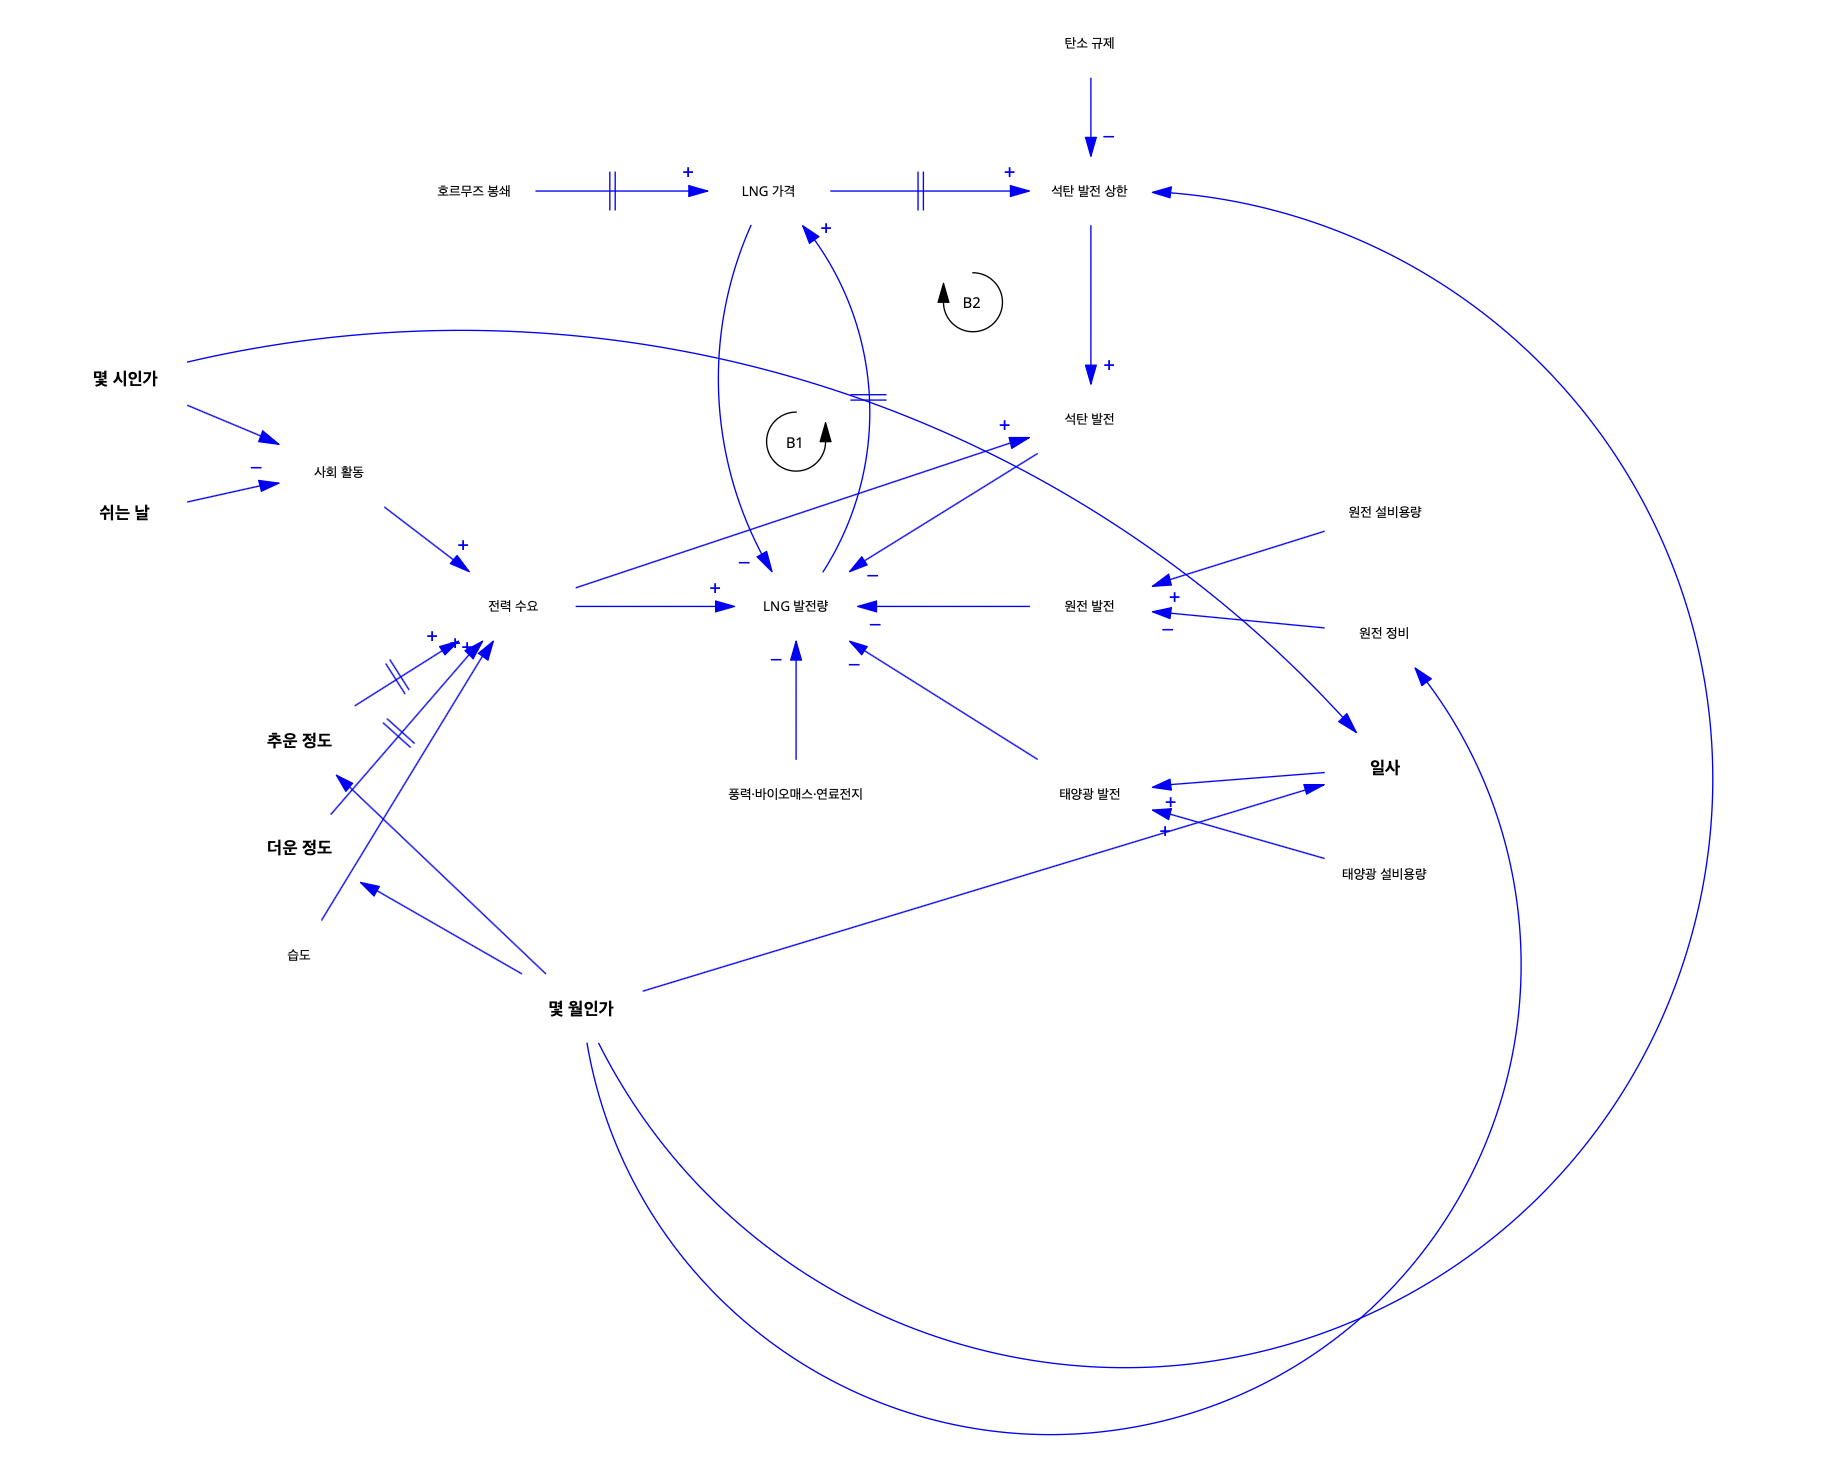

In [376]:
# 6단계 분석계획 · 7-다
import os                                                                            # 경로를 다루는 기본 모듈
import pandas as pd                                                                  # 표를 만든다
from IPython.display import display, Image                                           # 표와 그림을 셀 아래에 띄운다
def 보이기(표):                                                                       # 칸 안의 긴 글자를 「...」로 자르지 않고 격자로 띄운다
    with pd.option_context("display.max_colwidth", None): display(표)

if "ROOT" not in globals():                                                          # 준비 ①을 안 돌렸어도 되게, 준비 ①과 같은 방법으로 프로젝트 루트를 찾는다
    ROOT = os.getcwd()
    while not os.path.isdir(os.path.join(ROOT, "data")) and ROOT != os.path.dirname(ROOT):
        ROOT = os.path.dirname(ROOT)
FIG = os.path.join(ROOT, "figures")                                                   # 인과지도 파일이 있는 폴더

# 1) Vensim 파일(.mdl)은 글자 파일이다 — 그림 정보 부분에서 변수 줄(10,…)과 화살표 줄(1,…)을 뽑는다
with open(os.path.join(FIG, "인과지도_6단계.mdl"), encoding="utf-8") as f:
    글 = f.read()
스케치 = 글.split("\\\\\\---///")[1].split("///---\\\\\\")[0]                       # 그림 정보가 적힌 부분만 자른다
이름, 굵게, 화살표 = {}, set(), []
for 줄 in 스케치.splitlines():
    칸 = 줄.split(",")
    if 칸[0] == "10":                                                                  # 변수 줄 — 10, 번호, 이름, …
        이름[칸[1]] = 칸[2].strip('"')
        if "|B|" in 줄: 굵게.add(칸[2].strip('"'))                                     # 굵게 표시한 변수 = 모델이 보는 변수
    elif 칸[0] == "1":                                                                 # 화살표 줄 — 1, 번호, 원인, 결과, …, 부호(7번째 칸), …, 지연(10번째 칸)
        화살표.append((칸[2], 칸[3], {"43": "+", "45": "−"}.get(칸[6], "없음"), int(칸[9]) % 2 == 1))
화살표 = [(이름[a], 이름[b], s, d) for a, b, s, d in 화살표]                          # 번호를 이름으로 바꾼다

# 2) 화살표마다 문답에서 정한 것 — 부호와 지연(‖), 어디서 나왔나. 문답 번호는 7-나 「문답 기록」 [표 3]의 번호
정한것 = {
    ("일사", "태양광 발전"): ("+", "문답 1 · 창주 님"),
    ("태양광 발전", "LNG 발전량"): ("−", "문답 1 · 창주 님"),
    ("더운 정도", "전력 수요"): ("+ ‖", "문답 2 · 창주 님 / 지연은 문답 16 · 클로드 판단"),
    ("추운 정도", "전력 수요"): ("+ ‖", "1단계 물음 2 · 창주 님 / 지연은 문답 16 · 클로드 판단"),
    ("쉬는 날", "사회 활동"): ("−", "문답 3·8 · 창주 님 / 「사회 활동」은 클로드가 만든 변수"),
    ("몇 시인가", "사회 활동"): ("부호 없음", "문답 8 · 창주 님 / 「사회 활동」과 부호 없음은 클로드"),
    ("사회 활동", "전력 수요"): ("+", "문답 8 · 창주 님 / 「사회 활동」은 클로드가 만든 변수"),
    ("몇 월인가", "추운 정도"): ("부호 없음", "문답 9 · 창주 님"),
    ("몇 월인가", "더운 정도"): ("부호 없음", "문답 9 · 창주 님"),
    ("전력 수요", "LNG 발전량"): ("+", "1단계 물음 2 · 창주 님"),
    ("원전 발전", "LNG 발전량"): ("−", "문답 4 · 창주 님"),
    ("석탄 발전", "LNG 발전량"): ("−", "문답 5 · 창주 님"),
    ("전력 수요", "석탄 발전"): ("+", "문답 6 · 창주 님 / 「석탄을 줄인다」를 상한으로 나눈 것은 클로드"),
    ("원전 정비", "원전 발전"): ("−", "문답 7 · 창주 님"),
    ("원전 설비용량", "원전 발전"): ("+", "문답 7 · 창주 님"),
    ("습도", "전력 수요"): ("+", "문답 10·11 · 클로드 제안"),
    ("몇 월인가", "일사"): ("부호 없음", "문답 12 · 창주 님"),
    ("호르무즈 봉쇄", "LNG 가격"): ("+ ‖", "문답 13 · 창주 님 / 지연은 문답 13·16 · 창주 님"),
    ("LNG 가격", "LNG 발전량"): ("−", "문답 14 · 창주 님"),
    ("LNG 가격", "석탄 발전 상한"): ("+ ‖", "문답 15 · 창주 님 / 지연은 문답 16 · 클로드 제안"),
    ("석탄 발전 상한", "석탄 발전"): ("+", "문답 15 · 창주 님"),
    ("태양광 설비용량", "태양광 발전"): ("+", "문답 18 · 창주 님"),
    ("몇 월인가", "원전 정비"): ("부호 없음", "문답 17 · 클로드 판단"),
    ("몇 월인가", "석탄 발전 상한"): ("부호 없음", "문답 17 · 클로드 판단"),
    ("몇 시인가", "일사"): ("부호 없음", "7-나 ①을 다시 물을 때(채팅) · 창주 님"),
    ("LNG 발전량", "LNG 가격"): ("+ ‖", "7-다 ②를 다시 물을 때(채팅) · 클로드 제안, 창주 님이 맡기심"),
    ("풍력·바이오매스·연료전지", "LNG 발전량"): ("−", "7-라 「✍️ 읽고 나서」 · 클로드 제안, 창주 님이 맡기심"),
    ("탄소 규제", "석탄 발전 상한"): ("−", "7-라 「✍️ 읽고 나서」 · 클로드 제안, 창주 님이 맡기심"),
}
행 = []
for a, b, s, d in 화살표:
    그림 = ("부호 없음" if s == "없음" else s) + (" ‖" if d else "")                   # 그림에 그려진 부호와 지연
    정, 어디 = 정한것.get((a, b), ("(문답에 없음)", "문답 뒤에 새로 그은 화살표"))
    행.append({"원인 → 결과": f"{a} → {b}", "그림": 그림, "문답에서 정한 것": 정, "같나": "예" if 그림 == 정 else "아니오", "어디서 나왔나": 어디})
print(f"[표 1] 그린 화살표 {len(화살표)}개 — 그림의 부호와 지연(‖)을 파일에서 읽어, 문답에서 정한 것과 나란히 놓는다")
다름 = [r["원인 → 결과"] for r in 행 if r["같나"] == "아니오"]                         # 그림과 문답이 다른 화살표
빠짐 = [f"{a} → {b}" for a, b in 정한것 if (a, b) not in {(x, y) for x, y, _, _ in 화살표}]   # 문답에서 정했는데 그림에 없는 화살표
print("      → 그림과 문답이 다른 화살표:", " · ".join(다름) or "없음", "| 문답에서 정했는데 그림에 없는 화살표:", " · ".join(빠짐) or "없음")
보이기(pd.DataFrame(행).set_index("원인 → 결과"))
print("      부호 없음 — 몇 시인가 · 몇 월인가는 크기에 뜻이 없는 범주라서 + / −를 달지 않았다(선형회귀에 0/1 열로 나눠 넣는 것과 같은 까닭)")

# 3) 7-나 [표 2]의 화살표 후보 열여섯(4·5·6단계에서 본 근거)이 그림에 어떻게 들어갔나
후보 = [("1", "기온 → 전력 수요", "확인함"), ("2", "몇 시인가 → 전력 수요", "확인함"), ("3", "무슨 날인가(쉬는 날) → 전력 수요", "확인함"),
        ("4", "몇 월인가 → ?", "확인함"), ("5", "습도 → 전력 수요", "확인함 — 뺐다"), ("6", "전력 수요 → LNG 발전량", "일부러 뺌"),
        ("7", "전력 수요 → 석탄 발전", "일부러 뺌"), ("8", "일사 → 태양광 발전", "확인함"), ("9", "석탄 발전 → LNG 발전량", "일부러 뺌"),
        ("10", "태양광 발전 → LNG 발전량", "확인함"), ("11", "태양광 설비용량 → 태양광 발전", "확인함 — 뺐다"),
        ("12", "원전 발전 → LNG 발전량", "일부러 뺌"), ("13", "원전 정비 일정 → 원전 발전", "못 봄"), ("14", "호르무즈 봉쇄 → LNG 가격", "못 봄"),
        ("15", "LNG 가격 → LNG 발전량", "일부러 뺌"), ("16", "LNG 가격 → 석탄 발전 상한 → 석탄 발전", "못 봄")]
어느후보 = {("추운 정도", "전력 수요"): "1", ("더운 정도", "전력 수요"): "1", ("몇 시인가", "사회 활동"): "2", ("쉬는 날", "사회 활동"): "3",
            ("사회 활동", "전력 수요"): "2·3", ("몇 월인가", "추운 정도"): "4", ("몇 월인가", "더운 정도"): "4", ("몇 월인가", "일사"): "4",
            ("몇 월인가", "원전 정비"): "4", ("몇 월인가", "석탄 발전 상한"): "4", ("습도", "전력 수요"): "5", ("전력 수요", "LNG 발전량"): "6",
            ("전력 수요", "석탄 발전"): "7", ("일사", "태양광 발전"): "8", ("석탄 발전", "LNG 발전량"): "9", ("태양광 발전", "LNG 발전량"): "10",
            ("태양광 설비용량", "태양광 발전"): "11", ("원전 발전", "LNG 발전량"): "12", ("원전 정비", "원전 발전"): "13",
            ("호르무즈 봉쇄", "LNG 가격"): "14", ("LNG 가격", "LNG 발전량"): "15", ("LNG 가격", "석탄 발전 상한"): "16", ("석탄 발전 상한", "석탄 발전"): "16"}
def 묶어(쌍):                                                                           # 그린 화살표를 짧게 적는다
    if not 쌍: return "그리지 않음"
    if len(쌍) == 2 and 쌍[0][1] == 쌍[1][0]: return f"{쌍[0][0]} → {쌍[0][1]} → {쌍[1][1]}"          # 이어진 둘
    if len(쌍) == 2 and 쌍[1][1] == 쌍[0][0]: return f"{쌍[1][0]} → {쌍[1][1]} → {쌍[0][1]}"
    if len({a for a, _ in 쌍}) == 1: return f"{쌍[0][0]} → " + " · ".join(b for _, b in 쌍)      # 원인이 같다
    if len({b for _, b in 쌍}) == 1: return " · ".join(a for a, _ in 쌍) + f" → {쌍[0][1]}"      # 결과가 같다
    return " · ".join(f"{a} → {b}" for a, b in 쌍)
행 = []
for n, 글자, 근거 in 후보:
    쌍 = [(a, b) for a, b, _, _ in 화살표 if n in 어느후보.get((a, b), "").split("·")]          # 이 후보로 그린 화살표
    행.append({"번호": n, "후보(7-나 [표 2])": 글자, "근거 종류": 근거, "그림에서": "그대로" if 묶어(쌍) == 글자 else 묶어(쌍)})
print("[표 2] 7-나 [표 2]의 화살표 후보 열여섯이 그림에 어떻게 들어갔나")
안들어감 = [f"{r['번호']}번 {r['후보(7-나 [표 2])']}" for r in 행 if r["그림에서"] == "그리지 않음"]   # 그림에 안 들어간 후보
새로 = [f"{a} → {b}" for a, b, _, _ in 화살표 if (a, b) not in 어느후보]                     # 후보에 없이 새로 그은 화살표
print("      → 그림에 안 들어간 후보:", " · ".join(안들어감) or "없음", "| 후보에 없이 새로 그은 화살표:", " · ".join(새로) or "없음")
보이기(pd.DataFrame(행).set_index("번호"))

# 4) 고리 — 화살표를 따라가면 처음 변수로 돌아오는 길을 모두 찾는다
나감 = {}
for a, b, s, _ in 화살표: 나감.setdefault(a, []).append((b, s))
고리 = []
def 따라가기(처음, 지금, 지나온, 부호들):
    for 다음, s in 나감.get(지금, []):
        if 다음 == 처음: 고리.append((지나온 + [처음], 부호들 + [s]))
        elif 다음 not in 지나온 and 다음 > 처음: 따라가기(처음, 다음, 지나온 + [다음], 부호들 + [s])   # 같은 고리를 두 번 세지 않게
for v in 이름.values(): 따라가기(v, v, [v], [])
def 고리종류(부호): return "부호 없는 화살표가 있어 R·B를 정할 수 없음" if "없음" in 부호 else ("B" if 부호.count("−") % 2 else "R")
print("[표 3] 고리 수:", len(고리))
for 길, 부호 in 고리: print(f"      · {' → '.join(길)} ({고리종류(부호)})")

# 5) 경계 — LNG 발전량으로 바로 들어오는 원인마다, 모델이 보나(굵게)와 그 원인을 움직이는 변수 가운데 모델이 보는 것
들어옴 = {}
for a, b, _, _ in 화살표: 들어옴.setdefault(b, []).append(a)
def 거슬러(v, 본):                                                                    # v를 움직이는 변수를 화살표를 거슬러 올라가며 모두 모은다
    for a in 들어옴.get(v, []):
        if a not in 본 and a != "LNG 발전량": 본.add(a); 거슬러(a, 본)              # LNG 발전량을 거쳐 되돌아오는 길(고리)은 뺀다
    return 본
행 = [{"LNG 발전량으로 바로 들어오는 원인": a, "부호": "부호 없음" if s == "없음" else s, "모델이 보나": "봄" if a in 굵게 else "못 봄",
       "이 원인을 움직이는 것 가운데 모델이 보는 것(LNG를 거쳐 되돌아오는 길은 뺌)": " · ".join(sorted(거슬러(a, set()) & 굵게)) or "없음"} for a, b, s, _ in 화살표 if b == "LNG 발전량"]
print("[표 4] 모델이 보는 변수(그림에서 굵게):", " · ".join(sorted(굵게)))
print(f"      → LNG 발전량으로 바로 들어오는 원인 {len(행)}개 가운데 모델이 보는 것: {sum(r['모델이 보나'] == '봄' for r in 행)}개")
보이기(pd.DataFrame(행).set_index("LNG 발전량으로 바로 들어오는 원인"))

그림파일 = os.path.join(FIG, "인과지도_6단계.png")
if os.path.exists(그림파일): display(Image(filename=그림파일, width=900))          # 그리신 그림
else: print("그림 파일(figures/인과지도_6단계.png)이 없습니다")

### ✍️ 내 답변

#### ① [표 1]·[표 2]에서, 그림이 문답에서 정한 것과 다른 화살표나, 7-나 후보 가운데 그림에 안 들어간 것이 있습니까?

답: 내가 안 들어간 것을 하나씩 찾으라는 건가? 너가 적합하게 다 표시하면 되는 것 아닌가?

#### ② [표 3]에 고리가 있습니까? 없다면 그것이 무슨 뜻이라고 보십니까?

답: 고리는 자기 강화인데 그게 없네? 생각해 보니 작은 루프가 없는 게 말이 되나, 뭘 간과했나?

LNG 발전량에서 나가는 화살표는 없어. 다 LNG 발전량으로 들어오는 것밖에 없어. 그러면 이것도 뭔가 부족한 거 아닌가? 이대로 가도 괜찮은 거야? LNG를 많이 쓰면 당연히 석탄이 줄겠지? 마이너스니까? — 아, 그러네. 싼 게 먼저 사용되는 거잖아. 많이 쓰는 만큼 더 사 와야 하면… LNG의 가격? 그런데 R·B 루프가 하나도 없네. 우리가 고려하지 못해서 안 채운 건가, 가격은 따지지 않아서 안 그려진 건가? LNG 발전량 → LNG 가격은 너가 보기에 가장 적합하게. 그러면 다른 고리는 9단계에서 다시 시스템 다이내믹스를 쓰나? 7·9·10단계 모두 Vensim을 쓸 예정이겠네?

#### ③ [표 4]에서 LNG 발전량으로 바로 들어오는 원인 가운데 모델이 보는 것은 몇 개입니까? 그러면 모델이 보는 것과 못 보는 것의 경계를 한 문장으로 적어 보세요.

답: 모르겠다. 무슨 말인지.

직접적으로 바로 들어오는 건 없는 것 같은데? 굵은 글자 표시가 크게 눈에 띄지 않네 — 이름 크기를 바꾸거나 해야겠다. 그런데도 잘 맞히는 건 전력 수요라는 하나의 값으로 이어져서? 경계 문장은 결론으로 적어도 너무 좋아.

1. 그린 이미지는 여기 노트북 안에는 안 들어가나?
2. 답변이 많아서 어디서 무엇을 묻는지 모르겠다. 나머지도 대충 적긴 했는데 문장이 너무 많아서 무엇을 적어야 할지 모르겠다.
3. 여기서 얻은 인사이트도 잘 정리해 두어야겠다. 이런 시각은 빅데이터 프로젝트 대화에서는 잘 나오기 어렵다 — 다른 그림으로 봐서 알 수 있는 부분이니까.

### 클로드 답변

> **짧게** ①은 셀이 표마다 결과를 한 줄로 적게 고쳤습니다. ② 고리는 LNG에서 나가는 화살표가 없어서 생길 수 없었고, 「LNG 발전량 → LNG 가격」을 더해 균형 고리 둘이 생깁니다. ③에서 정하신 경계 문장은 물음 7 결론 칸에 적었습니다.

1. **그림** — 7-다를 돌리면 셀 맨 아래에 뜹니다. 코드를 돌리지 않아도 보이게 「7-나 문답 기록」 맨 위에도 넣었습니다.
2. **①** — 표마다 제목 바로 아래 「→」 줄에 결과가 나옵니다. 그림과 문답이 다른 화살표는 없고, 7-나 후보는 모두 그림에 들어갔습니다. 후보에 없이 새로 그은 것은 원전 설비용량 → 원전 발전 하나였습니다(문답 7번 답에서).
3. **② 고리** — 고리에는 처음 변화를 키우는 강화(R)와, 되돌리는 균형(B)이 있습니다. 고리는 화살표를 따라가 처음 변수로 돌아와야 생기는데, 문답에서 「무엇이 LNG를 움직이나」만 물어서 LNG 발전량에서 나가는 화살표가 없었습니다. 「LNG를 많이 쓰면 더 사 와야 하고, 그러면 가격이 오른다」(LNG 발전량 → LNG 가격 +, 지연, 근거 「못 봄」)를 더하면 균형 고리가 둘 생깁니다.
   - 가격 고리 — LNG를 많이 쓴다 → 가격이 오른다 → LNG를 덜 쓴다
   - 석탄 고리 — LNG를 많이 쓴다 → 가격이 오른다 → 정부가 석탄 상한을 푼다 → 석탄 발전이 는다 → LNG를 덜 쓴다

   장기계약 때문에 몇 달에 걸쳐 도는 고리라, 한 시각씩 맞히는 모델에는 영향이 없고 9단계에서 2026년을 달마다 읽을 때 쓰입니다. 강화 고리는 근거가 없어서 만들지 않습니다. 화살표 방향은 먼저 정해지는 쪽에서 따라가는 쪽으로 갑니다. 싼 것부터 쓰는 급전 순서라, LNG를 많이 써서 석탄이 주는 것이 아니라 석탄이 줄어서 LNG를 많이 씁니다.
4. **③** — 모델에 넣는 여섯과 LNG로 바로 들어오는 다섯은 겹치는 것이 없습니다. 그런데도 잘 맞히는 것은, 여섯이 전력 수요와 태양광 발전을 거쳐 LNG로 이어지기 때문입니다. 그래서 경계를 이렇게 적었습니다 — 「모델은 날씨·시간·달·날 종류만 보고, 이것들이 평소에 전력 수요와 태양광 발전을 거쳐 LNG를 움직인 길을 배운다. 그래서 2026년 예측과 실제의 차이에는 LNG 가격 · 석탄 발전 상한 · 원전처럼 모델이 보지 않는 것이 평소와 다르게 움직인 만큼이 들어 있다.」
5. **굵은 글자** — 눈에 잘 띄지 않아서, 모델에 넣는 여섯의 글자를 크게 바꿨습니다. 클로드가 파일에 적어 넣은 크기와 색은 Vensim이 쓰지 않아서 창주 님이 Vensim에서 직접 바꾸셨고, 화살표가 파란색이라 글자 색은 그대로 두셨습니다.
6. **7·9·10단계** — 이 그림은 7·9·10단계에서도 Vensim으로 고쳐 가며 씁니다. 숫자를 넣어 돌리지는 않습니다. 7단계에서는 모델이 크게 틀린 곳의 원인을 화살표로 더하고, 9단계에서는 2026년 달마다 차이 옆에 위 두 고리를 놓고, 10단계에서는 저량·유량 그림 한 장을 새로 그립니다.

### ✍️ 읽고 나서

답:

1. 루프가 있으면 거기에 R 혹은 B라고 표시하면 안 되나?
2. 큰 글자로 바꾼 여섯은 무엇을 뜻하나?
3. 이 정도면 된 것 같다. 지금 루프로 볼 수 있는 것은 두 개인가?
4. 인과지도는 이 정도면 충분한가, 놓친 것은 없나?

### 클로드 답변

> **짧게** 1 고리 표시 B1·B2를 그림에 넣었습니다. 2 큰 글자 여섯은 모델이 받는 값입니다. 3 고리는 둘이고 둘 다 B입니다. 4는 아래 7-라에서 직접 보시게 했습니다.

1. **R·B 표시** — 넣었습니다. B1은 가격 고리, B2는 석탄 고리이고, 둘 다 균형(B) 고리라 R은 없습니다. 무엇이 어떻게 도는지는 「7-나 문답 기록」 맨 위 그림 밑에 적었습니다.
2. **큰 글자 여섯** — 모델이 실제로 받는 값입니다. 몇 시인가 · 몇 월인가 · 쉬는 날(무슨 날인가 — 월요일 · 화~금 · 토 · 일 · 공휴일 · 명절) · 추운 정도(16도보다 추운 만큼) · 더운 정도(24도보다 더운 만큼) · 일사입니다. 그림의 나머지 열셋은 모델이 받지 않습니다. 그래서 큰 글자에서 LNG 발전량까지 가려면 전력 수요나 태양광 발전을 거쳐야 하고, 이것이 물음 7 결론의 「모델은 날씨·시간·달·날 종류만 본다」입니다.
3. **고리 수** — 둘입니다. LNG 발전량에서 나가는 화살표는 LNG 가격으로 가는 하나뿐이라, 고리는 모두 이 화살표를 지납니다. LNG 가격에서 바로 돌아오면 B1, 석탄 발전 상한과 석탄 발전을 거쳐 돌아오면 B2입니다. 둘 다 − 화살표가 하나씩 있어 B입니다. 7-다를 다시 돌리면 [표 3]에 나옵니다.
4. **놓친 것** — 아래 7-라를 만들었습니다. 결과는 7-라를 보시고 그 아래 칸에 적어 주세요.

**📘 빅분기 과목 연결** — 빅분기에는 인과지도가 따로 나오지 않습니다. 1과목(분석 기획)에서 분석 과제를 정의하기 전에 문제를 이루는 요소와 그 사이 관계를 정리하는 일과 가깝습니다.

### ✍️ 다시 읽고 나서

답: 이정도면 괜찮을것 같은데?

---
→ 7-다는 이것으로 마쳤다(10-05).

## 7-라

**점검** — 그림을 이대로 가도 되는지 보는 셀이다.

**어디서 나온 셀인가** — 고리 표시를 넣은 뒤(10-05) 창주 님이 채팅에 「인과지도는 이정도면 충분한가 놓친건 없나??」라고 물으셔서 만든 셀이다(7-다 「✍️ 읽고 나서」 4번).

**무엇을 보는 셀인가** — 앞 단계에서 원인으로 이름이 나온 것을 그림의 변수와 짝지어, 그림에 없는 것이 있는지 본다. 이름은 셋에서 가져왔다 — 1단계(창주 님이 적은 원인 여섯과 클로드가 고른 입력 후보 여덟), 4단계(입력에서 뺀 여섯), 지침(9단계에서 볼 「봉쇄 → 가격 → 석탄」 고리의 변수 넷). 짝은 클로드가 지었다.

**그림에 넣을지의 기준** — 지침에 적어 둔 것 하나다. 그 화살표가 입력을 정한 까닭(왜 넣었나 · 왜 뺐나)을 보여 주거나, 9단계에서 2026년 차이를 읽는 데 쓰이면 넣는다. 둘 다 아니면 그림만 복잡해지니 넣지 않는다.

In [377]:
# 6단계 분석계획 · 7-라
import os                                                                            # 경로를 다루는 기본 모듈
import pandas as pd                                                                  # 표를 만든다
from IPython.display import display                                                  # 표를 셀 아래에 띄운다
def 보이기(표):                                                                       # 칸 안의 긴 글자를 「...」로 자르지 않고 격자로 띄운다
    with pd.option_context("display.max_colwidth", None): display(표)

if "ROOT" not in globals():                                                          # 준비 ①을 안 돌렸어도 되게, 준비 ①과 같은 방법으로 프로젝트 루트를 찾는다
    ROOT = os.getcwd()
    while not os.path.isdir(os.path.join(ROOT, "data")) and ROOT != os.path.dirname(ROOT):
        ROOT = os.path.dirname(ROOT)

# 1) 그림(.mdl)에서 변수 이름을 뽑는다 — 7-다와 같은 방법
with open(os.path.join(ROOT, "figures", "인과지도_6단계.mdl"), encoding="utf-8") as f:
    스케치 = f.read().split("\\\\\\---///")[1].split("///---\\\\\\")[0]                 # 그림 정보가 적힌 부분만 자른다
그림변수 = {줄.split(",")[2].strip('"') for 줄 in 스케치.splitlines() if 줄.startswith("10,")}   # 변수 줄(10,…)의 셋째 칸이 이름

# 2) 앞 단계에서 원인으로 이름이 나온 것 — (어디서 나왔나, 이름, 그림에서 짝지은 변수, 짝지어도 그림에 없는 부분)
#    짝은 클로드가 지었다. 짝이 틀렸다고 보시면 아래 칸에 적어 주세요
#    (10-05 7-라 「✍️ 읽고 나서」에서 정한 뒤 「풍력·바이오매스·연료전지」와 「탄소 규제」를 그림에 더해 짝을 바꿨다)
앞이름 = [
    ("1단계 원인 목록 (창주 님)",  "탄소 배출",                         ["석탄 발전 상한", "탄소 규제"], ""),
    ("1단계 원인 목록 (창주 님)",  "추위와 난방",                       ["추운 정도"],               ""),
    ("1단계 원인 목록 (창주 님)",  "발전용이라 계절 영향이 작을 수 있음", ["몇 월인가"],               ""),
    ("1단계 원인 목록 (창주 님)",  "연료별 경제성",                     ["LNG 가격"],                "석탄 가격"),
    ("1단계 원인 목록 (창주 님)",  "카타르 물량과 지정학 위험",           ["호르무즈 봉쇄"],           ""),
    ("1단계 원인 목록 (창주 님)",  "상대 가격",                         ["LNG 가격"],                "석탄 가격"),
    ("1단계 입력 후보 (클로드)",   "기온",                              ["추운 정도", "더운 정도"],  ""),
    ("1단계 입력 후보 (클로드)",   "습도",                              ["습도"],                    ""),
    ("1단계 입력 후보 (클로드)",   "일사",                              ["일사"],                    ""),
    ("1단계 입력 후보 (클로드)",   "시간대",                            ["몇 시인가"],               ""),
    ("1단계 입력 후보 (클로드)",   "요일(주말)",                        ["쉬는 날"],                 ""),
    ("1단계 입력 후보 (클로드)",   "공휴일",                            ["쉬는 날"],                 ""),
    ("1단계 입력 후보 (클로드)",   "같은 시각의 원전 발전량",            ["원전 발전"],               ""),
    ("1단계 입력 후보 (클로드)",   "태양광 설비용량",                    ["태양광 설비용량"],         ""),
    ("4단계 입력에서 뺀 것",       "석탄",                              ["석탄 발전"],               ""),
    ("4단계 입력에서 뺀 것",       "총 거래량",                         ["전력 수요"],               ""),
    ("4단계 입력에서 뺀 것",       "가격",                              ["LNG 가격"],                ""),
    ("4단계 입력에서 뺀 것",       "풍력",                                  ["풍력·바이오매스·연료전지"],  ""),
    ("4단계 입력에서 뺀 것",       "바이오매스",                               ["풍력·바이오매스·연료전지"],  ""),
    ("4단계 입력에서 뺀 것",       "연료전지",                                ["풍력·바이오매스·연료전지"],  ""),
    ("9단계에서 볼 고리 (지침)",   "호르무즈 봉쇄",                      ["호르무즈 봉쇄"],           ""),
    ("9단계에서 볼 고리 (지침)",   "LNG 가격",                          ["LNG 가격"],                ""),
    ("9단계에서 볼 고리 (지침)",   "석탄 발전 상한",                     ["석탄 발전 상한"],          ""),
    ("9단계에서 볼 고리 (지침)",   "석탄 발전",                          ["석탄 발전"],               ""),
]

# 3) 짝지은 변수가 그림에 있는지 파일에서 확인한다
def 있나(짝, 없는부분):
    if not 짝 or any(v not in 그림변수 for v in 짝): return "없음"                    # 짝이 없거나, 짝지은 변수가 그림에 없다
    return "일부만" if 없는부분 else "있음"                                            # 변수는 있는데 원래 말한 것 가운데 그림에 없는 부분이 있다
행 = [{"어디서 나왔나": 곳, "이름": 이름, "그림에서 짝지은 변수 (클로드)": " · ".join(짝) or "—",
       "짝지어도 그림에 없는 부분": 없는부분 or "—", "그림에 있나": 있나(짝, 없는부분)} for 곳, 이름, 짝, 없는부분 in 앞이름]
표 = pd.DataFrame(행)

for 번호, (제목, 고른곳) in enumerate([("1단계에서 나온 이름 열넷 — 창주 님이 적은 원인 여섯과 클로드가 고른 입력 후보 여덟", "1단계"),
                                      ("4단계에서 입력에서 뺀 여섯과 9단계에서 볼 고리의 변수 넷", ("4단계", "9단계"))], start=1):
    부분 = 표[표["어디서 나왔나"].str.startswith(고른곳)]                                 # 이 표에 들어갈 줄만 고른다
    print(f"[표 {번호}] {제목}")
    print("      → 그림에 없는 것:", " · ".join(부분.loc[부분["그림에 있나"] == "없음", "이름"]) or "없음",
          "| 일부만 있는 것:", " · ".join(부분.loc[부분["그림에 있나"] == "일부만", "이름"]) or "없음")
    보이기(부분.set_index("이름"))

[표 1] 1단계에서 나온 이름 열넷 — 창주 님이 적은 원인 여섯과 클로드가 고른 입력 후보 여덟
      → 그림에 없는 것: 없음 | 일부만 있는 것: 연료별 경제성 · 상대 가격


,어디서 나왔나,그림에서 짝지은 변수 (클로드),짝지어도 그림에 없는 부분,그림에 있나
이름,,,,
탄소 배출,1단계 원인 목록 (창주 님),석탄 발전 상한 · 탄소 규제,—,있음
추위와 난방,1단계 원인 목록 (창주 님),추운 정도,—,있음
발전용이라 계절 영향이 작을 수 있음,1단계 원인 목록 (창주 님),몇 월인가,—,있음
연료별 경제성,1단계 원인 목록 (창주 님),LNG 가격,석탄 가격,일부만
카타르 물량과 지정학 위험,1단계 원인 목록 (창주 님),호르무즈 봉쇄,—,있음
상대 가격,1단계 원인 목록 (창주 님),LNG 가격,석탄 가격,일부만
기온,1단계 입력 후보 (클로드),추운 정도 · 더운 정도,—,있음
습도,1단계 입력 후보 (클로드),습도,—,있음
일사,1단계 입력 후보 (클로드),일사,—,있음


[표 2] 4단계에서 입력에서 뺀 여섯과 9단계에서 볼 고리의 변수 넷
      → 그림에 없는 것: 없음 | 일부만 있는 것: 없음


,어디서 나왔나,그림에서 짝지은 변수 (클로드),짝지어도 그림에 없는 부분,그림에 있나
이름,,,,
석탄,4단계 입력에서 뺀 것,석탄 발전,—,있음
총 거래량,4단계 입력에서 뺀 것,전력 수요,—,있음
가격,4단계 입력에서 뺀 것,LNG 가격,—,있음
풍력,4단계 입력에서 뺀 것,풍력·바이오매스·연료전지,—,있음
바이오매스,4단계 입력에서 뺀 것,풍력·바이오매스·연료전지,—,있음
연료전지,4단계 입력에서 뺀 것,풍력·바이오매스·연료전지,—,있음
호르무즈 봉쇄,9단계에서 볼 고리 (지침),호르무즈 봉쇄,—,있음
LNG 가격,9단계에서 볼 고리 (지침),LNG 가격,—,있음
석탄 발전 상한,9단계에서 볼 고리 (지침),석탄 발전 상한,—,있음


### ✍️ 내 답변

#### 1. 이 셀에 무엇이 나와 있습니까? 무슨 뜻이라고 읽으셨습니까?

답:  우리가 포함시킨 것과 포함시키지 않은 것들. 보면 알 수 있듯이 없는건 가격인데, 우리가 가격은 아마 최종에서 볼 수도 있었나? 그랬던 거 같은데 모델링하는 과거의 단계에서는 굳이 다루지 않기로 한 것으로 기억하고 있어서 넣지 않는게 맞나 싶긴 한데.. 인과지도는 다를려나?

- 그리고 추가적으로 너가 표2에 적은것처럼 외부요인이라든지 그런 것들은 추가적으로 뒤에 고려할 수 있게, 이번 단계에서만 이거 쓰는게 아니니까 괜찮지 않나? 반론이 있다면 언제든지 제시해줘

#### 2. 그림에 없는 것이 있다면, 위 기준으로 볼 때 그림에 넣어야 합니까, 뺀 채로 두어도 됩니까?

답: 지금 시점에 넣어도 되나? 또 뒤에 뺄 수도 있는거 아닌가? 나는 뭐 습도나 이런거 영향 적어서 안넣어도 될줄 알았는데 인과지도에는 들어간 것을 보면 들어갈 수도 있을 것 같은데? 정확히 어떨지는 잘 모르겠다.

### 클로드 답변

> **짧게** ① 맞게 읽으셨습니다. 인과지도는 모델과 달라서, 모델에 넣지 않은 것도 그립니다. ② 그림은 모델에 들어가지 않아 언제든 넣고 뺄 수 있습니다. 다만 이미 아는 것은 결과를 보기 전인 지금 넣는 편이 낫습니다. 아래 「✍️ 읽고 나서」 표대로 둘은 넣고 하나는 넣지 않는 쪽을 제안합니다(클로드 판단).

1. **가격** — 기억하신 대로 가격은 모델에 넣지 않고, 10단계(2026년 차이를 LNG 톤·카고로 옮겨 해석하는 단계)에서 해석 재료로 씁니다. 2026년에 달라진 것이 가격이라, 모델에 넣으면 「평소와 얼마나 달랐나」가 0에 가까워지기 때문입니다. 인과지도는 모델이 보는 것과 못 보는 것의 경계를 그리는 그림이라 LNG 가격은 이미 들어 있고, B1·B2 고리도 여기서 생겼습니다. 7-라에서 「일부만」으로 나온 것은 석탄 가격입니다. 「연료별 경제성」·「상대 가격」은 LNG 가격과 석탄 가격을 비교하는 말인데, 그림에는 LNG 가격만 있습니다.
2. **뒤에서 더 고려하기** — 맞습니다. 7단계에서는 모델이 크게 틀린 곳의 원인을, 9단계에서는 2026년 차이를 읽을 것을 이 그림에 더합니다. 반론 하나 — 결과를 보고 더한 화살표는 결과에 맞춰 그린 것이 되기 쉽습니다. 그래서 1단계·4단계에서 이미 아는 것은 지금 넣고, 결과를 보고 더하는 것은 언제 무엇을 보고 더했는지 적습니다.
3. **습도는 그림에 있는데 풍력은 없는 까닭** — 습도는 6단계 물음 4에서 넣어 보고 뺀 입력 후보라서, 그림이 「왜 뺐나」를 보여 줍니다. 풍력·바이오매스·연료전지도 4단계에서 입력 후보에서 뺀 것이라 같은 까닭으로 넣을 수 있는데, 클로드가 7-나 [표 1]을 만들 때 옮기지 않았습니다. 셋 다 작아서(풍력이 시각마다 흔들리는 폭이 LNG의 5%쯤이고 나머지 둘은 거의 일정 — 4단계 1-바) 한 변수로 묶어 그리는 쪽을 제안합니다.
4. **탄소 배출** — 1단계에 적으신 원인입니다. 탄소 규제가 석탄 발전 상한을 낮추면 석탄이 줄고, 석탄이 줄면 LNG가 늡니다. 2023년보다 2024·2025년에 석탄이 줄어든 것은 모델이 보지 않는 일이라 2025·2026년 차이에 섞여 들어올 수 있습니다. 6단계 물음 1에서 원전이 거꾸로 배워진 까닭도 2024년에 석탄이 줄어든 일이었습니다. 석탄이 줄어든 까닭이 탄소 규제인지는 확인하지 않았습니다(판단) — 그래서 근거는 「못 봄」입니다.

**📘 빅분기 과목 연결** — 1과목(분석 기획)에서 무엇을 보고 무엇을 보지 않을지(분석 범위)를 정하고 그 근거를 남기는 일과 같습니다.

### ✍️ 읽고 나서

**기준 → 나온 것** — 기준은 7-라 머리 칸(지침에 적어 둔 것)입니다.

| 그림에 없는 것 | 입력을 정한 까닭을 보여 주나 | 9단계에서 2026년 차이를 읽는 데 쓰이나 | 제안 (클로드 판단) |
|---|---|---|---|
| 풍력·바이오매스·연료전지 | 그렇다 — 4단계에서 입력 후보에서 뺐다 | 아니다 — 작고, 2026년 자료에는 「신재생·기타」로 묶여 따로 안 보인다 | 한 변수로 묶어 LNG 발전량으로 − 화살표 하나 |
| 탄소 규제 | 아니다 — 입력 후보였던 적이 없다 | 그렇다 — 2024·2025년에 석탄이 줄어든 일이 2025·2026년 차이에 섞일 수 있다 | 석탄 발전 상한으로 − 화살표 하나(근거 「못 봄」) |
| 석탄 가격 | 아니다 — 입력 후보였던 적이 없다 | 아니다 — 가격 자료는 받지 않기로 해서 옆에 놓을 숫자가 없고, 상대 가격 이야기는 LNG 가격이 맡는다 | 넣지 않는다 |

#### 1. 위 제안대로 그림을 고칠까요? 다르게 하실 것이 있으면 적어 주세요.

답: 너가 객관적으로 보고 가장 적절한 방향으로 해줘

### 클로드 답변

> **짧게** 제안대로 그렸습니다. 변수 둘과 화살표 둘을 더해 변수 스물하나 · 화살표 스물여덟이 됐고, 석탄 가격은 그리지 않았습니다.

1. **더한 것** — 「풍력·바이오매스·연료전지」(한 변수, LNG 발전량 아래) → LNG 발전량(−). 「탄소 규제」(석탄 발전 상한 위) → 석탄 발전 상한(−, 근거 「못 봄」). 둘 다 모델에 넣는 변수가 아니라 글자는 보통 크기입니다.
2. **결론 칸에서 바뀐 것** — LNG 발전량으로 바로 들어오는 원인이 다섯에서 여섯이 됐습니다. 모델이 그 가운데 하나도 보지 않는다는 결론은 그대로라 결론 칸의 「다섯」만 「여섯」으로 고쳤습니다. 새 화살표 둘은 LNG에서 나가는 화살표가 아니라서 고리는 그대로 둘입니다.
3. **7-다·7-라 코드** — 7-다 [표 1]에 새 화살표 둘이 어디서 나왔는지(7-라 「✍️ 읽고 나서」 · 클로드 제안, 창주 님이 맡기심)를 넣었고, 7-라의 짝을 새 변수로 바꿨습니다. 두 셀의 옛 결과는 지웠습니다 — 다시 돌리면 고친 그림으로 나옵니다.

### ✍️ 다시 읽고 나서

답: 

## ✍️ 6단계를 닫으며 — 7단계로 넘기는 계획과 인과지도

*(물음을 돌면서 채웁니다. 셋으로 적습니다 — ① 내가 던진 물음과 그 결과 표 ② 7단계로 넘기는 계획 ③ 인과지도와 다음 단계로 넘길 것. ① 표는 물음이나 아이디어가 나올 때마다 바로 한 줄씩 넣습니다.)*

### ① 내가 던진 물음과 그 결과

| 날짜 | 내가 물은 것 | 무엇으로 확인했나 | 나온 것 | 그래서 어떻게 했나 |
|---|---|---|---|---|
| 09-30 | (클로드 판단 — 창주 님이 물으신 것이 아니라 클로드가 정한 것) 5단계에서 선형회귀용으로 넘긴 기온 방식은 넷이었다. ① 16도보다 추운 만큼과 24도보다 더운 만큼(줄여서 16·24도) ② 10·16·24도에서 나눈 것 ③ 9·12·24도에서 나눈 것 ④ ①의 두 열을 시간대마다 따로 준 것. 넷을 모두 7단계 비교에 올릴지, 몇 개로 줄일지를 정했다(5단계를 닫으며 「6단계를 열면 먼저 후보를 줄인다」고 적어 둔 일) | 2023년으로 배워 2024년을 맞힌 R²를 방식마다 비교한 표 — 쉬는 날 × 시간대를 더한 모델에서(5단계 7-다 [표 1]) | ①이 0.7524였다. ②는 ①보다 0.0003 높고, ③은 0.0019 낮고, ④는 0.0155 높았다. 두 해를 배운 R²도 ④가 0.0167 높았다 | ①과 ④만 7단계에 올린다. 기준은 창주 님이 5단계 물음 1·4에서 세운 것 — 2024년 R²가 0.002 넘게 오르고, 두 해를 배운 R²도 같이 오르는가. ②·③은 0.002를 넘지 못했다. 되돌리시려면 말씀하시면 된다 |
| 09-30 | 「이정도로 넘기면 적합할까? 놓치거나 뭐 더 추가하거나 혹시 빼먹거나 한건 없을까??」(5단계를 닫기 전 채팅). (클로드 제안) 클로드가 답을 찾으려고 셀 밖에서 원전 발전량을 모델에 넣어 보니, 「원전이 줄면 LNG가 는다」가 한 해씩 배우면 나오는데 두 해를 같이 배우면 반대로 나왔다. 그래서 원전을 입력에 넣을지를 이 노트북의 물음 1에서 정하기로 했다(5단계 닫는 칸 ③ 「원전을 넣은 선형회귀를 셀로 봅니다」 줄) | 원전만 1,000 MWh 줄였을 때 LNG 예측이 얼마나 바뀌나 — 배우는 해 넷 × 모델 셋(1-가) · 2023→2024년에 원전·석탄·LNG가 얼마나 달라졌나(1-나) · 원전을 넣으면 2023년으로 배워 2024년을 더 잘 맞히나(1-다) | 2024년은 2023년보다 석탄이 한 시각 2,289 MWh 줄고, 그만큼을 원전(+880)·LNG(+924)·나머지(+558)가 같이 채웠다(1-나). 원전을 넣으면 2024년 R²가 세 모델 모두 내려갔다(0.0257~0.0485, 1-다). 두 해를 같이 배운 세 모델은 모두 「원전이 줄면 LNG도 준다」로 배웠다(1-가, −206·−156·−221) | 원전을 넣을지 정할 기준을 같이 세웠다(아래 10-02 줄). 10-03에 정하는 칸을 1-다 아래 ①에서 1-라 아래 ①~⑤로 옮겼다 — 창주 님이 ⑤에 「일단 빼는 방향이 맞아보이긴 해」라고 적으셔서 **원전을 모델 입력에서 뺀다**(10-03). 원전 자료는 7단계 잔차와 9·10단계 해석에 쓴다. 근거는 물음 1 결론 칸 |
| 10-02 | 「고려해야할 거면 앞에서 고려해도 좋아. 뒤로 넘기지 말고 필요한건 바로바로 하는거지」 — 클로드가 표지에 모델 후보 둘(기울기에 벌점을 주는 선형회귀인 릿지·라쏘, 그래디언트 부스팅에 시간대마다 나눈 기온 열을 넣는 것)을 확인 없이 7단계로 넘긴다고 적었을 때 하신 말 | — (진행 방식에 대한 말이라 셀이 없다) | — | 지금 자료로 볼 수 있는 것은 6단계에서 셀로 본다. 모델 후보 넷(릿지·라쏘 / 그래디언트 부스팅에 시간대별 기온 열 / 달마다 따로 배우는 모델 / 효과를 굽은 선으로 배우는 GAM)은 물음 6에서 2023년으로 배워 2024년을 맞혀 비교한다. 태양광 설비가 늘어도 일사 한 열로 되는지는 2024년 안에서 볼 수 있는 만큼 물음 3에서 본다. 지침에도 넣었다(v51) |
| 10-02 | 「미리 26년 데이터는 알고있으면 안되는거고? 그건 유출이니까」 · 「혹시나 누수가 있으면 안되니까 그건 철저히 지켜져야 해」 — 물음 1 머리 칸이 2026년 원전 숫자를 쓰는 것을 두고 | 물음 1 코드 셀 다섯에서 해를 고르는 줄과 LNG를 쓰는 줄을 뽑아 봄 | 2025·2026년 LNG를 읽어 계산하는 줄은 없었다. 다만 준비 ②가 읽는 표에 2025년 LNG가 들어 있었다. 2026년 원전은 예측할 때 넣는 입력 값이라 봐도 된다. 2026년 1~6월 LNG 합계(09-15)와 2025년 기준선 오차(09-17)는 이미 봤다 | 준비 ②가 2025년 LNG를 읽자마자 비우게 고쳤다. 지침에 「누수를 막습니다」를 넣었고(v52), 이미 본 숫자는 README 한계에 적었다. 고를 때는 2023년으로 배워 2024년을 맞힌 숫자와 미리 적은 기준만 본다 |
| 10-02 | 「너가 정하면 그건 내가 학습하는게 아니잖어」 — 클로드가 판단 기준 둘과 「원전을 넣지 않는다」는 제안을 먼저 내놓았을 때. 이어서 클로드가 「원전을 넣었더니 R²는 올랐는데 모델이 「원전이 줄면 LNG도 준다」로 배웠다면, 그 모델로 2026년을 예측해도 될까요?」라고 묻자 「그러면 잘못된거 아니야?? 앞뒤 내용이 다른데 어떻게 해야하는거야?」 | — (채팅에서 기준을 세웠다) | 기준 둘 — ① 2023년으로 배워 2024년을 맞힌 R²가 0.002 넘게 오르는가(5단계 물음 1·4에서 세우신 것) ② 모델이 원전에서 배운 방향이 넣는 이유와 같은가, 곧 원전이 줄면 LNG가 는다고 배웠는가(클로드가 물음으로 꺼내고 창주 님이 정하심) | 두 기준으로 1-가·1-다를 읽고 정한다(10-03부터는 1-라 아래 ①~⑤에서). 앞뒤가 다르면 길은 둘 — 원전을 빼거나, 맞는 방향을 배우도록 넣는 방식을 바꾼다 |
| 10-03 | 「석탄이 준 것을 모르는데 이건 어떻게 해야하는거지」(1-나 읽고 나서) · 「그러면 지금 결괏값을 본 다음에 어떤 방향으로 갈지 정해야하는거 아닌가??」(1-다 읽고 나서) · 「결정계수가 많이 차이나서 방향을 설정하기가 너무 어렵다」(채팅) | 지침 「■ 몸통」의 석탄을 넣지 않는 이유 · 지침 v52 「누수를 막습니다」 · 1-다 [표 1] | 석탄은 같은 시각에 LNG와 함께 정해지고 2026년에 달라진 것 자체라 모델에 넣지 않는다(「단순 빼기」는 09-22에 고친 설명이다). 볼 수 있는 결괏값은 2023→2024 숫자까지이고, 2025·2026년 결과를 보고 고르면 누수다. R² 차이가 크다는 것은 원전을 넣으면 세 모델 모두 뚜렷하게 나빠졌다는 뜻이다 | 석탄은 9·10단계에서 차이 옆에 놓고 읽는다. 원전은 지금 있는 2023→2024 숫자와 기준 둘로 정한다 — 방식 셋을 기준 둘에 대 본 표와 클로드 제안(③ 넣지 않는다)을 1-다 「읽고 나서」 답변에 적었다 |
| 10-03 | 「원전을 안넣으면 이게 맞나?? 안넣는다는게 모델링할 때 원전데이터는 아예 안쓰겠다는거야??」 · 「넣지 않는다는게 그렇다면 23,24,25,26다 원전을 뺀다는 말이야 정확히 어떤 의미지??」 · 「우리가 그런데 앞에서 원전을 다루었는데?? 그것들은 다 안쓰는거야?」 · 「지금 거의 한달넘게 했는데 적합한건지 전체적으로 보고 해야할 것 같어」 · 「지금까지 한 한달 넘게 그리고 앞으로 해야할 행위들이 무용하진 않은지」 | 독립 감사 둘(페이블) · 1~5단계 노트북의 코드 셀 세기 · 같은 구조의 방법 검색(미국 BPA의 절감량 검증 회귀 가이드, 텍사스 오스틴의 코로나 전력 수요 연구) | 원전을 넣지 않으면 네 해 모두 모델 입력에서 원전 열이 빠지고, 원전 자료는 7단계 잔차와 9·10단계 해석에 쓴다. 1~5단계 코드 셀 92개 가운데 원전이 나오는 셀은 19개이고 그중 18개는 다른 연료와 같이 본 셀이다. 지금 모델의 입력은 전부 5단계에서 넘긴 열이다. 평소 기간으로 날씨·달력 모델을 만들고 다른 기간의 실제와 비교하는 방식은 에너지 절감량 검증·코로나 영향 분석과 같은 구조다. 아직 모르는 것은 모델이 단순한 평균보다 나은가이다 | 방향은 그대로 간다. 「모델이 단순한 평균보다 나은가」를 물음 1 다음에 2023→2024로 먼저 본다(처음 계획에서 ⑤였던 것을 물음 2로 앞당겼다, 표지) |
| 10-03 | 「기준을 못 넘었다는게 너가 밖에서 돌린거지?? 원래 이게 몇 단계에서 해서 아니면 빼는 그렇게 순차가 적혀야하는거 아니야??」 · 「너가 외부에서 돌려서 뺍시다 이러면 내가 그냥 빼야지 이러면 그건 그냥 네가 하라는대로 따르는거지 학습이 아니잖어?」 · 「사실 이미 어떻게 진행될지는 검증후 답은 정해진 것 같은데 그 빼는 방식이나 선택의 논리가 물음에 잘 적혀야한다는거야」 · 「그러면 4단계에서 다시 돌아가야 하는거야?? 아니면 이미 한거고 6단계 그대로 가는거야?? 빼는건 6단계에서 하는거야?? 8단계는 결과만 적히는건가??」 | 노트북의 실행 번호와 셀 내용 대조 · 볼트 「빅데이터 분석의 순서」 4·6·7·8단계 | 1-가·1-다는 셀이고 직접 돌리셨다(실행 번호 3·5). 셀 밖에서 돌린 것은 09-30의 처음 발견과, 채팅에서 「왜 그렇게 나왔나」를 설명하며 쓴 숫자 둘이었다. 입력 후보를 넣어 보고 빼는 순서는 한곳에 적혀 있지 않았고, 볼트 노트는 변수 고르기를 7단계에 두면서 어느 구간으로 고르는지 적지 않았다. 4단계는 후보를 고르는 단계였고 그 근거는 지금도 맞아서 돌아가지 않는다. 8단계는 변수마다 넣은 이유·뺀 이유를 한 표로 모으고 1단계 원인 목록과 맞춰 보는 단계다 | 셀 밖 숫자 둘을 1-라로 옮겼다. 물음 1 머리 칸에 「결정까지의 순서」를 두고, 결정은 1-라 아래 ①~⑤로 묻는다. 넣어 보고 빼는 순서(4단계 후보 → 6단계에서 넣어 보기 → 8단계에 뺀 이유)는 지침 11단계 표와 볼트 노트 6·7단계에, 「결정에 이르는 순서도 물음으로 놓는다 · 셀 밖 숫자는 셀로 옮긴 뒤 쓴다」는 지침 「■ 규칙」에 적었다 |
| 10-03 | 「그러면 물음 순서대로 그냥 바꾸면 되는거 아니야? 5번이 2번 되면 되는거 아니야??」 — 클로드가 처음 계획의 ⑤를 물음 1 다음으로 앞당기면서 번호는 5로 둔 것을 두고 | — (진행 방식에 대한 말이라 셀이 없다) | — | 번호를 읽는 순서대로 바꿨다. 처음 계획의 ⑤(모델이 단순한 방법보다 나은가)가 물음 2가 되고, 처음의 ②·③·④는 ③·④·⑤가 됐다. 2-가에 기준을 적으신 뒤 답변을 넣으면서 한 번에 바꿨다(표지 · 물음 1 머리 칸과 결론 칸 · 이 칸의 계획 표 · README · handoff · 볼트 「LNG 프로젝트 — 무엇을 왜 어떻게」) |
| 10-03 | 「전체로 묶어서 본 것과 우리가 하려는 방향으로 나눈 것으로 모델링했을 때 결정계수가 어떻게 나오는지 보면 되지 않을까?」 · 「결정계수가 기본이고」 · 「26년도 모델링시 얼마나 결정계수가 차이가 나는지 알면 되지 않을까?」 · 「그걸 기준이라고 할 수 있나??」(2-가 「✍️ 내 답변」) | 2-가 [표 1] 기준선 넷 · [표 2] 지표 넷 · 지침 「누수를 막습니다」 — 결과 셀은 아직 없다(기준을 먼저 정한다) | 한 해 평균 하나로 예측하는 기준선은 R²가 0 근처라 거의 어떤 모델이든 넘는다. 2026년 LNG로 모델끼리 비교하면 누수이고, 2026년은 평소와 달랐을 해라 R²가 낮아도 모델 탓인지 가를 수 없다 | R²로 고른다(창주 님 선택). 모델끼리 비교는 2023→2024로 하고 7단계에서 2025년으로 채점한다. 클로드 제안 — 기준선 넷 가운데 2024년 R²가 가장 높은 것보다 모델 R²가 0.002 넘게 높고, 7단계 2025년에서도 그 기준선보다 높으면 「낫다」(5단계 기준의 꼴을 옮김). 평균 절대 오차는 9단계용으로 같이 적는다(클로드가 더함). 10-03에 창주 님이 「이정도면 검토는 충분히 마쳤으니 이제 너의 제안대로 가보자」라고 하셔서 이 기준으로 정했고, 결과 셀 2-나·2-다를 넣었다(2-가 「✍️ 읽고 나서」) |
| 10-03 | 「우리가 열심히 그래도 어떤 기준을 만들고, 변수를 찾고, 파생변수 추가하고 한게 무용한게 아니라는 것을 알 수 있는건」(2-나) · 「하나가 일률적으로 최적의 값을 보여주는 모델은 없어 보여」 · 「너가 보기에 적합한 방향으로 가자.」(2-다) | 2023년으로 배워 2024년을 맞힌 R²와 평균 절대 오차를 기준선 넷과 모델 셋에서 나란히 봄(2-나 [표 1]·[표 2]) · 같은 예측의 평균 절대 오차를 달마다, 네 시간 묶음마다 봄(2-다 [표 1]·[표 2]) | 가장 나은 기준선은 달·시각·날별 평균(R² 0.6948, 평균 절대 오차 2,341 MWh)이었다. 모델 셋은 R² 0.7535~0.7814로 그보다 0.0587~0.0866 높았고, 평균 절대 오차는 2,000~2,142 MWh였다. 모델이 덜 틀린 폭은 낮 8~15시(그래디언트 부스팅 525·723 MWh)가 밤(167~198 MWh)보다 컸다. 선형회귀는 4·5·7·11월에 그 기준선보다 더 틀렸고, 트리 계열 둘은 모든 달에서 덜 틀렸다. 달마다 가장 덜 틀린 모델이 달랐다 | 모델 셋 모두 기준을 넘었으니 이 방향으로 7단계까지 간다(물음 2 결론 칸). 기준의 뒷부분(2025년에서도 높은가)은 7단계에서 본다. 모델을 하나로 고르는 것은 8단계에서 한다 |
| 10-03 | 「모델 확정은 설명력->안정성->효율성(이거는 책에 나와 있는 내용인가? 일반적으로 이렇게 했나??」 · 「결국 뒤에서 다시 살펴서 결정해야하는거구나?」(2-다 「✍️ 읽고 나서」) | 볼트 「빅데이터 분석의 순서」의 평가 기준 줄과 출처 줄 | 세 기준과 순서는 아카데미 교재 네 권(분석 기초·예측·분류·과제수행)의 「모델 평가 3기준」에서 왔다고 그 노트에 적혀 있다(교재 원문은 이 세션에서 열지 못했다). 물음 2에서 정한 것은 「낫다」의 기준과 이 방향으로 간다는 것 둘이고, 넘긴 것은 2025년 확인(7단계)과 모델 하나 고르기(8단계) 둘이다 | 2-다 「읽고 나서」 답변에 적었다. 안정성은 물음 5에서 정할 「시간 순서대로 여러 번 나누기」로 본다 |
| 10-03 | 「26년 데이터는 안보는거 아니야??」 · 「25년도 검증용으로 쓰는거 아니었나??」(물음 3을 열었을 때 채팅) | 지침 「누수를 막습니다」 ⓑ · 물음 2 답변 칸의 📘 | 2025·2026년은 LNG를 읽지 않고 기온·일사만 읽는다 — 입력이라 봐도 된다. 2025년이 마지막에 한 번 채점하는 해인 것은 맞다. 클로드가 📘에 교재 말(검증 데이터 2024년 · 시험 데이터 2025년)을 썼는데 이 프로젝트 문서는 2025년을 「검증」이라고 불러 와서 말이 섞였다 | 물음 3 머리 칸에 「2025·2026년은 기온·일사만 읽는다」와 이 두 물음을 넣었다. 노트북에서는 「고르는 해(2024)」·「채점하는 해(2025)」로 적고, 물음 2 답변 칸 📘 두 곳을 그렇게 고쳤다 |
| 10-04 | 「0.2%는 그냥 둬도 되는 수준인지 아닌지가 잘 모르겠는걸?? 9%는 안될 것 같은데?? 이걸 느낌으로 정하는건 아닌거 같고 너가 제시한 수치가 아마 특정한 어떤 선택지를 대변하는것이겠지?? 9%는 안될 것 같긴 해」 · 「낮과 밤의 차이가 적은게 적합하다는 의미는 아니잖어?? 실질적으로 23,24년도의 값이 보여주는 어떤 차이가 있을텐데 그런 것과 비슷한게 적합한거니까 말이지?? 그래서 낮과 밤의 차이가 적다 = 적합한 모델이다? 이건 아닌것 같아. 시간별로 편차를 비교해서 편차가 적은건 적합하겠지??」(물음 3의 3-가 「✍️ 내 답변」 — 결과를 보기 전에 기준을 적는 칸) | 3-가 클로드 답변에 지어낸 숫자로 만든 예시 셋 — 낮과 밤의 평균 LNG와 그 잔차(예시 1·2), 두 시각 잔차의 크기와 방향(예시 3). 결과 셀(3-나·3-다)은 아직 없다 | 범위 밖 시각 수의 예로 든 10개(0.2%)와 400개(9%)는 지어낸 숫자였다. 「낮과 밤의 차이」는 클로드가 「낮 잔차 평균 − 밤 잔차 평균」을 줄여 적은 말이었고, 말씀하신 「실제 낮밤 차이와 예측이 비슷한가」와 같은 것이다(잔차의 낮 − 밤 = 실제 낮밤 차이 − 예측 낮밤 차이). 시각마다 오차의 크기만으로는 모델이 한쪽으로 틀리는지 안 보인다 | 답변 칸에 제안 둘을 적었다(클로드 제안) — 범위 밖 시각은 비율을 정하지 않고, 하나라도 있으면 7단계 채점과 9단계 비교에서 그 시각을 빼고 한 번 더 계산해 나란히 적는다 · 일사 한 열은 날마다 「낮 평균 잔차 − 밤 평균 잔차」를 구해 그 평균의 95% 신뢰구간이 0보다 아래면 못 따라간다고 본다. 3-다에는 시간 묶음마다 오차의 크기와 방향을 표를 나눠 넣는다. 정하신 것은 아래 10-04 줄 |
| 10-04 | 「둘다 좋아. 뭐 적절하게 통계적 수치 이용해서 찾아가는거지」(3-가 「✍️ 읽고 나서」, 채팅) · 「내가 앞서 3-가에 적은것을 토대로 간다는거야?? 내가 뭐라적은지 기억이 안나네 가장 적합한 방향으로 가자고 적었나?」(채팅) | 클로드가 3-가 제안 ②를 다시 봤다 — 3-가 답변 4번 표 · 5단계 3-마 [표 3](달마다 같은 햇빛이 LNG를 줄이는 양) · 2024년 8월이 빠진 것. 「적합한 방향」은 노트북에서 찾아봤다 | 3-가에는 「적합한 방향으로 가자」는 말이 없고, 물음 2의 2-다 「✍️ 내 답변」에 있다. 날이 332개라 3-라의 구간이 좁게 나와 작은 차이도 0 밖으로 나온다. 같은 햇빛이 LNG를 줄이는 양이 3~5월에 크고 7·8·12·1월에 작아서, 일사 한 열로 배운 선형회귀는 낮 잔차가 계절 따라 몰릴 수 있다 — 구간이 3-가 답변에 적은 「조금」보다 더 좁아질 수 있고, 8월이 빠져 평균이 0 아래로 갈 수도 있다(클로드 판단, 계산으로 확인하지 않았다) | 기준 둘을 제안대로 정했다 — 범위 밖 시각은 비율을 정하지 않고, 하나라도 있으면 빼고 한 번 더 계산해 나란히 적는다(3-나에서 센다) · 일사 한 열은 날마다 낮 − 밤 차이의 95% 신뢰구간으로 보고(3-라), 0보다 아래여도 바로 결론 내지 않고 달마다 나눠 본다(3-마, 클로드 제안). 결과 셀 3-나·3-다·3-라·3-마를 넣었다 |
| 10-04 | 「0.34 뭐 이정도는 괜찮은거 아닌가? 내가 느낌으로 아는게 아니라 너가 수학적인 수치로 적절한지 설명을 해줄 수 있겠지?」(3-나) · 「어떤건 양이고, 어떤건 음인데 그러면 특정한 방식의 모델링은 무언가를 크게 놓치고 있다고 생각이 드는데..」(3-라) · 「11월 달인 하나는 공통점이 있으니까 뭔가를 찾을 수 있나?? 싶고」(3-마) · 「아래 질문들이 있는데 이거 위에서 답변으로 나올 수 있는거 아니야? 다시 보고 대답해야하는거야??」(3-마) | 3-나 [표 1]·[표 2] · 3-다 [표 2]·[표 3] · 3-라 [표 1] · 3-마 [표 1]·[표 2] | 범위 밖 시각은 2025년 30개(0.34% — 7월 28개, 8월 2일 1개, 가장 더운 시각보다 최대 1.8도 더움)와 2026년 1~6월 1개(5월 8일 13시 일사 — 9단계에서 이미 빼는 5월 2~17일 안). 30시각이 2025년 평균 절대 오차를 1% 움직이려면 시각마다 평소 오차의 세 배쯤을 더 틀려야 한다. 날마다 낮 − 밤 잔차의 95% 구간 위 끝은 선형회귀 +248 · 랜덤포레스트 +465 · 그래디언트 부스팅 +559로 셋 다 0보다 위였다. 부호가 모델마다 갈린 것은 햇빛의 효과를 다르게 배워서다 — 선형회귀는 3~5월 −1,877~−2,035, 7·9월 +2,819·+1,967로 크게 갈리고 1년 평균에서 지워진다(5단계 3-마에서 같은 햇빛이 LNG를 줄이는 양이 봄에 크고 7월에 작았던 것과 같은 방향). 셋 다 −인 달은 5·6·11월, 셋 다 +인 달은 1·2·7·9월이다 | 기준(3-가)에 대면 2024년에는 세 모델 모두 「낮을 한쪽으로 틀린다」가 아니다. 정하신 것은 아래 10-04 줄이다(①~③은 위 칸들의 답과 겹쳐 지웠다 — 지침 v53). 같은 쪽으로 틀린 달의 이유는 2024년 한 해로는 가를 수 없어, 7단계에서 2025년 달마다 잔차를 볼 때 다시 본다(③) |
| 10-04 | 「표2가 lng라고 했는데 결과표에는 그런 내용이 안적혀 있어서 lng해당 내용인지 몰랐어」 · 「모델 자체가 가진 성능을 비교하기 위해 시간대로 그러면 비교해보려는건가??」(3-다) · 「뭐가 적합한건지는 아직 잘 모르겠다」(3-라) · ④ 「모르겠다」 · ⑤ 「모르겠어」(3-마) · 「그냥 나열이고, 뭐 어떤 식으로 지금 데이터가 넘어왔는지도 잘 모르겠어」 · 「그러니까 물음 3은 그래서 결국 바꿀것이 없다는 것이 결론이야??」 · 「좋아」(채팅) | 3-마 「읽고 나서」 답변의 결정 표 — 3-가에서 정한 기준 둘을 3-나 [표 2]와 3-라 [표 1]에 대 봄 · 표지 맨 위 「지금 어디」 | 물음 3은 고르는 물음이 아니라 계획대로 가도 되는지 확인하는 점검이었다. 범위 밖 시각은 2025년 30개·2026년 1~6월 1개였고, 날마다 낮 − 밤 잔차의 95% 구간 위 끝은 세 모델 모두 0보다 위였다. 시간대로 나눠 본 것은 모델 성능 비교가 아니라 낮에만 도는 태양광을 모델이 놓치는지 보려는 것이었다. 모델을 고르는 것은 8단계다 | 바꿀 것 없음으로 물음 3을 닫았다(📌 결론 칸). 표 제목에 「LNG 예측」을 넣었다. 표지 맨 위에 「지금 어디」를 숫자 없이 넣고, 지침 「가장 먼저 지키는 것」에 셋째 줄(창주 님은 지금 보시는 칸만, 며칠 간격으로 보신다)을 넣었다(v53) |
| 10-04 | 「그런데 우리가 기준을 0.002 결정계수로 잡았는데 결정계수는 개념상 내가 아는 바로는 컬럼이 늘어나면 결정계수가 늘어나는 문제가 있잖어? … 넣었고 결정계수 올라갔으며, 거기에 과적합이나 다중공선성의 문제가 없다면 넣자! 이렇게 되어야 해.」(4-나 내 답변) | 배운 해를 다시 맞히는 R²와 배우지 않은 해를 맞히는 R²를 나란히 놓고, 더한 열이 다른 열과 겹치는지를 같이 본다(4-나 클로드 답변 · 4-다 [표 1] 「차이 (두 해)」·「차이 (2024년)」 · [표 3] VIF) | 배운 해의 R²는 열을 더하면 오르거나 그대로라 맞는 지적이다. 5단계부터 기준 1은 배우지 않은 2024년을 맞힌 R²여서 쓸모없는 열이면 내려갈 수 있다(5단계에서 습도가 그랬다). 4-다에서 습도 그대로·습하면 1은 두 해에서만 조금 오르고 2024년에서 내려가 기준 2(과적합)를 못 넘었고, 불쾌지수는 이어졌지만 문턱 0.002 아래였다 | 기준을 셋(결정계수가 오르나 · 과적합이 없나 · 다중공선성이 없나)으로 옮겨 4-다를 만들었다 |
| 10-04 | 「0/1의 경우 모델의 결정계수나 예측이 올라가야 할 것이고 아니면, 뭐 습도의 퍼센트로 우리가 이전에 했던 불쾌지수 처럼 환산해가지고, 그것을 모델링에 집어넣었을 때의 결정계수를 봐야겠지??」(4-나 내 답변) | 지금 모델에 습도 그대로(%) · 습하면 1 아니면 0 · 불쾌지수가 75를 넘는 만큼을 하나씩 더해 본다(4-다 [표 1] 「+ 습도 그대로」·「+ 습하면 1」·「+ 불쾌지수 75 넘는 만큼」 줄 · [표 2] 「+ 습도 그대로」 칸) | 2023년으로 배워 2024년을 맞힌 결정계수 차이 — 습도 그대로 −0.0032 · 습하면 1 −0.0017 · 불쾌지수 75 넘는 만큼 +0.0012(문턱 0.002 아래). 트리 계열에 습도 그대로를 넣으면 랜덤포레스트 +0.0000 · 그래디언트 부스팅 +0.0009. VIF 2.1 · 1.6 · 8.9 | 넣는 방식 셋을 4-다에 넣었다. 「0/1」을 넣는다·안 넣는다로도, 습하면 1로도 읽을 수 있어 둘 다 담았다. 「습하면 1」의 선은 2023년 습도 가운데값(클로드 판단) |
| 10-04 | 「물음 4는 어떤 물음1,2,3에서 기인하는거야? 아니면 다른 단계 어디에서? 아니면 뭐 그냥 있는건가??」(채팅) | 4단계 닫는 칸 ②의 「6단계에서 확정하기 전의 후보입니다」 · 5단계 물음 7 결론 칸의 「습도 그대로를 입력에 넣을지는 6단계에서 정한다」 · 5단계 닫는 칸 ③의 6단계 줄 · 지침의 7단계로 넘어가는 조건 | 물음 1·2·3에서 나온 것이 아니고, 6단계가 원래 하는 일(넣을 열 목록 확정)에 4·5단계가 넘긴 것을 모은 물음이다. 물음 1(원전)은 그 목록의 한 줄을 먼저 떼어 본 것이다 | 물음 4 머리 칸 「어디서 나온 물음인가」를 풀어 적었다 — 처음에는 「표지 ④입니다」라고 번호로만 적어 이 내용이 안 보였다 |
| 10-04 | 「나는 트리계열이 너가 선형회귀랑 달리 알아서 판단한다고 말했던 것 같은데 이렇게 7개가 들어가는지는 몰랐네. 우리가 정한 선형회귀의 요소는 들어가는데 세부적으로 들어가지 않고 자체적으로 고른다는게 이런 의미구나」(4-가 내 답변) | 트리 계열에 넣는 일곱 열(4-가 [표 2]) | 트리는 받은 열 안에서 어디서 나눌지(기온 몇 도)와 어떤 열끼리 엮을지(일요일이면서 9시)를 스스로 찾는다. 받지 않은 정보(3시간 전 기온)는 못 본다 | 설명했다(4-가 클로드 답변). 트리 계열에도 3시간 전 기온을 줄지는 물음 4의 세부로 남아 있다 |
| 10-04 | 「불쾌지수를 넣으니까 올라가네? 이게 vif 8.9면 다중공선성에서도 조금 자유로워 보이는데 넣는게 적합하다고 할 수 있는거 같은데?? 근데 이전 단계에서 불쾌지수 개념을 넣으면서 뭐 문제가 있어서 안넣었던 것 같은데 지금은 또 괜찮네? 이유가 뭐지 뭐가 적합한걸까??」(4-다 내 답변) | 5단계에서 본 불쾌지수와 지금 본 불쾌지수를 나란히 놓는다(5단계 7-나 [표 2] 불쾌지수 줄 · 4-다 [표 1] 불쾌지수 줄) | 5단계 +0.0009, 지금 +0.0012 — 둘 다 문턱 0.002 아래라 같은 결과다. 적으신 기준에는 문턱이 적혀 있지 않고, 클로드가 5단계 기준을 따라 「0.002 넘게」로 옮겼다 | 문턱을 지킬지와 습도를 넣을지를 정할 것으로 물었다(4-다 「✍️ 읽고 나서」 ①·②) |
| 10-04 | 「트리계열의 경우 넣으면 gb는 올라가고 랜덤포레스트는 똑같구나. 선형회귀에서 강하게 영향력을 줄 수 있는데 트리계열에서는 크게 중요하진 않네. 대신 gb를 쓸 경우 고려할 수는 있겠다.」(4-다 내 답변) | 트리 계열에 습도 그대로를 넣기 전과 뒤(4-다 [표 2]) | 그래디언트 부스팅 +0.0009 · 랜덤포레스트 +0.0000, 둘 다 문턱 아래. 선형회귀에서도 바뀐 양은 모두 0.004 안쪽이라 강한 영향은 아니다 | 넣을지는 문턱을 지킬지(①)를 따른다고 답했다(4-다 답변 4) |
| 10-04 | 「vif는 선형회귀의 경우 고려했는데 트리계열은 고려하지 않는거야?? 개념적으로 그런건가??」(4-다 내 답변) | — 개념 물음이라 셀이 없다 | 트리에는 기울기가 없어서 VIF가 다루는 문제(겹치는 열끼리 기울기를 나눠 갖는 것)가 없다. 대신 8단계 변수 중요도에서 겹치는 열끼리 중요도를 나눠 가질 수 있다 | 설명했다(4-다 답변 5) |
| 10-04 | 「내가 배운바로는 하이퍼파라미터는 바꿀 수 있잖어? 리프라던지 깊이라던지 말이지? 그런 것들은 고려하지 않는건가?? 이거 적절한거 찾는게 그리드 서치인가??」(4-가 읽고 나서) | — 지금 쓰는 값을 적었다(랜덤포레스트 「나무 300그루 · 잎 하나에 최소 5시각」, 그래디언트 부스팅은 기본값) | 고를 수 있고 그리드 서치가 그 방법의 하나다. 고를 때 2025년을 쓰면 누수다 | 물음 6(7단계에서 비교할 모델)에서 물음 5의 시간 순서 검증으로 고르기로 하고 표지 ⑥에 적었다 |
| 10-04 | 「트리는 받은 것 안에서 나눈다고 했는데 그러면 지금 그걸 고려해야하는건가?? 어떤식으로 나눌지? 선형회귀와 다른 방식으로 나뉜다면 어떻게 해야하지?? 그럴 필요 없나?」(4-가 읽고 나서) | 5단계에서 트리에 16·24도 난방도·냉방도를 줘 본 줄(5단계 4-마 ② 줄) | 기온 그대로와 2024년 결정계수 차이가 두 모델 모두 0.002 안쪽 — 트리는 나눌 선을 스스로 찾는다 | 나누는 방식은 정하지 않아도 된다고 설명했다. 다른 열을 받아도 같은 2024년 시각을 같은 결정계수로 맞혀 비교한다 |
| 10-04 | 「트리 계열은 넣지 않고 0/1로만 보는거구나」(4-나 읽고 나서) | 트리 계열에 더한 열(4-다 [표 2] 「+ 습도 그대로」) | 트리에는 0/1이 아니라 습도 그대로를 넣었다 — 0/1 같은 선은 트리가 스스로 찾는다 | 바로잡았다(4-나 「읽고 나서」 답변) |
| 10-04 | 「0.002라는건 우리가 정한거야? 아니면 교과서나 뭐 경험적인 일반론에서 나온 수학적인 수치야??」(4-다 읽고 나서) | 0.002가 처음 나온 곳 — 5단계에서 냉방 기준 온도를 23~27도로 바꿔 본 결정계수(5단계 1-마 답변) | 교과서 숫자가 아니다. 냉방 기준 온도를 바꿔도 결정계수가 0.002 안에서만 움직여서, 클로드가 「이 정도는 표본이 조금 달라져도 순서가 바뀔 수 있다」고 보고 꺼낸 숫자다. 생각은 일반론(1-표준오차 규칙)이지만 크기는 계산한 값이 아니다 | 물음 5에서 시간 순서 검증으로 흔들림 크기를 계산해 0.002가 맞는지 보자고 제안했다(클로드 제안, 표지 ⑤) |
| 10-04 | 「지금 결론을 보면 빼는게 맞아 보이는데? 선형회귀나, 트리나?? 내가 잘못 해석했다면 얼마든지 반론 제시해줘. 여기서 제대로 하고 넘어가는게 더 중요하니까.」(4-다 읽고 나서) | 습도를 넣는 방식 셋의 결정계수와 VIF(4-다 [표 1]·[표 2]·[표 3]) | 해석이 맞다. 가장 센 반론은 불쾌지수(과적합·다중공선성 통과, 방향도 맞음)지만 오른 양이 작고(2024년에 못 맞힌 부분의 약 0.5%), 5단계에서 같은 문턱으로 뺀 열들과 앞뒤가 맞으려면 빼는 쪽이다(클로드 판단 — 정하신 뒤에 붙임) | 습도는 넣지 않기로 하셨다(물음 4 결론 칸) |
| 10-04 | 「7단계에서 하지 않고 6단계에서 하는 이유가 따로 있어?? 그거는 7단계에서도 되는거 아닌가??」(4-가 다시 읽고 나서) | 지침 v51(지금 자료로 볼 수 있는 것은 뒤로 넘기지 않는다) · 지침 「누수를 막습니다」 ⓒ | 7단계에서도 된다. 6단계에서 하는 까닭은 지금 자료로 할 수 있는 것을 뒤로 넘기지 않기로 한 것과, 7단계에서 2025년 점수를 보며 고르다 고치면 그 채점이 처음 보는 해의 성적이 아니게 되는 것이다 | 설명했다(4-가 「다시 읽고 나서」 답변) |
| 10-04 | 「0.002가 적합한지 아닌지는 잘 모르겠지만, 크게 영향이 없다는 그래도 기준을 정했으니까 해보는거지 뭐. 영향이 있을 수도 있겠지만 뭐 모든것을 다 고려할 수는 없으니까」(4-다 다시 읽고 나서) | — 진행 방식에 대한 말이라 셀이 없다 | — | 물음 5의 0.002 확인은 시간 순서 검증에서 저절로 나오는 숫자로 한 줄만 보기로 했다 — 일을 늘리지 않는다(4-다 「다시 읽고 나서」 답변) |
| 10-04 | 「그런데 이렇게 추운만큼, 더운만큼으로 나눈다는건 2등분한다는 의미 아닌가?? 우리가 그러니까 가장 일반적인 토대로 정한게 3등분이잖어? 16, 16~24, 24이상 이렇게 말이지?? 바뀐 만큼 방식은 이 내용과 다른거야??」 · 「결정계수 같아도 지금 방식에 다중공선성 문제가 있다면 수정해야하는거 아닌가? 어떻게 표1이 구성된지 정확히 이해 못해서 결정을 못내리겠다.」(4-라 내 답변) | 기온 10·20·28도와 「9시 10도 · 6시 8도」를 두 방식으로 적어 본 예시(4-라 클로드 답변 1·2) · 줄마다 VIF(4-라 [표 1]) | 열은 둘이지만 구간은 셋이고(가운데는 두 열이 다 0), 「바뀐 만큼」도 같은 두 열에서 계산해 세 구간은 그대로다. 같은 숫자를 다르게 적은 것이라 예측은 같고, 짝이 바뀌어 VIF가 내려간다 | 「바뀐 만큼」 방식으로 바꿨다(클로드 판단 — 적으신 「다중공선성 문제가 있다면 수정」이 그 기준) |
| 10-04 | 「둘다 0.002보다 작아서 넣기는 애매하네? 그래도 효과가 있긴 있을 수도 있다. 이정도로 해석할 수 있어 보이는데 너의 의견을 들려줘.」(4-마 내 답변) | 트리 계열에 3시간 전 기온을 더하기 전과 뒤(4-마 [표 1]) | 랜덤포레스트 +0.0011 · 그래디언트 부스팅 +0.0009, 둘 다 문턱 아래. 조금 오른 것은 맞지만 불쾌지수와 같은 크기다 | 트리 계열에는 넣지 않았다(클로드 판단). 물음 5의 0.002 확인에서 흔들림이 훨씬 작게 나오면 불쾌지수와 같이 다시 본다 |
| 10-04 | 「여기서 정하지말고, 어떤 답변 그러니까 내가 의견을 정하면 너가 다음것 만들고 그래서 결론이 이렇데 이런 흐름이 노트에 잘 적혀야하는건 알고있지??」 · 「노트북에 적혀야하거나 뭐 그런 흐름이 적혀있어??」(채팅) — 클로드가 4-라·4-마 판단을 결론 칸에 먼저 넣고, 채팅의 「좋아」로 물음 4를 닫자고 한 것을 두고 | — 진행 방식에 대한 말이라 셀이 없다 | 흐름(창주 님 의견 → 클로드의 다음 셀 → 결론)은 지침에 있었지만, 확인을 채팅으로 받아도 되는지와 클로드가 정하는 세부를 결론 칸에 언제 넣는지가 비어 있었다 | 지침 v54에 넣었다 — 정하는 것과 확인하는 것은 창주 님이 노트북 칸에 직접 적고, 클로드가 정하는 세부는 「읽고 나서」를 적으신 뒤에 결론 칸에 넣는다 |
| 10-04 | 「2번은 조금 어려운데, 약간 스케일링 처럼, 수치 전체가 크게 틀어지지 않게 조정이 된건가??」 · 「넣는 데이터는 같아서 결정계수는 같다고 보면 되는건가?」(4-라 읽고 나서) | 5단계 물음 6에서 표준화해도 예측이 같았던 것과 4-라 [표 1]·[표 2]를 나란히 | 넣는 정보가 같아서 결정계수는 같다 — 맞는 이해다. 표준화와 닮았지만, 표준화는 열 하나의 단위만 바꿔 VIF가 그대로이고 이번 것은 덜 겹치는 열로 바꿔 VIF가 내려간다 | 설명했다(4-라 「읽고 나서」 답변). 이의가 없으셔서 「바뀐 만큼」 방식을 확정했다(물음 4 결론 칸 같이 정한 것 1) |
| 10-04 | 「방향은 이해했는데 너가 다시 볼 곳에 대해서는 나도 틀을 잘 잡지는 못하겠네. 일단 살펴보면서, 다시 봐보자. 그리고 값이나 방식이 적합했는지 검토후에 나아가자.」(4-마 읽고 나서) | — | — | 트리 계열은 일곱 열 그대로 확정했다(물음 4 결론 칸 같이 정한 것 2). 다시 볼 곳의 틀 — 물음 5의 시간 순서 검증에서 불쾌지수와 트리 계열의 3시간 전 기온을 넣은 것과 안 넣은 것을 달마다 나란히 놓고 꾸준한지 본다 — 을 표지 ⑤에 적고, 7단계로 넘어가기 전에 보기로 했다 |
| 10-04 | 「말이 너무 어려운데..??」 · 「그런데 그러면 검증할 때 25년도 뭘 어떤걸 쓴다는거야??」 · 「25년도 데이터를 이제는 누출이 아니라 모델링에 학습시키고(이미 정해둔 어떤 틀이 있을테니까) 그 방식으로 모델을 강화시킨뒤 26년을 예측한다는 의미인가??」(5-가 「✍️ 내 답변」) | 5-가 [표 1] · 지침 「누수를 막습니다」 | 2025년에서는 모델에 넣는 기온·햇빛·시각·날 종류와, 맞힌 값과 한 번 비교하는 실제 LNG를 쓴다. 5-나의 여러 번 나눈 시험은 2023·2024년 안에서만 하는데, 물음 5 머리 칸에 「검증 방법」이라고 적어서 2025년 채점과 헷갈리게 했다(클로드 실수). 2025년까지 넣어 다시 배우는 것은 따로 여쭙는 두 길 가운데 하나로 맞게 읽으셨다 | 5-가 답변에 쉬운 말로 다시 적고, 머리 칸과 표지의 「검증 방법」을 「2023·2024년 안에서 시험을 여러 번 나눠 하는 방법(7단계의 2025년 채점과는 다른 것)」으로 고쳤다. 맞힐 값과 기간은 5-가 「읽고 나서」에서 확인받는다 |
| 10-04 | 「배우는 시각과 맞추는 시각이 같다면 그건 과적합 아닌가?? 아니 데이터 유출 아닌가?」 · 「그런데 비교는 예컨대 23년 1월과 24년 1월을 비교해야 가장 정당한거 아닌가? 이 데이터 자체가 월별, 주간별로 영향을 받는데 이런식으로 학습시키면 적합한 방식이라고 할 수 없는거 아니야? 너의 의견을 들려줘.」 · 「아직 모르겠다. 뭐가 적합한것인지. 내 의견을 듣고 너의 객관적인 생각을 말해줘.」(5-나 「✍️ 내 답변」) | 5-나 [표 2] 「배우는 달」 칸 — 모든 줄이 「2023년 1~12월」로 시작하고 맞히는 달 바로 전에서 끝난다 · 열이 아무 효과가 없을 때 시험마다 오르내림이 반반이라고 보고 낸 우연 확률(시험 4번에서 넷 다 오를 확률 약 6%, 11번에서 9번 이상 오를 확률 약 3%) | 세 방법 모두 배우는 시각과 맞히는 시각이 겹치지 않고, 맞히는 달과 같은 달을 전 해에서 배운다 — 모델은 「몇 월인가」·「무슨 날인가」 열로 달과 요일의 수준을 배운다. 비교는 같은 시험 안에서 열을 넣은 모델과 뺀 모델로 해서 그 달 사정이 양쪽에 같이 걸린다. 「1월은 1월로만 배운다」는 물음 6의 후보 「달마다 따로 배우는 모델」이다 | 클로드 생각으로 「한 달씩 넓혀 가며」를 드렸다(「시험 수」·「흔들림」은 클로드가 더한 기준). 고르시는 것은 5-나 「읽고 나서」에서 하신다 |
| 10-04 | 「그러면 25년을 학습시키는 경우는 23,24년에서 어떤 방식으로 뭐 변수든 모델이든 다 정한 다음에, 그러니까 완전히 끝마치고 난 뒤에 학습시키는거지??」 · 「그런데 그렇게 정했는데 25년 학습시 또 결과가 달라질 수도 있으려나?? 이미 23,24년 모델링 학습을 다해서 그것과 무관한가?」 · 맞힐 값은 「응 그대로 두는게 너가 봐도 맞다고 말했고, 내가 봐도 맞는 것.」(5-가 「✍️ 읽고 나서」) | — 진행 순서에 대한 물음이라 셀이 없다 | 다시 배운다면 열·모델·설정을 다 정하고 2025년 채점까지 마친 뒤, 같은 조합으로 2023~2025년을 처음부터 다시 배운다. 모델 안의 숫자(기울기, 트리가 나누는 기준)가 달라져서 2026년 예측도 조금 달라지고, 정한 조합은 바꾸지 않는다. 다시 배운 모델은 채점받은 적이 없다 | 맞힐 값은 시간별 LNG 발전량(MWh) 그대로로 정하셨다(닫는 칸 ②에 적음). 기간은 5-가 「다시 읽고 나서」에서 한 줄로 확인받는다. 다시 배울지는 따로 정한다 |
| 10-04 | 「달별로 그래도 특수성이 고려되어야 하는거 아닌가 하는 생각이 드는데」 · 「내가 상상하기로는 23년 1월, 24년 1월을 만들고 25년 1월로 검증해서 26년 1월을 모델링한다 이렇게 생각했거든? 그런데 그런게 아니라 가장 적합한 방향이 있다면 너의 아이디어를 들려줘.」 · 「그게 실제로 어떤 결과를 가져다줄지는 나도 모르거든??」(5-나 「✍️ 읽고 나서」) | 적으신 1월 흐름을 7·9단계와 6단계 연습 시험에 나란히 놓은 표(5-나 「읽고 나서」 답변 1번) · 5-다 [표 1]~[표 3] — 방법 셋을 지금 모델 셋에 다 돌림 | 적으신 1월 흐름은 7·9단계와 같고, 다른 점은 모델 하나가 열두 달을 같이 배우고 「몇 월인가」 열로 달마다 수준을 익힌다는 것이다. 1월 생각을 시험으로 옮기면 「지금처럼 한 번을 달마다 나눠 보기」가 된다 — 7·9단계처럼 앞 해로 배워 다음 해를 맞히는 시험이다 | 클로드 제안을 「한 달씩 넓혀 가며」에서 「지금처럼 한 번을 달마다 나눠 보기」로 바꿨다(처음 제안은 7·9단계가 한 해 앞을 맞힌다는 것을 덜 봤다). 고르시기 전에 무엇이 나오는지 보시도록 5-다를 넣었다(처음 계획은 고른 뒤 한 방법만 돌리기). 달마다 따로 배우는 모델은 물음 6에서 비교한다 |
| 10-04 | 「이 행위의 목적은 결국 23,24년 정하고 25년으로 검토해서 가장 좋은 어떤 조합, 구성을 찾고, 25년까지 학습해서 더 모델링을 단단하게 한 다. 26년 예측도를 조금 더 높이기 위함이라고 해석하면 되는 것 같은데 맞지?」 · 「나는 25년 데이터는 아예 못쓰는줄 알았거든」(5-가 「✍️ 다시 읽고 나서」) | — 진행 순서와 목적에 대한 물음이라 셀이 없다 | 순서는 맞다. 다시 배우는 목적은 2026년 실제에 가깝게 맞히는 것이 아니라 「2026년이 평소대로였다면」을 더 가까운 해의 평소로 내는 것이다(실제에 맞추면 차이가 사라진다). 2025년은 무엇을 고를 때는 못 쓰고, 채점을 마친 뒤 조합을 고정한 채 다시 배울 때는 쓴다 | ② 기간은 그대로로 정하셨다. 2026년을 맞힐 모델을 다시 배운 모델로 할지와, 2023·2024년 모델의 예측을 옆에 같이 놓을지(클로드 제안)는 5-가 「✍️ 다시 읽고 나서 (2)」에서 받는다. 다시 배울지를 묻는 셀은 따로 만들지 않는다 |
| 10-04 | 「그러면 내가 원래 예상했던 방식을 추가하는 것이고??」 · 「모델링은 그런데 어차피 전체적인 흐름을 의미하는 것이니 그런 방식으로 해도 괜찮은건가??」(5-나 「✍️ 다시 읽고 나서」) · 「이러면 도대체 우리가 앞에서 정한 막 파생변수나 뭐 그런건 거의다 무의미해지는거 아닌가??」 · 「이게 가장 적합한 방식은 맞는거지 그러면??」(5-다 「✍️ 내 답변」) · 「gb가 가장 높으면 도대체 기온이나 그런거 분류가 무의미하다는 의미인가...??」(채팅 — 5-다 「✍️ 내 답변」에 옮김) | 5-다 [표 1]·[표 2] · 5단계 1-마(시간대·월만 0.432 → 16·24도를 넣으니 0.501, 두 해를 배워 그 두 해를 맞힌 결정계수) · 5단계 물음 6·7(쉬는 날 × 시간대를 넣기 전 0.6515 → 넣은 뒤 0.7524, 2023년으로 배워 2024년을 맞힘) | 세 방법 모두 그래디언트 부스팅 > 랜덤포레스트 > 선형회귀이고, 같은 달의 가장 높은 모델은 11달 중 10달이 같다. 파생변수는 선형회귀용이고 트리 계열은 기온 그대로를 받는다 — 파생변수가 선형회귀와 랜덤포레스트의 차이를 0.11에서 0.0094로 줄였다. 그래디언트 부스팅 값은 컴퓨터마다 0.001 안쪽으로 다르게 나온다(창주 님 컴퓨터 0.7807 · 클로드 컴퓨터 0.7799, 까닭은 추측) | 파생변수는 그대로 둔다. 그래디언트 부스팅이 스스로 찾은 기온 꺾임이 16·24도 근처인지 물음 6 첫 셀로 본다(클로드 제안, 표지 ⑥). 시험 방법은 5-다 「✍️ 읽고 나서」에서 고르신다 — 클로드 제안은 「지금처럼 한 번을 달마다 나눠 보기」 |
| 10-04 | 「일단 gb가 전반적으로 높은 성능을 보이는데 거기에 적힌 컬럼도 앞에서 정한 것들이니까 일단 최종적으로 단계를 넘어가면서 봐야지 정할 수 있다는거네??」 · 「여기서 가장 적합한게 석달인 것 같은데..?? 아닌가?? 가장 높은 결정계수를 보이는 것으로 가는게 맞는것 같은데? 반론은 얼마든지 환영이야. 너가 보기에 최적의 방향은?」(5-다 「✍️ 읽고 나서」) | 5-다 [표 1] — 세 방법을 같은 기준(2024년 한 해로 모은 결정계수)으로 놓은 것 · 5-라 [표 1](같은 예측을 놓는 기간만 바꿈) · [표 2](같은 석 달을 두 방법으로) | 같은 기준에서 석 달씩은 가장 높지 않다(그래디언트 부스팅 지금처럼 한 번 0.7807 · 한 달씩 0.7847 · 석 달씩 0.7804). [표 3]이 높아 보인 것이 놓는 기간 때문인지는 5-라에서 본다 | 시험 방법은 점수가 아니라 실제로 할 일과 닮았나로 고르자고 반론했다. 클로드가 「7·9단계는 앞 해로 배워 다음 해를 맞힌다」고 적은 것을 고쳤다 — 9단계는 다시 배우는 길이면 1~6개월 앞을 맞힌다. 제안은 그대로(지금처럼 한 번을 달마다 나눠 보기). 고르시는 줄은 5-라 「✍️ 내 답변」 ② |
| 10-04 | 「gb가 높다는건 지금까지 한게 거의 무용하다는 의미 아니야??」 · 「언제나 말했듯이 질문에 대한 답은 셀의 결과로, 알지??」(채팅 — 클로드가 앞 물음에 채팅에서 말로 길게 답한 것을 두고) | 5-마 [표 1]·[표 2] — 2·4·5·6단계에서 정한 것을 하나씩 되돌려 2023년으로 배워 2024년을 맞힌 결정계수를 봄 | 그래디언트 부스팅도 앞 단계에서 정한 것을 하나 되돌릴 때마다 0.03~0.16 내려간다(가장 큰 것은 일사 대신 태양광 설비용량 −0.156). 선형회귀는 0.03~0.10 내려가고, 3시간 전 기온 두 열(물음 4에서 「3시간 동안 바뀐 만큼」으로 바꿔 적기로 한 열)을 빼는 것만 −0.0016으로 0.002보다 작다 | 5-마를 넣었다. 창주 님이 「표 1을 보면 무용하지 않다는 것을 이해했어 … 그러니까 그냥 계속해봐도 좋겠다.」(5-마 「✍️ 내 답변」)로 계속 가기로 하셨다. 3시간 동안 바뀐 만큼에도 같은 기준을 댈지는 5-바에서 여쭙는다(클로드가 더함). 탭이 열려 있어 셀을 넣지 못할 때도 말로 길게 답하지 않고 「탭을 닫으시면 그 물음을 보는 셀을 넣겠다」고만 하는 줄을 지침 v55에 넣는다 |
| 10-04 | 「이미 이 방향으로 정해진거 아닌가??」 · 「응 무엇이 최선인지 뒤에서 보면 어떤 교훈을 또 배울 수도 있겠지. 좋아.」(5-가 「✍️ 다시 읽고 나서 (2)」) · 「5-가는 이미 그렇게 정해진거 아니야??」(채팅) | — 진행 순서에 대한 물음이라 셀이 없다 | 다시 배우는 길은 「다시 읽고 나서」에서 이미 정하셨는데 클로드가 한 번 더 물었다 | 2026년을 맞힐 모델은 7단계 채점 뒤 같은 조합으로 2023~2025년을 다시 배운 모델로 정하셨다. 2023·2024년 모델의 2026년 예측도 옆에 놓는다(클로드 제안, 「좋아」). 닫는 칸 ②에 적었다. 지침 누수 줄은 v55에서 고친다 |
| 10-04 | 「석달이 가장 높은거 아니네」 · 「단순히 계수가 높다고 고르면 안되겠다 … 실제와 비슷해야 하니까.. 그게 중요하지.」(5-다 답변 아래 「✍️ 다시 읽고 나서」) · 「오히려 범위가 넓어지면서 선형회귀는 적합한 기울기가 아니게 되는건가?」 · 「각 모델마다, 그러니까 이게 조합을 통일시켜야하나? 트리나, 회귀나?? 그게 아니라면 가장 적합한 방향으로 조합을 짜서 넘겨야할것 같은데??」(5-라 「✍️ 내 답변」) | 5-라 [표 1](같은 예측을 놓는 기간만 바꿈) · [표 2](같은 석 달을 두 방법으로) | 같은 예측도 놓는 기간이 길수록 결정계수가 높다(그래디언트 부스팅 — 한 달씩 놓고 낸 값의 평균 0.737 · 석 달씩 놓고 낸 값의 평균 0.763 · 한 해를 통째로 놓고 낸 값 0.781). 같은 석 달을 「지금처럼 한 번」과 「석 달씩 넓혀 가며」로 맞히면 결정계수 차이는 0.012 안쪽이고, 방법을 바꿔도 모델 순서는 같다(5-다 [표 1]). 선형회귀가 조금 낮아지는 까닭은 확인하지 않았다(추측 — 두 해에 두루 맞는 기울기로 바뀌어서) | 시험 방법은 모든 모델에 하나로 맞춘다 — 모델과 열을 서로 비교하는 기준이라서. 열의 조합은 지금도 모델마다 다르다. 고르시는 줄은 5-라 「✍️ 읽고 나서」 |
| 10-04 | 「일단 여러 고려 사항들을 검토해서 넘겨야하는거 같은데? 뭐가 적절한지는 모델링해보고, 그것이 실제와 비슷한 형태로 나와야하는것을 정하는거잖어??」 · 「새로 넣을 열이 내가 적합한지 잘 모르겠어.」(5-마 「✍️ 읽고 나서」) | — 셀 없이 이미 정한 것으로 답했다(5-마 「읽고 나서」 아래 답변) | 6단계에서 「모델링해 보고 실제와 비슷한지」를 보는 숫자는 2023년으로 배워 2024년을 맞힌 결정계수다. 2025년 실제 LNG는 7단계 채점에 한 번만 쓴다 | 모델은 물음 6에서 후보를 정해 7단계로 같이 넘기고 8단계에서 고른다. 넣는 열은 6단계에서 0.002 기준으로 정해 넘긴다. 새로 넣을 열 둘(선형회귀의 불쾌지수 · 트리 계열의 3시간 전 기온)은 물음 4에서 0.002에 못 미쳐 넣지 않았다 |
| 10-04 | 「숫자의 기준은 얼마든지 바뀔 수 있고, 그게 뭐 0.001이든 0.002든 정했으면 그냥 하면 되는거 아닐까? 논리적으로 정하는 영역이 아니니까, 우리가 보기에 적합하다고 판단하면 적용하고 하는거지 뭐..」 · 「지금까지 이 방식으로 했으면 적합하다면 계속 이대로하는게 맞아보여」(5-바 「✍️ 내 답변」 ①·②) · 「뭘 정해야할지 잘 모르겠긴 하다..」(채팅) | 5-다 답변 4번(그래디언트 부스팅의 결정계수가 컴퓨터마다 0.001 안쪽으로 달라짐) · 5-마 [표 2]의 「3시간 전 기온 두 열을 뺌」 줄 | 0.002는 계산으로 나온 숫자가 아니라 관례로 정한 숫자이고, 컴퓨터 사이의 흔들림(0.001)보다는 크다. 「몇 달 나아졌나」를 세지 않으면 작은 오름이 우연인지는 0.002에 맡긴다 | 0.002를 그대로 둔다(창주 님). 클로드가 더한 「11달 가운데 몇 달 나아졌나」는 쓰지 않는다. ②는 「새로 넣는 열에만 대고 이미 넣은 열은 그대로 둔다(전진 선택법)」로 읽고 맞는지 여쭸다. 시험 방법(5-라 아래 칸 ①)이 비어 있어서, 정할 것 둘을 5-바 아래 「✍️ 읽고 나서」 한곳으로 모았다 |
| 10-04 | 「시험은 하나로 맞춘다고?? 모델에 따라 필요한 데이터셋이 다른거 아니야??」(5-라 「✍️ 읽고 나서」) · 「그러면 지금 여기서 뭐 두개를 고려했는데 둘다 0.002가 넘지 않아서 안넣겠다는거 아니야??」(5-마 답변 아래 「✍️ 다시 읽고 나서」) | — 셀 없이 답했다 | 넣는 열은 모델마다 다르고(선형회귀 67열 · 트리 계열 7열), 같게 하는 것은 채점하는 방법뿐이다. 불쾌지수와 트리 계열의 3시간 전 기온은 둘 다 0.002를 넘지 않아 넣지 않는다 — 읽으신 대로다 | 그대로 답했다 |
| 10-04 | 「내용이 너무 많은데 그래서 결론이 뭔데? 0.002 쓰겠다는거야 뭐야」 · ① 「적합해 보이는 방향으로 가자.」 · ② 「뭐가 적합한지 모르겠다」(5-바 「✍️ 읽고 나서」) · 「할때마다 읽을 양이 너무 많아가지고 버겁네」(채팅) | — | 0.002를 그대로 쓰고, 바뀌는 것은 없다 | 물음 5를 닫았다 — 시험은 지금처럼 한 번(클로드 제안을 따르심), 이미 넣은 열은 「계속 이대로」를 바꾸지 않는 쪽으로 읽었다. 결론 칸을 만들었다. 답변은 결론부터 짧게 쓰기로 했다(지침 v55에 넣을 것) |
| 10-04 | 「그런데, 23,24년 모델링해서 25년으로 검증하고, 다 정한 다음 25년까지 학습에 사용되잖어?? 그렇다면 이 23,24로만 결정할 수는 없는거 아닌가?? 일단 결정계수만으로 판정할 수는 없지만 어떤 기준이 충족된다면, 그리고 모델링해서 추후에 비교할 수 있다면 올리면 될 것 같은데? 너의 의견과 반론이 있다면 반론도 들려줘.」(6-가 「✍️ 내 답변」) | — 셀 없이 답했다 | 6단계는 2024년으로 거르기만 하고 마지막 고르기는 7·8단계에서 2025년으로 한다. 거르지 않고 다 올려 2025년으로 고르면 고른 모델의 2025년 점수가 실제보다 좋게 나온다(반론) | 2024년 0.002로 거르고 올린 후보는 7단계에서 2025년으로 다시 비교하자고 답했다. 「결정계수만으로」에는 6-나 표에 나아진 달 수를 참고로 같이 놓기로 했다(클로드 제안). 이대로 할지 6-가 「✍️ 읽고 나서」에서 여쭸다 |
| 10-04 | 「가장 적합한 방향으로 가자. 25년도 누수 없는 방향으로 최선의 방향을 너가 설정해줘. 내가 지금 디테일한 조합은 정확히 파악이 안되거든..?」(6-가 「✍️ 읽고 나서」) | 6-나 [표 1] 「0.002 넘게 높나」 줄 · [표 2] 「11달 가운데 나아진 달」 줄 | 기온 × 시간대 선형회귀만 0.002를 넘었다(+0.0155, 11달 가운데 10달 나아짐). 릿지 · 라쏘 · 굽은 선 선형회귀 · 달마다 따로(두 모델) · 시간대별 기온을 더한 그래디언트 부스팅은 넘지 못했다(달마다 따로 배운 그래디언트 부스팅은 −0.0719) | 후보를 만드는 방법은 클로드가 정했다(클로드 판단 — 6-나 머리 칸 표). 릿지·라쏘의 벌점 크기는 2023년 안에서만 고르고, 2025년 LNG는 쓰지 않는다. 6-나를 넣었다 |
| 10-04 | 「좋아. 객관적으로 가장 적합한 방향으로 여러 조건을 고려해서 누출없이 가보자.」(6-가 답변 아래 「✍️ 다시 읽고 나서」) · 「결과에 적힌 것처럼 기온x시간대 선형회귀 하나만 살아남았네. 표에 따라 그것은 추가하는거고, 표2는 뭐 이제 들어가는 목록을 적어둔건가?? 이제 표2가 넘어가는것들이야??」(6-나 「✍️ 내 답변」) | 6-나 [표 1] · [표 2] | [표 2]는 올라가는 목록이 아니라, 달마다 비교 대상보다 나았는지 센 참고다 | 7단계에서 비교할 것은 기준선과 모델 넷(선형회귀 · 기온 × 시간대 선형회귀 · 랜덤포레스트 · 그래디언트 부스팅)이다. 트리 계열의 설정을 바꿔 볼지 6-다로 여쭸다(4-가 「읽고 나서」의 그리드 서치 물음, 고르는 방법은 클로드 판단) |
| 10-04 | 「최적의 방향으로 혹시나 내가 여기 트리나 뭐 다른 모델에서 고려하지 못했는데 너가 보기에 객관적으로 현재 내가 하려는 모델링에 적합한 모델이 또 있을 수도 있잖어? 내가 간과한 것들 말이지?? 그런게 있다면 추가해도 좋고. 일단 적합한 것을 탐색해보자. 그리고 그리드 서치는 다음 단계에서 하는건가? 너가 말한 이 방식은 좋은 것 같어.」(6-다 「✍️ 내 답변」) | — 셀 없이 답했다 · 6-라 | 표 자료 회귀의 주요 계열(직선 · 굽은 선 · 랜덤포레스트 · 그래디언트 부스팅)은 다 비교했다. 시계열 모델은 2026년의 지난 LNG를 따라가 차이가 0에 가까워지고, XGBoost·LightGBM은 같은 계열, KNN·SVR과 신경망은 맞지 않는다 | 더 넣을 모델은 없다(클로드 판단). 그리드 서치는 6단계 6-라에서 한다 — 2023년 안에서 시간 순서로 나눠 고르고, 2024년에 0.002 넘게 높으면 7단계에서 그 설정을 쓴다 |
| 10-04 | 「표 1을 보면 최적값과 꽤 차이가 나는걸?? … 나무도 늘려야할 수도 있겠다.」 · 「… 0.002를 못넘긴 하네. 이게 고른 값으로 바꿔서 나온 결론인지 … 해봐야 아는걸까??」 · 「표3은 정확히 11월을 어떤식으로 무엇을 하겠다는건지 잘 이해가 안가서 의견을 못내겠다.」(6-라 「✍️ 내 답변」) · 「넣지 않는 이유들이 각각 있으니 뭐 적합한 것으로 해보자.」(6-다 답변 아래 「✍️ 다시 읽고 나서」) | 6-라 [표 1] · [표 2] · [표 3] | 고른 설정은 랜덤포레스트 잎 하나에 최소 1시각 · 열 전부, 그래디언트 부스팅 배우는 속도 0.05 · 잎 63 · 잎 하나에 최소 50시각 · 나무 300으로, 대부분 넣은 값의 끝이었다. 2024년 결정계수는 랜덤포레스트 +0.0014 · 그래디언트 부스팅 −0.0017로 둘 다 0.002를 넘지 못했고, 11달 가운데 나아진 달은 4 · 5였다 | 트리 계열의 설정은 지금 그대로 둔다(6-다 기준). 「표3」은 11월이 아니라 11개 달이라고 답했다. 끝 값이 뽑혀도 더 넓히지 않는 쪽을 제안했다(클로드 판단 — 2023년 안에서 고른 설정이 2024년에 낫지 않았다) |
| 10-04 | 「그리드 서치는 최적의 값을 찾는거 아니야?? 그런데 여기서 제시하는 조합이 우리가 한것보다 낮다는거야??」(채팅 — 6-라 답변 아래 「읽고 나서」 맨 아래 1번) | 6-마 | 2023년 안에서 맞힌 결정계수는 0.58~0.66으로 2024년(0.76~0.78)보다 한참 낮았다. 랜덤포레스트는 고른 설정이 2023년 안 · 2024년 모두 조금 높았고, 그래디언트 부스팅은 2023년 안에서만 높았다 | 그리드 서치가 찾는 최적은 고를 때 쓴 자료(2023년 안)의 최적이라고 짧게 답하고, 두 설정의 2023년 안 숫자와 2024년 숫자를 나란히 놓는 6-마를 넣었다 |
| 10-04 | 「너가 코드에 쓴걸 보니까 그리드 서치가 최적이라고 말한 조건을 설정해서, 우리가 정한 기존의 방식과 비교하고 있구나. 너가 위에서 설명한 23년도 자료에서 적합한 것을 그리드서치가 찾는다는건 이해했는데 24년과 유관해야 하는거 아닌가??」 · 「결과를 보니 흥미롭네. …」(6-마 「✍️ 내 답변」) | 6-마 [표 1] · 6-바 | 2023년 안의 시험은 몇 달로 배워 다음 몇 달을 맞히는 것이라, 한 해로 배워 다음 해를 맞히는 실제 일과 닮지 않았다(물음 5의 「실제와 비슷해야」에 맞지 않은 클로드 설계) | 설정을 2023년으로 배워 2024년을 맞힌 결정계수로 다시 고르는 6-바를 넣었다. 고른 설정의 2024년 숫자는 조금 좋게 나오고, 처음 보는 해로 확인하는 일은 7단계 2025년이 맡는다 |
| 10-04 | 「표1을 보면,, 23년만 보고 내린 결정과 다르다는건 알았어.」 · 「표2를 보면 넣을 수 있는 어떤 형태가 나오긴 했는데 그러면 포함시키고 적은 것처럼 7단계에서 해보면 되는거 아닌가 싶기도 해」 · 「… 수치적으로 얼마나 더 잘 예측하는지 봐야겠는데?? …」(6-바 「✍️ 내 답변」) · 「너의 설명을 보니 각각 트레이드오프가 있는데 나는 뭐가 적합한지 잘 모르겠다는게 결론이야..」(6-마 답변 아래 「✍️ 읽고 나서」) | 6-바 [표 1]~[표 3] · 6-사 | 2024년으로 고른 설정은 랜덤포레스트 잎 하나에 최소 1시각 · 가지를 나눌 때마다 열의 절반(0.7618 → 0.7701, +0.0083, 넘는다, 11달 가운데 6달 나아짐), 그래디언트 부스팅 잎 하나에 최소 50시각(0.7807 → 0.7824, +0.0017, 못 넘는다, 11달 가운데 7달) | 랜덤포레스트는 7단계에서 고른 설정을 쓰고, 그래디언트 부스팅은 지금 설정 그대로 간다(6-다 기준, 창주 님 「포함시키고 … 7단계에서 해보면」). 달마다 몇 MWh 덜 틀리는지 보는 6-사를 넣었다 |
| 10-04 | 「좋아. 그러면 너의 답변 처럼 적합하게 진행해보자.」(6-바 답변 아래 「✍️ 읽고 나서」) · 「흠, 어떤 것은 + / - 각각 더 틀리기도 하고 덜 틀리기도 하는 것 같아. 사실 이것만 보고 정하긴 어려워 보이는데..?」(6-사 「✍️ 내 답변」) | 6-사 [표 1] | 랜덤포레스트는 한 해로 모으면 한 시각에 평균 28MWh 덜 틀렸고(2,077MWh의 1% 남짓), 그 절반쯤이 9월(+161)에서 나왔다. 그래디언트 부스팅은 한 해로 모으면 0 | 이 표로 정하지 않고 미리 정한 기준(0.002)으로 정한다고 답했다. 물음 6을 닫고 결론 칸을 만들었다 |
| 10-04~05 | 「인과지도 내가 맨땅에 그리려니까 너무 어려운데?? 너는 이미 어떻게 그릴지 구상이 되어있니?? 거기에는 뭐 여러 수학적인 수치가 막 들어가야 하는데..? 혹시 내가 들고 있는 책이 있는데 영문 책인데 거기서 참고할만한게 있으려나??」 · 「실제로 내가 뭘 어떻게 그려야할지 감이 잘 안오거든...?」 · 「vs코드 보면 vensim을 여기 vs코드에서 구현?? 한지는 모르겠는데 우리가 사용하려고 했던 뭐 민감성 검사나 구조 같은것을 vs코드에서 실행할 수 있게 만들었었거든? 과거에 그것을 활용하면 되지 않을까 싶은데.?」 · 「인과지도는 물음으로 할 수 없는건가??」(모두 채팅) | 책 『Modeling and Simulation in Energy Management』 논문 2·5 사진 · 볼트 「시스템 다이내믹스 모델 이미지」 · `vensim-pysd-practice`의 README | 인과지도에는 숫자가 들어가지 않는다. 논문 2의 34쪽 Figure 4(같은 양의 전기를 만들 때 재생에너지가 더 돌면 화석연료 발전이 덜 돈다를 − 화살표 하나로 그림)가 우리 그림과 가장 가깝다. `vensim-pysd-practice`는 식이 있는 저량·유량 모델을 돌려 민감도를 보는 도구라, 식이 없는 인과지도에는 돌릴 것이 없다 | 인과지도를 물음 7로 열었다. 7-가에 넣는 것과 본보기를, 7-나에 변수와 화살표 후보·근거를 넣었다. Vensim PLE로 그리고, 저장한 `.mdl`은 7-다에서 셀로 읽어 근거와 대조한다 |
| 10-05 | 「그러면 이것도 결국 7단계에서 넘어가서 결국 결정해야하는거네??」(6-사 답변 아래 「✍️ 읽고 나서」) | 물음 6 결론 칸 · 지침 「누수를 막습니다」 ⓒ | 어느 모델이 나은지는 7단계의 2025년 채점이 정하고, 7단계에 올릴 후보는 6단계에서 끝낸다. 2025년 점수를 본 뒤에 후보를 바꾸면 그 점수가 처음 보는 해의 성적이 아니게 된다 | 「후보를 더 늘리지 않고 넷으로 7단계에 간다」로 읽었다고 답하고 맞는지 아래 칸에 적어 달라고 했다. 랜덤포레스트 설정의 이름 「나무마다 보는 열의 비율」이 틀린 말이라 「가지를 나눌 때마다 보는 열의 비율」로 고쳤다(클로드가 틀린 것) |
| 10-05 | 「그런데 인과지도는 vensim에서 그리는거잖어?? 물음이랑 어떻게 연동을 지어서 그림을 그리는거야?? 따로 뭐 파일을 만드는건가? 셀 코드로 만들 수는 없잖어??」 · 「물음 7은 이름을 조금 바꾸자. 시스템다이내믹스 뭐 그런거 적히면 좋지 않을까?? 너는 그런데 이미 전체적으로 그림을 그려봤지?? 가능하긴 한거니??」 · 「물음 7자체가 이건 내가 요청한거니까 그게 잘 적혔으면 좋겠어. …」(모두 채팅) | 7-나 [표 2]의 화살표를 코드로 이어 봄(셀 밖) | 그림은 Vensim에서 그려 `figures/`에 `.mdl`·`.png`로 저장하고, 노트북은 7-다에서 그 파일을 읽는다. 표의 변수 열여섯이 모두 LNG 발전량까지 이어지고 화살표끼리 겹치지 않게 한 장에 놓인다(「몇 월인가」만 화살표 끝이 비어 있다). 클로드 그림은 그리신 뒤 7-다에서 나란히 놓는다 | 물음 7 이름을 「시스템 다이내믹스 인과지도: …」로 바꾸고, 머리 칸 「어디서 나온 물음인가」에 09-13 요청부터 다시 적었다. 7-나에 Vensim과 노트북이 이어지는 방법을 넣었다 |
| 10-05 | 「넓힐 수 있는 가능성도 있다면, 이건 6단계에서 정하고 올려야하는거 아닌가?? 이것도 결국 7단계 모델링에서 나오는건가 결과가??」(6-사 「✍️ 다시 읽고 나서」) · 「표1의 표현이 너무 비유적이긴 한데, … 어떤 기준으로 정한지는 잘 모르겠는데」(6-아 「✍️ 내 답변」) | 6-아 [표 2] | 6-바에서 고른 값보다 더 크거나 작은 값 가운데 0.002를 넘은 것이 없었다 — 랜덤포레스트 +0.0000(가지를 나눌 때마다 보는 열을 줄이면 낮아짐), 그래디언트 부스팅 +0.0017(가장 높은 조합이 6-바에서 고른 것과 같음) | 설정은 6단계에서 끝내고 7단계에서는 바꾸지 않는다고 답했다. 넓히지 않자던 클로드 제안을 접고 6-아를 넣었고, 결과를 보시고 「적합한 방향으로. 위에 답변에 따라서.」(6-아 「✍️ 내 답변」) — 설정은 물음 6에서 정한 그대로다. [표 1]의 「끝 값」·「그 너머로」를 풀어 썼다 |
| 10-05 | 「우리가 가진 기존의 책, 이미지, 인과지도를 통해 그릴 수 있나?? 그리고 혹시나 우리가 인과지도를 그려서 결괏값으로 뭐 해당하는데 새로운 인사이트를 얻거나 할 수는 있는거야? … 우리가 찾고 본 여러 지표가 인과지도로 그려질 수 있나??」(채팅) | — (그리는 법과 근거 표의 구분) | 책과 이미지는 그리는 법을, 7-나 [표 2]는 무엇을 그릴지를 준다. 인과지도는 새 숫자를 내지 않지만 상관과 +/−가 다른 곳 · 2026년 차이에 섞인 것 · 7단계에서 오차를 먼저 볼 곳이 보인다. 지표는 변수가 아니라 화살표 옆 근거로 들어가고, 결정계수·평균 절대 오차·VIF는 모델에 대한 숫자라 넣지 않는다 | 7-가 「✍️ 읽고 나서」에 물음 넷을 옮기고 그 아래에 답했다. 7-가 「✍️ 내 답변」 「사실 어떤 방향으로 그러니까 그리는 것을 참고한다고는 이해했어. 한 번 해보자고.」 — 7-나로 그리러 간다 |
| 10-05 | 「뭐가 저량인지 유량인지 감이 잘 안잡히는데?? 뼈대는 너가 잡아줄 수 없나?」 · 「만들어진 예시는 다 저량이야?? 유량은 없어??」 · 「아니 너무 어려운데.. 감이 안잡힌다 진짜로 ...」 · 「아니면 너가 나에게 질문하면서 내가 어떤 인과관계를 만들면 너는 이미 답을 아니까 그것들을 조합해서 그림을 그리는 방향은 어때??」(모두 채팅, 7-나를 보며 그리다가) | 7-가 [표 1](인과지도에 넣는 것) | 인과지도에는 저량·유량이 없고 변수와 화살표만 있다. 클로드가 7-가·7-나에서 쓴 「상자」라는 말이 Vensim의 상자 변수(Box Variable — 저량을 그리는 도구)로 읽혀 헷갈리셨다 | 물음 7의 「상자」를 모두 「변수」로 바꿨다. 그리는 방식을 창주 님 제안대로 바꿔, 클로드가 여섯 번에 나눠 열여덟 개를 묻고 답하신 대로 `figures/인과지도_6단계.mdl`을 적었다 — 변수 열아홉, 화살표 스물넷. 지연 표시 네 개와, 모델이 보는 변수 여섯 개를 굵은 글자로 바꾼 것은 창주 님이 Vensim에서 했다. 모르겠다고 하신 곳과, 창주 님 말을 클로드가 다른 변수로 옮겨 그린 곳(사회 활동 · 석탄 발전 상한)은 「클로드가 정한 것」 여섯 가지로 따로 적었다(7-나 문답 기록) |
| 10-05 | 「그런데 잠깐 석탄 26년도에는 늘었는데 그건 지금 말해선 안되는 정보겠지?이건 예측 부분이니까?」(채팅, 문답 6을 하다가) | 지침 「누수를 막습니다」 | 누수는 2025·2026년 LNG를 보고 입력이나 모델이나 기준을 고르는 것이다. 인과지도는 모델 입력을 바꾸지 않으니, 2026년에 석탄이 늘었다는 것을 숫자 없이 구조(석탄 발전 상한 → 석탄 발전)로 그리는 것은 괜찮다. 얼마나 늘었는지는 9단계 비교 전까지 쓰지 않는다 | 그림에 숫자 없이 화살표로만 넣었다 |
| 10-05 | 「그런데 해당하는 이제 벤심을 그렸는데 거기에 수치나 그런게 적어야하는거 아니야? 그래야 그래프가 그려지지 않나??」 · 「여기서는 그냥 인과지도만 그리는건가? 아그러면 지금여기서는 해당수치를 모르니 할수없는거고??」 · 「그러면 추후 뒤에 모델링다 한 뒤에는 값을 넣을수있는건가? 그것도 몰라서 못하나??」(모두 채팅) | 7-가 [표 1] · 지침 「시스템 다이내믹스를 어디에 쓰나」 | 인과지도에는 수치가 들어가지 않는다. 그래프를 그리는 시뮬레이션은 저량·유량 모델에 식을 넣어야 하는데, 이 프로젝트에는 저량 자료(LNG 재고·계약 물량)가 없고 시뮬레이션 결과를 맞춰 볼 정답도 없다. 모델링을 마친 뒤에 할 수 있는 것은 모델이 보는 화살표 옆에 효과 크기(예: 16도보다 1도 추울 때 LNG가 얼마 느나)를 근거로 적는 데까지다 | 6단계에서는 인과지도만 그린다. 효과 크기를 화살표 옆에 적는 것은 8단계(모델을 고르고 핵심 인자를 적는 단계)와 11단계(README)에서 한다. 시뮬레이션은 이 프로젝트를 마친 뒤의 다음 프로젝트 후보로 둔다(지침) |
| 10-05 | 「적합한지, 너가 제시한 질문에 대해 적합하게 그려졌는지, 그리고 우리가 지금까지 본 어떤 전체적인 맥락에서 적합한 인과지도인지 확인해줘」(채팅, 그림을 저장한 뒤) | 7-다 — 저장한 `.mdl`을 읽어 [표 1] 문답에서 정한 것과 그림 · [표 2] 7-나 [표 2]의 화살표 후보 열여섯(4·5·6단계 근거)과 그림 · [표 3] 고리 · [표 4] LNG 발전량으로 바로 들어오는 원인을 모델이 보나 | 그림은 문답과 모두 같았다 — 그림과 문답이 다른 화살표 없음, 7-나 후보 열여섯이 모두 그림에 있음, 후보에 없이 새로 그은 것은 원전 설비용량 → 원전 발전 하나. 고리는 0개였다. LNG 발전량으로 바로 들어오는 원인 다섯 가운데 모델이 보는 것은 0개였다 | 클로드가 채팅에서 먼저 답하지 않고 7-다 셀을 만들었다. 7-가 답변에 적은 「클로드 그림은 그리신 뒤 7-다에서 나란히 놓습니다」는, 문답으로 그리게 되어 클로드 그림을 따로 그리지 않고 클로드가 미리 생각한 화살표(7-나 [표 2])를 7-다 [표 2]에서 그림과 맞춰 보는 것으로 했다 |
| 10-05 | 「그린 이미지는 여기 노트북 안에 안들어가는거야??」 · 「7-나에 뭐 동의하는지? 그런건 왜 묻는거야? 그냥 여기했고 정하면 진행하면 되는거 아닌가??」 · 「1번 답변에서 뭐 내가 안들어간지 하나씩 찾으라는거야? 너가 적합하게 다 표시하면 되는거 아니야??」 · 「고리는 자기 강화인데 그게 없네? 생각해보니까? 작은 루프가 없는게 말이 되나 뭘 간과했나??」(모두 채팅, 7-다를 돌린 뒤) | 7-다 [표 3](고리 수)과 그림 | 그림은 7-다를 돌려야 셀 아래에 보였다. 7-나 ④는 문답에서 이미 맡기신 것을 다시 물은 것이었다. 7-다 ①은 표를 하나씩 봐야 답할 수 있었다. 고리와 경계는 아래 두 줄처럼 채팅에서 하나씩 다시 물어 풀었다 | 채팅에서 하신 말을 7-나 ④와 7-다 ①~③ 답 줄에 옮겼다(「채우라는게 너의 의견을 채우라는게 아니라 내가 적은 말을 채우라는 의미였어」). 그림을 7-나 문답 기록 맨 위에도 넣었고, 7-다 셀이 표마다 결과를 한 줄로 적게 고쳤다. 7-나 「✍️ 내 답변」 칸이 코드 칸으로 바뀌어 있어 글 칸으로 되돌렸다 |
| 10-05 | 「전력 수요가 늘면 당연히 둘다 늘어나겠지」 · 「아니 그림상으로 보면 몇시인가가 일사로 연결되는건 없어보여」 · 「연결되어야 하는거 아닌가 그러면??」 · 「그림대로면 석탄이 줄면 lng줄고, 원전이 늘면 lng줄어」 · 「그림상 석탄 발전 -> - lng발전량 아니야??」 · 「그러네 방향인데 내가 -를 잘못 읽었구나」 · 「24년? 원전이 늘어서?」(채팅 — 7-나 ①·②를 짧은 물음으로 하나씩 다시 물었을 때) | 그림의 화살표(전력 수요 → 석탄 발전 + · 전력 수요 → LNG 발전량 + · 석탄 발전 → LNG 발전량 − · 원전 발전 → LNG 발전량 −) · 6단계 1-나(2023→2024년 한 시각 평균 석탄 −2,289 · 원전 +880 · LNG +924 MWh) | 석탄과 LNG가 같이 오른 것은 전력 수요가 둘을 함께 늘려서다. 일사와 LNG가 같이 오른 것은 낮이 둘을 함께 늘려서인데, 그림에 「몇 시인가 → 일사」가 빠져 있었다(클로드가 낸 7-나 후보에도 없었다). − 화살표는 「반대로 움직인다」라서 석탄이 줄면 LNG는 는다. 2024년에 LNG를 늘린 것은 석탄 감소이고, 「원전이 늘어서」는 모델이 배운 것과 같은 답이었다 — 모델에는 석탄이 없어서 같은 해에 같이 는 원전을 원인으로 배웠다 | 「몇 시인가 → 일사」(+ / − 없음)를 그림에 더한다(창주 님 판단) |
| 10-05 | 「아니 없어. 다 lng발전량으로 들어오는 것밖에 없어」 · 「lng 많이 쓰면?? 당연히 석탄이 줄겠지? 마이너스니까? 태양광이나 원전, 석탄이 주는거 아닌가?」 · 「아 그러네. 그 뭐지 싼게 먼저 사용되는거잖어??」 · 「흠 lng의 가격??」 · 「그런데 r, b루프가 하나도 없네 여긴. 이것도 아마 채워져야겠지?? 우리가 지금 고려하지 못해서 안채운건가? 우리가 가격은 따지지 않아서 인과지도에는 안그려진건가??」 · 「너가 보기에 가장 적합하게」 · 「직접적으로 바로들어오는건 없는거 같은데?」 · 「잘 모르겠다.. 전력수요라는 하나의 값으로 이어져서??」 · 「응 결론으로 적어도 너무 좋아」(채팅 — 7-다 ②·③을 하나씩 다시 물었을 때) | 그림 — LNG 발전량에서 나가는 화살표가 있나, 모델에 넣는 여섯과 LNG로 바로 들어오는 다섯이 겹치나 · 4단계 2-라(하루 안에서 는 전력 수요의 74%를 LNG가 맡았다) | 고리가 없던 것은 문답에서 「무엇이 LNG를 움직이나」만 물어 LNG에서 나가는 화살표가 없어서다. 「LNG를 많이 쓰면 더 사 와야 하고 가격이 오른다」를 더하면 균형 고리 둘(가격 고리 · 석탄 고리)이 생긴다. 화살표 방향은 먼저 정해지는 쪽에서 따라가는 쪽으로 가서(급전 순서), LNG를 많이 써서 석탄이 주는 것이 아니다. 모델은 LNG로 바로 들어오는 다섯을 하나도 보지 않고, 여섯이 전력 수요와 태양광 발전을 거쳐 LNG로 이어지는 길을 배운다 | 「LNG 발전량 → LNG 가격」(+, 지연, 근거 「못 봄」)을 더한다(클로드 제안 — 맡기심). 강화 고리는 근거가 없어 만들지 않는다. 경계 문장을 물음 7 결론으로 적었다. 모델에 넣는 여섯의 글자를 크게 바꾼다(화살표가 파란색이라 색은 그대로) |
| 10-05 | 「그 루프가 있으면 거기에는 R 혹은 B이렇게 표시하면 안돼??」 | 그림 `figures/인과지도_6단계.png`(12:34 저장) · 7-다 「✍️ 읽고 나서」 아래 「클로드 답변」 1·3번 | 고리는 둘이고 둘 다 균형(B)이다 | B1(가격 고리, 시계 반대 방향)과 B2(석탄 고리, 시계 방향)를 그림에 표시했다 |
| 10-05 | 「인과지도는 이정도면 충분한가 놓친건 없나??」 | 7-라 [표 1]·[표 2] — 앞 단계에서 원인으로 이름이 나온 스물넷을 그림의 변수와 짝지은 표 | 그림에 없는 것은 풍력·바이오매스·연료전지(4단계에서 입력 후보에서 뺀 것)였고, 일부만 있는 것은 탄소 배출(탄소 규제가 석탄 발전 상한을 움직이는 화살표가 없다)·연료별 경제성과 상대 가격(석탄 가격이 없다)이었다. 클로드가 7-나 [표 1]을 만들 때 4단계에서 뺀 셋을 옮기지 않았다 | 「풍력·바이오매스·연료전지」(한 변수, LNG 발전량으로 −)와 「탄소 규제」(석탄 발전 상한으로 −)를 그림에 더했다. 석탄 가격은 그리지 않았다(클로드 판단 — 창주 님 「너가 객관적으로 보고 가장 적절한 방향으로 해줘」) |

### ② 7단계로 넘기는 계획

*(10-05에 6단계를 닫으며 다 채웠습니다 — 물음 1~7에서 정한 것입니다. 7단계 코드는 이 표를 그대로 씁니다.)*

| 무엇 | 정한 것 | 어디서 정했나 |
|---|---|---|
| 입력 — 선형회귀 | 16도보다 추운 만큼 · 24도보다 더운 만큼 · 3시간 전 기온의 같은 두 열 · 일사 · 시간대와 월의 0/1 열 · 날 종류(화~금·토·일·공휴일·명절)의 0/1 열 · 쉬는 날이면서 몇 시인가의 0/1 열. 기온 두 열을 시간대마다 따로 주는 방식(48열)도 하나 더 비교한다. 원전은 넣지 않는다(물음 1, 10-03). 습도는 넣지 않는다(물음 4, 10-04 — 습도 그대로 · 습하면 1 · 불쾌지수 75 넘는 만큼 모두). 3시간 전 기온의 두 열은 「3시간 동안 바뀐 만큼」(지금 값 − 3시간 전 값) 두 열로 바꿔 넣는다 — 예측은 같고 VIF가 모두 10 아래가 된다(물음 4의 4-라, 클로드 판단 — 4-라 「읽고 나서」에서 이의 없음) | 5단계에서 정했고, 기온 방식은 위 ① 표 첫째 줄에서 넷을 둘로 줄였다 |
| 입력 — 트리 계열 | 기온 그대로 · 일사 · 시간대 · 월 · 요일 · 공휴일 · 명절(숫자 그대로). 원전은 넣지 않는다(물음 1, 10-03). 습도는 넣지 않는다(물음 4, 10-04). 3시간 전 기온은 넣지 않는다 — 두 모델 모두 2024년 결정계수가 0.002만큼 오르지 않았다(물음 4의 4-마, 클로드 판단 — 4-마 「읽고 나서」에서 이의 없음) | 5단계 |
| 맞힐 값 | 시간별 LNG 발전량(MWh) — 1단계에서 정한 그대로. 그 시각 전체 발전량 가운데 LNG의 비율로 바꾸지 않는다 — 10단계에서 차이를 LNG 톤·카고로 바꾸려면 MWh가 있어야 한다 | 물음 5의 5-가(10-04, 「응 그대로 두는게 너가 봐도 맞다고 말했고, 내가 봐도 맞는 것.」) |
| 나누는 방법 | 2023·2024년 배움 · 2025년 7단계 마지막에 한 번 채점 · 2026년 1~6월 비교 — 처음 계획 그대로. 2026년은 7단계 채점 뒤 같은 조합으로 2023~2025년을 다시 배운 모델로 맞히고, 2023·2024년 모델의 2026년 예측도 옆에 놓는다. 6단계 안에서 열과 모델을 고르는 시험은 지금까지처럼 2023년으로 배워 2024년을 맞히는 한 번으로, 모든 모델에 같게 한다(넣는 열은 모델마다 다르다) | 물음 5의 5-가 · 5-바(10-04) |
| 지표와 기준선 | 기준선 넷 — 2023년 값만으로 2024년을 예측하는 한 해 평균 · 시각별 평균 · 달·시각·날별 평균 · 52주 전 같은 요일. R²로 고르고, 평균 절대 오차(MWh)는 9단계용으로 같이 적는다 | 물음 2(10-03) |
| 시험할 모델 | 기준선과 모델 넷 — 선형회귀 · 기온 × 시간대 선형회귀(기온 두 열 대신 시간대마다 나눈 48열) · 랜덤포레스트(잎 하나에 최소 1시각 · 가지를 나눌 때마다 열의 절반 · 나무 300) · 그래디언트 부스팅(지금 설정 — 배우는 속도 0.1 · 잎 31 · 잎 하나에 최소 20시각 · 나무 100). 설정은 2023년으로 배워 2024년을 맞힌 결정계수로 골랐고, 6-아에서 고른 값보다 더 크거나 작은 값도 시험했지만 바꿀 것이 없었다 | 물음 6(10-04 · 6-아 10-05) |
| 무엇이 나오면 잘된 것으로 볼지 | 기준선 넷 가운데 2024년 R²가 가장 높은 것보다 모델 R²가 0.002 넘게 높고, 7단계의 2025년 채점에서도 그 기준선보다 높으면 낫다 | 물음 2(10-03) |
| 범위 밖 시각과 일사 한 열 — 2025년에 댈 기준 | 2025년 기온·일사가 2023·2024년 범위 밖인 시각이 있으면, 그 시각을 빼고 R²와 평균 절대 오차를 한 번 더 내서 나란히 적는다(9단계도 같다). 2025년 날마다 「낮(10~15시) 평균 잔차 − 밤(0~5시) 평균 잔차」의 95% 신뢰구간이 0보다 아래면 달마다 나눠 보고, 여러 달에 고르게 아래면 설비를 아는 열(설비용량 × 일사)을 넣은 모델을 시험한다. 고친 것은 고쳤다고 적는다 | 물음 3의 3-가(10-04) |

### ③ 인과지도와 다음 단계로 넘길 것

**인과지도를 그립니다.** 무엇이 무엇을 움직이는지 화살표로 잇고, 화살표마다 근거를 셋 중 하나로 적습니다 — 2·4·5·6단계에서 실제로 확인한 것 / 알고 있지만 일부러 입력에서 뺀 것 / 데이터가 없어 보지 못한 것. 손으로 그려 사진을 찍어도 되고 Vensim 같은 도구를 써도 됩니다. 파일은 `figures/` 폴더에 둡니다. 클로드가 대신 그리지 않습니다. 그리신 뒤에 실측과 어긋나는 화살표가 있는지만 대조해 드립니다. → 10-05에 창주 님 제안으로 바뀌었습니다. 클로드가 묻고 창주 님이 답하신 대로 클로드가 `.mdl`에 그렸습니다. 부호는 창주 님 답에서 나왔고, 모르겠다고 하신 곳은 클로드가 정해 「클로드가 정한 것」으로 따로 적었습니다(7-나 문답 기록). 대조는 7-다에서 합니다.

**09-30에 창주 님이 「그래도 좀 디테일하게 들어갔으면 좋겠긴 한데」라고 하셨습니다.** 닫을 때 변수 목록과 함께, 화살표마다 붙일 실측 숫자(어느 셀에서 무엇을 봤는지)와 되먹임 고리·시간 지연을 그림에 표시하는 방법까지 재료로 준비합니다. → 10-05에 물음 7(시스템 다이내믹스 인과지도)로 열고, 재료를 7-가(넣는 것과 본보기)·7-나(변수와 화살표 후보·근거)에 넣었습니다.

**7단계의 물음을 한 문장으로 적습니다.**

- 7단계의 물음 — 2023·2024년으로 배운 모델 넷(선형회귀 · 기온 × 시간대 선형회귀 · 랜덤포레스트 · 그래디언트 부스팅)이 2025년을 기준선 넷 가운데 가장 나은 것보다 잘 맞히나, 그리고 어느 달·시간대에서 어떻게 틀리나(지침 11단계 표의 7단계 칸과 위 ② 표에서 클로드가 옮겨 적었다).
- 1단계 물음 칸에 적으신 「데이터가 우리가 23~25년동안 모델링하고, 검증하는 데이터가 충분한가?」는 물음 5(나누는 방법)에서 같이 답합니다. → 물음 5의 5-가에서 같이 봤다. 배우는 해가 둘이라 계절을 두 번만 보는 것은 약점으로 README 한계에 적어 두고, 7단계 채점 뒤 2023~2025년을 다시 배워 2026년을 맞혀 세 번으로 늘린다. 얼마면 충분한지를 숫자로 가른 셀은 없다.

**다음 단계로 넘길 것** — *(10-05에 물음 1~7 결론 칸의 「남은 것」을 모았습니다)*

- 7단계(모델을 만들고 2025년으로 채점하는 단계) — 달마다 잔차를 볼 때, 2024년에 세 모델 모두 같은 쪽으로 틀린 달(− 쪽 5·6·11월, + 쪽 1·2·7·9월)이 2025년에도 같은 쪽인지 본다. 2024년 한 해로는 되풀이되는 일인지 가를 수 없어서다(6단계 물음 3의 3-마, 10-04 「11월 달인 하나는 공통점이 있으니까 뭔가를 찾을 수 있나??」).
- 7단계 — 2025년 채점에서도 모델이 기준선 넷 가운데 가장 나은 것보다 높은지 본다(잘된 것의 기준 뒷부분, 물음 2). 9단계의 「평소에 틀리는 정도」는 2025년 평균 절대 오차로 다시 낸다(2024년 값 2,000~2,142 MWh는 참고).
- 7단계 — 2024년에 선형회귀가 달·시각·날별 평균(가장 나은 기준선)보다 더 틀린 네 달(4·5·7·11월)을 달마다 잔차에서 다시 본다(물음 2 결론 칸 「남은 것」).
- 7단계 — 물음 3의 점검을 2025년에 한 번 더 한다. 2023·2024년에 본 범위 밖인 30시각을 빼고 R²와 평균 절대 오차를 한 번 더 내서 나란히 적고, 날마다 「낮 평균 잔차 − 밤 평균 잔차」의 95% 구간 위 끝이 0보다 아래면 달마다 나눠 본다. 여러 달에 고르게 아래면 설비를 아는 열(설비용량 × 일사)을 넣은 모델을 시험하고, 고친 것은 고쳤다고 적는다(물음 3 결론 칸 「남은 것」, 위 ② 표 마지막 줄).
- 7단계 — 원전이 적게 돈 시기에 오차가 큰지 본다. 원전은 입력에서 뺐고, 같은 달 원전·석탄 변화를 차이와 나란히 놓는 것은 9·10단계에서 한다(물음 1 결론 칸 「남은 것」).
- 7단계 — 랜덤포레스트 설정은 2024년으로 골라서 2024년 숫자가 조금 좋게 나온 값이다. 고른 설정이 처음 보는 해에서도 나은지는 2025년 채점에서 본다(물음 6 결론 칸 「남은 것」).
- 7단계 — 모델이 크게 틀린 곳의 원인을 인과지도에 「모델이 못 본 고리」로 더한다(물음 7 결론 칸 「남은 것」, 지침 11단계 표의 7단계 칸).
- 7단계 채점 뒤 — 같은 조합으로 2023~2025년을 다시 배운 모델을 만든다. 9단계에서 2026년을 맞히는 데 쓰고, 이때는 모델을 고르거나 고치지 않는다(물음 5, 지침 누수 줄 ⓐ).
- 8단계(모델을 확정하고 핵심 인자를 고르는 단계) — 6단계에서 뺀 입력(원전 — 물음 1, 습도 그대로 · 습하면 1 · 불쾌지수 — 물음 4, 트리 계열의 3시간 전 기온 — 물음 4의 4-마)과 그 까닭을 「제외 사유」로 옮긴다(4-가 [표 B]).
- 9단계(2026년 예측과 실제를 비교하는 단계) — 같은 달 원전·석탄 변화를 차이 옆에 놓고(물음 1), 두 고리(B1 가격 고리 · B2 석탄 고리)를 2026년 달마다 차이 옆에 놓는다(물음 7). 2023·2024년 모델의 2026년 예측도 다시 배운 모델의 예측 옆에 놓는다(물음 5).
- 10단계(그 답을 숫자로 바꾸는 단계) — 저량·유량 그림 한 장으로, 이 프로젝트가 발전에 쓴 LNG만 본다는 경계를 밝힌다(물음 7).

# 이 프로젝트에서 쓴 개념

*단계마다 📘가 나오면 한 줄씩 붙인다. 「내 말로」는 단계를 닫을 때 **칸을 안 보고 말로 설명한 문장**을 적는 칸이다. 클로드 설명과 나란히 놓으면 차이가 보인다. 1~5단계의 개념은 각 단계 노트북 맨 아래에 있다.*

| 개념 | 빅분기 · 어디서 | 클로드 설명 | ✍️ 내 말로 |
|---|---|---|---|
| 기준선 | 4과목 모델 평가 · 물음 2 | 모델 없이 지난 자료의 평균 같은 단순한 규칙으로 맞히는 방법이다. 모델은 이것보다 나아야 만들 이유가 있다. 물음 2에서 2023년 값만으로 2024년을 맞히는 넷(한 해 평균 · 시각별 평균 · 달·시각·날별 평균 · 52주 전 같은 요일)을 두었고, 가장 나은 달·시각·날별 평균(R² 0.6948)보다 세 모델 모두 0.0587~0.0866 높았다. 7단계에서는 2025년 채점에서도 이 기준선보다 나은지 본다. 고침: 「아무것도 안 한 대조군」이라기보다 「모델 없이 단순한 규칙으로 맞힌 것」이고, 같은 지표(2024년 R²)로 나란히 놓아 모델이 더한 만큼을 본다 | 기준선?? 무엇을 말하는지 정확히는 모르겠는데, 너가 모델과 나란히 놓고 비교했다고 하니까 우리가 변수를 추가하거나 만든 다음에 특정한 모델을 적용시키고, 반대로 아무것도 안한 대조군과 비교하는 이런 대조군을 말한것일까? 그렇다면 결국 예측, 결정계수의 적합성을 판단하는 역할로 우리가 정한 방식이 얼마나 적합한지 판별하는데 사용할수있는것? |
| 데이터 누수 | 4과목 · 준비 ②·물음 5 | 맞혀 볼 해의 답(LNG)이 배우는 쪽이나 고르는 쪽으로 들어가는 것이다. 들어가면 그 해의 채점이 처음 보는 해의 성적이 아니게 되어 실제보다 좋게 나온다. 그래서 2025년 LNG는 7단계 마지막 채점에, 2026년 LNG는 9단계 비교에만 쓰고, 준비 ②는 2025년 LNG를 읽자마자 비운다. 고침: 자료가 직접 들어가는 것만이 아니라, 2025·2026년 LNG로 만든 숫자(합계·오차)를 보고 입력이나 설정을 고르는 것도 누수다. 기온·일사 같은 입력 값은 그 해를 예측할 때 받는 조건이라 봐도 된다 | 데이터 누수는 예컨대 우리의 데이터로 보면, 23,24년도로 모델링하고, 25년도로 검증을 해. 잘 만들어졌는지 판별하는거지? 그런데 25년도 데이터가 23,24년도 모델링에 들어와버리면 모델링 값이 굉장히 높아지겠지?? 그러면 검증용으로 사용해야할 모델링이 25년도 자료가 누수돼서 들어온 값에 의해 방향성이 정해지면서 적합한 모델링이 아니라 학습의 역할밖에 못하는 이상한 모델링이 되어버리는것이지. 6단계에서 25년도, 26년도 자료가 23,24년 모델링에 사용되지 않도록 하는거. |
| 시간 순서 검증 | 4과목 교차검증 · 물음 5 | 앞 구간으로 배우고 뒤 구간으로 채점한다. 모델을 실제로 쓰는 방식(지난 해로 배워 다음 해를 맞힌다)과 같게 시험해야 실제로 쓸 때의 성적이 나온다. 6단계는 2023년으로 배워 2024년을 맞혔고(물음 5), 7단계는 2023·2024년으로 배워 2025년을 채점한다. sklearn의 TimeSeriesSplit이 이 방식이다. 고침: 무작위로 섞어 나누면 이웃한 시각이 배우는 쪽과 채점 쪽에 같이 들어가, 옆 시각을 보고 맞혀서 점수가 실제보다 높게 나온다(나누는 단계에서 생기는 누수) | 시간 순서로 나눈건 말 그대로 시간 순서별로 현실의 데이터가 구성되어 있기 때문에...? 모델링은 현실에 적용되어야 하는데 시간 단위로 현실이 구성되어 있으니 우리도 그 방식으로 한 것? |
| 신뢰구간 | 2과목 추론통계 · 3-라 | 평균의 95% 신뢰구간은 평균 ± 1.96 × 표준오차이고, 표준오차는 표준편차 ÷ √표본 수다. 같은 해를 100번 새로 겪는다고 치고 구간을 100개 만들면, 95개쯤이 진짜 평균(날을 아주 많이 모았을 때의 평균)을 포함한다. 3-라에서 2024년 날마다 「낮 평균 잔차 − 밤 평균 잔차」를 구했고 세 모델 모두 구간에 0이 들어 있었다(선형회귀 −434 ~ +248). 0이 들어 있으면 유의수준 5%에서 「평균 = 0」을 기각하지 못한다 — 「안 틀린다」가 증명된 것은 아니다. 고침: 구간 안에 들어가는 것은 하루하루의 값이 아니라 진짜 평균이다(날마다 값의 표준편차는 약 3,200 MWh로 구간보다 훨씬 넓다). 평균 하나는 다른 날들을 모으면 0이나 양수로 나올 수 있어서, 구간 전체가 0의 한쪽에 있을 때만 방향을 말한다 | 95% 신뢰구간이라는건 우리가 어떤 뭐 범위를 만들었을 때, 예컨대 100번을 수행하면 95번에 이 구간 안에 들어간다는 말이야. 0이 들어있으면 한쪽으로 틀린다? 이 부분은 잘 모르겠다.. (이어서) 0 자체가 틀리고 안틀리고의 기준이 아니라 데이터에서 잔차가 빼진 평균?으로 드러나는 것이고.. 그것이 음수라고 해서 틀리게 어떤 기준? 구성을 짠건 아니다?? 그러면 음수의 경우 예측이 크게 나온 것이라 실제보다 많이 빠져서 음수가 나온 것이니까..? |
| 수정 결정계수 | 4과목 회귀 평가지표 · 4-나·4-다·4-라 | 선형회귀는 열을 더하면 배운 데이터의 R²가 오르거나 그대로다. 새 열의 기울기를 0으로 두면 원래 모델과 같아서 오차가 커질 수 없고, 쓸모없는 열도 배운 데이터의 우연한 흔들림을 맞추는 데 쓰인다. 수정 결정계수 = 1 − (1 − R²) × (n − 1) ÷ (n − p − 1)은 열 수만큼 깎아서 이것을 막는다(n은 행 수, p는 열 수). 이 프로젝트는 대신 배우지 않은 해를 맞힌 R²를 봤다 — 습도 그대로를 넣으니 2024년 R²가 0.0032 내려갔다(4-다). 0.002는 「얼마나 올라야 넣나」의 문턱이고 클로드가 5단계 1-마에서 꺼낸 숫자다. 고침: 이 문제를 피한 것은 R²를 배우지 않은 해(2024년)를 맞힌 값으로 본 것이다. VIF는 열끼리 겹쳐 기울기를 따로 읽기 어려운지 보는 점검이고 과적합과 다르다 — 4-라에서 VIF가 35를 넘던 3시간 전 기온을 「3시간 동안 바뀐 만큼」으로 바꿔 5 아래로 내려도 2024년 예측은 시각마다 같았다 | 결정계수는 그 특성상 컬럼이 많아지면 값이 오르는 경향? 문제가 있어. 그래서 만약 우리가 어떤 변수를 넣고, 그것의 결정계수를 볼 때 오른다고 무작정 넣을 수는 없는거지. 우리는 그래서 0.002라는 어떤 수학적 기준을 쓰거나, 혹은 여러 변수를 넣은 다음 다중공선성 문제를 해결하기 위해 vif가 10보다 적은지를 봤어. 이것이 10을 넘으면 다중공선성 문제가 발생해서 적합한 구성이 아닐 수 있거든. 과적합으로 볼수도 있어. 과적합은 모델링에서는 일종의 하드코딩이 되어서 너무 잘하는데 실제 예측시에는 수치가 떨어지는 문제야. 이런 문제들을 해소해야하는거지. |
| 하이퍼파라미터 · 그리드 서치 | 4과목 매개변수 최적화 · 3과목 데이터 분할 · 6-라~6-아 | 파라미터(선형회귀의 기울기, 트리가 가지를 나누는 기준값)는 모델이 데이터에서 배우고, 하이퍼파라미터는 배우기 전에 사람이 정하는 설정이다(잎 하나의 최소 시각 수, 가지를 나눌 때마다 보는 열의 비율). 그리드 서치는 사람이 적은 후보 값의 모든 조합을 돌려 가장 잘 맞힌 조합을 고른다. 후보 밖은 보지 않아서, 고른 값이 후보의 끝이면 범위를 넓혀 본다(6-아). 랜덤포레스트는 잎 하나에 최소 1시각 · 열의 절반으로 바꿨다(2024년 R² +0.0083). 고침: 「최적」은 배우지 않은 해(2024년, 검증 데이터)를 맞힌 성적으로 고르고, 2025년(평가 데이터)은 마지막에 한 번 채점하는 해라 고르는 데 쓰지 않는다. 조합을 많이 해 볼수록 고른 조합의 2024년 숫자에는 운도 섞여 조금 좋게 나온다 | 하이퍼파라미터는 우리가 직접 어떤 수학적인 수치를 정하는 것이야. 트리의 경우 깊이라든지, 리프수라든지 그런 것을 정할 수 있는거지. 그리드 서치는 모든 경우의 수를 조합해가지고 최적의 결과를 가져다주는 이런 파라미터를 찾아내는거야.. 24년을 맞춘 결정계수를 쓴건? 25년은 검증용이지 모델링용이 아니라서? (이어서) 그리드 서치도 인간이 범위를 정해야 하는구나 몰랐어. |
| 균형 고리 · 강화 고리 | 필기 범위 밖(시스템 다이내믹스 인과지도) · 물음 7 | 둘 다 원인이 돌고 돌아 자기 자신에게 다시 영향을 주는 피드백 고리다. 고리 안의 − 화살표가 홀수 개면 균형(B), 짝수 개(0개 포함)면 강화(R)다. 균형 고리는 처음 변화를 되돌려 어느 수위를 유지하려 하고, 강화 고리는 같은 방향으로 계속 키운다. B1은 LNG 발전량 →(+, 지연) LNG 가격 →(−) LNG 발전량이라 − 하나로 균형 고리다. 고침: 강화 고리는 줄어드는 쪽으로도 계속 간다(악순환). 지연이 있는 균형 고리는 한 수위에 바로 머무르지 않고 오르내릴 수 있다 — B1의 가격은 늦게 반응한다 | 이건 피드백 루프를 의미해. 균형 고리는 결국 그 루프를 돌면서 강화되는 형태가 다시 약화를 만들어서 어느 정도의 수위를 계속 유지한다고 생각하면 돼. 반대로 강화 고리는 강화가 강화로 이어져서 계속 증폭이 되는거야. 이건 자기증식처럼 끊임없이 늘어나지. 수위가 계속 올라가는데 문제는 강화고리니까 강화가 지수적으로 더 강화될 수 있는거지 |
